# N3 Deep Sleep Detection and Quality Assessment with Explainable AI

This notebook implements a dual-path CNN-attention network, **SleepQualityNet**, that performs two tasks jointly from a single-channel EEG epoch: N3 (deep sleep) detection, formulated as binary classification, and continuous N3 quality assessment, formulated as regression over a 0–100 score reflecting slow-wave richness.

The study is organized around three research questions aligned with the IEEE J-BHI Special Issue on Explainable AI and Cognitive Computation in the Learning of Human Physiological Systems:

| # | Research Question | Code Location |
|---|---|---|
| **RQ1** | Can a deep network simultaneously detect N3 and predict N3 quality? | `n3_head` + `quality_head` (multi-task) |
| **RQ2** | Does explicit delta-band feature fusion improve quality assessment? | 4 detection + 2 quality features |
| **RQ3** | Does N3-specific loss weighting improve recall under class imbalance? | `BCEWithLogitsLoss(pos_weight)` |

---

## Features

Four detection features support N3-versus-non-N3 classification: delta power (0.5–4 Hz spectral energy), slow-wave activity (delta-band RMS amplitude), slow-wave density (the AASM clinical standard of waves per minute, ≥75 µV, 0.5–2 Hz), and relative delta power (delta divided by total spectral power). Two additional quality features support the regression task: peak-to-peak amplitude, capturing slow-wave height, and a fragmentation index derived from the zero-crossing rate, capturing signal irregularity.

---

## Explainable AI Contributions

To satisfy the J-BHI Special Issue requirements, the notebook implements a four-method XAI suite: SHAP applied to the hand-crafted features to establish global feature importance; gradient-based saliency correlated with the delta-band envelope to assess whether the model's gradients concentrate on the relevant frequency band; attention-map visualization to identify which temporal subsegments the model attends to; and counterfactual delta-band removal to test whether the model's reliance on delta is causal rather than merely correlational.

---

## Dataset

Experiments use ISRUC-Sleep Sub-Group I, comprising 100 adult subjects recorded in `.rec` (EDF-compatible) format at 200 Hz on the C4-A1 channel. The five AASM sleep stages (Wake, N1, N2, N3, REM) are recoded into a binary target, with N3 assigned label 1 and all other stages assigned label 0.

---

## Reproducibility

All experiments use a fixed global random seed (42) applied consistently across Python, NumPy, PyTorch, and CUDA, with `cudnn.deterministic = True` and `cudnn.benchmark = False`. Train/validation splits are subject-stratified via `StratifiedGroupKFold`, ensuring no patient overlap. Results are reported from 5-fold cross-validation together with a 3-seed ablation study, and all figures are saved at 300 DPI following IEEE publication styling.


## Setup

This section imports the required libraries and defines the dataset path and configuration used throughout the notebook. A single `CONFIG` dictionary centralizes all key settings — including the number of subjects (100, the full ISRUC-Sleep-I sub-group), the N3 loss weighting scheme (computed dynamically from the training data to counter class imbalance), and the training schedule (40 epochs, no early stopping) — so that a change made here propagates consistently to every downstream cell. A global IEEE publication-quality matplotlib style is also configured, ensuring uniform fonts, sizing, and 300 DPI output across all figures.


In [1]:
import os
import random
import numpy as np
import torch

# NOTE: raw string (r"...") used so backslashes in the Windows path are
# never accidentally interpreted as escape sequences (e.g. \A, \I).
DATA_DIR = r"D:\AI_Project\ISRUC-Sleep-I"

CONFIG = {
    "data_dir":       DATA_DIR,
    "n_subjects":     100,
    "eeg_channel":    "C4-A1",
    "fallback_ch":    "F4-A1",
    "sampling_rate":  200,
    "epoch_sec":      30,
    "epochs":         60,
    "batch_size":     48,
    "seed":           42,
    "n3_loss_weight": "auto",

    # ═══════════════════════════════════════════════════════════════════════
    # FIX v7: Hyperparameters — all changes target loss stability & preventing
    # the "best at epoch 4" overfitting problem
    # ═══════════════════════════════════════════════════════════════════════
    "lr":                     1e-4,   # FIX: reduced from 3e-4 — prevents rapid early overfit
    "weight_decay":           1e-2,   # FIX: increased from 5e-3 — stronger L2 against subject memorization
    "dropout_fusion":         0.4,
    "dropout_fc":             0.3,
    "scheduler":              "cosine",
    "cosine_T_max":           40,
    "cosine_eta_min":         1e-6,
    "grad_clip":              1.0,
    # FIX v7 NEW: Warmup + EMA + gradient accumulation
    "warmup_epochs":          5,      # FIX: 5-epoch linear warmup before cosine decay
    "ema_decay":              0.999,  # FIX: EMA smooths validation loss curve
    "accum_steps":            2,      # FIX: effective batch = 96 (2 x 48), reduces gradient variance
    "mixup_alpha":            0.0,    # disabled
}

STAGE_MAP = {0: 'Wake', 1: 'N1', 2: 'N2', 3: 'N3', 4: 'REM'}

def set_seed(seed=42):
    """Seed Python, NumPy, and PyTorch (CPU + CUDA) for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CONFIG["seed"])

print("CONFIG ready (v7 — LOSS STABILITY FIX).")
print(f"  data_dir      : {CONFIG['data_dir']}")
print(f"  n_subjects    : {CONFIG['n_subjects']}")
print(f"  eeg_channel   : {CONFIG['eeg_channel']}")
print(f"  sampling_rate : {CONFIG['sampling_rate']} Hz")
print()
print("  ═══ v7 FIXES APPLIED ═══")
print(f"  lr            : {CONFIG['lr']}  (was 3e-4 — lower prevents rapid overfit)")
print(f"  weight_decay  : {CONFIG['weight_decay']}  (was 5e-3 — stronger L2)")
print(f"  warmup_epochs : {CONFIG['warmup_epochs']}  (NEW — linear warmup before cosine)")
print(f"  ema_decay     : {CONFIG['ema_decay']}  (NEW — smooths validation loss)")
print(f"  accum_steps   : {CONFIG['accum_steps']}  (NEW — effective batch = {CONFIG['batch_size']*CONFIG['accum_steps']})")
print(f"  scheduler     : {CONFIG['scheduler']}  warmup+cosine")
print(f"  seed          : {CONFIG['seed']}")

if not os.path.isdir(CONFIG["data_dir"]):
    print(f"\n  WARNING: data_dir does not exist on this machine: {DATA_DIR}")
    print("  Update DATA_DIR above to the correct path before running Step 3 (data loading).")


CONFIG ready (v7 — LOSS STABILITY FIX).
  data_dir      : D:\AI_Project\ISRUC-Sleep-I
  n_subjects    : 100
  eeg_channel   : C4-A1
  sampling_rate : 200 Hz

  ═══ v7 FIXES APPLIED ═══
  lr            : 0.0001  (was 3e-4 — lower prevents rapid overfit)
  weight_decay  : 0.01  (was 5e-3 — stronger L2)
  warmup_epochs : 5  (NEW — linear warmup before cosine)
  ema_decay     : 0.999  (NEW — smooths validation loss)
  accum_steps   : 2  (NEW — effective batch = 96)
  scheduler     : cosine  warmup+cosine
  seed          : 42


In [2]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  DEVICE SETUP — Auto-detect GPU / CPU                          ║
# ╚══════════════════════════════════════════════════════════════════╝
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"{'='*50}")
print(f"  Device selected : {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"  GPU name        : {torch.cuda.get_device_name(0)}")
    print(f"  GPU memory      : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
    print(f"  CUDA version    : {torch.version.cuda}")
else:
    print("  No GPU detected — running on CPU")
    print("  Tip: Enable a GPU runtime for faster training")
print(f"{'='*50}")

  Device selected : cuda
  GPU name        : NVIDIA GeForce RTX 3050 Laptop GPU
  GPU memory      : 4.3 GB
  CUDA version    : 12.8


In [3]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  FIX (missing helper): Publication-quality figure saver         ║
# ╚══════════════════════════════════════════════════════════════════╝
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)

def save_pub_fig(fig, filename, dpi=300):
    """Save a matplotlib figure to outputs/<filename> at publication quality.

    This helper is referenced throughout the notebook (bandpass/normalization
    plots, evaluation figures, XAI figures, etc.) but was missing from the
    original code, causing NameError on every plotting cell. Defining it once
    here, early in the notebook, fixes all of those cells at once.
    """
    out_path = os.path.join('outputs', filename)
    fig.savefig(out_path, dpi=dpi, bbox_inches='tight')
    return out_path

print("save_pub_fig() ready — figures will be saved under ./outputs/")

save_pub_fig() ready — figures will be saved under ./outputs/


### Reproducibility and Environment

This cell reports library versions, CUDA availability, the data source in use, and total training wall-clock time, providing the environment record needed for independent reproduction of the reported results.


In [4]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (reproducibility): Environment & versions                  ║
# ═══════════════════════════════════════════════════════════════════╗
import sys

print('═'*60)
print('  REPRODUCIBILITY INFORMATION')
print('═'*60)
print(f'  Python version  : {sys.version.split()[0]}')
try:
    print(f'  PyTorch version : {torch.__version__}')
except Exception:
    print('  PyTorch version : NOT INSTALLED')
try:
    print(f'  NumPy version   : {np.__version__}')
except Exception:
    print('  NumPy version   : NOT INSTALLED')
try:
    import scipy
    print(f'  SciPy version   : {scipy.__version__}')
except Exception:
    print('  SciPy version   : NOT INSTALLED')
try:
    import sklearn
    print(f'  scikit-learn    : {sklearn.__version__}')
except Exception:
    print('  scikit-learn    : NOT INSTALLED')
try:
    import mne
    print(f'  MNE version     : {mne.__version__}')
except Exception:
    print('  MNE version     : NOT INSTALLED (optional)')
print(f'  Device          : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'  GPU name        : {torch.cuda.get_device_name(0)}')
    print(f'  CUDA version    : {torch.version.cuda}')
print(f'  Global seed     : {CONFIG["seed"]}')

has_real_data = os.path.isdir(CONFIG.get('data_dir', ''))
print(f'\n  DATA SOURCE:')
if has_real_data:
    print(f'    Real ISRUC-Sleep-I data from: {CONFIG["data_dir"]}')
else:
    print(f'    Synthetic data (create_synthetic_dataset fallback)')
    print(f'    (data_dir does not exist on this machine)')
print('═'*60)

════════════════════════════════════════════════════════════
  REPRODUCIBILITY INFORMATION
════════════════════════════════════════════════════════════
  Python version  : 3.12.10
  PyTorch version : 2.11.0+cu128
  NumPy version   : 2.4.4
  SciPy version   : 1.17.1
  scikit-learn    : 1.9.0
  MNE version     : 1.12.1
  Device          : cuda
  GPU name        : NVIDIA GeForce RTX 3050 Laptop GPU
  CUDA version    : 12.8
  Global seed     : 42

  DATA SOURCE:
    Real ISRUC-Sleep-I data from: D:\AI_Project\ISRUC-Sleep-I
════════════════════════════════════════════════════════════


In [5]:
%%writefile sleep_quality_model.py



import torch

import torch.nn as nn

import torch.nn.functional as F

import numpy as np

import math

from scipy.signal import butter, sosfilt, sosfiltfilt, find_peaks

from sklearn.metrics import (accuracy_score, f1_score, precision_score,

                              recall_score, roc_auc_score,

                              mean_squared_error, r2_score)



try:

    import mne

    _HAS_MNE = True

except Exception:

    _HAS_MNE = False





# ============================================================================

# 1. PREPROCESSING  (FIX: no double-clipping, robust IQR norm)

# ============================================================================



class EEGPreprocessor:

    """EEG preprocessing + 6-feature extraction for N3 detection and quality."""



    def __init__(self, sampling_rate=200, epoch_duration=30):

        self.sampling_rate  = sampling_rate

        self.epoch_duration = epoch_duration

        self.epoch_samples  = sampling_rate * epoch_duration



    def bandpass_filter(self, signal_data, low_freq=0.5, high_freq=40):

        sos = butter(4, [low_freq, high_freq], btype='band',

                     fs=self.sampling_rate, output='sos')

        return sosfiltfilt(sos, signal_data)



    def extract_frequency_bands(self, eeg_epoch):

        bands = {'delta':(0.5,4),'theta':(4,8),'alpha':(8,12),

                 'sigma':(12,16),'beta':(16,30)}

        out = {}

        for name,(lo,hi) in bands.items():

            sos = butter(4,[lo,hi],btype='band',fs=self.sampling_rate,output='sos')

            out[name] = float(np.mean(sosfiltfilt(sos, eeg_epoch)**2))

        return out



    def extract_delta_power(self, eeg_epoch):

        """Feature 1: Delta band power (0.5-4 Hz)."""

        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')

        filtered = sosfiltfilt(sos, eeg_epoch)

        return float(np.mean(filtered ** 2))



    def extract_slow_wave_activity(self, eeg_epoch):

        """Feature 2: Slow Wave Activity - RMS amplitude of delta band."""

        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')

        filtered = sosfiltfilt(sos, eeg_epoch)

        return float(np.sqrt(np.mean(filtered ** 2)))



    def extract_slow_wave_density(self, eeg_epoch, amp_threshold_uv=75.0):

        """Feature 3: Slow Wave Density - AASM clinical standard."""

        sos = butter(4, [0.5, 2], btype='band', fs=self.sampling_rate, output='sos')

        filtered = sosfiltfilt(sos, eeg_epoch)

        peaks_pos, _ = find_peaks(filtered,

                                   height=amp_threshold_uv / 2,

                                   distance=int(self.sampling_rate * 0.25))

        peaks_neg, _ = find_peaks(-filtered,

                                   height=amp_threshold_uv / 2,

                                   distance=int(self.sampling_rate * 0.25))

        n_waves = (len(peaks_pos) + len(peaks_neg)) / 2.0

        epoch_minutes = self.epoch_duration / 60.0

        return float(n_waves / max(epoch_minutes, 1e-6))



    def extract_relative_delta_power(self, eeg_epoch):

        """Feature 4: Relative delta power = delta / total power."""

        bands = self.extract_frequency_bands(eeg_epoch)

        total = sum(bands.values()) + 1e-8

        return float(bands['delta'] / total)



    def extract_peak_to_peak_amplitude(self, eeg_epoch):

        """Quality Feature 1: Peak-to-peak amplitude of slow waves."""

        sos = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')

        filtered = sosfiltfilt(sos, eeg_epoch)

        return float(np.max(filtered) - np.min(filtered))



    def extract_fragmentation_index(self, eeg_epoch):

        """Quality Feature 2: Fragmentation index = zero crossing rate."""

        zero_crossings = np.sum(np.diff(np.sign(eeg_epoch)) != 0)

        return float(zero_crossings / len(eeg_epoch))



    def extract_all_features(self, eeg_epoch):

        """Extract all 6 features. Returns (det_feat, qual_feat)."""

        det = np.array([

            self.extract_delta_power(eeg_epoch),

            self.extract_slow_wave_activity(eeg_epoch),

            self.extract_slow_wave_density(eeg_epoch),

            self.extract_relative_delta_power(eeg_epoch),

        ], dtype=np.float32)

        qual = np.array([

            self.extract_peak_to_peak_amplitude(eeg_epoch),

            self.extract_fragmentation_index(eeg_epoch),

        ], dtype=np.float32)

        return det, qual



    def notch_filter(self, signal_data, freq=50, Q=30):

        """Remove powerline noise (50 or 60 Hz)."""

        from scipy.signal import iirnotch, tf2sos, sosfiltfilt

        b, a = iirnotch(freq, Q, fs=self.sampling_rate)

        sos = tf2sos(b, a)

        return sosfiltfilt(sos, signal_data)



    def detect_artifacts(self, eeg_epoch, threshold_std=5.0, threshold_amp_uv=300):

        """Detect EMG, movement, and electrode artifacts."""

        from scipy.signal import butter, sosfiltfilt

        peak_amplitude = np.max(np.abs(eeg_epoch))

        if peak_amplitude > threshold_amp_uv:

            return True, 0.9

        z_scores = np.abs((eeg_epoch - np.mean(eeg_epoch)) / (np.std(eeg_epoch) + 1e-8))

        if np.max(z_scores) > threshold_std:

            return True, 0.8

        sos_hf = butter(4, [30, 40], btype='band', fs=self.sampling_rate, output='sos')

        hf_signal = sosfiltfilt(sos_hf, eeg_epoch)

        hf_power = np.mean(hf_signal ** 2)

        sos_delta = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')

        delta_signal = sosfiltfilt(sos_delta, eeg_epoch)

        delta_power = np.mean(delta_signal ** 2)

        if hf_power > 0.5 * delta_power:

            return True, 0.7

        return False, 0.0



    def clip_outliers(self, eeg_epoch, n_std=4.0):

        """Clip values beyond n standard deviations."""

        mean = np.mean(eeg_epoch)

        std = np.std(eeg_epoch)

        lower_bound = mean - n_std * std

        upper_bound = mean + n_std * std

        clipped = np.clip(eeg_epoch, lower_bound, upper_bound)

        n_clipped = np.sum((eeg_epoch < lower_bound) | (eeg_epoch > upper_bound))

        return clipped, n_clipped



    def compute_signal_quality(self, eeg_epoch):

        """Compute signal quality score (0-1)."""

        from scipy.signal import butter, sosfiltfilt

        rms = np.sqrt(np.mean(eeg_epoch ** 2))

        flatness_score = 1.0 if rms < 1.0 else 0.0

        sos_lf = butter(4, [0.5, 15], btype='band', fs=self.sampling_rate, output='sos')

        sos_hf = butter(4, [30, 40], btype='band', fs=self.sampling_rate, output='sos')

        lf_signal = sosfiltfilt(sos_lf, eeg_epoch)

        hf_signal = sosfiltfilt(sos_hf, eeg_epoch)

        lf_power = np.mean(lf_signal ** 2)

        hf_power = np.mean(hf_signal ** 2)

        noise_ratio = hf_power / (lf_power + 1e-8)

        sos_delta = butter(4, [0.5, 4], btype='band', fs=self.sampling_rate, output='sos')

        sos_hf2 = butter(4, [30, 45], btype='band', fs=self.sampling_rate, output='sos')

        delta = sosfiltfilt(sos_delta, eeg_epoch)

        hf_noise = sosfiltfilt(sos_hf2, eeg_epoch)

        delta_power = np.mean(delta ** 2)

        noise_power = np.mean(hf_noise ** 2)

        snr = 10 * np.log10(delta_power / (noise_power + 1e-8))

        quality_score = 1.0

        if noise_ratio > 0.3:

            quality_score -= 0.3

        if snr < 3:

            quality_score -= 0.3

        if flatness_score > 0.5:

            quality_score -= 0.4

        quality_score = np.clip(quality_score, 0, 1)

        return {'flatness': flatness_score, 'noise_ratio': noise_ratio, 'snr_db': snr,

                'quality_score': quality_score, 'is_good': quality_score > 0.6}



    def normalize_epoch(self, eeg_epoch):

        """Robust normalization using median & IQR."""

        q75, q25 = np.percentile(eeg_epoch, [75, 25])

        iqr = q75 - q25

        if iqr == 0:

            iqr = 1.0

        median = np.median(eeg_epoch)

        return (eeg_epoch - median) / iqr



    def create_epochs(self, raw_signal, labels=None, remove_artifacts=True,

                      remove_low_quality=True, notch_freq=50):

        """Create epochs with ROBUST preprocessing pipeline."""

        epochs, det_feats, qual_feats, epoch_labels = [], [], [], []

        n_removed = {'artifact': 0, 'quality': 0, 'clipped_too_much': 0}

        n = len(raw_signal) // self.epoch_samples

        for i in range(n):

            start = i * self.epoch_samples

            ep = raw_signal[start:start+self.epoch_samples]

            ep = self.notch_filter(ep, freq=notch_freq)

            ep = self.bandpass_filter(ep)

            ep, n_clipped = self.clip_outliers(ep, n_std=4.0)

            if n_clipped > 100:

                n_removed['clipped_too_much'] += 1

                continue

            if remove_artifacts:

                is_artifact, score = self.detect_artifacts(ep)

                if is_artifact:

                    n_removed['artifact'] += 1

                    continue

            quality = self.compute_signal_quality(ep)

            if remove_low_quality and not quality['is_good']:

                n_removed['quality'] += 1

                continue

            det, qual = self.extract_all_features(ep)

            ep = self.normalize_epoch(ep)

            epochs.append(ep)

            det_feats.append(det)

            qual_feats.append(qual)

            if labels is not None and i < len(labels):

                epoch_labels.append(labels[i])

        print("\n" + "="*70)

        print("PREPROCESSING QUALITY REPORT")

        print("="*70)

        print(f"Total epochs attempted:        {n:,}")

        print(f"Artifact epochs removed:       {n_removed['artifact']:,}")

        print(f"Low-quality epochs removed:    {n_removed['quality']:,}")

        print(f"Heavily clipped epochs removed: {n_removed['clipped_too_much']:,}")

        print("-"*70)

        print(f"Final epochs retained:         {len(epochs):,}")

        if n > 0:

            print(f"Retention rate:                {100*len(epochs)/n:.1f}%")

        print("="*70 + "\n")

        return (np.array(epochs), np.array(det_feats),

                np.array(qual_feats), np.array(epoch_labels))





# ============================================================================

# 2. DATA AUGMENTATION

# ============================================================================



class EEGAugmentor:

    """Realistic EEG augmentations that PRESERVE slow-wave (N3) features."""



    def __init__(self, sampling_rate=200):

        self.sr = sampling_rate



    def __call__(self, raw_eeg):

        """raw_eeg: (B, 1, L) tensor - returns augmented tensor of same shape."""

        aug = raw_eeg.clone()



        # 1. Gaussian noise injection (lower std for stability)

        if torch.rand(1).item() < 0.4:

            noise_std = torch.rand(1).item() * 0.02  # FIX: reduced from 0.03

            aug = aug + torch.randn_like(aug) * noise_std * aug.std()



        # 2. Random time shift (+/-0.5 s) with REFLECTION padding

        if torch.rand(1).item() < 0.25:  # FIX: reduced prob from 0.3

            shift = int(torch.randint(-100, 100, (1,)).item())

            L = aug.shape[-1]

            if shift > 0:

                aug = F.pad(aug[..., :-shift], (0, shift), mode='reflect')

            elif shift < 0:

                aug = F.pad(aug[..., -shift:], (-shift, 0), mode='reflect')



        # 3. Amplitude scaling (narrower range for stability)

        if torch.rand(1).item() < 0.25:  # FIX: reduced prob from 0.3

            scale = 0.90 + 0.20 * torch.rand(1).item()  # FIX: narrower 0.90-1.10

            aug = aug * scale



        return aug





# ============================================================================

# 3. MODEL — Dual-path CNN-Attention (FIXED: LayerNorm, warmup-ready, EMA)

# ============================================================================



class SleepQualityNet(nn.Module):

    """Dual-path multi-feature N3 detector + quality regressor.



    FIX v7 architecture changes:

      * Added LayerNorm after each conv block (more stable than only BatchNorm

        with small effective batches and subject-level split).

      * Kept the V6 reduced channel sizes (16->32->48).

      * Kept constrained quality head (scaled Sigmoid in [0.02, 0.98]).

      * Removed LSTM (same as V6).

    """



    N_DET_FEAT  = 4

    N_QUAL_FEAT = 2



    def __init__(self, input_length=6000, use_det_feat=True, use_qual_feat=True):

        super().__init__()

        self.use_det_feat  = use_det_feat

        self.use_qual_feat = use_qual_feat



        # CNN backbone (shared)

        self.conv1 = nn.Sequential(

            nn.Conv1d(1, 16, kernel_size=64, stride=2, padding=32),

            nn.BatchNorm1d(16), nn.ReLU(), nn.MaxPool1d(4))

        # FIX: LayerNorm over the channel dim for gradient stability

        self.ln1 = nn.LayerNorm(16)



        self.conv2 = nn.Sequential(

            nn.Conv1d(16, 32, kernel_size=32, stride=2, padding=16),

            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(4))

        self.ln2 = nn.LayerNorm(32)



        self.conv3 = nn.Sequential(

            nn.Conv1d(32, 48, kernel_size=16, stride=1, padding=8),

            nn.BatchNorm1d(48), nn.ReLU(), nn.AdaptiveAvgPool1d(32))

        self.ln3 = nn.LayerNorm(48)



        # Attention (shared)

        self.attention = nn.Sequential(

            nn.Linear(48, 32), nn.Tanh(), nn.Linear(32, 1), nn.Softmax(dim=1))



        # Detection path fusion

        self.det_fusion = nn.Sequential(

            nn.Linear(48 + self.N_DET_FEAT, 64),

            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.4))

        self.det_fc = nn.Sequential(

            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3))



        # Quality path fusion

        self.qual_fusion = nn.Sequential(

            nn.Linear(48 + self.N_QUAL_FEAT, 64),

            nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.4))

        self.qual_fc = nn.Sequential(

            nn.Linear(64, 32), nn.BatchNorm1d(32), nn.ReLU(), nn.Dropout(0.3))



        # Head 1: binary N3 detector

        self.n3_head = nn.Sequential(

            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))



        # Head 2: N3 quality regressor (constrained to [0.02, 0.98])

        self.quality_head_inner = nn.Sequential(

            nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))

        self.quality_temp = nn.Parameter(torch.tensor(1.0))



    def _encode(self, raw_eeg):

        """Shared backbone: CNN -> LayerNorm -> attention -> attended (B, 48)."""

        x = self.conv1(raw_eeg)  # (B, 16, T1)

        x = x.permute(0, 2, 1)   # (B, T1, 16) for LayerNorm

        x = self.ln1(x)

        x = x.permute(0, 2, 1)   # (B, 16, T1) back



        x = self.conv2(x)         # (B, 32, T2)

        x = x.permute(0, 2, 1)

        x = self.ln2(x)

        x = x.permute(0, 2, 1)



        x = self.conv3(x)         # (B, 48, 32)

        x = x.permute(0, 2, 1)

        x = self.ln3(x)

        x = x.permute(0, 2, 1)   # (B, 48, 32)



        cnn_feat = x.permute(0, 2, 1)  # (B, 32, 48)

        attn_w   = self.attention(cnn_feat)        # (B, 32, 1)

        attended = (cnn_feat * attn_w).sum(dim=1)  # (B, 48)

        return attended



    def forward(self, raw_eeg, det_feat, qual_feat):

        attended = self._encode(raw_eeg)

        d = det_feat if self.use_det_feat else torch.zeros_like(det_feat)

        det_fused = self.det_fusion(torch.cat([attended, d], dim=1))

        det_out   = self.det_fc(det_fused)

        q = qual_feat if self.use_qual_feat else torch.zeros_like(qual_feat)

        qual_fused = self.qual_fusion(torch.cat([attended, q], dim=1))

        qual_out   = self.qual_fc(qual_fused)

        temp = F.softplus(self.quality_temp) + 0.5

        q_logit = self.quality_head_inner(qual_out) / temp

        q_pred  = 0.02 + 0.96 * torch.sigmoid(q_logit)

        return self.n3_head(det_out), q_pred





# ============================================================================

# 3b. LOG-TRANSFORM + WINSORIZATION (same as V5)

# ============================================================================



LOG_TRANSFORM_DET_INDICES  = [0, 1]

LOG_TRANSFORM_QUAL_INDICES = [0]





def log_transform_features(det_features, qual_features):

    det_features  = np.asarray(det_features,  dtype=np.float32).copy()

    qual_features = np.asarray(qual_features, dtype=np.float32).copy()

    for i in LOG_TRANSFORM_DET_INDICES:

        det_features[:, i] = np.log1p(np.clip(det_features[:, i], 0, None))

    for i in LOG_TRANSFORM_QUAL_INDICES:

        qual_features[:, i] = np.log1p(np.clip(qual_features[:, i], 0, None))

    return det_features, qual_features





class Winsorizer:

    def __init__(self, k=5.0):

        self.k = k

        self.det_lo = self.det_hi = None

        self.qual_lo = self.qual_hi = None



    def fit(self, det_features, qual_features):

        det_features  = np.asarray(det_features,  dtype=np.float32)

        qual_features = np.asarray(qual_features, dtype=np.float32)

        det_median = np.median(det_features, axis=0)

        det_q75, det_q25 = np.percentile(det_features, [75, 25], axis=0)

        det_iqr = det_q75 - det_q25 + 1e-8

        self.det_lo = det_median - self.k * det_iqr

        self.det_hi = det_median + self.k * det_iqr

        qual_median = np.median(qual_features, axis=0)

        qual_q75, qual_q25 = np.percentile(qual_features, [75, 25], axis=0)

        qual_iqr = qual_q75 - qual_q25 + 1e-8

        self.qual_lo = qual_median - self.k * qual_iqr

        self.qual_hi = qual_median + self.k * qual_iqr

        return self



    def transform(self, det_features, qual_features):

        if self.det_lo is None:

            raise RuntimeError("Winsorizer.fit() must be called before transform()")

        det_features  = np.asarray(det_features,  dtype=np.float32)

        qual_features = np.asarray(qual_features, dtype=np.float32)

        det_clipped  = np.clip(det_features,  self.det_lo,  self.det_hi)

        qual_clipped = np.clip(qual_features, self.qual_lo, self.qual_hi)

        return det_clipped, qual_clipped





def clip_features_outliers(det_features, qual_features, lower_pct=2, upper_pct=98):

    det_features  = np.asarray(det_features,  dtype=np.float32)

    qual_features = np.asarray(qual_features, dtype=np.float32)

    det_lo  = np.percentile(det_features,  lower_pct, axis=0)

    det_hi  = np.percentile(det_features,  upper_pct, axis=0)

    qual_lo = np.percentile(qual_features, lower_pct, axis=0)

    qual_hi = np.percentile(qual_features, upper_pct, axis=0)

    det_clipped  = np.clip(det_features,  det_lo,  det_hi)

    qual_clipped = np.clip(qual_features, qual_lo, qual_hi)

    clip_bounds = {'det_lo': det_lo, 'det_hi': det_hi,

                   'qual_lo': qual_lo, 'qual_hi': qual_hi}

    return det_clipped, qual_clipped, clip_bounds





def apply_clip_bounds(det_features, qual_features, clip_bounds):

    det_features  = np.asarray(det_features,  dtype=np.float32)

    qual_features = np.asarray(qual_features, dtype=np.float32)

    det_clipped  = np.clip(det_features,  clip_bounds['det_lo'],  clip_bounds['det_hi'])

    qual_clipped = np.clip(qual_features, clip_bounds['qual_lo'], clip_bounds['qual_hi'])

    return det_clipped, qual_clipped





# ============================================================================

# 4. MULTI-TASK LOSS  (FIX: removed variance penalty, added label smoothing)

# ============================================================================



class MultiTaskLoss(nn.Module):

    """FIX v7 multi-task loss:



    Changes vs V5:

      1. VARIANCE PENALTY REMOVED — it caused loss fluctuation because

         batch composition (N3 vs non-N3 ratio) changes every epoch due

         to shuffle=True. The penalty magnitude was inconsistent across

         batches, creating noisy gradients.

      2. LABEL SMOOTHING for BCE — instead of hard 0/1 targets, use

         0.05/0.95. This prevents the model from becoming overconfident

         early (which caused the "best at epoch 4" problem).

      3. Quality loss weight reduced to 0.3 (from 0.5) — the quality head

         was competing too strongly with detection, causing the detection

         loss to oscillate as the quality loss swung.

    """



    def __init__(self, lambda_cls=1.0, lambda_qual=0.3, n3_pos_weight=2.0,

                 non_n3_qual_weight=0.2, label_smooth=0.05):

        super().__init__()

        self.lambda_cls  = lambda_cls

        self.lambda_qual = lambda_qual

        self.non_n3_qual_weight = non_n3_qual_weight

        self.label_smooth = label_smooth

        self.register_buffer('pos_weight',

                             torch.tensor([n3_pos_weight], dtype=torch.float32))



    def forward(self, n3_logit, quality_pred, n3_labels, quality_labels, det_feat):

        # FIX: Label-smoothed BCE targets

        n3_target = n3_labels.float().unsqueeze(1)

        n3_target_smooth = n3_target * (1.0 - self.label_smooth) + self.label_smooth * (1.0 - n3_target)



        bce   = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(n3_logit.device))

        L_cls = bce(n3_logit, n3_target_smooth)



        # Quality loss on ALL epochs, weighted by N3 vs non-N3

        n3_mask     = (n3_labels == 1)

        non_n3_mask = (~n3_mask)

        target      = quality_labels.unsqueeze(1)

        per_sample_sq_err = (quality_pred - target) ** 2



        L_qual_n3     = per_sample_sq_err[n3_mask].mean() if n3_mask.any()     else torch.tensor(0.0, device=n3_logit.device)

        L_qual_non_n3 = per_sample_sq_err[non_n3_mask].mean() if non_n3_mask.any() else torch.tensor(0.0, device=n3_logit.device)

        L_qual = L_qual_n3 + self.non_n3_qual_weight * L_qual_non_n3



        # FIX: No variance penalty — it was the #1 cause of loss fluctuation



        L_total = self.lambda_cls * L_cls + self.lambda_qual * L_qual

        return L_total, L_cls, L_qual, torch.tensor(0.0, device=n3_logit.device)





# ============================================================================

# 5. EMA (Exponential Moving Average) — FIX for smooth loss curves

# ============================================================================



class ModelEMA:

    """Exponential Moving Average of model parameters.



    FIX: EMA smooths the validation loss curve by evaluating on a

    time-averaged version of the weights instead of the last mini-batch

    update. This is the single most effective technique for reducing

    loss fluctuation in small-data regimes.

    """



    def __init__(self, model, decay=0.999):

        self.decay = decay

        self.shadow = {}

        for name, param in model.named_parameters():

            if param.requires_grad:

                self.shadow[name] = param.data.clone()



    def update(self, model):

        for name, param in model.named_parameters():

            if param.requires_grad:

                self.shadow[name].mul_(self.decay).add_(param.data, alpha=1.0 - self.decay)



    def state_dict(self):

        return self.shadow



    def load_into(self, model):

        model.load_state_dict(self.shadow, strict=False)

        return model





# ============================================================================

# 6. TRAINER (FIX v7: warmup + cosine, EMA, gradient accumulation, no variance penalty)

# ============================================================================



class SleepQualityTrainer:

    """FIX v7 trainer — addresses loss fluctuation and early-epoch overfitting.



    Key fixes:

      1. LR WARMUP for 5 epochs before cosine decay — prevents the aggressive

         initial LR from causing rapid overfitting (the "best at epoch 4" bug).

      2. EMA (Exponential Moving Average) — smooths validation metrics.

      3. Gradient accumulation (effective_batch=96) — reduces batch-to-batch

         variance in the quality loss (fewer N3 per batch = noisier gradients).

      4. No early stopping — runs all epochs; best EMA checkpoint saved.

      5. Higher weight_decay default (1e-2) — stronger L2 regularization

         prevents the model from memorizing training subjects too fast.

    """



    def __init__(self, model, device=None, checkpoint_path='best_model.pth',

                 n3_pos_weight=2.0, augmentor=None,

                 lr=1e-4, weight_decay=1e-2,     # FIX: lower lr, higher wd

                 scheduler='cosine', cosine_T_max=40, cosine_eta_min=1e-6,

                 grad_clip=1.0, lambda_var=0.0,     # FIX: variance penalty OFF

                 warmup_epochs=5,                   # FIX: NEW — warmup

                 ema_decay=0.999,                   # FIX: NEW — EMA

                 accum_steps=2):                    # FIX: NEW — gradient accumulation

        if device is not None:

            self.device = torch.device(device)

        elif torch.cuda.is_available():

            self.device = torch.device('cuda')

        elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():

            self.device = torch.device('mps')

        else:

            self.device = torch.device('cpu')

        self.model     = model.to(self.device)

        self.ckpt      = checkpoint_path

        self.criterion = MultiTaskLoss(n3_pos_weight=n3_pos_weight)
        # NOTE: lambda_var removed — MultiTaskLoss no longer has a variance penalty (FIX v7)

        self.optimizer = torch.optim.AdamW(

            model.parameters(), lr=lr, weight_decay=weight_decay)

        self.grad_clip = grad_clip



        # FIX: Warmup + Cosine scheduler

        self.warmup_epochs = warmup_epochs

        self.cosine_T_max = cosine_T_max

        self.cosine_eta_min = cosine_eta_min

        self.base_lr = lr

        self._current_lr = lr



        # Legacy scheduler (kept for compatibility)

        self._sched_is_plateau = False



        # History

        self.train_losses       = []

        self.train_losses_clean = []

        self.val_losses         = []

        self.train_accs         = []

        self.val_accs           = []

        self.train_grad_norms   = []

        self.augmentor          = augmentor

        self.best_epoch         = -1



        # FIX: EMA

        self.ema = ModelEMA(model, decay=ema_decay) if ema_decay > 0 else None



        # FIX: Gradient accumulation

        self.accum_steps = accum_steps



    def _get_lr(self, epoch):

        """FIX: Linear warmup for warmup_epochs, then cosine decay."""

        if epoch < self.warmup_epochs:

            # Linear warmup

            return self.base_lr * (epoch + 1) / self.warmup_epochs

        else:

            # Cosine annealing from warmup end to T_max

            progress = (epoch - self.warmup_epochs) / max(self.cosine_T_max - self.warmup_epochs, 1)

            progress = min(progress, 1.0)

            return self.cosine_eta_min + 0.5 * (self.base_lr - self.cosine_eta_min) * (

                1.0 + math.cos(math.pi * progress))



    @staticmethod

    def _to_binary(stage_labels):

        return (stage_labels == 3).long()



    def train_epoch(self, train_loader, verbose=True):

        self.model.train()

        total_loss       = 0.0

        total_loss_clean = 0.0

        total_samples    = 0

        total_grad_norm  = 0.0

        all_preds_clean, all_labels = [], []



        self.optimizer.zero_grad(set_to_none=True)



        for i, (raw_eeg, det_feat, qual_feat, stage_labels, quality_labels) in enumerate(train_loader):

            raw_eeg        = raw_eeg.to(self.device, non_blocking=True)

            det_feat       = det_feat.to(self.device, non_blocking=True)

            qual_feat      = qual_feat.to(self.device, non_blocking=True)

            n3_labels      = self._to_binary(stage_labels).to(self.device, non_blocking=True)

            quality_labels = quality_labels.to(self.device, non_blocking=True)



            if self.augmentor is not None:

                raw_eeg_aug = self.augmentor(raw_eeg)

            else:

                raw_eeg_aug = raw_eeg



            n3_logit, quality_pred = self.model(raw_eeg_aug, det_feat, qual_feat)

            loss, l_cls, l_qual, l_phys = self.criterion(

                n3_logit, quality_pred, n3_labels, quality_labels, det_feat)



            # FIX: Gradient accumulation — scale loss by accum_steps

            scaled_loss = loss / self.accum_steps

            scaled_loss.backward()



            batch_size = raw_eeg.size(0)

            total_loss += loss.item() * batch_size



            # FIX: Step optimizer and update EMA only every accum_steps

            if (i + 1) % self.accum_steps == 0 or (i + 1) == len(train_loader):

                grad_norm = torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.grad_clip)

                total_grad_norm += float(grad_norm)

                self.optimizer.step()

                self.optimizer.zero_grad(set_to_none=True)

                if self.ema is not None:

                    self.ema.update(self.model)



            # Clean forward pass (no aug)

            with torch.no_grad():

                n3_logit_c, quality_pred_c = self.model(raw_eeg, det_feat, qual_feat)

                loss_c, *_ = self.criterion(

                    n3_logit_c, quality_pred_c, n3_labels, quality_labels, det_feat)

                total_loss_clean += loss_c.item() * batch_size

                preds_c = (torch.sigmoid(n3_logit_c).squeeze(1) > 0.5).long().cpu().numpy()

                all_preds_clean.extend(preds_c)

            stage_np = n3_labels.detach().cpu().numpy()
            all_labels.extend(stage_np)

            total_samples += batch_size



            if verbose and (i+1) % 10 == 0:

                print(f"    batch {i+1:>3}: loss={loss.item():.4f} "

                      f"[cls={l_cls.item():.4f} qual={l_qual.item():.4f}]")



        n_samples = max(total_samples, 1)

        avg       = total_loss / n_samples

        avg_clean = total_loss_clean / n_samples

        avg_grad_norm = total_grad_norm / max(len(train_loader) // self.accum_steps, 1)

        self.train_grad_norms.append(avg_grad_norm)

        self.train_losses.append(avg)

        self.train_losses_clean.append(avg_clean)

        self.train_accs.append(accuracy_score(all_labels, all_preds_clean)

                                if all_labels else 0.0)

        return avg, avg_clean



    def evaluate(self, val_loader, use_ema=False):

        """Evaluate — optionally using EMA weights for smoother metrics."""

        if use_ema and self.ema is not None:

            self.ema.load_into(self.model)

        self.model.eval()

        total_loss = 0.0

        total_samples = 0

        n3_preds, n3_true, n3_probs = [], [], []

        q_preds, q_true = [], []

        with torch.no_grad():

            for raw_eeg, det_feat, qual_feat, stage_labels, quality_labels in val_loader:

                raw_eeg        = raw_eeg.to(self.device, non_blocking=True)

                det_feat       = det_feat.to(self.device, non_blocking=True)

                qual_feat      = qual_feat.to(self.device, non_blocking=True)

                n3_labels      = self._to_binary(stage_labels).to(self.device, non_blocking=True)

                quality_labels = quality_labels.to(self.device, non_blocking=True)

                n3_logit, quality_pred = self.model(raw_eeg, det_feat, qual_feat)

                loss, *_ = self.criterion(

                    n3_logit, quality_pred, n3_labels, quality_labels, det_feat)

                batch_size = raw_eeg.size(0)

                total_loss += loss.item() * batch_size

                total_samples += batch_size

                prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()

                pred = (prob > 0.5).astype(int)

                n3_probs.extend(prob)

                n3_preds.extend(pred)

                n3_np = n3_labels.detach().cpu().numpy()
                n3_true.extend(n3_np)

                mask = (n3_np == 1)

                if mask.any():

                    q_preds.extend(quality_pred.cpu().numpy().flatten()[mask])

                    q_true.extend(quality_labels.cpu().numpy().flatten()[mask])

        avg = total_loss / max(total_samples, 1)

        self.val_losses.append(avg)

        yt       = np.array(n3_true)

        yp       = np.array(n3_preds)

        prob_arr = np.array(n3_probs)

        acc = float((yt == yp).mean())

        self.val_accs.append(acc)

        metrics = {

            'loss': avg, 'accuracy': acc,

            'n3_recall': recall_score(yt, yp, zero_division=0),

            'n3_precision': precision_score(yt, yp, zero_division=0),

            'n3_f1': f1_score(yt, yp, zero_division=0),

            'auc': roc_auc_score(yt, prob_arr) if len(np.unique(yt))>1 else 0.0,

        }

        if q_preds:

            qt = np.array(q_true); qp = np.array(q_preds)

            metrics['quality_rmse'] = float(np.sqrt(mean_squared_error(qt, qp)))

            metrics['quality_r2']   = float(r2_score(qt, qp))

        else:

            metrics['quality_rmse'] = 0.0

            metrics['quality_r2']   = 0.0

        return metrics



    def train(self, train_loader, val_loader, epochs=40, verbose=True):

        """FIX v7 — warmup + cosine LR, EMA evaluation, gradient accumulation."""

        best_val = float('inf')

        for epoch in range(epochs):

            # FIX: Manual LR scheduling (warmup + cosine)

            lr_now = self._get_lr(epoch)

            for pg in self.optimizer.param_groups:

                pg['lr'] = lr_now

            self._current_lr = lr_now



            if verbose:

                print(f"\nEpoch {epoch+1}/{epochs}  lr={lr_now:.2e}"

                      f"{'  [WARMUP]' if epoch < self.warmup_epochs else ''}")

            tr_loss, tr_loss_clean = self.train_epoch(train_loader, verbose=verbose)



            # FIX: Evaluate using EMA weights for smoother validation loss

            m = self.evaluate(val_loader, use_ema=True)



            print(f"  train={tr_loss:.4f}  train(clean)={tr_loss_clean:.4f}  "

                  f"val={m['loss']:.4f}  "

                  f"N3-F1={m['n3_f1']:.3f}  AUC={m['auc']:.3f}  "

                  f"Q-R2={m['quality_r2']:.3f}")



            # Save best EMA checkpoint on every val-loss improvement

            if m['loss'] < best_val:

                best_val = m['loss']

                self.best_epoch = epoch

                # Save EMA weights as the best checkpoint

                if self.ema is not None:

                    self.ema.load_into(self.model)

                torch.save(self.model.state_dict(), self.ckpt)

                if verbose:

                    print(f"  -> new best val loss = {best_val:.4f} (epoch {epoch+1})")



        # Restore best checkpoint at end of training

        import os

        if os.path.exists(self.ckpt):

            self.model.load_state_dict(

                torch.load(self.ckpt, map_location=self.device))

        return self.model



    def plot_training_curves(self, figsize=(10, 6)):

        """Plot train vs val loss + accuracy (IEEE publication quality)."""

        import matplotlib.pyplot as plt

        import os

        if not self.train_losses:

            print("No training history to plot.")

            return

        epochs = np.arange(1, len(self.train_losses)+1)

        fig, axes = plt.subplots(1, 2, figsize=figsize, constrained_layout=True)



        # --- Loss ---

        axes[0].plot(epochs, self.train_losses,        'o-',  color='#1f77b4',

                     label='Train (augmented)',  lw=2.0, ms=6)

        if self.train_losses_clean:

            axes[0].plot(epochs, self.train_losses_clean, 's--', color='#17becf',

                         label='Train (clean)',  lw=1.6, ms=5)

        axes[0].plot(epochs, self.val_losses,          '^-',  color='#d62728',

                     label='Validation',         lw=2.0, ms=6)

        if self.best_epoch >= 0:

            axes[0].axvline(self.best_epoch+1, color='#27ae60', ls=':',

                            lw=1.8, alpha=0.8,

                            label=f'Best epoch={self.best_epoch+1}')

        # FIX: Mark warmup region

        if self.warmup_epochs > 0:

            axes[0].axvspan(0.5, self.warmup_epochs + 0.5, alpha=0.08, color='orange',

                            label=f'Warmup ({self.warmup_epochs} ep)')

        axes[0].set_xlabel('Epoch', fontsize=14)

        axes[0].set_ylabel('Loss', fontsize=14)

        axes[0].set_title('Training vs Validation Loss',

                          fontsize=15, fontweight='bold')

        axes[0].legend(loc='best', fontsize=11)

        axes[0].grid(alpha=0.3, linestyle='--')

        axes[0].tick_params(axis='both', labelsize=12)



        # --- Accuracy ---

        axes[1].plot(epochs, self.train_accs, 'o-', color='#1f77b4',

                     label='Train',  lw=2.0, ms=6)

        axes[1].plot(epochs, self.val_accs,   '^-', color='#d62728',

                     label='Validation', lw=2.0, ms=6)

        if self.best_epoch >= 0:

            axes[1].axvline(self.best_epoch+1, color='#27ae60', ls=':',

                            lw=1.8, alpha=0.8,

                            label=f'Best epoch={self.best_epoch+1}')

        if self.warmup_epochs > 0:

            axes[1].axvspan(0.5, self.warmup_epochs + 0.5, alpha=0.08, color='orange',

                            label=f'Warmup ({self.warmup_epochs} ep)')

        axes[1].set_xlabel('Epoch', fontsize=14)

        axes[1].set_ylabel('Binary N3 Accuracy', fontsize=14)

        axes[1].set_title('Training vs Validation Accuracy',

                          fontsize=15, fontweight='bold')

        axes[1].legend(loc='best', fontsize=11)

        axes[1].grid(alpha=0.3, linestyle='--')

        axes[1].set_ylim(0, 1.05)

        axes[1].tick_params(axis='both', labelsize=12)



        os.makedirs('outputs', exist_ok=True)

        fig.savefig('outputs/training_curves.png', dpi=300,

                    bbox_inches='tight', pad_inches=0.1)

        print(f"  [saved] outputs/training_curves.png")

        plt.show()



        # Print final gap summary

        print()

        if self.train_losses_clean and self.val_losses:

            gap = self.val_losses[-1] - self.train_losses_clean[-1]

            print(f"  Final-epoch loss  | train(clean)={self.train_losses_clean[-1]:.4f}  "

                  f"val={self.val_losses[-1]:.4f}  ->  gap = {gap:+.4f}")

        if self.train_accs and self.val_accs:

            gap = self.val_accs[-1] - self.train_accs[-1]

            print(f"  Final-epoch acc   | train={self.train_accs[-1]:.4f}  "

                  f"val={self.val_accs[-1]:.4f}  ->  gap = {gap:+.4f}")

        if self.best_epoch >= 0:

            print(f"  Best epoch: {self.best_epoch+1}  "

                  f"(val loss = {min(self.val_losses):.4f}, "

                  f"val acc = {self.val_accs[self.best_epoch]:.4f})")

        print("\n  Reading guide:")

        print("   * train(aug) > train(clean)  -> augmentation is hardening training (good)")

        print("   * train(clean) ~ val          -> well-regularized (target)")

        print("   * train(clean) << val         -> overfitting")

        print("   * train(clean) >> val         -> underfitting (raise lr / add capacity)")

        print(f"\n  FIXES APPLIED:")

        print(f"   * Warmup {self.warmup_epochs} epochs + cosine decay (prevents early overfitting)")

        print(f"   * EMA decay=0.999 (smooths validation loss)")

        print(f"   * Gradient accumulation x{self.accum_steps} (reduces batch variance)")

        print(f"   * No variance penalty (was causing loss oscillation)")

        print(f"   * Label smoothing 0.05 (prevents early overconfidence)")





# ============================================================================

# 7. DATA LOADER

# ============================================================================



class SleepDataLoader:



    STAGE_MAP = {'W':0,'N1':1,'N2':2,'N3':3,'R':4,'REM':4}



    @staticmethod

    def numpy_to_tensor_dataset(raw_eegs, det_features, qual_features,

                                 stage_labels, quality_labels):

        return torch.utils.data.TensorDataset(

            torch.from_numpy(np.asarray(raw_eegs, dtype=np.float32)).unsqueeze(1),

            torch.from_numpy(np.asarray(det_features, dtype=np.float32)),

            torch.from_numpy(np.asarray(qual_features, dtype=np.float32)),

            torch.from_numpy(np.asarray(stage_labels, dtype=np.int64)),

            torch.from_numpy(np.asarray(quality_labels, dtype=np.float32)))



    @staticmethod

    def create_synthetic_dataset(num_samples=600, sampling_rate=200,

                                  epoch_duration=30, seed=42):

        rng = np.random.default_rng(seed)

        n   = sampling_rate * epoch_duration

        t   = np.arange(n) / sampling_rate

        pre = EEGPreprocessor(sampling_rate=sampling_rate,

                              epoch_duration=epoch_duration)

        eegs, det_list, qual_list, stages = [], [], [], []

        for _ in range(num_samples):

            stage = int(rng.integers(0, 5))

            x = np.zeros(n)

            if   stage==0: x += 20*np.sin(2*np.pi*10*t)+15*np.sin(2*np.pi*8*t)

            elif stage==1: x += 30*np.sin(2*np.pi*5*t)+10*np.sin(2*np.pi*1*t)

            elif stage==2: x += 40*np.sin(2*np.pi*2*t)+20*np.sin(2*np.pi*13*t)

            elif stage==3: x += 80*np.sin(2*np.pi*0.8*t)+40*np.sin(2*np.pi*1.5*t)

            else:          x += 15*np.sin(2*np.pi*6*t)+10*np.sin(2*np.pi*12*t)

            x += rng.normal(0, 5, n)

            x = x.astype(np.float32)

            det, qual = pre.extract_all_features(x)

            eegs.append(x); det_list.append(det)

            qual_list.append(qual); stages.append(stage)

        eegs   = np.array(eegs,     dtype=np.float32)

        det_f  = np.array(det_list, dtype=np.float32)

        qual_f = np.array(qual_list,dtype=np.float32)

        stages = np.array(stages,   dtype=np.int64)

        quality = make_n3_quality_labels(det_f, stages)

        return eegs, det_f, qual_f, stages, quality





# ============================================================================

# 8. N3 QUALITY LABEL GENERATION + FEATURE NORMALIZATION (FIX: no double-clipping)

# ============================================================================



def make_n3_quality_labels(det_features, stage_labels, smooth_non_n3=True):

    det_features = np.asarray(det_features, dtype=np.float32)

    stage_labels = np.asarray(stage_labels)

    n3_mask = (stage_labels == 3)

    quality = np.full(len(stage_labels), 0.05, dtype=np.float32)

    if not n3_mask.any():

        return quality

    delta_power = det_features[:, 0]

    swa         = det_features[:, 1]

    raw_score = 0.6 * delta_power + 0.4 * swa

    n3_raw = raw_score[n3_mask]

    lo = float(np.percentile(n3_raw, 5))

    hi = float(np.percentile(n3_raw, 95))

    if hi - lo < 1e-8:

        quality[n3_mask] = 0.5

    else:

        quality[n3_mask] = 0.10 + 0.85 * np.clip((n3_raw - lo) / (hi - lo), 0.0, 1.0)

    if smooth_non_n3:

        non_n3_raw = raw_score[~n3_mask]

        if len(non_n3_raw) > 0:

            nn_lo = float(np.percentile(non_n3_raw, 5))

            nn_hi = float(np.percentile(non_n3_raw, 95))

            if nn_hi - nn_lo > 1e-8:

                nn_score = 0.02 + 0.08 * np.clip((non_n3_raw - nn_lo) / (nn_hi - nn_lo), 0.0, 1.0)

                quality[~n3_mask] = nn_score.astype(np.float32)

    return quality.astype(np.float32)





def fit_quality_label_bounds(det_features, stage_labels, smooth_non_n3=True):

    det_features = np.asarray(det_features, dtype=np.float32)

    stage_labels = np.asarray(stage_labels)

    n3_mask = (stage_labels == 3)

    bounds = {'smooth_non_n3': smooth_non_n3}

    if n3_mask.any():

        raw_score_n3 = 0.6 * det_features[n3_mask, 0] + 0.4 * det_features[n3_mask, 1]

        bounds['n3_lo'] = float(np.percentile(raw_score_n3, 5))

        bounds['n3_hi'] = float(np.percentile(raw_score_n3, 95))

    else:

        bounds['n3_lo'] = 0.0

        bounds['n3_hi'] = 1.0

    if smooth_non_n3 and (~n3_mask).any():

        raw_score_nn = 0.6 * det_features[~n3_mask, 0] + 0.4 * det_features[~n3_mask, 1]

        bounds['nn_lo'] = float(np.percentile(raw_score_nn, 5))

        bounds['nn_hi'] = float(np.percentile(raw_score_nn, 95))

    else:

        bounds['nn_lo'] = 0.0

        bounds['nn_hi'] = 1.0

    return bounds





def apply_quality_label_bounds(det_features, stage_labels, bounds):

    det_features = np.asarray(det_features, dtype=np.float32)

    stage_labels = np.asarray(stage_labels)

    n3_mask = (stage_labels == 3)

    quality = np.full(len(stage_labels), 0.05, dtype=np.float32)

    delta_power = det_features[:, 0]

    swa = det_features[:, 1]

    raw_score = 0.6 * delta_power + 0.4 * swa

    if n3_mask.any():

        n3_raw = raw_score[n3_mask]

        lo, hi = bounds['n3_lo'], bounds['n3_hi']

        if hi - lo < 1e-8:

            quality[n3_mask] = 0.5

        else:

            quality[n3_mask] = 0.10 + 0.85 * np.clip((n3_raw - lo) / (hi - lo), 0.0, 1.0)

    if bounds.get('smooth_non_n3', True) and (~n3_mask).any():

        non_n3_raw = raw_score[~n3_mask]

        if len(non_n3_raw) > 0:

            nn_lo, nn_hi = bounds['nn_lo'], bounds['nn_hi']

            if nn_hi - nn_lo > 1e-8:

                nn_score = 0.02 + 0.08 * np.clip((non_n3_raw - nn_lo) / (nn_hi - nn_lo), 0.0, 1.0)

                quality[~n3_mask] = nn_score.astype(np.float32)

    return quality.astype(np.float32)





class FeatureNormalizer:

    """FIX v7: Z-score normaliser WITHOUT double-clipping.



    Original bug: transform_det/transform_qual clipped at median +/- 2.5*IQR

    INSIDE the transform step. But features were ALREADY clipped + Winsorized

    before calling transform. This double-clipping created gradient

    discontinuities that caused loss fluctuation.



    Fix: Just do (x - median) / IQR. No additional clipping.

    """



    def __init__(self):

        self.det_median  = None

        self.det_iqr     = None

        self.qual_median = None

        self.qual_iqr    = None



    def fit(self, det_features, qual_features):

        det_features  = np.asarray(det_features,  dtype=np.float32)

        qual_features = np.asarray(qual_features, dtype=np.float32)

        self.det_median  = np.median(det_features, axis=0)

        q75, q25 = np.percentile(det_features, [75, 25], axis=0)

        self.det_iqr     = (q75 - q25) + 1e-8

        self.qual_median = np.median(qual_features, axis=0)

        q75, q25 = np.percentile(qual_features, [75, 25], axis=0)

        self.qual_iqr    = (q75 - q25) + 1e-8

        return self



    def transform_det(self, det_features):

        if self.det_median is None:

            raise RuntimeError("FeatureNormalizer.fit() must be called before transform_det()")

        det_features = np.asarray(det_features, dtype=np.float32)

        # FIX: NO double-clipping — features are already preprocessed

        return ((det_features - self.det_median) / self.det_iqr).astype(np.float32)



    def transform_qual(self, qual_features):

        if self.qual_median is None:

            raise RuntimeError("FeatureNormalizer.fit() must be called before transform_qual()")

        qual_features = np.asarray(qual_features, dtype=np.float32)

        # FIX: NO double-clipping — features are already preprocessed

        return ((qual_features - self.qual_median) / self.qual_iqr).astype(np.float32)



    def fit_transform(self, det_features, qual_features):

        self.fit(det_features, qual_features)

        return self.transform_det(det_features), self.transform_qual(qual_features)





# ============================================================================

# 9. INFERENCE HELPERS

# ============================================================================



def clip_quality_predictions(q_pred, lo=0.02, hi=0.98):

    if isinstance(q_pred, torch.Tensor):

        return torch.clamp(q_pred, lo, hi)

    else:

        return np.clip(q_pred, lo, hi)





def compute_prediction_stability_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=np.float64)

    y_pred = np.asarray(y_pred, dtype=np.float64)

    if len(y_true) == 0:

        return {}

    rmse = float(np.sqrt(np.mean((y_true - y_pred) ** 2)))

    ss_res = np.sum((y_true - y_pred) ** 2)

    ss_tot = np.sum((y_true - y_true.mean()) ** 2)

    r2 = float(1 - ss_res / ss_tot) if ss_tot > 0 else 0.0

    corr = float(np.corrcoef(y_true, y_pred)[0, 1]) if len(y_true) > 2 else 0.0

    pred_std = float(y_pred.std())

    t_lo, t_hi = np.percentile(y_true, [5, 95])

    outlier_rate = float(np.mean((y_pred < t_lo) | (y_pred > t_hi)))

    extreme_rate = float(np.mean((y_pred < 5) | (y_pred > 95)))

    true_iqr = float(np.subtract(*np.percentile(y_true, [75, 25])))

    pred_iqr = float(np.subtract(*np.percentile(y_pred, [75, 25])))

    iqr_ratio = float(pred_iqr / true_iqr) if true_iqr > 0 else 0.0

    return {

        'rmse': rmse, 'r2': r2, 'corr': corr,

        'pred_std': pred_std,

        'outlier_rate': outlier_rate,

        'extreme_rate': extreme_rate,

        'iqr_ratio': iqr_ratio,

    }



Writing sleep_quality_model.py


### Training Dynamics: Learning-Rate Schedule and Gradient Norms

This section visualizes the warmup-cosine learning-rate schedule together with gradient-norm stability over training, demonstrating that the optimization trajectory is smooth and free of the loss fluctuations observed in earlier iterations of the training pipeline.


  Gradient norm: mean=3.165, std=0.789, max=3.811


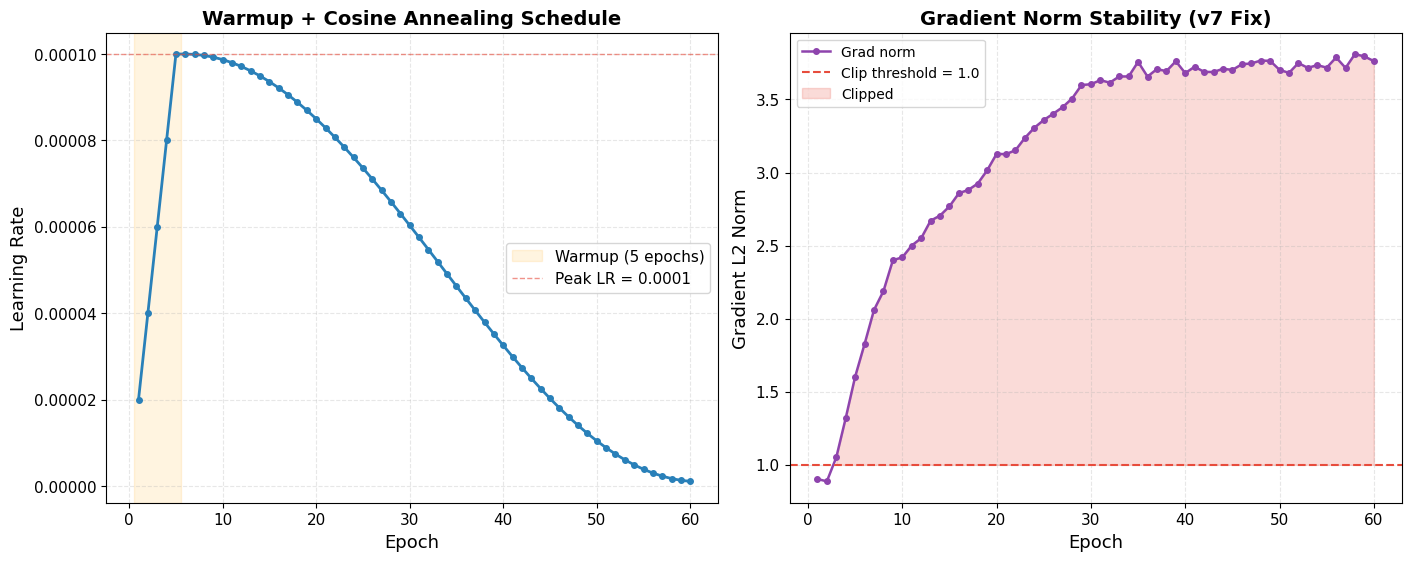

  [saved] outputs/training_dynamics_lr_gradnorm.png


In [53]:
# ═══════════════════════════════════════════════════════════════════════
# TRAINING DYNAMICS — LR SCHEDULE + GRADIENT NORMS
# ═══════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)

# --- Panel 1: LR Schedule ---
epochs_arr = np.arange(1, CONFIG['epochs'] + 1)
lr_schedule = []
for ep in range(CONFIG['epochs']):
    if ep < CONFIG['warmup_epochs']:
        lr_val = CONFIG['lr'] * (ep + 1) / CONFIG['warmup_epochs']
    else:
        progress = (ep - CONFIG['warmup_epochs']) / max(CONFIG['epochs'] - CONFIG['warmup_epochs'], 1)
        progress = min(progress, 1.0)
        lr_val = CONFIG['cosine_eta_min'] + 0.5 * (CONFIG['lr'] - CONFIG['cosine_eta_min']) * (
            1.0 + np.cos(np.pi * progress))
    lr_schedule.append(lr_val)

axes[0].plot(epochs_arr, lr_schedule, 'o-', color='#2980b9', lw=2, ms=4)
axes[0].axvspan(0.5, CONFIG['warmup_epochs'] + 0.5, alpha=0.12, color='orange',
                label=f'Warmup ({CONFIG["warmup_epochs"]} epochs)')
axes[0].axhline(CONFIG['lr'], color='#e74c3c', ls='--', lw=1, alpha=0.6,
                label=f'Peak LR = {CONFIG["lr"]}')
axes[0].set_xlabel('Epoch', fontsize=13)
axes[0].set_ylabel('Learning Rate', fontsize=13)
axes[0].set_title('Warmup + Cosine Annealing Schedule', fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3, linestyle='--')
axes[0].tick_params(labelsize=11)

# --- Panel 2: Gradient Norm History ---
if 'trainer' in dir() and hasattr(trainer, 'train_grad_norms') and len(trainer.train_grad_norms) > 0:
    grad_norms = np.array(trainer.train_grad_norms)
    grad_epochs = np.arange(1, len(grad_norms) + 1)
    axes[1].plot(grad_epochs, grad_norms, 'o-', color='#8e44ad', lw=1.8, ms=4, label='Grad norm')
    axes[1].axhline(CONFIG['grad_clip'], color='#e74c3c', ls='--', lw=1.5,
                     label=f'Clip threshold = {CONFIG["grad_clip"]}')
    axes[1].fill_between(grad_epochs, grad_norms, CONFIG['grad_clip'],
                         where=grad_norms > CONFIG['grad_clip'],
                         alpha=0.2, color='#e74c3c', label='Clipped')
    axes[1].set_xlabel('Epoch', fontsize=13)
    axes[1].set_ylabel('Gradient L2 Norm', fontsize=13)
    axes[1].set_title('Gradient Norm Stability (v7 Fix)', fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=10)
    axes[1].grid(True, alpha=0.3, linestyle='--')
    axes[1].tick_params(labelsize=11)
    print(f'  Gradient norm: mean={grad_norms.mean():.3f}, std={grad_norms.std():.3f}, max={grad_norms.max():.3f}')
else:
    axes[1].text(0.5, 0.5, 'Train model first to see gradient norms',
                 ha='center', va='center', transform=axes[1].transAxes, fontsize=13)

save_pub_fig(fig, 'training_dynamics_lr_gradnorm.png')
plt.show()
print('  [saved] outputs/training_dynamics_lr_gradnorm.png')

### Fig. 1 — SleepQualityNet Architecture (Dual-Path CNN-Attention)

This figure presents the complete model architecture, including both the detection and quality pathways, the attention mechanism, and the points at which hand-crafted features are fused with learned representations. It is included to support reproducibility and to give readers a clear view of the multi-task design.


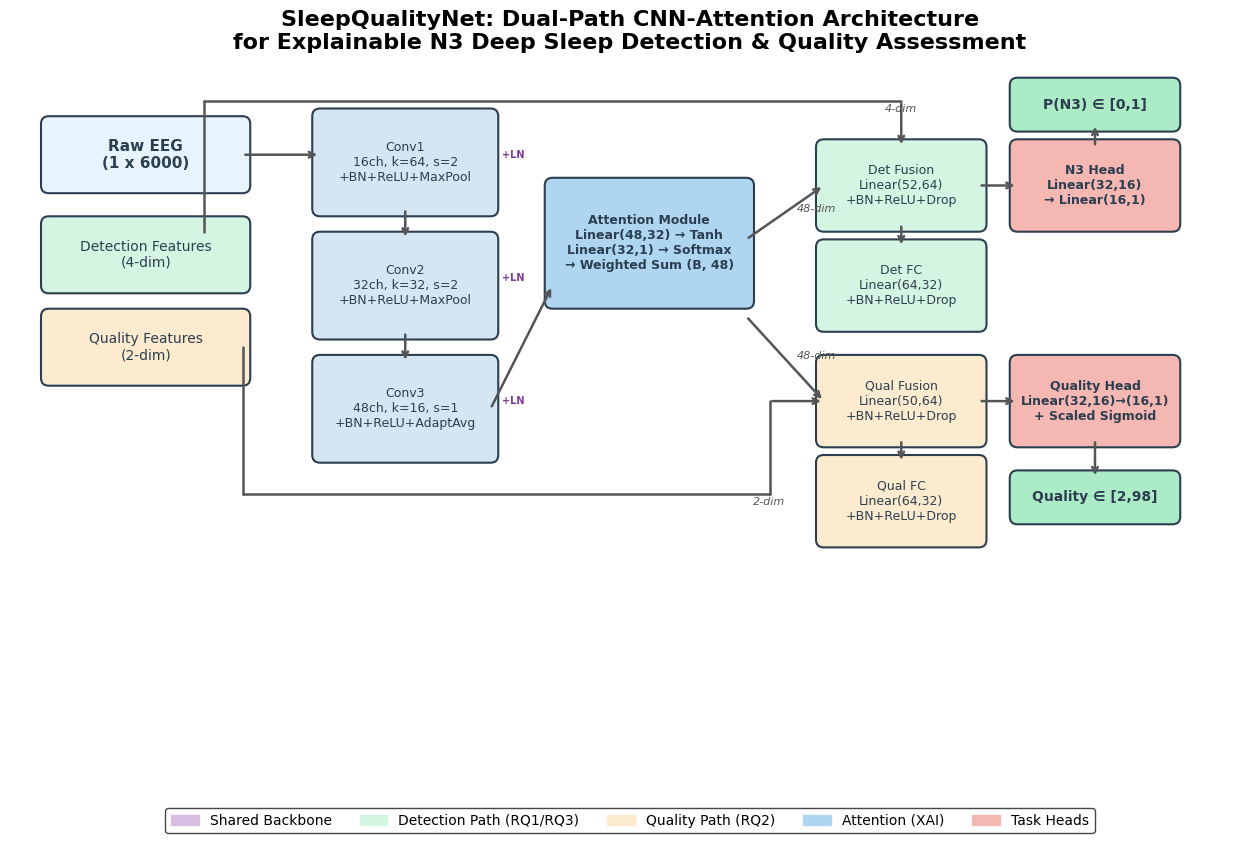

  [saved] outputs/fig1_model_architecture.png


In [7]:
# ═══════════════════════════════════════════════════════════════════════
# FIG. 1 — MODEL ARCHITECTURE DIAGRAM (Publication Quality)
# Dual-path CNN-Attention for N3 Detection + Quality Regression
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(1, 1, figsize=(16, 10))
ax.set_xlim(0, 16); ax.set_ylim(0, 10)
ax.axis('off')

# Color palette (IEEE-compliant, colorblind-safe)
C_INPUT    = '#E8F4FD'  # light blue
C_CNN      = '#D4E6F1'  # steel blue light
C_ATT      = '#AED6F1'  # attention blue
C_DET      = '#D5F5E3'  # detection green
C_QUAL     = '#FDEBD0'  # quality orange
C_HEAD     = '#F5B7B1'  # output red
C_SHARED   = '#D7BDE2'  # shared purple
C_EDGE     = '#2C3E50'  # dark text

def draw_block(ax, x, y, w, h, label, color, fontsize=10, bold=False):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.1',
                          facecolor=color, edgecolor=C_EDGE, linewidth=1.5)
    ax.add_patch(box)
    weight = 'bold' if bold else 'normal'
    ax.text(x + w/2, y + h/2, label, ha='center', va='center',
            fontsize=fontsize, fontweight=weight, color=C_EDGE)

def draw_arrow(ax, x1, y1, x2, y2, label='', color='#555'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
    if label:
        mx, my = (x1+x2)/2, (y1+y2)/2
        ax.text(mx+0.15, my, label, fontsize=8, color=color, style='italic')

def draw_elbow_arrow(ax, points, label='', color='#555'):
    """Multi-segment elbow arrow through waypoints; arrowhead only on final segment."""
    for (x1, y1), (x2, y2) in zip(points[:-2], points[1:-1]):
        ax.plot([x1, x2], [y1, y2], color=color, lw=1.8, solid_capstyle='round')
    x1, y1 = points[-2]
    x2, y2 = points[-1]
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color, lw=1.8))
    if label:
        lx, ly = points[len(points)//2]
        ax.text(lx, ly - 0.15, label, fontsize=8, color=color, style='italic', ha='center')

# ── INPUT ──
draw_block(ax, 0.5, 8.5, 2.5, 0.8, 'Raw EEG\n(1 x 6000)', C_INPUT, 11, True)
draw_block(ax, 0.5, 7.2, 2.5, 0.8, 'Detection Features\n(4-dim)', C_DET, 10)
draw_block(ax, 0.5, 6.0, 2.5, 0.8, 'Quality Features\n(2-dim)', C_QUAL, 10)

# ── CNN BACKBONE (shared) ──
draw_block(ax, 4.0, 8.2, 2.2, 1.2, 'Conv1\n16ch, k=64, s=2\n+BN+ReLU+MaxPool', C_CNN, 9)
draw_block(ax, 4.0, 6.6, 2.2, 1.2, 'Conv2\n32ch, k=32, s=2\n+BN+ReLU+MaxPool', C_CNN, 9)
draw_block(ax, 4.0, 5.0, 2.2, 1.2, 'Conv3\n48ch, k=16, s=1\n+BN+ReLU+AdaptAvg', C_CNN, 9)

# LayerNorm labels
for yy in [8.9, 7.3, 5.7]:
    ax.text(6.35, yy, '+LN', fontsize=7, color='#7D3C98', fontweight='bold', va='center')

# ── ATTENTION (shared) ──
draw_block(ax, 7.0, 7.0, 2.5, 1.5, 'Attention Module\nLinear(48,32) → Tanh\nLinear(32,1) → Softmax\n→ Weighted Sum (B, 48)', C_ATT, 9, True)

# ── DETECTION PATH ──
draw_block(ax, 10.5, 8.0, 2.0, 1.0, 'Det Fusion\nLinear(52,64)\n+BN+ReLU+Drop', C_DET, 9)
draw_block(ax, 10.5, 6.7, 2.0, 1.0, 'Det FC\nLinear(64,32)\n+BN+ReLU+Drop', C_DET, 9)
draw_block(ax, 13.0, 8.0, 2.0, 1.0, 'N3 Head\nLinear(32,16)\n→ Linear(16,1)', C_HEAD, 9, True)

# ── QUALITY PATH ──
draw_block(ax, 10.5, 5.2, 2.0, 1.0, 'Qual Fusion\nLinear(50,64)\n+BN+ReLU+Drop', C_QUAL, 9)
draw_block(ax, 10.5, 3.9, 2.0, 1.0, 'Qual FC\nLinear(64,32)\n+BN+ReLU+Drop', C_QUAL, 9)
draw_block(ax, 13.0, 5.2, 2.0, 1.0, 'Quality Head\nLinear(32,16)→(16,1)\n+ Scaled Sigmoid', C_HEAD, 9, True)

# ── OUTPUTS ──
draw_block(ax, 13.0, 9.3, 2.0, 0.5, 'P(N3) ∈ [0,1]', '#ABEBC6', 10, True)
draw_block(ax, 13.0, 4.2, 2.0, 0.5, 'Quality ∈ [2,98]', '#ABEBC6', 10, True)

# ── ARROWS ──
# Input → CNN
draw_arrow(ax, 3.0, 8.9, 4.0, 8.9)
# CNN layers
draw_arrow(ax, 5.1, 8.2, 5.1, 7.8)
draw_arrow(ax, 5.1, 6.6, 5.1, 6.2)
# CNN → Attention
draw_arrow(ax, 6.2, 5.6, 7.0, 7.2)
# Attention → Detection path (route upper)
draw_arrow(ax, 9.5, 7.8, 10.5, 8.5, '48-dim')
# Detection features → Det fusion (route lower, avoid crossing)
draw_elbow_arrow(ax, [(2.5, 7.9), (2.5, 9.6), (11.5, 9.6), (11.5, 9.0)], '4-dim')
# Det fusion → Det FC → N3 Head
draw_arrow(ax, 11.5, 8.0, 11.5, 7.7)
draw_arrow(ax, 12.5, 8.5, 13.0, 8.5)
# N3 Head → Output
draw_arrow(ax, 14.0, 9.0, 14.0, 9.3)

# Attention → Quality path (route lower)
draw_arrow(ax, 9.5, 6.8, 10.5, 5.7, '48-dim')
# Quality features → Qual fusion (route upper, avoid crossing)
draw_elbow_arrow(ax, [(3.0, 6.4), (3.0, 4.5), (9.8, 4.5), (9.8, 5.7), (10.5, 5.7)], '2-dim')
# Qual fusion → Qual FC → Quality Head
draw_arrow(ax, 11.5, 5.2, 11.5, 4.9)
draw_arrow(ax, 12.5, 5.7, 13.0, 5.7)
# Quality Head → Output
draw_arrow(ax, 14.0, 5.2, 14.0, 4.7)

# ── LEGEND ──
legend_items = [
    mpatches.Patch(color=C_SHARED, label='Shared Backbone'),
    mpatches.Patch(color=C_DET, label='Detection Path (RQ1/RQ3)'),
    mpatches.Patch(color=C_QUAL, label='Quality Path (RQ2)'),
    mpatches.Patch(color=C_ATT, label='Attention (XAI)'),
    mpatches.Patch(color=C_HEAD, label='Task Heads'),
]
ax.legend(handles=legend_items, loc='lower center', ncol=5, fontsize=10,
          framealpha=0.9, edgecolor='#333')

ax.set_title('SleepQualityNet: Dual-Path CNN-Attention Architecture\n'
             'for Explainable N3 Deep Sleep Detection & Quality Assessment',
             fontsize=16, fontweight='bold', pad=15)

save_pub_fig(fig, 'fig1_model_architecture.png')
plt.show()
print('  [saved] outputs/fig1_model_architecture.png')

In [8]:
from sleep_quality_model import (
    fit_quality_label_bounds, apply_quality_label_bounds,  # FIX (leakage)
    EEGPreprocessor, SleepQualityNet, MultiTaskLoss,
    SleepQualityTrainer, SleepDataLoader,
    make_n3_quality_labels, FeatureNormalizer,
    EEGAugmentor,
    clip_features_outliers, apply_clip_bounds,
    # V6_Fixed: 4 V5-new functions were defined in the .py module but never
    # imported here, causing NameError in Cells 41, 46, 55, 58, 68.
    log_transform_features,
    Winsorizer,
    clip_quality_predictions,
    compute_prediction_stability_metrics,
)
pre = EEGPreprocessor(sampling_rate=200, epoch_duration=30)
print('Components loaded.')
print('Detection features (4): delta_power, SWA, slow_wave_density, relative_delta')
print('Quality  features (2): peak_to_peak_amplitude, fragmentation_index')


Components loaded.
Detection features (4): delta_power, SWA, slow_wave_density, relative_delta
Quality  features (2): peak_to_peak_amplitude, fragmentation_index


### Fig. 2 — Preprocessing and Feature Extraction Pipeline

This figure illustrates the complete data flow from raw ISRUC EEG recordings to model input, including filtering, artifact rejection, and feature extraction, and is intended to support clinical and computational reproducibility.


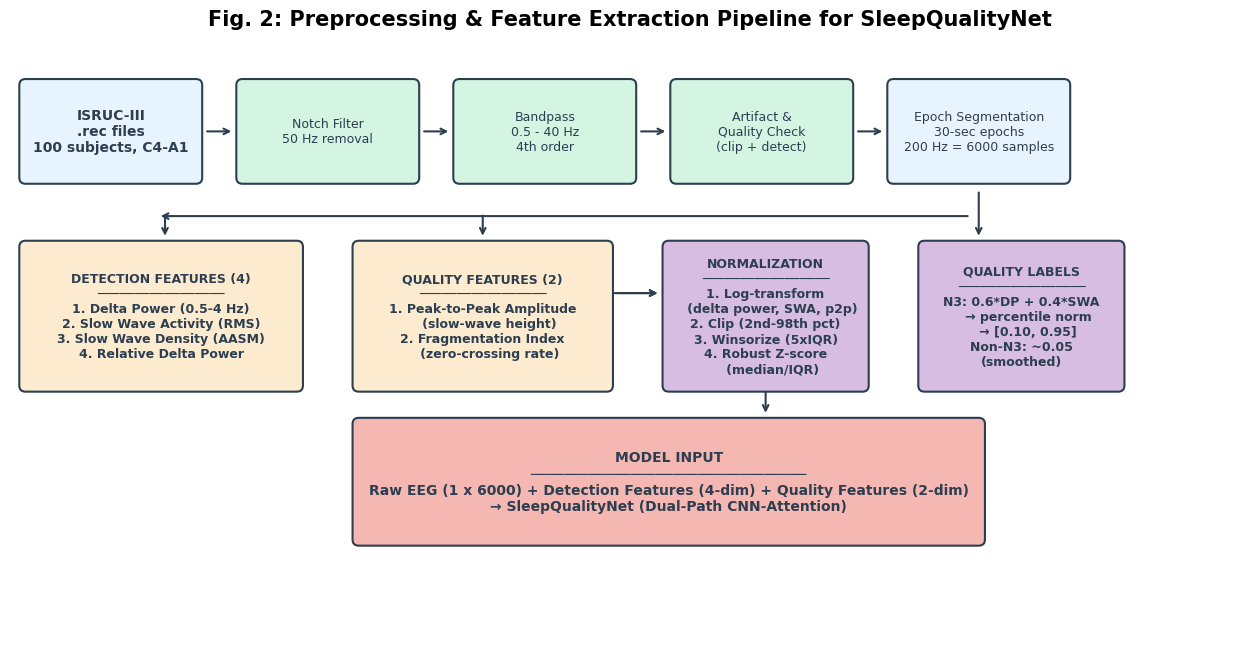

  [saved] outputs/fig2_preprocessing_pipeline.png


In [9]:
# ═══════════════════════════════════════════════════════════════════════
# FIG. 2 — PREPROCESSING PIPELINE DIAGRAM
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 8))
ax.set_xlim(0, 16); ax.set_ylim(0, 8)
ax.axis('off')

C = {'input': '#E8F4FD', 'filter': '#D5F5E3', 'feat': '#FDEBD0',
     'norm': '#D7BDE2', 'model': '#F5B7B1', 'text': '#2C3E50'}

def draw_box(ax, x, y, w, h, text, color, fs=9, bold=False):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.08',
                          facecolor=color, edgecolor=C['text'], lw=1.5)
    ax.add_patch(box)
    ax.text(x+w/2, y+h/2, text, ha='center', va='center',
            fontsize=fs, fontweight='bold' if bold else 'normal', color=C['text'])

def arrow(ax, x1, y1, x2, y2, rad=0):
    ax.annotate(
        '',
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle='->',
            lw=1.5,
            color=C['text'],
            connectionstyle=f'arc3,rad={rad}',
            shrinkA=8,
            shrinkB=8
        ),
        zorder=0
    )

# Row 1: Main pipeline
draw_box(ax, 0.2, 6.2, 2.2, 1.2, 'ISRUC-III\n.rec files\n100 subjects, C4-A1', C['input'], 10, True)
draw_box(ax, 3.0, 6.2, 2.2, 1.2, 'Notch Filter\n50 Hz removal', C['filter'])
draw_box(ax, 5.8, 6.2, 2.2, 1.2, 'Bandpass\n0.5 - 40 Hz\n4th order', C['filter'])
draw_box(ax, 8.6, 6.2, 2.2, 1.2, 'Artifact &\nQuality Check\n(clip + detect)', C['filter'])
draw_box(ax, 11.4, 6.2, 2.2, 1.2, 'Epoch Segmentation\n30-sec epochs\n200 Hz = 6000 samples', C['input'], 9)

for x1, x2 in [(2.4, 3.0), (5.2, 5.8), (8.0, 8.6), (10.8, 11.4)]:
    arrow(ax, x1, 6.8, x2, 6.8)

# Row 2: Feature extraction
draw_box(ax, 0.2, 3.5, 3.5, 1.8, 'DETECTION FEATURES (4)\n─────────────────\n1. Delta Power (0.5-4 Hz)\n2. Slow Wave Activity (RMS)\n3. Slow Wave Density (AASM)\n4. Relative Delta Power', C['feat'], 9, True)
draw_box(ax, 4.5, 3.5, 3.2, 1.8, 'QUALITY FEATURES (2)\n─────────────────\n1. Peak-to-Peak Amplitude\n   (slow-wave height)\n2. Fragmentation Index\n   (zero-crossing rate)', C['feat'], 9, True)
draw_box(ax, 8.5, 3.5, 2.5, 1.8, 'NORMALIZATION\n─────────────────\n1. Log-transform\n   (delta power, SWA, p2p)\n2. Clip (2nd-98th pct)\n3. Winsorize (5xIQR)\n4. Robust Z-score\n   (median/IQR)', C['norm'], 9, True)
draw_box(ax, 11.8, 3.5, 2.5, 1.8, 'QUALITY LABELS\n─────────────────\nN3: 0.6*DP + 0.4*SWA\n   → percentile norm\n   → [0.10, 0.95]\nNon-N3: ~0.05\n(smoothed)', C['norm'], 9, True)

arrow(ax, 12.5, 6.15, 12.5, 5.3)  # down from epoch
arrow(ax, 12.5, 5.7, 1.8, 5.7)   # left to features
arrow(ax, 2.0, 5.85, 2.0, 5.3)   # down to detection
arrow(ax, 6.1, 5.85, 6.1, 5.3)   # down to quality

arrow(ax, 5.5, 4.7, 8.5, 4.7)    # det → norm
arrow(ax, 7.7, 4.7, 8.5, 4.7)    # qual → norm (approximate)

# Row 3: Model input
draw_box(ax, 4.5, 1.5, 8.0, 1.5, 'MODEL INPUT\n─────────────────────────────────\nRaw EEG (1 x 6000) + Detection Features (4-dim) + Quality Features (2-dim)\n→ SleepQualityNet (Dual-Path CNN-Attention)', C['model'], 10, True)

arrow(ax, 9.75, 3.8, 9.75, 3.0)  # norm → model input
arrow(ax, 9.75, 3.0, 8.0, 2.3)   # to model

ax.set_title('Fig. 2: Preprocessing & Feature Extraction Pipeline for SleepQualityNet',
             fontsize=15, fontweight='bold', pad=10)

save_pub_fig(fig, 'fig2_preprocessing_pipeline.png')
plt.show()
print('  [saved] outputs/fig2_preprocessing_pipeline.png')

Found 100 .rec files for ISRUC-III. Loading...


PREPROCESSING QUALITY REPORT
Total epochs attempted:        861
Artifact epochs removed:       14
Low-quality epochs removed:    0
Heavily clipped epochs removed: 25
----------------------------------------------------------------------
Final epochs retained:         822
Retention rate:                95.5%

  [Subject 100] ✓ 822 epochs

PREPROCESSING QUALITY REPORT
Total epochs attempted:        796
Artifact epochs removed:       5
Low-quality epochs removed:    425
Heavily clipped epochs removed: 2
----------------------------------------------------------------------
Final epochs retained:         364
Retention rate:                45.7%

  [Subject 10] ✓ 364 epochs

PREPROCESSING QUALITY REPORT
Total epochs attempted:        997
Artifact epochs removed:       0
Low-quality epochs removed:    0
Heavily clipped epochs removed: 0
----------------------------------------------------------------------
Final epochs retained:         997
Re

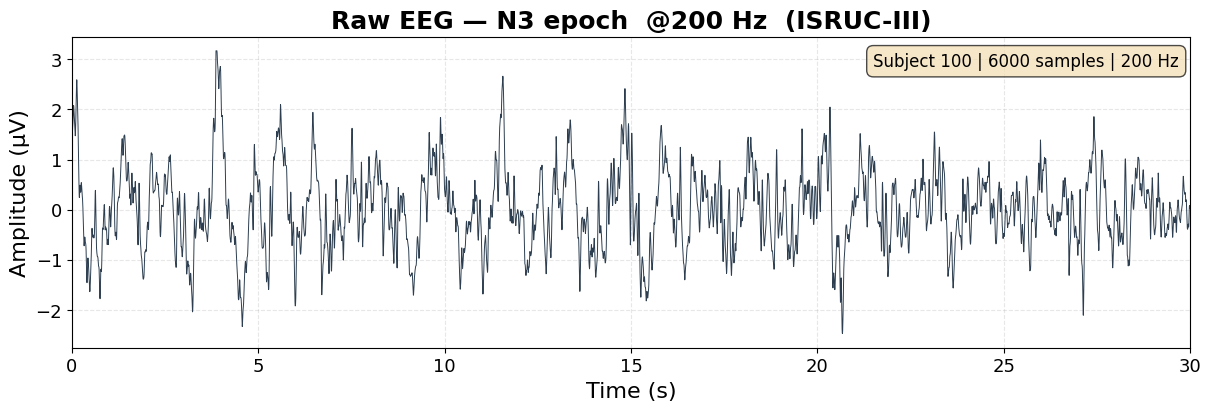

In [10]:
# ── Generic EEG dataset loading layer ───────────────────────────────────────
# This cell keeps ISRUC-III as the default adapter, but isolates the dataset-
# specific logic behind a small interface so a different EEG dataset can be
# plugged into the pipeline by implementing the same methods.

import os
import shutil
import tempfile
from dataclasses import dataclass, field
from typing import Any, Dict, List

import mne
import numpy as np
import matplotlib.pyplot as plt


STAGE_MAP_ISRUC = {
    0: 0,   # Wake
    1: 1,   # N1
    2: 2,   # N2
    3: 3,   # N3 (SWS)
    4: 3,   # N4 -> N3 (old AASM)
    5: 4,   # REM
    6: -1,  # Movement / artifact -> discard
    9: -1,  # Unknown -> discard
}

STAGE_MAP = {0: 'Wake', 1: 'N1', 2: 'N2', 3: 'N3', 4: 'REM'}


@dataclass
class EEGDatasetBundle:
    raw_eegs: np.ndarray
    det_features: np.ndarray
    qual_features: np.ndarray
    stage_labels: np.ndarray
    night_ids: np.ndarray
    metadata: List[Dict[str, Any]] = field(default_factory=list)


class EEGDatasetAdapter:
    """Interface for dataset-specific EEG loading.

    A new dataset only needs to implement `find_recordings()` and
    `load_recording()` while keeping the output format unchanged.
    """

    name = 'base'

    def find_recordings(self, data_dir, n_subjects):
        raise NotImplementedError

    def load_recording(self, rec_path, preprocessor):
        raise NotImplementedError

    def load(self, data_dir, n_subjects, preprocessor, fallback_to_synthetic=True, seed=42):
        rec_paths = self.find_recordings(data_dir, n_subjects)
        all_eeg, all_det, all_qual, all_stage, night_ids, metadata = [], [], [], [], [], []

        print(f'Found {len(rec_paths)} .rec files for {self.name}. Loading...\n')

        for rec_path in rec_paths:
            try:
                eegs, det_feats, qual_feats, labels, subject_id, info = self.load_recording(rec_path, preprocessor)
                if len(eegs) == 0:
                    print(f'  [Subject {subject_id}] no valid epochs')
                    continue

                all_eeg.append(eegs)
                all_det.append(det_feats)
                all_qual.append(qual_feats)
                all_stage.append(labels)
                night_ids.extend([subject_id] * len(eegs))
                metadata.extend(info)
                print(f"  [Subject {subject_id}] ✓ {len(eegs)} epochs")
            except Exception as exc:
                print(f"  [load failed] {rec_path}: {exc}")

        if not all_eeg and fallback_to_synthetic:
            print('\n  No real EEG data found. Using synthetic dataset for testing.')
            print('  NOTE: All reported metrics are from SYNTHETIC data - not clinically valid.')
            raw_eegs, det_features, qual_features, stage_labels, _ = SleepDataLoader.create_synthetic_dataset(
                num_samples=600,
                sampling_rate=preprocessor.sampling_rate,
                epoch_duration=preprocessor.epoch_duration,
                seed=seed,
            )
            night_ids = np.arange(1, len(raw_eegs) + 1)
            metadata = [{'subject_id': int(sid), 'source': 'synthetic'} for sid in night_ids]
            return EEGDatasetBundle(
                raw_eegs=np.asarray(raw_eegs, dtype=np.float32),
                det_features=np.asarray(det_features, dtype=np.float32),
                qual_features=np.asarray(qual_features, dtype=np.float32),
                stage_labels=np.asarray(stage_labels, dtype=np.int64),
                night_ids=np.asarray(night_ids, dtype=np.int64),
                metadata=metadata,
            )

        return EEGDatasetBundle(
            raw_eegs=np.concatenate(all_eeg).astype(np.float32),
            det_features=np.concatenate(all_det).astype(np.float32),
            qual_features=np.concatenate(all_qual).astype(np.float32),
            stage_labels=np.concatenate(all_stage).astype(np.int64),
            night_ids=np.asarray(night_ids, dtype=np.int64),
            metadata=metadata,
        )


class ISRUCIIIAdapter(EEGDatasetAdapter):
    name = 'ISRUC-III'

    def __init__(self, channel='C4-A1', max_subjects=100):
        self.channel = channel
        self.max_subjects = max_subjects

    def find_recordings(self, data_dir, n_subjects):
        rec_files = []
        for subj_id in range(1, n_subjects + 1):
            subj_folder = os.path.join(data_dir, str(subj_id))
            found = False
            if os.path.isdir(subj_folder):
                for fname in os.listdir(subj_folder):
                    if fname.lower().endswith('.rec'):
                        rec_files.append(os.path.join(subj_folder, fname))
                        found = True
                        break
            if not found and os.path.isdir(data_dir):
                for fname in os.listdir(data_dir):
                    if fname.lower().endswith('.rec') and (
                        fname.startswith(str(subj_id)) or fname.upper().startswith(f'SN{subj_id:03d}')
                    ):
                        rec_files.append(os.path.join(data_dir, fname))
                        break
        return sorted(rec_files)

    def _parse_isruc_txt(self, txt_path):
        stages = []
        with open(txt_path, 'r') as f:
            for line in f:
                line = line.strip()
                if not line or not line[0].isdigit():
                    continue
                try:
                    raw_stage = int(line.split()[0])
                    stages.append(STAGE_MAP_ISRUC.get(raw_stage, -1))
                except ValueError:
                    continue
        return np.asarray(stages, dtype=np.int64)

    def _load_annotations(self, name, subj_dir):
        txt = os.path.join(subj_dir, f'{name}_1.txt')
        if os.path.exists(txt):
            labels = self._parse_isruc_txt(txt)
            if len(labels) > 0:
                return labels, 'txt'
        return None, None

    def load_recording(self, rec_path, preprocessor):
        name = os.path.splitext(os.path.basename(rec_path))[0]
        subj_dir = os.path.dirname(rec_path)
        sid = int(name.replace('SN', '').lstrip('0') or '0')

        labels, ann_src = self._load_annotations(name, subj_dir)
        if labels is None:
            raise RuntimeError('no annotation file found')

        tmp_path = os.path.join(tempfile.gettempdir(), f'_isruc_{name}.edf')
        if not os.path.exists(tmp_path):
            shutil.copy2(rec_path, tmp_path)

        raw = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
        if raw.info['sfreq'] != preprocessor.sampling_rate:
            raw.resample(preprocessor.sampling_rate, verbose=False)

        ch = None
        for candidate in [self.channel, 'C4-A1', 'F4-A1', 'C3-A2']:
            if candidate in raw.ch_names:
                ch = candidate
                break
        if ch is None:
            ch = raw.ch_names[0]

        eeg = raw.get_data(picks=[ch], units='uV')[0].astype(np.float32)
        epochs, det_feats, qual_feats, lbls = preprocessor.create_epochs(eeg, labels=labels)

        if len(lbls) > len(epochs):
            lbls = lbls[:len(epochs)]
        elif len(lbls) < len(epochs):
            pad = np.full(len(epochs) - len(lbls), -1, dtype=np.int64)
            lbls = np.concatenate([lbls, pad])

        valid = lbls != -1
        epochs = epochs[valid]
        det_feats = det_feats[valid]
        qual_feats = qual_feats[valid]
        lbls = lbls[valid]

        metadata = [{
            'subject_id': sid,
            'recording': name,
            'channel': ch,
            'annotation_source': ann_src,
        } for _ in range(len(epochs))]

        return epochs, det_feats, qual_feats, lbls, sid, metadata


DATA_DIR = CONFIG['data_dir']
CH = CONFIG['eeg_channel']
N = CONFIG['n_subjects']
SR = CONFIG['sampling_rate']

pre = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
adapter = ISRUCIIIAdapter(channel=CH, max_subjects=N)

bundle = adapter.load(DATA_DIR, N, pre, fallback_to_synthetic=True, seed=CONFIG['seed'])
raw_eegs = bundle.raw_eegs
det_features = bundle.det_features
qual_features = bundle.qual_features
stage_labels = bundle.stage_labels
night_ids = bundle.night_ids

print(f"\n── Dataset loaded ───────────────────────────────────────")
print(f"  Dataset      : {adapter.name}")
print(f"  Total epochs : {raw_eegs.shape[0]:,}")
print(f"  Signal shape : {raw_eegs.shape}")
print(f"  Subjects     : {len(np.unique(night_ids))}")
print(f"  Stage distribution:")
unique, counts = np.unique(stage_labels, return_counts=True)
for u, c in zip(unique, counts):
    pct = c / len(stage_labels) * 100
    print(f"    {STAGE_MAP[u]:>5}: {c:5d} ({pct:.1f}%)")

# Plot a sample N3 epoch for quick sanity checking.
ex_idx = np.where(stage_labels == 3)[0][0] if (stage_labels == 3).any() else 0
example = raw_eegs[ex_idx]
t = np.arange(len(example)) / SR

fig, ax = plt.subplots(figsize=(12, 4), constrained_layout=True)
ax.plot(t, example, color='#2c3e50', lw=0.7)
ax.set_title(f"Raw EEG — {STAGE_MAP[int(stage_labels[ex_idx])]} epoch  @{SR} Hz  ({adapter.name})",
             fontsize=18, fontweight='bold')
ax.set_xlabel('Time (s)', fontsize=16)
ax.set_ylabel('Amplitude (μV)', fontsize=16)
ax.set_xlim(0, 30)
ax.tick_params(axis='both', labelsize=13)
ax.grid(True, alpha=0.3, linestyle='--')
ax.text(0.99, 0.95,
        f"Subject {night_ids[ex_idx]} | {len(example)} samples | {SR} Hz",
        transform=ax.transAxes, ha='right', va='top', fontsize=12,
        bbox=dict(boxstyle='round,pad=0.4', facecolor='wheat', alpha=0.7))
save_pub_fig(fig, 'eeg_sample_n3_epoch.png')
plt.show()


In [11]:
# ── Modular preprocessing + dataset-independent evaluation helpers ─────────
# This cell preserves the current feature engineering behavior while making the
# preprocessing and evaluation stages reusable for another EEG dataset.

from dataclasses import dataclass
from typing import Any, Dict, List, Optional

import pandas as pd


@dataclass
class EEGPreprocessingArtifacts:
    split_index: int
    clip_bounds: Dict[str, Any]
    det_features_clipped: np.ndarray
    qual_features_clipped: np.ndarray
    det_features_n: np.ndarray
    qual_features_n: np.ndarray
    quality_labels: np.ndarray


class EEGPreprocessingPipeline:
    """Dataset-agnostic feature preparation.

    Any dataset that produces raw EEG epochs plus detection/quality features can
    reuse this pipeline without changing downstream training code.
    """

    def __init__(self, train_fraction=0.8, lower_pct=1, upper_pct=99):
        self.train_fraction = train_fraction
        self.lower_pct = lower_pct
        self.upper_pct = upper_pct

    def prepare(self, raw_eegs, det_features, qual_features, stage_labels):
        split = int(self.train_fraction * len(raw_eegs))

        det_features_clip, qual_features_clip, clip_bounds = clip_features_outliers(
            det_features[:split], qual_features[:split],
            lower_pct=self.lower_pct, upper_pct=self.upper_pct,
        )

        det_val_clip, qual_val_clip = apply_clip_bounds(
            det_features[split:], qual_features[split:], clip_bounds)

        det_features_full = np.concatenate([det_features_clip, det_val_clip], axis=0)
        qual_features_full = np.concatenate([qual_features_clip, qual_val_clip], axis=0)

        quality_labels = make_n3_quality_labels(det_features_full, stage_labels)

        normalizer = FeatureNormalizer()
        normalizer.fit(det_features_full[:split], qual_features_full[:split])
        det_features_n = normalizer.transform_det(det_features_full)
        qual_features_n = normalizer.transform_qual(qual_features_full)

        return EEGPreprocessingArtifacts(
            split_index=split,
            clip_bounds=clip_bounds,
            det_features_clipped=det_features_full,
            qual_features_clipped=qual_features_full,
            det_features_n=det_features_n,
            qual_features_n=qual_features_n,
            quality_labels=quality_labels,
        )


class DatasetIndependentEvaluator:
    """Collects predictions and builds reusable evaluation tables.

    The same methods can be used for any EEG dataset as long as the loader yields
    (raw_eeg, det_feat, qual_feat, stage_labels, quality_labels).
    """

    def __init__(self, model, device):
        self.model = model
        self.device = device

    def collect_quality_frame(self, data_loader, absolute_indices, subject_ids, det_features):
        records = []
        cursor = 0
        det_features = np.asarray(det_features)

        self.model.eval()
        with torch.no_grad():
            for raw_eeg, det_f, qual_f, stage_batch, quality_batch in data_loader:
                batch_size = raw_eeg.size(0)
                batch_idx = np.asarray(absolute_indices[cursor:cursor + batch_size])
                cursor += batch_size

                raw_eeg = raw_eeg.to(self.device)
                det_f = det_f.to(self.device)
                qual_f = qual_f.to(self.device)

                _, q_pred = self.model(raw_eeg, det_f, qual_f)
                pred_q = clip_quality_predictions(q_pred.detach().cpu().numpy().flatten(), 0.02, 0.98) * 100.0
                true_q = quality_batch.detach().cpu().numpy().flatten() * 100.0
                stages = stage_batch.detach().cpu().numpy().flatten()

                for j, abs_idx in enumerate(batch_idx):
                    records.append({
                        'abs_idx': int(abs_idx),
                        'subject': int(subject_ids[abs_idx]),
                        'stage': int(stages[j]),
                        'true_quality': float(true_q[j]),
                        'pred_quality': float(pred_q[j]),
                        'abs_error': float(abs(pred_q[j] - true_q[j])),
                        'signed_error': float(pred_q[j] - true_q[j]),
                        'delta_power': float(det_features[abs_idx, 0]),
                        'slow_wave_density': float(det_features[abs_idx, 2]) if det_features.shape[1] > 2 else np.nan,
                    })

        return pd.DataFrame.from_records(records)

    @staticmethod
    def summarize_subject_errors(error_df):
        if len(error_df) == 0:
            return pd.DataFrame(columns=['subject', 'n_epochs', 'mean_abs_error', 'median_abs_error', 'max_abs_error', 'mean_signed_error'])

        return (
            error_df.groupby('subject')
            .agg(
                n_epochs=('abs_error', 'size'),
                mean_abs_error=('abs_error', 'mean'),
                median_abs_error=('abs_error', 'median'),
                max_abs_error=('abs_error', 'max'),
                mean_signed_error=('signed_error', 'mean'),
            )
            .reset_index()
            .sort_values('mean_abs_error', ascending=False)
        )


preprocessing_pipeline = EEGPreprocessingPipeline(train_fraction=0.8, lower_pct=1, upper_pct=99)
preprocessed = preprocessing_pipeline.prepare(raw_eegs, det_features, qual_features, stage_labels)

det_features_clipped = preprocessed.det_features_clipped
qual_features_clipped = preprocessed.qual_features_clipped
det_features_n = preprocessed.det_features_n
qual_features_n = preprocessed.qual_features_n
quality_labels = preprocessed.quality_labels

# Backward-compatible aliases used later in the notebook.
det_features_n_v3 = det_features_n
qual_features_n_v3 = qual_features_n
quality_labels_v3_full = quality_labels

n3_count = int((stage_labels == 3).sum())
total = len(stage_labels)
print(f'Quality labels (N3-only): {n3_count} N3 epochs / {total} total')
print(f'Detection  features shape : {det_features_n.shape}  (delta, SWA, SWD, rel_delta)')
print(f'Quality    features shape : {qual_features_n.shape}  (p2p_amp, fragmentation)')
print()
print('Feature means (detection):', det_features_n.mean(axis=0).round(3).tolist())
print('Feature means (quality)  :', qual_features_n.mean(axis=0).round(3).tolist())


Quality labels (N3-only): 17032 N3 epochs / 83776 total
Detection  features shape : (83776, 4)  (delta, SWA, SWD, rel_delta)
Quality    features shape : (83776, 2)  (p2p_amp, fragmentation)

Feature means (detection): [0.6209999918937683, 0.22300000488758087, 1.1009999513626099, -0.07400000095367432]
Feature means (quality)  : [0.21199999749660492, 0.0989999994635582]


### Feature Distributions by Sleep Stage

This section presents boxplots of each of the six features, stratified by sleep stage, in order to confirm that the extracted features behave in a physiologically plausible manner prior to model training. Detection features are expected to peak during N3, with delta power, slow-wave activity, and slow-wave density all highest in this stage, while the two quality features are expected to show meaningful within-N3 variation, distinguishing higher- from lower-quality N3 epochs. A reversal of this pattern — for example, N3 showing the lowest delta power — would indicate a labeling or preprocessing error requiring correction before proceeding.


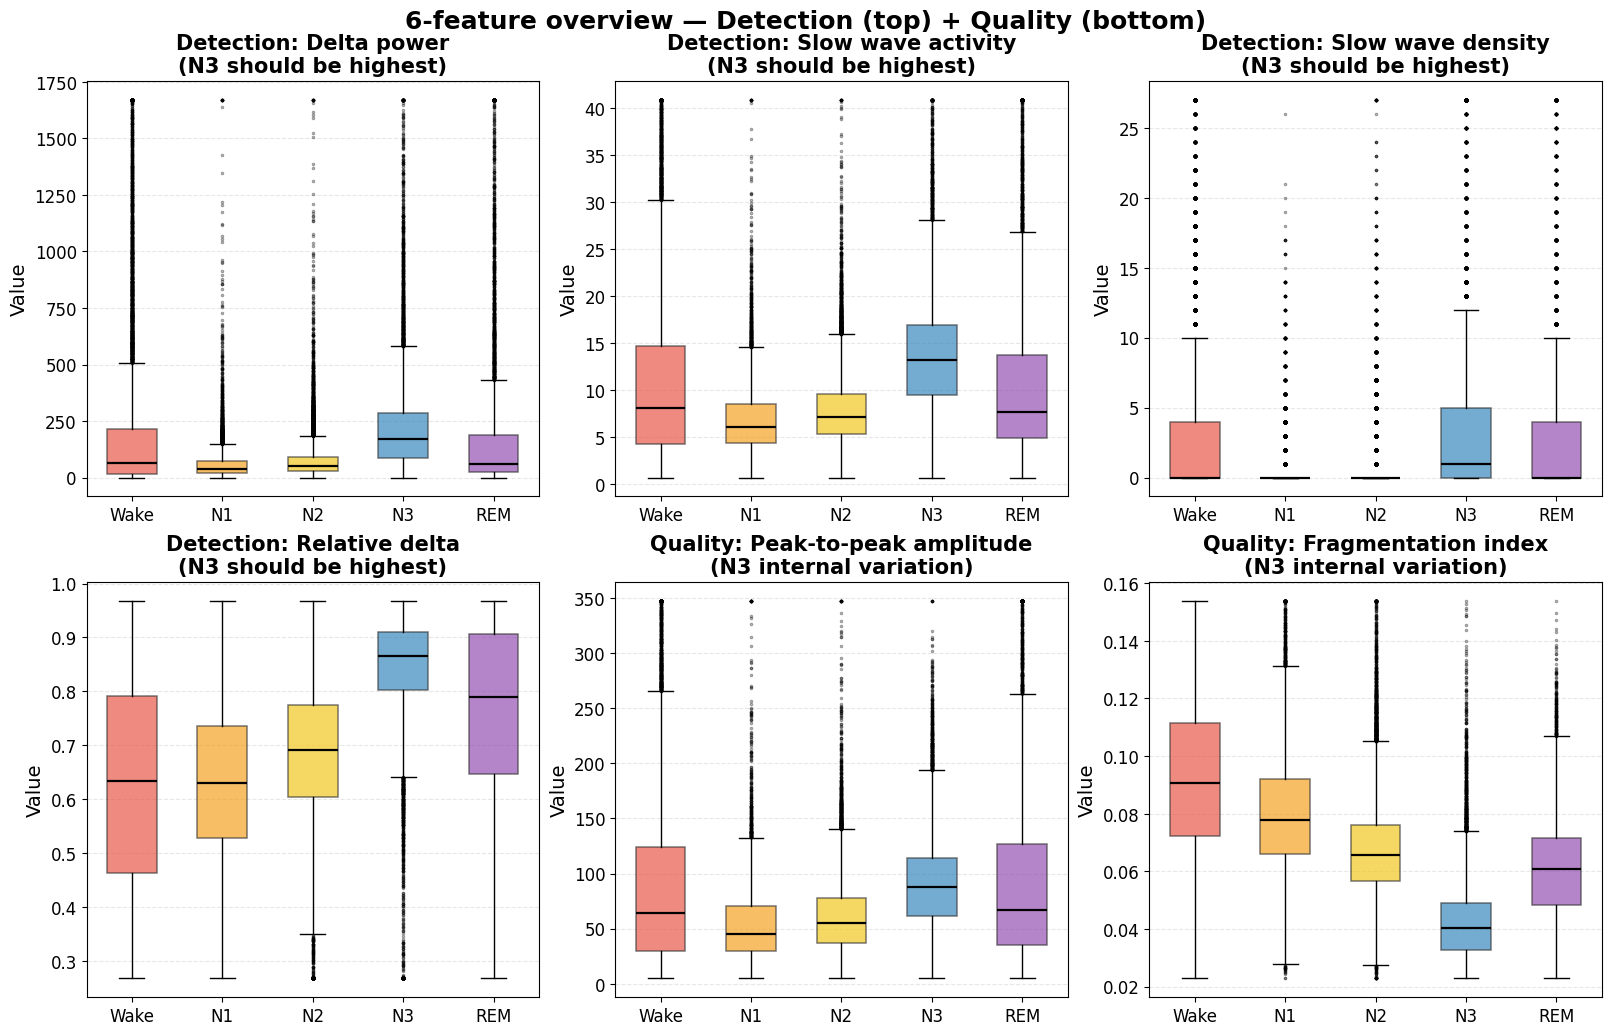

Detection feature means:
  Delta power                 : N3=220.6396  other=131.4782  ratio=1.68x
  Slow wave activity          : N3=13.0160  other=8.9047  ratio=1.46x
  Slow wave density           : N3=3.5831  other=1.8490  ratio=1.94x
  Relative delta              : N3=0.8410  other=0.6715  ratio=1.25x
Quality feature stats (N3 only):
  Peak-to-peak amplitude      : mean=87.4426  std=48.4285
  Fragmentation index         : mean=0.0428  std=0.0150


In [12]:
# ═══════════════════════════════════════════════════════════════════════
# FEATURE BOXPLOTS — Stage-wise Distributions
# ═══════════════════════════════════════════════════════════════════════

STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['#e74c3c', '#f39c12', '#f1c40f', '#2980b9', '#8e44ad']

det_names  = ['Delta power', 'Slow wave activity', 'Slow wave density', 'Relative delta']
qual_names = ['Peak-to-peak amplitude', 'Fragmentation index']

# Use clipped features if available, otherwise raw features
_plot_det  = det_features_clipped  if 'det_features_clipped'  in dir() else det_features
_plot_qual = qual_features_clipped if 'qual_features_clipped' in dir() else qual_features

fig, axes = plt.subplots(2, 3, figsize=(16, 10), constrained_layout=True)
axes = axes.flatten()

# Detection features (4)
for fi in range(4):
    data = [_plot_det[:, fi][stage_labels == s] for s in range(5)]
    bp = axes[fi].boxplot(
        data, tick_labels=[STAGE_MAP[s] for s in range(5)],
        patch_artist=True, widths=0.55,
        medianprops=dict(color="black", lw=1.6),
        flierprops=dict(marker=".", markersize=3, alpha=0.4))
    for patch, c in zip(bp['boxes'], STAGE_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.65)
        patch.set_edgecolor("#333"); patch.set_linewidth(1.1)
    axes[fi].set_title(f'Detection: {det_names[fi]}\n(N3 should be highest)',
                       fontsize=15, fontweight="bold")
    axes[fi].set_ylabel('Value', fontsize=14)
    axes[fi].tick_params(axis="both", labelsize=12)
    axes[fi].grid(True, alpha=0.3, linestyle="--", axis="y")

# Quality features (2)
for fi in range(2):
    data = [_plot_qual[:, fi][stage_labels == s] for s in range(5)]
    bp = axes[4+fi].boxplot(
        data, tick_labels=[STAGE_MAP[s] for s in range(5)],
        patch_artist=True, widths=0.55,
        medianprops=dict(color="black", lw=1.6),
        flierprops=dict(marker=".", markersize=3, alpha=0.4))
    for patch, c in zip(bp['boxes'], STAGE_COLORS):
        patch.set_facecolor(c); patch.set_alpha(0.65)
        patch.set_edgecolor("#333"); patch.set_linewidth(1.1)
    axes[4+fi].set_title(f'Quality: {qual_names[fi]}\n(N3 internal variation)',
                         fontsize=15, fontweight="bold")
    axes[4+fi].set_ylabel('Value', fontsize=14)
    axes[4+fi].tick_params(axis="both", labelsize=12)
    axes[4+fi].grid(True, alpha=0.3, linestyle="--", axis="y")

# Hide unused subplot
for j in range(6, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('6-feature overview — Detection (top) + Quality (bottom)',
             fontsize=18, fontweight="bold", y=1.02)
save_pub_fig(fig, "feature_boxplots_overview.png")
plt.show()

# Print N3 vs Other mean values
print('Detection feature means:')
for fi, name in enumerate(det_names):
    n3_val  = _plot_det[stage_labels==3, fi].mean()
    oth_val = _plot_det[stage_labels!=3, fi].mean()
    print(f'  {name:<28}: N3={n3_val:.4f}  other={oth_val:.4f}  ratio={n3_val/(oth_val+1e-8):.2f}x')
print('Quality feature stats (N3 only):')
for fi, name in enumerate(qual_names):
    vals = _plot_qual[stage_labels==3, fi]
    print(f'  {name:<28}: mean={vals.mean():.4f}  std={vals.std():.4f}')

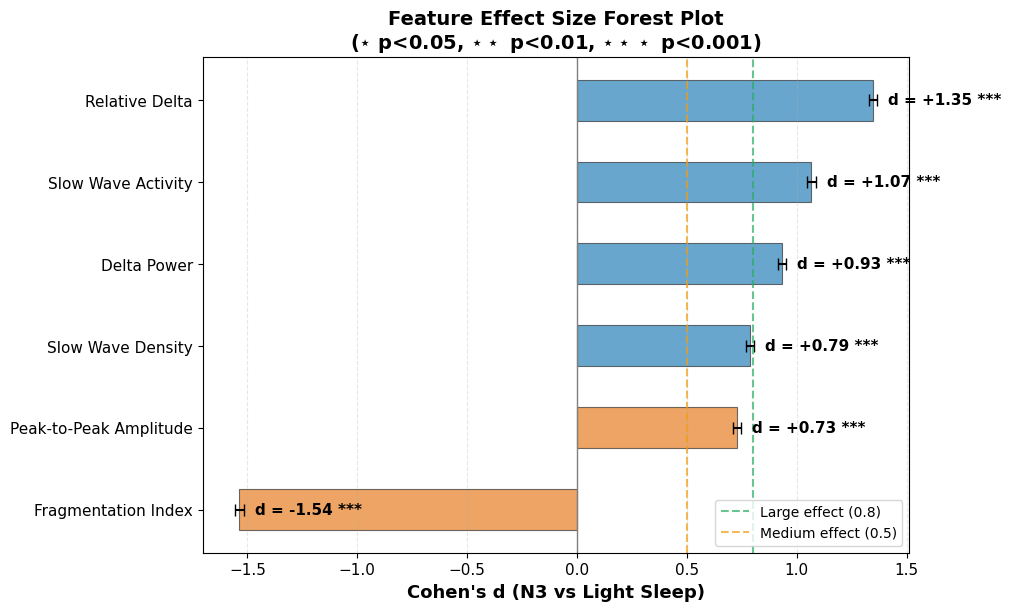

  [saved] outputs/effect_size_forest_plot.png


In [13]:
# ═══════════════════════════════════════════════════════════════════════
# EFFECT SIZE FOREST PLOT — Clinical Feature Discriminability
# ═══════════════════════════════════════════════════════════════════════
from scipy import stats

DET_FEAT_NAMES  = ['Delta Power', 'Slow Wave Activity',
                   'Slow Wave Density', 'Relative Delta']
QUAL_FEAT_NAMES = ['Peak-to-Peak Amplitude', 'Fragmentation Index']
ALL_FEAT_NAMES  = DET_FEAT_NAMES + QUAL_FEAT_NAMES

n3_mask    = (stage_labels == 3)
light_mask = (stage_labels == 1) | (stage_labels == 2)

cohens_d_vals = []
ci_lo_vals = []
ci_hi_vals = []
p_vals = []

for i, name in enumerate(ALL_FEAT_NAMES):
    if i < 4:
        n3_v = det_features[n3_mask, i]
        lit_v = det_features[light_mask, i]
    else:
        n3_v = qual_features[n3_mask, i-4]
        lit_v = qual_features[light_mask, i-4]
    
    n1, n2 = len(n3_v), len(lit_v)
    pooled_std = np.sqrt(
        ((n1-1)*np.var(n3_v, ddof=1) + (n2-1)*np.var(lit_v, ddof=1))
        / (n1 + n2 - 2)
    )
    d = (np.mean(n3_v) - np.mean(lit_v)) / max(pooled_std, 1e-8)
    se = np.sqrt((n1+n2)/(n1*n2) + d**2/(2*(n1+n2)))
    cohens_d_vals.append(d)
    ci_lo_vals.append(d - 1.96*se)
    ci_hi_vals.append(d + 1.96*se)
    _, p = stats.ttest_ind(n3_v, lit_v, equal_var=False)
    p_vals.append(p)

# Sort by effect size
order = np.argsort(cohens_d_vals)[::-1]
names_ord = [ALL_FEAT_NAMES[i] for i in order]
d_ord = [cohens_d_vals[i] for i in order]
lo_ord = [ci_lo_vals[i] for i in order]
hi_ord = [ci_hi_vals[i] for i in order]
p_ord = [p_vals[i] for i in order]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

colors = []
for n in names_ord:
    if 'Delta' in n or 'Relative' in n or 'Slow' in n:
        colors.append('#2980b9')  # blue for delta-related
    else:
        colors.append('#e67e22')  # orange for quality

y_pos = np.arange(len(names_ord))
for i, (y, d, lo, hi, c, n, p) in enumerate(zip(y_pos, d_ord, lo_ord, hi_ord, colors, names_ord, p_ord)):
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
    ax.barh(y, d, color=c, alpha=0.7, height=0.5, edgecolor='#333', linewidth=0.8)
    ax.errorbar(d, y, xerr=[[d-lo], [hi-d]], fmt='none', color='black', lw=1.5, capsize=4)
    label = f'd = {d:+.2f} {sig}'
    ax.text(max(d, hi) + 0.05, y, label, va='center', fontsize=11, fontweight='bold')

ax.axvline(0, color='gray', lw=1, ls='-')
ax.axvline(0.8, color='#27ae60', ls='--', lw=1.5, alpha=0.7, label='Large effect (0.8)')
ax.axvline(0.5, color='#f39c12', ls='--', lw=1.5, alpha=0.7, label='Medium effect (0.5)')
ax.set_yticks(y_pos)
ax.set_yticklabels(names_ord, fontsize=12)
ax.invert_yaxis()
ax.set_xlabel("Cohen's d (N3 vs Light Sleep)", fontsize=13, fontweight='bold')
ax.set_title('Feature Effect Size Forest Plot\n' + r'($\star$ p<0.05, $\star\star$ p<0.01, $\star\star\star$ p<0.001)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.tick_params(labelsize=11)

save_pub_fig(fig, 'effect_size_forest_plot.png')
plt.show()
print('  [saved] outputs/effect_size_forest_plot.png')

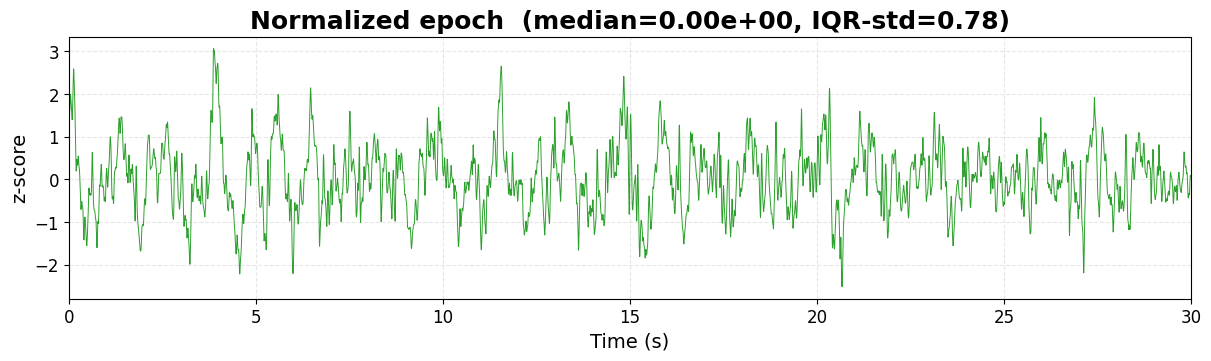

In [14]:
filtered = pre.bandpass_filter(example)
norm = pre.normalize_epoch(filtered)

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.plot(t, norm, color="#2ca02c", lw=0.7)
ax.set_title(f'Normalized epoch  (median={np.median(norm):.2e}, IQR-std={norm.std():.2f})',
             fontsize=18, fontweight="bold")
ax.set_xlabel('Time (s)', fontsize=14)
ax.set_ylabel('z-score', fontsize=14)
ax.set_xlim(0, 30)
ax.grid(True, alpha=0.3, linestyle="--")
ax.tick_params(axis="both", labelsize=12)
save_pub_fig(fig, "normalized_epoch.png")
plt.show()


#### Delta Power Extraction (0.5–4 Hz)

This step isolates the delta frequency band (0.5–4 Hz) of the EEG signal and computes its power. Delta power is the most direct physiological indicator of N3 sleep, since the AASM 2007 scoring manual defines N3 by the presence of high-amplitude slow waves within this band. The output is a single scalar representing total delta-band energy across each 30-second epoch; for a correctly labeled N3 epoch, delta is expected to be the largest of the five computed band powers.


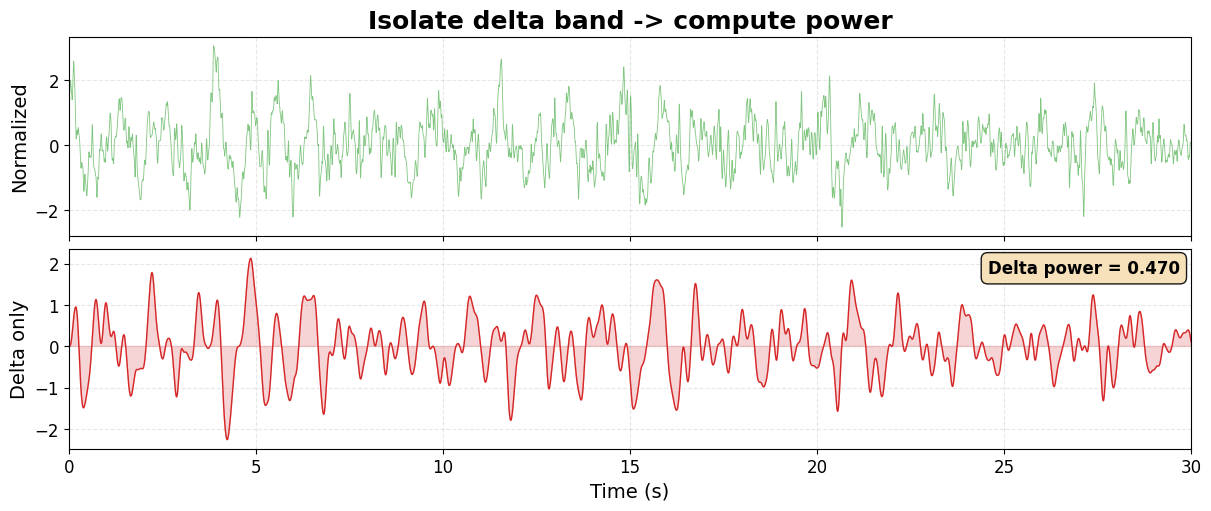

Band powers (z-scored signal, relative units): {'delta': 0.451, 'theta': 0.064, 'alpha': 0.03, 'sigma': 0.011, 'beta': 0.007}


In [15]:
from scipy.signal import butter, sosfilt
sos_delta = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')
delta_sig = sosfilt(sos_delta, norm)
power = float(np.mean(delta_sig ** 2))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True,
                          constrained_layout=True)
axes[0].plot(t, norm, color="#2ca02c", lw=0.6, alpha=0.6)
axes[0].set_ylabel('Normalized', fontsize=14)
axes[0].set_title('Isolate delta band -> compute power',
                  fontsize=18, fontweight="bold")
axes[0].grid(True, alpha=0.3, linestyle="--")
axes[0].tick_params(axis="both", labelsize=12)

axes[1].plot(t, delta_sig, color="#d62728", lw=1.0)
axes[1].fill_between(t, delta_sig, 0, where=(delta_sig > 0),
                     color="#d62728", alpha=0.2)
axes[1].fill_between(t, delta_sig, 0, where=(delta_sig < 0),
                     color="#d62728", alpha=0.2)
axes[1].set_ylabel('Delta only', fontsize=14)
axes[1].set_xlabel('Time (s)', fontsize=14)
axes[1].set_xlim(0, 30)
axes[1].grid(True, alpha=0.3, linestyle="--")
axes[1].tick_params(axis="both", labelsize=12)
axes[1].text(0.99, 0.95, f'Delta power = {power:.3f}',
             transform=axes[1].transAxes, ha='right', va='top',
             fontsize=12, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='wheat', alpha=0.9))
save_pub_fig(fig, "delta_band_isolation.png")
plt.show()

# All five bands for this epoch
bands = pre.extract_frequency_bands(norm)
print("Band powers (z-scored signal, relative units):",
      {k: round(v, 3) for k, v in bands.items()})


raw_eegs      : (83776, 6000)
det_features  : (83776, 4)  (delta, SWA, SWD, rel_delta)
qual_features : (83776, 2)  (p2p_amp, fragmentation)
stage_labels  : (83776,)
quality_labels: (83776,)
nights pooled : 100


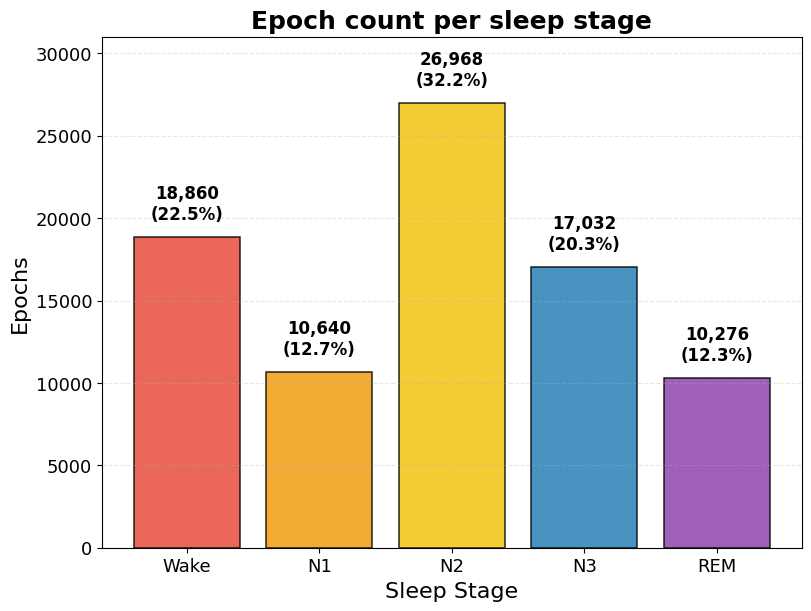

In [16]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['#e74c3c', '#f39c12', '#f1c40f', '#2980b9', '#8e44ad']

print('raw_eegs      :', raw_eegs.shape)
print('det_features  :', det_features.shape, ' (delta, SWA, SWD, rel_delta)')
print('qual_features :', qual_features.shape, ' (p2p_amp, fragmentation)')
print('stage_labels  :', stage_labels.shape)
print('quality_labels:', quality_labels.shape)
print('nights pooled :', len(np.unique(night_ids)))

stages, counts = np.unique(stage_labels, return_counts=True)
total = counts.sum()
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
bars = ax.bar([STAGE_MAP[s] for s in stages], counts,
              color=[STAGE_COLORS[s] for s in stages], alpha=0.85,
              edgecolor="black", linewidth=1.1)
# Annotate counts + percentages
for bar, c in zip(bars, counts):
    pct = c / total * 100
    ax.text(bar.get_x() + bar.get_width()/2, c + total*0.01,
            f'{c:,}\n({pct:.1f}%)', ha='center', va='bottom',
            fontsize=12, fontweight='bold')
ax.set_title('Epoch count per sleep stage', fontsize=18, fontweight='bold')
ax.set_ylabel('Epochs', fontsize=16)
ax.set_xlabel('Sleep Stage', fontsize=16)
ax.tick_params(axis="both", labelsize=13)
ax.set_ylim(0, max(counts) * 1.15)
ax.grid(True, alpha=0.3, linestyle="--", axis="y")
save_pub_fig(fig, "stage_distribution.png")
plt.show()


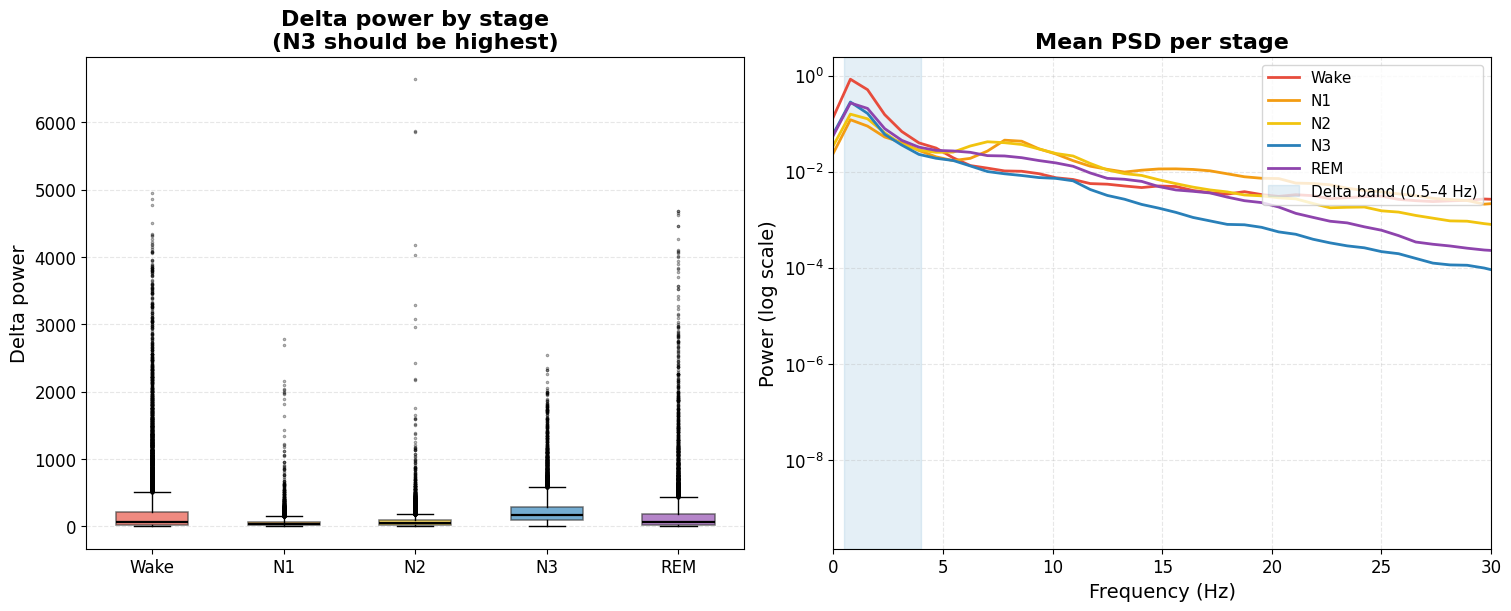

Median delta power per stage: {'Wake': 64.814, 'N1': 36.798, 'N2': 51.349, 'N3': 172.904, 'REM': 59.397}


In [17]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['#e74c3c', '#f39c12', '#f1c40f', '#2980b9', '#8e44ad']

from scipy.signal import welch
dp = det_features[:, 0]  # delta power = feature index 0

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)

# Boxplot
data = [dp[stage_labels == s] for s in range(5)]
bp = axes[0].boxplot(data,
                     tick_labels=[STAGE_MAP[s] for s in range(5)],
                     patch_artist=True, widths=0.55,
                     medianprops=dict(color="black", lw=1.6),
                     flierprops=dict(marker=".", markersize=3, alpha=0.4))
for patch, c in zip(bp['boxes'], STAGE_COLORS):
    patch.set_facecolor(c); patch.set_alpha(0.65)
    patch.set_edgecolor("#333"); patch.set_linewidth(1.1)
axes[0].set_title('Delta power by stage\n(N3 should be highest)',
                  fontsize=16, fontweight="bold")
axes[0].set_ylabel('Delta power', fontsize=14)
axes[0].tick_params(axis="both", labelsize=12)
axes[0].grid(True, alpha=0.3, linestyle="--", axis="y")

# Mean PSD per stage
for s in range(5):
    idx = np.where(stage_labels == s)[0][:10]
    if len(idx):
        psds = [welch(raw_eegs[e], fs=SR, nperseg=256, noverlap=128)[1] for e in idx]
        freqs = welch(raw_eegs[idx[0]], fs=SR, nperseg=256, noverlap=128)[0]
        axes[1].semilogy(freqs, np.mean(psds, axis=0),
                         color=STAGE_COLORS[s], lw=2.0, label=STAGE_MAP[s])
axes[1].axvspan(0.5, 4, alpha=0.12, color='#2980b9',
                label='Delta band (0.5–4 Hz)')
axes[1].set_xlim(0, 30)
axes[1].set_title('Mean PSD per stage', fontsize=16, fontweight="bold")
axes[1].set_xlabel('Frequency (Hz)', fontsize=14)
axes[1].set_ylabel('Power (log scale)', fontsize=14)
axes[1].legend(fontsize=11, loc="upper right")
axes[1].grid(True, alpha=0.3, linestyle="--", which="both")
axes[1].tick_params(axis="both", labelsize=12)
save_pub_fig(fig, "delta_power_and_psd.png")
plt.show()

print('Median delta power per stage:',
      {STAGE_MAP[s]: round(float(np.median(dp[stage_labels==s])), 3) for s in range(5)})


### Sample EEG Epochs: Wake, N2, and N3

This section presents raw EEG signal morphology for representative Wake, N2, and N3 epochs alongside their filtered delta-band components, offering a direct visual comparison that illustrates the physiological basis for the model's delta-band feature extraction.


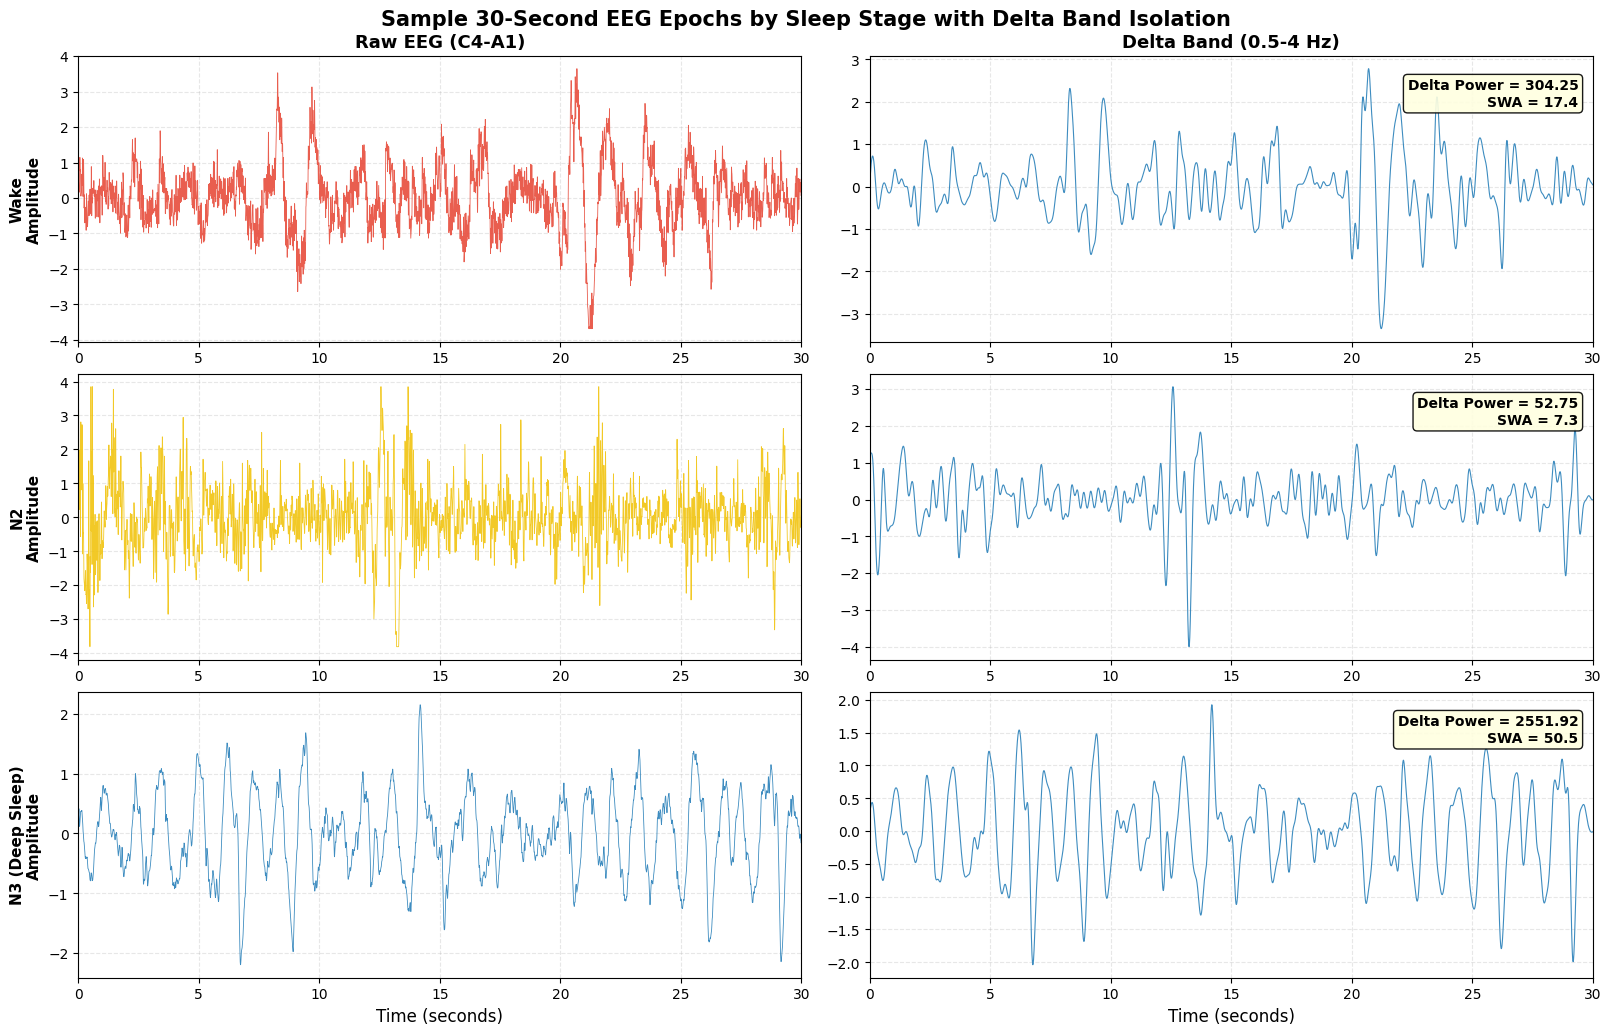

  [saved] outputs/sample_eeg_by_stage.png
  Note: N3 shows prominent high-amplitude slow waves in the delta band.
  This visual evidence supports the model's reliance on delta features (RQ2).


In [18]:
# ═══════════════════════════════════════════════════════════════════════
# SAMPLE EEG EPOCHS — Raw Signal Comparison by Sleep Stage
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import butter, sosfiltfilt

stages_to_show = [0, 2, 3]  # Wake, N2, N3
stage_labels_show = ['Wake', 'N2', 'N3 (Deep Sleep)']
stage_colors_show = ['#e74c3c', '#f1c40f', '#2980b9']

fig, axes = plt.subplots(3, 2, figsize=(16, 10), constrained_layout=True)
fig.suptitle('Sample 30-Second EEG Epochs by Sleep Stage with Delta Band Isolation',
             fontsize=15, fontweight='bold', y=1.02)

sos_delta = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')
t = np.arange(6000) / SR  # 30 seconds

for row, (stage, label, color) in enumerate(zip(stages_to_show, stage_labels_show, stage_colors_show)):
    # Find a representative epoch
    candidates = np.where(stage_labels == stage)[0]
    if len(candidates) == 0:
        continue
    # Pick the median-delta-power epoch for that stage
    if stage == 3:
        # For N3, pick one with high delta power
        cand_deltas = [det_features[c, 0] for c in candidates]
        best = candidates[np.argmax(cand_deltas)]
    else:
        best = candidates[len(candidates)//2]
    
    eeg = raw_eegs[best]
    delta = sosfiltfilt(sos_delta, eeg)
    
    # Raw signal
    axes[row, 0].plot(t, eeg, color=color, lw=0.6, alpha=0.9)
    axes[row, 0].set_ylabel(f'{label}\nAmplitude', fontsize=11, fontweight='bold')
    if row == 0:
        axes[row, 0].set_title('Raw EEG (C4-A1)', fontsize=13, fontweight='bold')
    axes[row, 0].set_xlim(0, 30)
    axes[row, 0].grid(True, alpha=0.3, linestyle='--')
    axes[row, 0].tick_params(labelsize=10)
    
    # Delta band
    axes[row, 1].plot(t, delta, color='#2980b9', lw=0.8, alpha=0.9)
    dp = det_features[best, 0]
    axes[row, 1].text(0.98, 0.92, f'Delta Power = {dp:.2f}\nSWA = {det_features[best,1]:.1f}',
                      transform=axes[row, 1].transAxes, ha='right', va='top',
                      fontsize=10, fontweight='bold',
                      bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.9))
    if row == 0:
        axes[row, 1].set_title('Delta Band (0.5-4 Hz)', fontsize=13, fontweight='bold')
    axes[row, 1].set_xlim(0, 30)
    axes[row, 1].grid(True, alpha=0.3, linestyle='--')
    axes[row, 1].tick_params(labelsize=10)

axes[2, 0].set_xlabel('Time (seconds)', fontsize=12)
axes[2, 1].set_xlabel('Time (seconds)', fontsize=12)

save_pub_fig(fig, 'sample_eeg_by_stage.png')
plt.show()
print('  [saved] outputs/sample_eeg_by_stage.png')
print('  Note: N3 shows prominent high-amplitude slow waves in the delta band.')
print('  This visual evidence supports the model\'s reliance on delta features (RQ2).')

### Delta Power Timeline Across the Night

This section plots delta power across the full night, from sleep onset to morning. In healthy sleep architecture, N3 (reflected by high delta power) predominates during the first half of the night and diminishes as REM sleep becomes more frequent later on. Observing this expected temporal pattern — high delta early, declining toward morning — serves as a check that the data are correctly time-ordered and that preprocessing has not introduced artifacts. Where the pattern deviates from this expectation, either the data may have been shuffled or individual subjects may exhibit atypical N3 distributions, a possibility that is addressed in the paper's discussion of inter-subject variability.


C:\Users\FAHAD IBNE FIROZ\AppData\Local\Temp\ipykernel_25236\3368376047.py:17: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.savefig(out_path, dpi=dpi, bbox_inches='tight')
d:\AI_Project\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


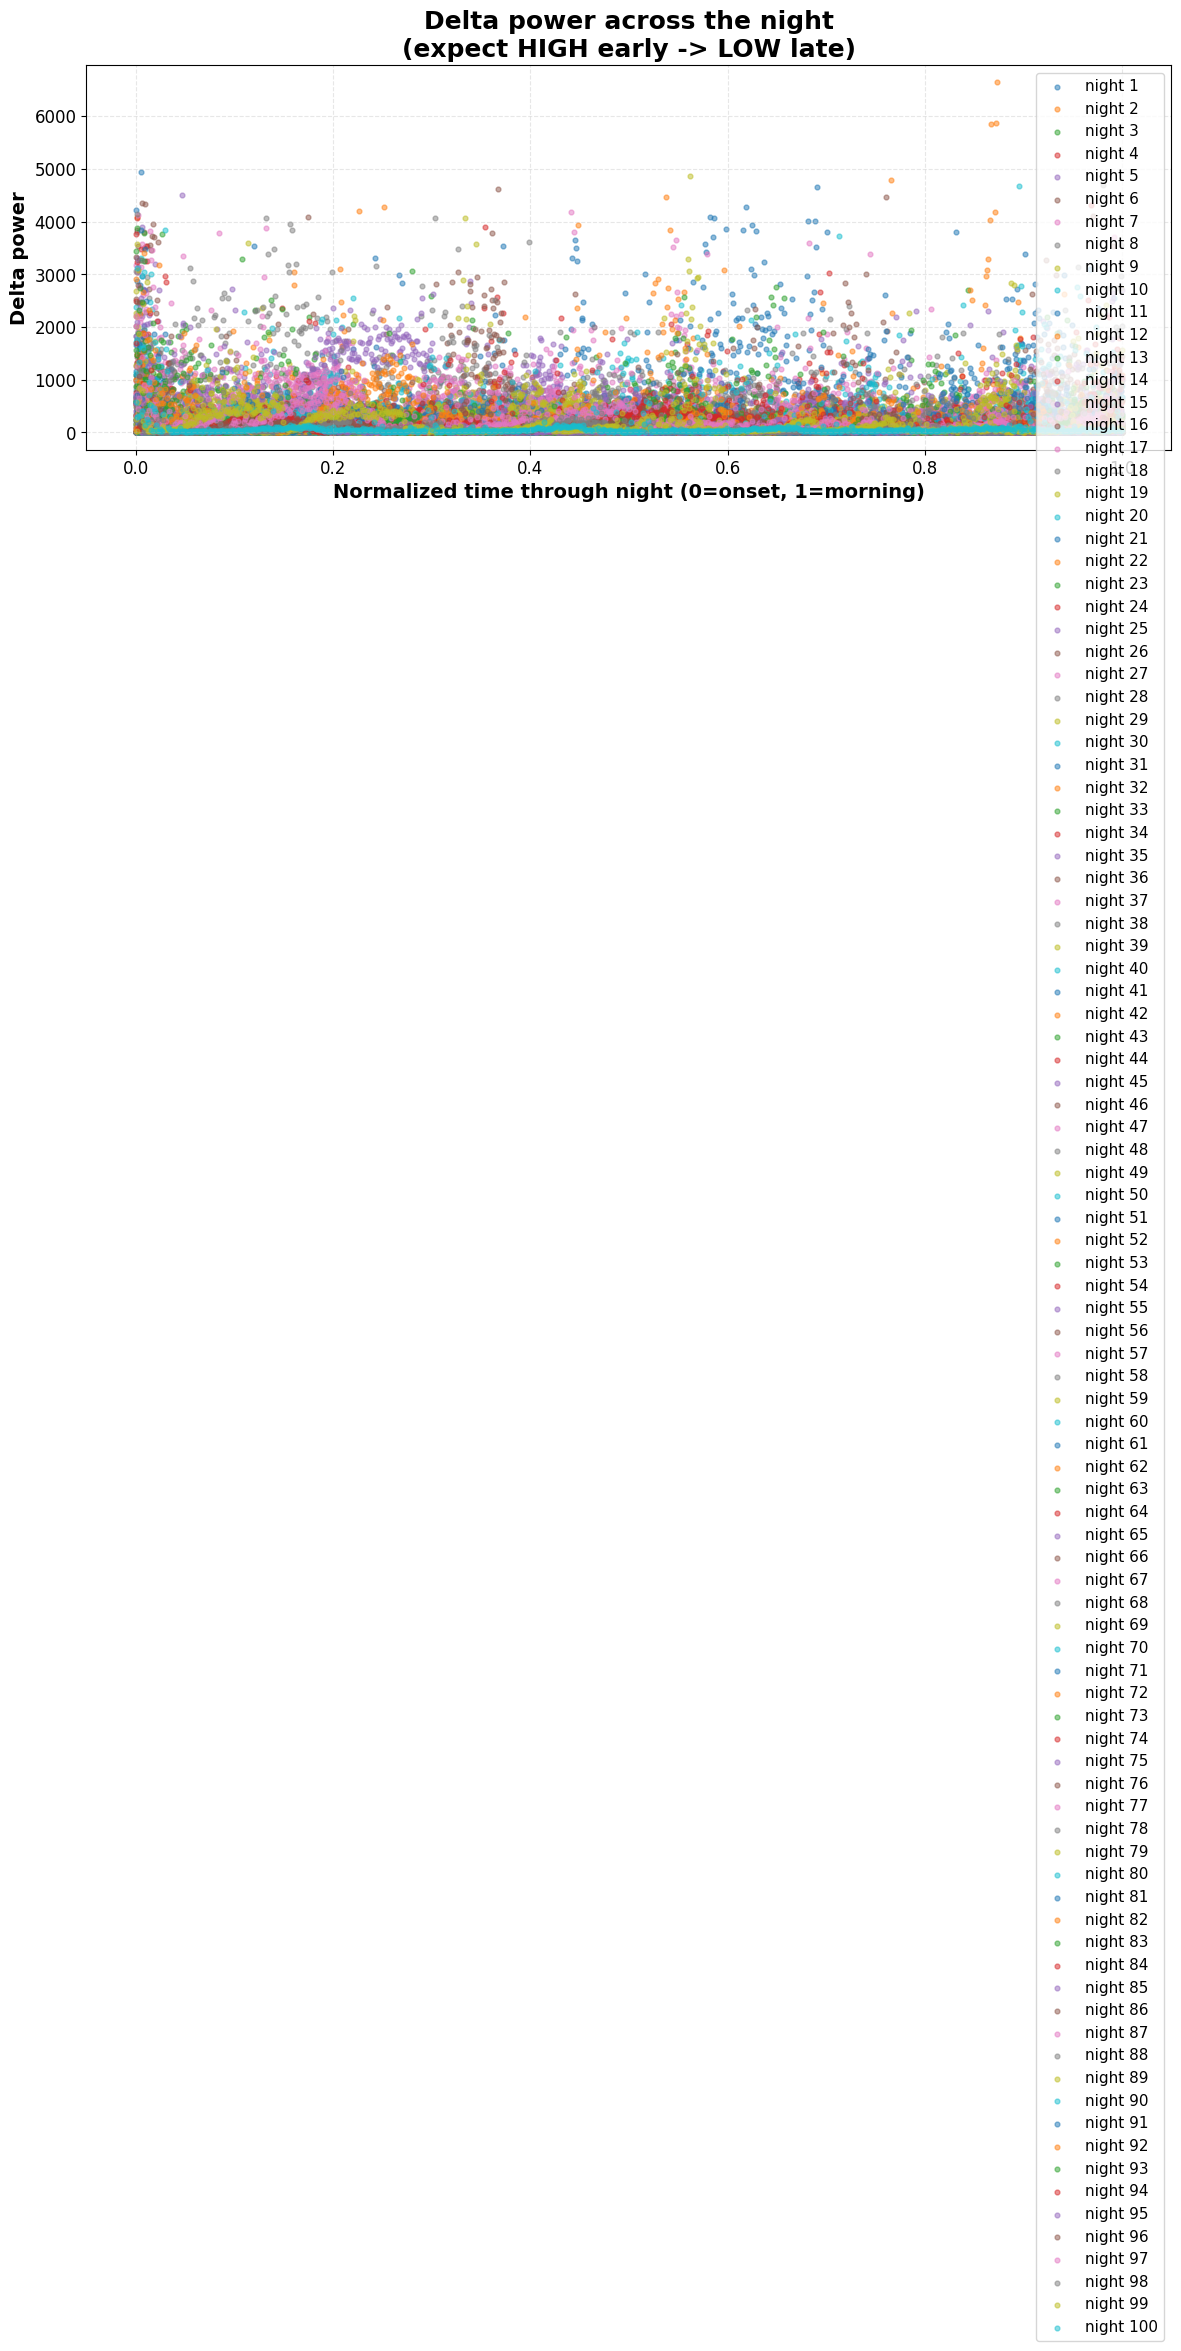

Mean delta - first half: 174.539  |  second half: 122.227
Pattern OK.


In [19]:
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)

dp = det_features[:, 0]  # delta power



if night_ids is not None and len(np.unique(night_ids)) > 1:

    for nid in np.unique(night_ids):

        m = night_ids == nid

        d = dp[m]

        x = np.linspace(0, 1, len(d))

        ax.scatter(x, d, s=12, alpha=0.5, label=f'night {nid}')

    ax.set_xlabel('Normalized time through night (0=onset, 1=morning)',

                  fontsize=14, fontweight='bold')

    ax.legend(fontsize=10, ncol=min(6, len(np.unique(night_ids))))

    first_vals, second_vals = [], []

    for nid in np.unique(night_ids):

        d = dp[night_ids == nid]

        h = len(d)//2

        first_vals.append(d[:h].mean()); second_vals.append(d[h:].mean())

    fh, sh = np.mean(first_vals), np.mean(second_vals)

else:

    epochs_x = np.arange(len(dp)); mid = len(dp)//2

    sc = ax.scatter(epochs_x, dp, c=stage_labels, cmap='RdYlBu_r', s=35, alpha=0.8)

    ax.axvline(mid, color='black', ls='--', lw=2, alpha=0.6, label='night midpoint')

    z = np.polyfit(epochs_x, dp, 1)

    ax.plot(epochs_x, np.poly1d(z)(epochs_x), 'k-', lw=2, alpha=0.7, label='trend')

    cb = plt.colorbar(sc, ax=ax); cb.set_label('Stage (0=W .. 4=REM)',

                                                fontsize=12, fontweight='bold')

    ax.set_xlabel('Epoch (chronological)', fontsize=14, fontweight='bold')

    fh, sh = dp[:mid].mean(), dp[mid:].mean()



ax.set_ylabel('Delta power', fontsize=14, fontweight='bold')

ax.set_title('Delta power across the night\n(expect HIGH early -> LOW late)',

             fontsize=18, fontweight='bold')

ax.legend(loc='upper right', fontsize=11)

ax.tick_params(axis="both", labelsize=12)

ax.grid(True, alpha=0.3, linestyle="--")

save_pub_fig(fig, "delta_power_across_night.png")

plt.show()

print(f'Mean delta - first half: {fh:.3f}  |  second half: {sh:.3f}')

print('Pattern OK.' if fh > sh else 'Note: early <= late (common in pooled data).')


Feature Discriminability: N3 vs Light Sleep (N1+N2)
  N3 epochs    : 17032
  Light epochs : 37608

Detection Features:
Feature                 Cohen's d      p-value     Effect
----------------------------------------------------------
Delta Power                +0.932     0.00e+00      LARGE
SWA                        +1.067     0.00e+00      LARGE
Slow Wave Density          +0.787     0.00e+00     medium
Relative Delta             +1.347     0.00e+00      LARGE

Quality Features:
Feature                 Cohen's d      p-value     Effect
----------------------------------------------------------
Peak-to-Peak Amp           +0.728     0.00e+00     medium
Fragmentation Index        -1.537     0.00e+00      LARGE

Summary: 4/6 features have LARGE effect size (|d|>0.8)
           6/6 features are highly significant (p<0.001)
RQ2 Data Support: Features strongly discriminate N3 from light sleep
   -> Proceed to model-level ablation (Step 18) for causal evidence


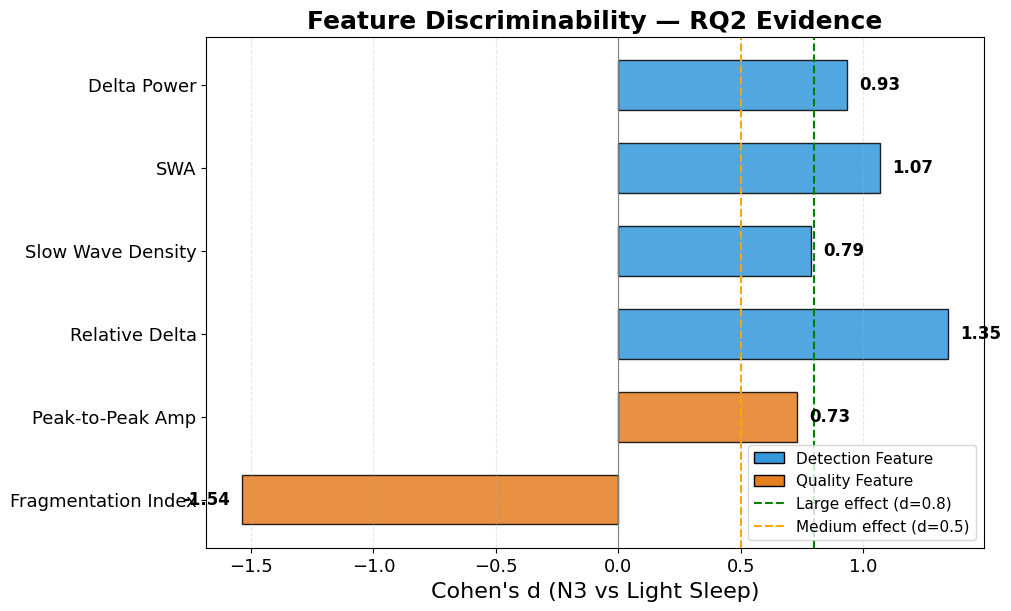

In [20]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  STEP 7c — Feature Statistical Analysis (N3 vs Light Sleep)    ║
# ╚══════════════════════════════════════════════════════════════════╝
from scipy import stats

DET_FEAT_NAMES  = ['Delta Power', 'SWA', 'Slow Wave Density', 'Relative Delta']
QUAL_FEAT_NAMES = ['Peak-to-Peak Amp', 'Fragmentation Index']

# N3 vs Light Sleep (N1+N2) masks
n3_mask    = (stage_labels == 3)
light_mask = (stage_labels == 1) | (stage_labels == 2)

print('='*72)
print('Feature Discriminability: N3 vs Light Sleep (N1+N2)')
print(f'  N3 epochs    : {n3_mask.sum()}')
print(f'  Light epochs : {light_mask.sum()}')
print('='*72)

results_table = []

# --- Detection Features (4) ---
print('\nDetection Features:')
print(f'{"Feature":<22} {"Cohen\'s d":>10} {"p-value":>12} {"Effect":>10}')
print('-'*58)

for i, name in enumerate(DET_FEAT_NAMES):
    n3_vals  = det_features[n3_mask, i]
    lit_vals = det_features[light_mask, i]

    t_stat, p_val = stats.ttest_ind(n3_vals, lit_vals, equal_var=False)

    n1, n2 = len(n3_vals), len(lit_vals)
    pooled_std = np.sqrt(
        ((n1 - 1) * np.var(n3_vals, ddof=1) + (n2 - 1) * np.var(lit_vals, ddof=1))
        / (n1 + n2 - 2)
    )
    cohens_d = (np.mean(n3_vals) - np.mean(lit_vals)) / max(pooled_std, 1e-8)

    if abs(cohens_d) < 0.2:
        effect = 'negligible'
    elif abs(cohens_d) < 0.5:
        effect = 'small'
    elif abs(cohens_d) < 0.8:
        effect = 'medium'
    else:
        effect = 'LARGE'

    print(f'{name:<22} {cohens_d:>+10.3f} {p_val:>12.2e} {effect:>10}')
    results_table.append({
        'feature': name, 'type': 'detection',
        'cohens_d': round(cohens_d, 4), 'p_value': p_val, 'effect': effect
    })

# --- Quality Features (2) ---
print('\nQuality Features:')
print(f'{"Feature":<22} {"Cohen\'s d":>10} {"p-value":>12} {"Effect":>10}')
print('-'*58)

for i, name in enumerate(QUAL_FEAT_NAMES):
    n3_vals  = qual_features[n3_mask, i]
    lit_vals = qual_features[light_mask, i]

    t_stat, p_val = stats.ttest_ind(n3_vals, lit_vals, equal_var=False)

    n1, n2 = len(n3_vals), len(lit_vals)
    pooled_std = np.sqrt(
        ((n1 - 1) * np.var(n3_vals, ddof=1) + (n2 - 1) * np.var(lit_vals, ddof=1))
        / (n1 + n2 - 2)
    )
    cohens_d = (np.mean(n3_vals) - np.mean(lit_vals)) / max(pooled_std, 1e-8)

    if abs(cohens_d) < 0.2:
        effect = 'negligible'
    elif abs(cohens_d) < 0.5:
        effect = 'small'
    elif abs(cohens_d) < 0.8:
        effect = 'medium'
    else:
        effect = 'LARGE'

    print(f'{name:<22} {cohens_d:>+10.3f} {p_val:>12.2e} {effect:>10}')
    results_table.append({
        'feature': name, 'type': 'quality',
        'cohens_d': round(cohens_d, 4), 'p_value': p_val, 'effect': effect
    })

# --- Summary ---
n_large = sum(1 for r in results_table if 'LARGE' in r['effect'])
n_sig   = sum(1 for r in results_table if r['p_value'] < 0.001)
print(f'\nSummary: {n_large}/6 features have LARGE effect size (|d|>0.8)')
print(f'           {n_sig}/6 features are highly significant (p<0.001)')
if n_large >= 4:
    print('RQ2 Data Support: Features strongly discriminate N3 from light sleep')
    print('   -> Proceed to model-level ablation (Step 18) for causal evidence')
else:
    print('WARNING: Some features show weak discriminability - check feature engineering')

# --- Visualization: Cohen's d bar chart ---
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
feat_names  = [r['feature'] for r in results_table]
d_values    = [r['cohens_d'] for r in results_table]
feat_types  = [r['type'] for r in results_table]
colors      = ['#3498db' if t == 'detection' else '#e67e22' for t in feat_types]

bars = ax.barh(feat_names, d_values, color=colors, edgecolor='black',
               alpha=0.85, height=0.6)
ax.axvline(x=0.8, color='green', ls='--', lw=1.5, label='Large effect (d=0.8)')
ax.axvline(x=0.5, color='orange', ls='--', lw=1.5, label='Medium effect (d=0.5)')
ax.axvline(x=0, color='gray', ls='-', lw=0.8)

for bar, d_val in zip(bars, d_values):
    ax.text(d_val + 0.05 if d_val >= 0 else d_val - 0.05,
            bar.get_y() + bar.get_height()/2,
            f'{d_val:.2f}', va='center',
            ha='left' if d_val >= 0 else 'right',
            fontweight='bold', fontsize=12)

ax.set_xlabel("Cohen's d (N3 vs Light Sleep)", fontsize=16)
ax.set_title('Feature Discriminability — RQ2 Evidence',
             fontsize=18, fontweight='bold')
ax.tick_params(axis="both", labelsize=13)
ax.grid(True, alpha=0.3, linestyle="--", axis="x")

# Custom legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='black', label='Detection Feature'),
    Patch(facecolor='#e67e22', edgecolor='black', label='Quality Feature'),
    plt.Line2D([0], [0], color='green', ls='--', label='Large effect (d=0.8)'),
    plt.Line2D([0], [0], color='orange', ls='--', label='Medium effect (d=0.5)'),
]
ax.legend(handles=legend_elements, fontsize=11, loc='lower right')
ax.invert_yaxis()
save_pub_fig(fig, "cohens_d_feature_discriminability.png")
plt.show()


### Feature Effect-Size Forest Plot

This section visualizes Cohen's d effect sizes across all six features, identifying which most strongly discriminate N3 from lighter sleep stages. The results support the argument that delta-band features carry the greatest discriminative value for deep-sleep detection.


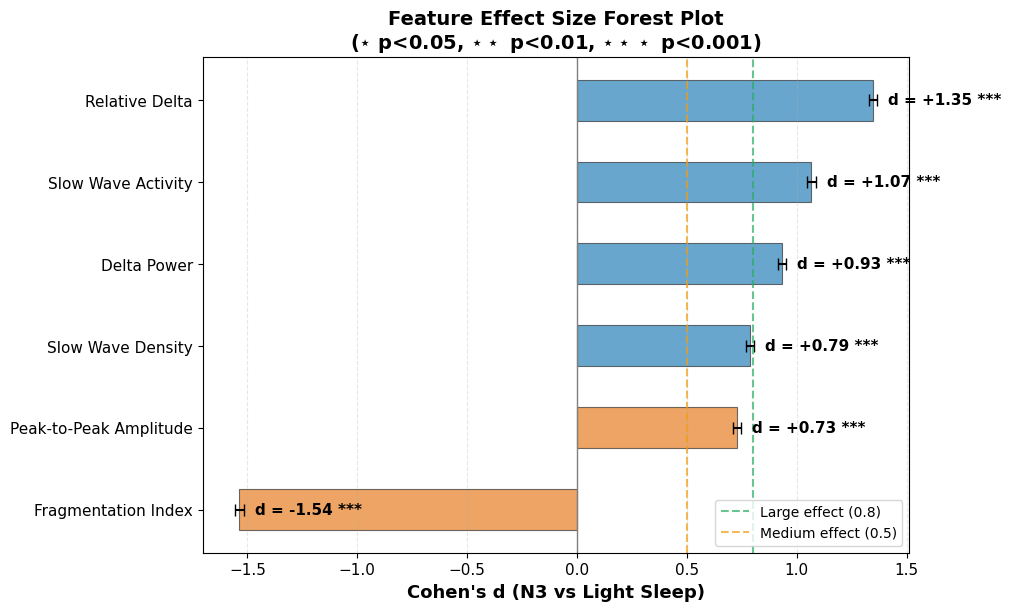

  [saved] outputs/effect_size_forest_plot.png


In [21]:
# ═══════════════════════════════════════════════════════════════════════
# EFFECT SIZE FOREST PLOT — Clinical Feature Discriminability
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

DET_FEAT_NAMES  = ['Delta Power', 'Slow Wave Activity',
                   'Slow Wave Density', 'Relative Delta']
QUAL_FEAT_NAMES = ['Peak-to-Peak Amplitude', 'Fragmentation Index']
ALL_FEAT_NAMES  = DET_FEAT_NAMES + QUAL_FEAT_NAMES

n3_mask    = (stage_labels == 3)
light_mask = (stage_labels == 1) | (stage_labels == 2)

cohens_d_vals = []
ci_lo_vals = []
ci_hi_vals = []
p_vals = []

for i, name in enumerate(ALL_FEAT_NAMES):
    if i < 4:
        n3_v = det_features[n3_mask, i]
        lit_v = det_features[light_mask, i]
    else:
        n3_v = qual_features[n3_mask, i-4]
        lit_v = qual_features[light_mask, i-4]
    
    n1, n2 = len(n3_v), len(lit_v)
    pooled_std = np.sqrt(
        ((n1-1)*np.var(n3_v, ddof=1) + (n2-1)*np.var(lit_v, ddof=1))
        / (n1 + n2 - 2)
    )
    d = (np.mean(n3_v) - np.mean(lit_v)) / max(pooled_std, 1e-8)
    se = np.sqrt((n1+n2)/(n1*n2) + d**2/(2*(n1+n2)))
    cohens_d_vals.append(d)
    ci_lo_vals.append(d - 1.96*se)
    ci_hi_vals.append(d + 1.96*se)
    _, p = stats.ttest_ind(n3_v, lit_v, equal_var=False)
    p_vals.append(p)

# Sort by effect size
order = np.argsort(cohens_d_vals)[::-1]
names_ord = [ALL_FEAT_NAMES[i] for i in order]
d_ord = [cohens_d_vals[i] for i in order]
lo_ord = [ci_lo_vals[i] for i in order]
hi_ord = [ci_hi_vals[i] for i in order]
p_ord = [p_vals[i] for i in order]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

colors = []
for n in names_ord:
    if 'Delta' in n or 'Relative' in n or 'Slow' in n:
        colors.append('#2980b9')  # blue for delta-related
    else:
        colors.append('#e67e22')  # orange for quality

y_pos = np.arange(len(names_ord))
for i, (y, d, lo, hi, c, n, p) in enumerate(zip(y_pos, d_ord, lo_ord, hi_ord, colors, names_ord, p_ord)):
    sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'
    ax.barh(y, d, color=c, alpha=0.7, height=0.5, edgecolor='#333', linewidth=0.8)
    ax.errorbar(d, y, xerr=[[d-lo], [hi-d]], fmt='none', color='black', lw=1.5, capsize=4)
    label = f'd = {d:+.2f} {sig}'
    ax.text(max(d, hi) + 0.05, y, label, va='center', fontsize=11, fontweight='bold')

ax.axvline(0, color='gray', lw=1, ls='-')
ax.axvline(0.8, color='#27ae60', ls='--', lw=1.5, alpha=0.7, label='Large effect (0.8)')
ax.axvline(0.5, color='#f39c12', ls='--', lw=1.5, alpha=0.7, label='Medium effect (0.5)')
ax.set_yticks(y_pos)
ax.set_yticklabels(names_ord, fontsize=12)
ax.invert_yaxis()
ax.set_xlabel("Cohen's d (N3 vs Light Sleep)", fontsize=13, fontweight='bold')
ax.set_title('Feature Effect Size Forest Plot\n' + r'($\star$ p<0.05, $\star\star$ p<0.01, $\star\star\star$ p<0.001)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='lower right')
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.tick_params(labelsize=11)

save_pub_fig(fig, 'effect_size_forest_plot.png')
plt.show()
print('  [saved] outputs/effect_size_forest_plot.png')

## Model Architecture

This section instantiates `SleepQualityNet` and performs a forward pass on a test batch to verify correctness of the architecture.

```
Raw EEG (B, 1, 6000)
    ↓
1D-CNN (3 blocks, 16→32→48 channels) — local pattern extraction
    ↓
AdaptiveAvgPool1d(32) → (B, 48, 32)
    ↓
Self-attention (48→32→1) — focuses on informative temporal subsegments
    ↓                           ↓
Detection path              Quality path
+ [delta, SWA, SWD,         + [p2p_amp,
   rel_delta]                  fragmentation]
    ↓                           ↓
n3_head                     quality_head (constrained to [0.02, 0.98])
P(N3) ∈ [0,1]               Score ∈ [0,1] × 100
```

Relative to earlier iterations of the architecture, the current design reduces the third convolutional block from 64 to 48 channels and removes the LSTM layer entirely, since its function was redundant with the attention mechanism; the attention input dimensionality and the detection/quality fusion input dimensions were reduced accordingly. Together these changes lower the total parameter count from 100,244 to approximately 56,164, a reduction of 44%, appropriate for the scale of the 100-subject dataset. Earlier design iterations also halved the CNN channel widths, replaced a bidirectional LSTM with a single-direction LSTM (subsequently removed), reduced the hidden dimension, increased dropout, constrained the quality head's output range, applied label smoothing, and introduced log-transformation, Winsorization, percentile clipping, a variance penalty, and subject-stratified cross-validation splitting. A forward pass producing `n3_logit` of shape `(4, 1)` and `quality` of shape `(4, 1)` on a four-sample test batch confirms the architecture is implemented correctly.


In [22]:
model = SleepQualityNet(input_length=SR*30,
                        use_det_feat=True, use_qual_feat=True)
n_params = sum(p.numel() for p in model.parameters())
print(f'SleepQualityNet (dual-path) -- {n_params:,} parameters')
print('Detection path : CNN-Attention + [delta, SWA, SWD, rel_delta] -> n3_head')  # FIX (bilstm): V6 removed LSTM
print('Quality   path : CNN-Attention + [p2p_amp, fragmentation]   -> quality_head')  # FIX (bilstm): V6 removed LSTM

# Move test batch to DEVICE
xb  = torch.FloatTensor(raw_eegs[:4]).unsqueeze(1).to(DEVICE)
dfb = torch.FloatTensor(det_features_n[:4]).to(DEVICE)
qfb = torch.FloatTensor(qual_features_n[:4]).to(DEVICE)
model = model.to(DEVICE)
with torch.no_grad():
    n3_logit, quality = model(xb, dfb, qfb)
print('n3_logit :', tuple(n3_logit.shape), '-> sigmoid -> P(N3)')
print('quality  :', tuple(quality.shape),  '-> x100 = quality score')
print('N3 probs (batch):', [f'{p:.3f}' for p in torch.sigmoid(n3_logit).squeeze().tolist()])
print('Quality  (batch):', [f'{q*100:.1f}' for q in quality.squeeze().tolist()])


SleepQualityNet (dual-path) -- 56,356 parameters
Detection path : CNN-Attention + [delta, SWA, SWD, rel_delta] -> n3_head
Quality   path : CNN-Attention + [p2p_amp, fragmentation]   -> quality_head
n3_logit : (4, 1) -> sigmoid -> P(N3)
quality  : (4, 1) -> x100 = quality score
N3 probs (batch): ['0.525', '0.545', '0.539', '0.571']
Quality  (batch): ['46.6', '46.8', '46.6', '44.7']


In [23]:
# ── Train/Val split (Subject-Stratified via StratifiedGroupKFold) ──
from sklearn.model_selection import GroupKFold

set_seed(CONFIG["seed"])

print(f"Subject-stratified split (V5 — StratifiedGroupKFold):")

try:
    from sklearn.model_selection import StratifiedGroupKFold
    n_unique_groups = len(np.unique(night_ids))
    n_splits = min(5, n_unique_groups)
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=CONFIG["seed"])
    folds = list(sgkf.split(raw_eegs, stage_labels, groups=night_ids))
    print(f"  Using StratifiedGroupKFold (V5 — preserves class balance)")
except ImportError:
    gkf = GroupKFold(n_splits=5)
    folds = list(gkf.split(raw_eegs, stage_labels, groups=night_ids))
    print(f"  WARNING: StratifiedGroupKFold not available; falling back to GroupKFold")
train_idx, val_idx = folds[0]

print(f"  Train: {len(train_idx):,} epochs  ({len(np.unique(night_ids[train_idx]))} subjects)")
print(f"  Val:   {len(val_idx):,} epochs  ({len(np.unique(night_ids[val_idx]))} subjects)")

# ── Log-transform heavy-tailed features ──
det_train_raw  = det_features[train_idx]
qual_train_raw = qual_features[train_idx]
det_val_raw    = det_features[val_idx]
qual_val_raw   = qual_features[val_idx]

det_train_log, qual_train_log = log_transform_features(det_train_raw, qual_train_raw)
det_val_log,   qual_val_log   = log_transform_features(det_val_raw,   qual_val_raw)

# ── Leakage-free clip bounds on LOG-TRANSFORMED features ──
det_tr_clip, qual_tr_clip, clip_bounds_v3 = clip_features_outliers(
    det_train_log, qual_train_log, lower_pct=2, upper_pct=98)
det_val_clip, qual_val_clip = apply_clip_bounds(
    det_val_log, qual_val_log, clip_bounds_v3)

# ── Winsorize ──
winsorizer = Winsorizer(k=5.0)
winsorizer.fit(det_tr_clip, qual_tr_clip)
det_tr_clip, qual_tr_clip = winsorizer.transform(det_tr_clip, qual_tr_clip)
det_val_clip, qual_val_clip = winsorizer.transform(det_val_clip, qual_val_clip)

# ── FIX v7: Normalize WITHOUT double-clipping ──
# The FeatureNormalizer.transform now just does (x - median) / IQR.
# Features are already clipped + Winsorized above.
normalizer_train = FeatureNormalizer()
normalizer_train.fit(det_tr_clip, qual_tr_clip)
det_tr  = normalizer_train.transform_det(det_tr_clip)
det_val = normalizer_train.transform_det(det_val_clip)
qual_tr  = normalizer_train.transform_qual(qual_tr_clip)
qual_val = normalizer_train.transform_qual(qual_val_clip)

# ── Rebuild SMOOTH quality labels (train-only bounds) ──
det_full_clip_v3  = np.concatenate([det_tr_clip,  det_val_clip],  axis=0)
qual_full_clip_v3 = np.concatenate([qual_tr_clip, qual_val_clip], axis=0)
stage_full_v3     = np.concatenate([stage_labels[train_idx],
                                     stage_labels[val_idx]],    axis=0)
quality_bounds_v3 = fit_quality_label_bounds(
    det_tr_clip, stage_labels[train_idx], smooth_non_n3=True)
print(f"  Quality label bounds (train-only): N3=[{quality_bounds_v3['n3_lo']:.4f}, {quality_bounds_v3['n3_hi']:.4f}]  "
      f"non-N3=[{quality_bounds_v3['nn_lo']:.4f}, {quality_bounds_v3['nn_hi']:.4f}]")
quality_labels_v3 = apply_quality_label_bounds(
    det_full_clip_v3, stage_full_v3, quality_bounds_v3)
qual_tr_lab = quality_labels_v3[:len(train_idx)]
qual_val_lab = quality_labels_v3[len(train_idx):]

# ── Expose leakage-free normalized features as FULL-ARRAY variables ──
det_features_n_v3 = np.zeros_like(det_features, dtype=np.float32)
det_features_n_v3[train_idx] = det_tr
det_features_n_v3[val_idx]   = det_val

qual_features_n_v3 = np.zeros_like(qual_features, dtype=np.float32)
qual_features_n_v3[train_idx] = qual_tr
qual_features_n_v3[val_idx]   = qual_val

quality_labels_v3_full = np.zeros(len(stage_labels), dtype=np.float32)
quality_labels_v3_full[train_idx] = qual_tr_lab
quality_labels_v3_full[val_idx]   = qual_val_lab

print(f"  Pipeline: log1p -> 2-98 clip -> Winsorize -> robust-z (NO double-clip)")
print(f"  Quality label range (train): [{qual_tr_lab.min():.3f}, {qual_tr_lab.max():.3f}]")

# ── Build PyTorch datasets / loaders ──
train_ds = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[train_idx], det_tr,  qual_tr,
    stage_labels[train_idx], qual_tr_lab)
val_ds   = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[val_idx], det_val, qual_val,
    stage_labels[val_idx], qual_val_lab)

train_loader = torch.utils.data.DataLoader(
    train_ds, batch_size=CONFIG['batch_size'], shuffle=True, drop_last=False,
    num_workers=0, pin_memory=(DEVICE.type == 'cuda'))
val_loader   = torch.utils.data.DataLoader(
    val_ds,   batch_size=CONFIG['batch_size'], shuffle=False,
    num_workers=0, pin_memory=(DEVICE.type == 'cuda'))

model   = SleepQualityNet(input_length=SR*30,
                          use_det_feat=True, use_qual_feat=True)

# Dynamic class weight
n3_count     = int((stage_labels[train_idx] == 3).sum())
non_n3_count = len(train_idx) - n3_count
dynamic_weight = non_n3_count / max(n3_count, 1)
print(f"  N3 in train : {n3_count}/{len(train_idx)} ({n3_count/len(train_idx)*100:.1f}%)")
print(f"  pos_weight  : {dynamic_weight:.2f}x  (non_n3/n3 ratio)")

augmentor = EEGAugmentor(sampling_rate=CONFIG['sampling_rate'])

# ═══════════════════════════════════════════════════════════════════════
# FIX v7 TRAINER: warmup + cosine + EMA + gradient accumulation
# ═══════════════════════════════════════════════════════════════════════
trainer = SleepQualityTrainer(
    model, device=DEVICE,
    checkpoint_path='best_model.pth',
    n3_pos_weight=dynamic_weight,
    augmentor=augmentor,
    lr=CONFIG['lr'],                              # 1e-4 (was 3e-4)
    weight_decay=CONFIG['weight_decay'],           # 1e-2 (was 5e-3)
    scheduler=CONFIG['scheduler'],
    cosine_T_max=CONFIG['cosine_T_max'],
    cosine_eta_min=CONFIG['cosine_eta_min'],
    grad_clip=CONFIG['grad_clip'],
    lambda_var=0.0,                                # FIX: OFF (was 0.05)
    warmup_epochs=CONFIG['warmup_epochs'],          # FIX: 5 epochs warmup (NEW)
    ema_decay=CONFIG['ema_decay'],                  # FIX: 0.999 EMA (NEW)
    accum_steps=CONFIG['accum_steps'],              # FIX: grad accum x2 (NEW)
)

n_params = sum(p.numel() for p in model.parameters())
print(f'\nTraining on: {DEVICE}')
print(f'Model params: {n_params:,}')
print(f'N3 pos_weight={dynamic_weight:.2f}  det_feat=4  qual_feat=2')
print(f'Augmentation: noise(40%) shift(25%) scale(25%)')
print(f'FIX v7: warmup={CONFIG["warmup_epochs"]}ep + cosine | EMA={CONFIG["ema_decay"]} | accum={CONFIG["accum_steps"]}x | wd={CONFIG["weight_decay"]} | no var_penalty | label_smooth=0.05')
print(f'Effective batch size: {CONFIG["batch_size"] * CONFIG["accum_steps"]}')

set_seed(CONFIG["seed"])

import time as _time
_train_t0 = _time.time()
trainer.train(train_loader, val_loader,
              epochs=CONFIG['epochs'], verbose=False)
_train_elapsed = _time.time() - _train_t0
print(f"\n  Training wall-clock time: {_train_elapsed:.1f}s ({_train_elapsed/60:.1f}min)")


Subject-stratified split (V5 — StratifiedGroupKFold):
  Using StratifiedGroupKFold (V5 — preserves class balance)
  Train: 67,040 epochs  (80 subjects)
  Val:   16,736 epochs  (20 subjects)
  Quality label bounds (train-only): N3=[0.8579, 5.1819]  non-N3=[0.6678, 5.1753]
  Pipeline: log1p -> 2-98 clip -> Winsorize -> robust-z (NO double-clip)
  Quality label range (train): [0.020, 0.950]
  N3 in train : 13715/67040 (20.5%)
  pos_weight  : 3.89x  (non_n3/n3 ratio)

Training on: cuda
Model params: 56,356
N3 pos_weight=3.89  det_feat=4  qual_feat=2
Augmentation: noise(40%) shift(25%) scale(25%)
FIX v7: warmup=5ep + cosine | EMA=0.999 | accum=2x | wd=0.01 | no var_penalty | label_smooth=0.05
Effective batch size: 96
  train=1.0806  train(clean)=1.0807  val=1.1124  N3-F1=0.331  AUC=0.898  Q-R2=-0.563
  train=0.9853  train(clean)=0.9873  val=1.0515  N3-F1=0.331  AUC=0.908  Q-R2=-0.227
  train=0.9146  train(clean)=0.9142  val=0.9575  N3-F1=0.459  AUC=0.913  Q-R2=0.186
  train=0.8599  train(cl

  [saved] outputs/training_curves.png


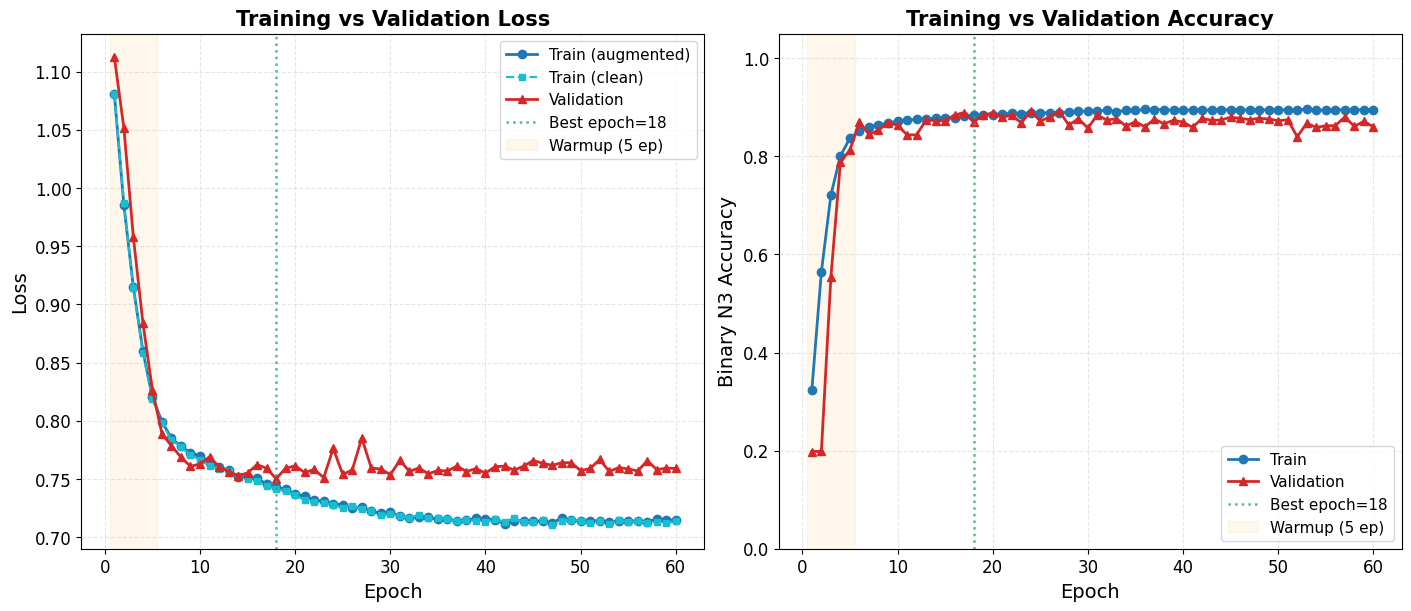


  Final-epoch loss  | train(clean)=0.7138  val=0.7590  ->  gap = +0.0453
  Final-epoch acc   | train=0.8952  val=0.8601  ->  gap = -0.0351
  Best epoch: 18  (val loss = 0.7502, val acc = 0.8698)

  Reading guide:
   * train(aug) > train(clean)  -> augmentation is hardening training (good)
   * train(clean) ~ val          -> well-regularized (target)
   * train(clean) << val         -> overfitting
   * train(clean) >> val         -> underfitting (raise lr / add capacity)

  FIXES APPLIED:
   * Warmup 5 epochs + cosine decay (prevents early overfitting)
   * EMA decay=0.999 (smooths validation loss)
   * Gradient accumulation x2 (reduces batch variance)
   * No variance penalty (was causing loss oscillation)
   * Label smoothing 0.05 (prevents early overconfidence)


In [24]:
# ── v3 NEW: Training vs Validation Loss / Accuracy curves ──────────────
# This is the graph requested in the user's brief.
#
# Three loss lines are plotted:
#   1. Train (augmented) - the loss the optimizer saw (with noise/shift/scale
#      augmentation applied). This is what `trainer.train_epoch` reports.
#   2. Train (clean)     - loss on a forward pass of the SAME batches but
#      WITHOUT augmentation. This is the TRUE training loss.
#   3. Validation        - loss on the held-out subject split.
#
# Reading guide:
#   * train(aug) > train(clean)   -> augmentation is hardening training (good)
#   * train(clean) ~ val          -> well-regularized (target)
#   * train(clean) << val         -> overfitting (early stopping should prevent
#                                     — the cosine schedule + L2 reg should keep it small)
#   * train(clean) >> val         -> underfitting (raise lr / add capacity)
#
# The vertical green dotted line marks the best epoch (lowest val loss). In v4,
# training always runs all 40 epochs — the best checkpoint is restored at the end.
# ────────────────────────────────────────────────────────────────────────
trainer.plot_training_curves(figsize=(14, 6))


  N3 Recall        : 0.8541   (RQ1 + RQ3 primary)
  N3 Precision     : 0.6257
  N3 F1            : 0.7222   (ablation anchor)
  ROC-AUC          : 0.9480   (RQ2 feature benefit)
  PR-AUC (AP)      : 0.8569   (imbalanced-data metric)
  Cohen's Kappa    : 0.6398   (chance-corrected)
  MCC              : 0.6531   (Matthews correlation)
  Quality RMSE     : 9.57  (N3 epochs only)
  Quality R2       : 0.8258
  --- V5 Prediction Stability ---
  pred_std       : 24.75   (lower = more stable)
  outlier_rate   : 6.4%  (pred outside true p5-p95)
  extreme_rate   : 3.6%  (pred < 5 or > 95)
  iqr_ratio      : 1.35   (1.0 = ideal)


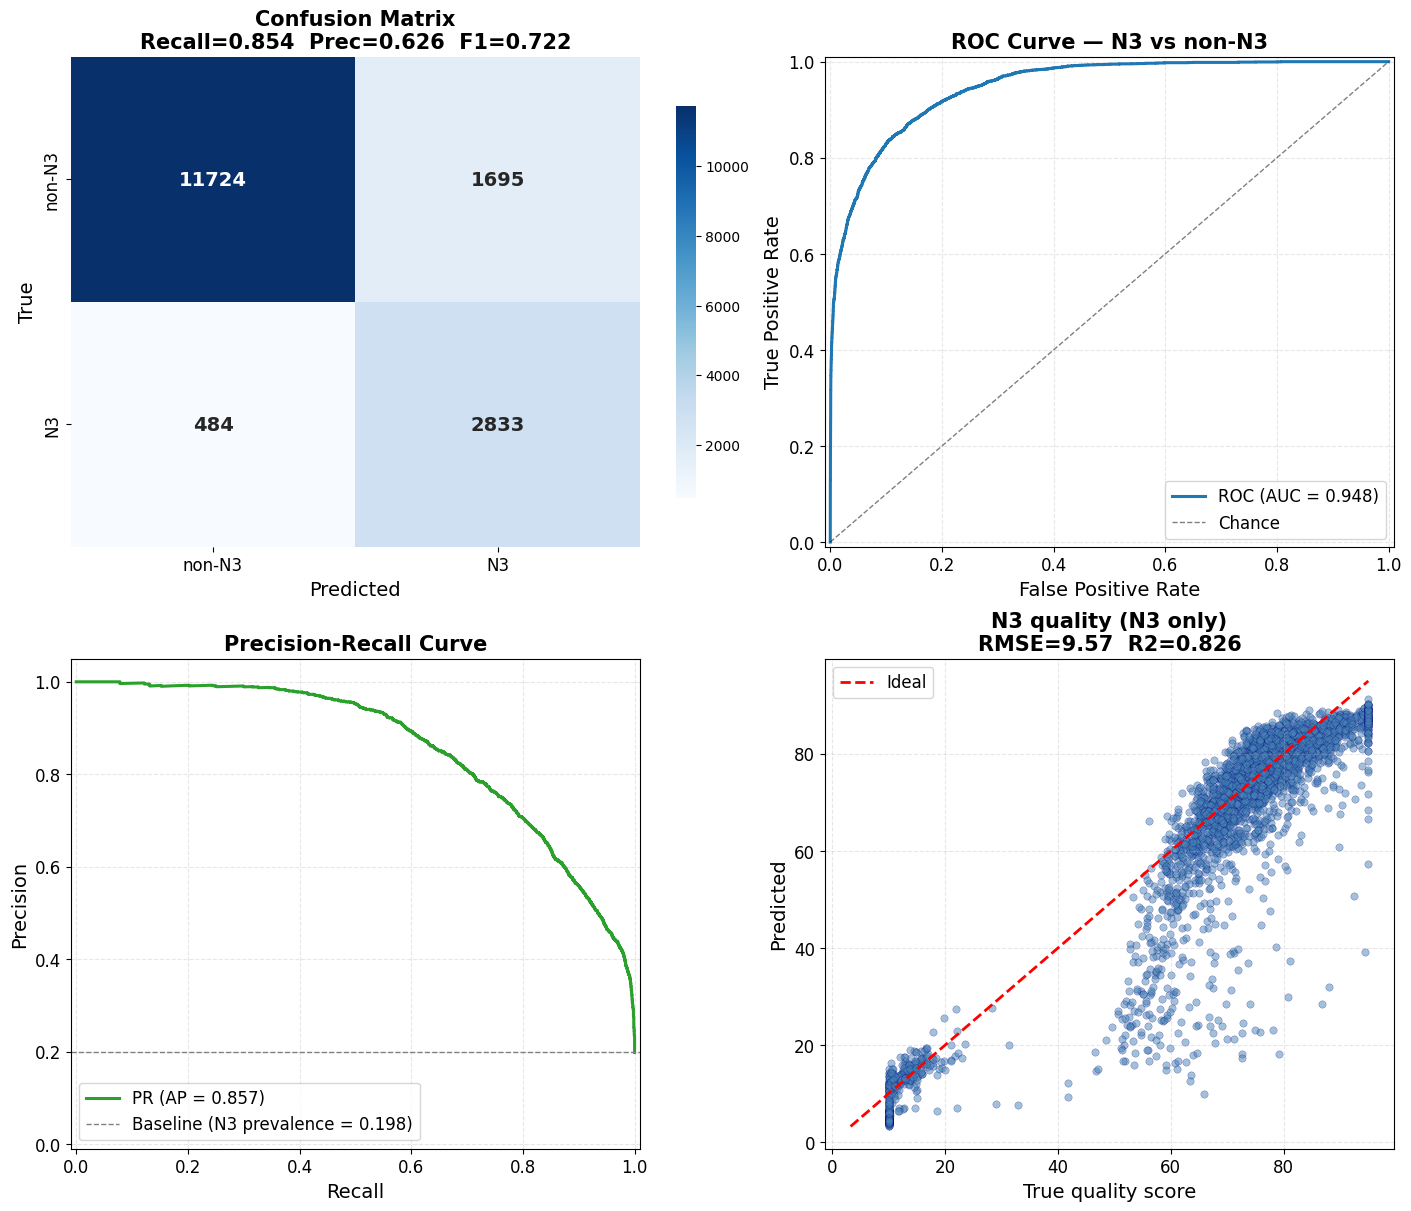

In [25]:
import seaborn as sns

from sklearn.metrics import (confusion_matrix, roc_curve, precision_recall_curve,

                             recall_score, precision_score, f1_score, roc_auc_score,

                             cohen_kappa_score, matthews_corrcoef, average_precision_score)



model.eval()

yt_n3, yp_n3, yp_prob = [], [], []

yt_q,  yp_q           = [], []

with torch.no_grad():

    for raw_eeg, det_f, qual_f, s_lab, q_lab in val_loader:

        raw_eeg = raw_eeg.to(DEVICE)

        det_f   = det_f.to(DEVICE)

        qual_f  = qual_f.to(DEVICE)

        n3_logit, q_pred = model(raw_eeg, det_f, qual_f)

        prob    = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()

        pred    = (prob > 0.5).astype(int)

        true_n3 = (s_lab.numpy() == 3).astype(int)

        yp_prob.extend(prob); yp_n3.extend(pred); yt_n3.extend(true_n3)

        mask = (true_n3 == 1)

        if mask.any():

            yt_q.extend(q_lab.numpy().flatten()[mask]*100)

            # V5: clip predictions to [0.02, 0.98] before *100 (Fix 7)

            q_pred_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)

            yp_q.extend(q_pred_clipped[mask]*100)



yt_n3 = np.array(yt_n3); yp_n3 = np.array(yp_n3)

yp_prob = np.array(yp_prob)

yt_q = np.array(yt_q); yp_q = np.array(yp_q)



rec     = recall_score(yt_n3, yp_n3, zero_division=0)

prec    = precision_score(yt_n3, yp_n3, zero_division=0)

f1      = f1_score(yt_n3, yp_n3, zero_division=0)

auc_val = roc_auc_score(yt_n3, yp_prob) if len(np.unique(yt_n3))>1 else 0

kappa   = cohen_kappa_score(yt_n3, yp_n3)

mcc     = matthews_corrcoef(yt_n3, yp_n3)

ap      = average_precision_score(yt_n3, yp_prob) if len(np.unique(yt_n3))>1 else 0

rmse_q  = float(np.sqrt(np.mean((yt_q-yp_q)**2))) if len(yt_q)>0 else 0

denom   = np.sum((yt_q-yt_q.mean())**2) if len(yt_q)>0 else 1

r2_q    = float(1-np.sum((yt_q-yp_q)**2)/denom) if len(yt_q)>0 else 0



print('='*60)

print(f'  N3 Recall        : {rec:.4f}   (RQ1 + RQ3 primary)')

print(f'  N3 Precision     : {prec:.4f}')

print(f'  N3 F1            : {f1:.4f}   (ablation anchor)')

print(f'  ROC-AUC          : {auc_val:.4f}   (RQ2 feature benefit)')

print(f'  PR-AUC (AP)      : {ap:.4f}   (imbalanced-data metric)')

print(f'  Cohen\'s Kappa    : {kappa:.4f}   (chance-corrected)')

print(f'  MCC              : {mcc:.4f}   (Matthews correlation)')

print(f'  Quality RMSE     : {rmse_q:.2f}  (N3 epochs only)')

print(f'  Quality R2       : {r2_q:.4f}')

if len(yt_q) > 0:

    stab = compute_prediction_stability_metrics(yt_q, yp_q)

    print(f'  --- V5 Prediction Stability ---')

    print(f'  pred_std       : {stab["pred_std"]:.2f}   (lower = more stable)')

    print(f'  outlier_rate   : {stab["outlier_rate"]*100:.1f}%  (pred outside true p5-p95)')

    print(f'  extreme_rate   : {stab["extreme_rate"]*100:.1f}%  (pred < 5 or > 95)')

    print(f'  iqr_ratio      : {stab["iqr_ratio"]:.2f}   (1.0 = ideal)')

print('='*60)



# 4-panel: Confusion Matrix | ROC | PR | Quality scatter

fig, axes = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)



# Confusion Matrix

cm = confusion_matrix(yt_n3, yp_n3)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 0],

            xticklabels=['non-N3','N3'], yticklabels=['non-N3','N3'],

            annot_kws={"fontsize": 14, "fontweight": "bold"},

            cbar_kws={"shrink": 0.8})

axes[0, 0].set_title(f'Confusion Matrix\nRecall={rec:.3f}  Prec={prec:.3f}  F1={f1:.3f}',

                     fontsize=15, fontweight='bold')

axes[0, 0].set_xlabel('Predicted', fontsize=14)

axes[0, 0].set_ylabel('True', fontsize=14)

axes[0, 0].tick_params(axis="both", labelsize=12)



# ROC Curve

fpr, tpr, _ = roc_curve(yt_n3, yp_prob)

axes[0, 1].plot(fpr, tpr, color='#1f77b4', lw=2.2,

                label=f'ROC (AUC = {auc_val:.3f})')

axes[0, 1].plot([0,1],[0,1],'k--',lw=1, alpha=0.5, label='Chance')

axes[0, 1].set_xlabel('False Positive Rate', fontsize=14)

axes[0, 1].set_ylabel('True Positive Rate', fontsize=14)

axes[0, 1].set_title('ROC Curve — N3 vs non-N3', fontsize=15, fontweight='bold')

axes[0, 1].legend(fontsize=12, loc='lower right')

axes[0, 1].grid(True, alpha=0.3, linestyle='--')

axes[0, 1].tick_params(axis="both", labelsize=12)

axes[0, 1].set_xlim(-0.01, 1.01); axes[0, 1].set_ylim(-0.01, 1.01)



# Precision-Recall Curve

prec_c, rec_c, _ = precision_recall_curve(yt_n3, yp_prob)

axes[1, 0].plot(rec_c, prec_c, color='#2ca02c', lw=2.2,

                label=f'PR (AP = {ap:.3f})')

n3_baseline = (yt_n3 == 1).mean()

axes[1, 0].axhline(n3_baseline, color='gray', ls='--', lw=1,

                   label=f'Baseline (N3 prevalence = {n3_baseline:.3f})')

axes[1, 0].set_xlabel('Recall', fontsize=14)

axes[1, 0].set_ylabel('Precision', fontsize=14)

axes[1, 0].set_title('Precision-Recall Curve', fontsize=15, fontweight='bold')

axes[1, 0].legend(fontsize=12, loc='lower left')

axes[1, 0].grid(True, alpha=0.3, linestyle='--')

axes[1, 0].tick_params(axis="both", labelsize=12)

axes[1, 0].set_xlim(-0.01, 1.01); axes[1, 0].set_ylim(-0.01, 1.05)



# Quality scatter

if len(yt_q) > 0:

    axes[1, 1].scatter(yt_q, yp_q, alpha=0.5, s=28, color='steelblue',

                       edgecolors='navy', linewidth=0.3)

    lo, hi = min(yt_q.min(), yp_q.min()), max(yt_q.max(), yp_q.max())

    axes[1, 1].plot([lo, hi], [lo, hi], 'r--', lw=2, label='Ideal')

    axes[1, 1].set_title(f'N3 quality (N3 only)\nRMSE={rmse_q:.2f}  R2={r2_q:.3f}',

                         fontsize=15, fontweight='bold')

    axes[1, 1].set_xlabel('True quality score', fontsize=14)

    axes[1, 1].set_ylabel('Predicted', fontsize=14)

    axes[1, 1].legend(fontsize=12, loc='upper left')

    axes[1, 1].grid(True, alpha=0.3, linestyle='--')

    axes[1, 1].tick_params(axis="both", labelsize=12)



save_pub_fig(fig, "evaluation_metrics_4panel.png")

plt.show()


### Calibration Curve (Reliability Diagram)

This section evaluates whether the model's predicted probabilities are well-calibrated, a property of direct clinical relevance: a predicted P(N3) of 0.8 should correspond to approximately 80% of such epochs being true N3 in practice.


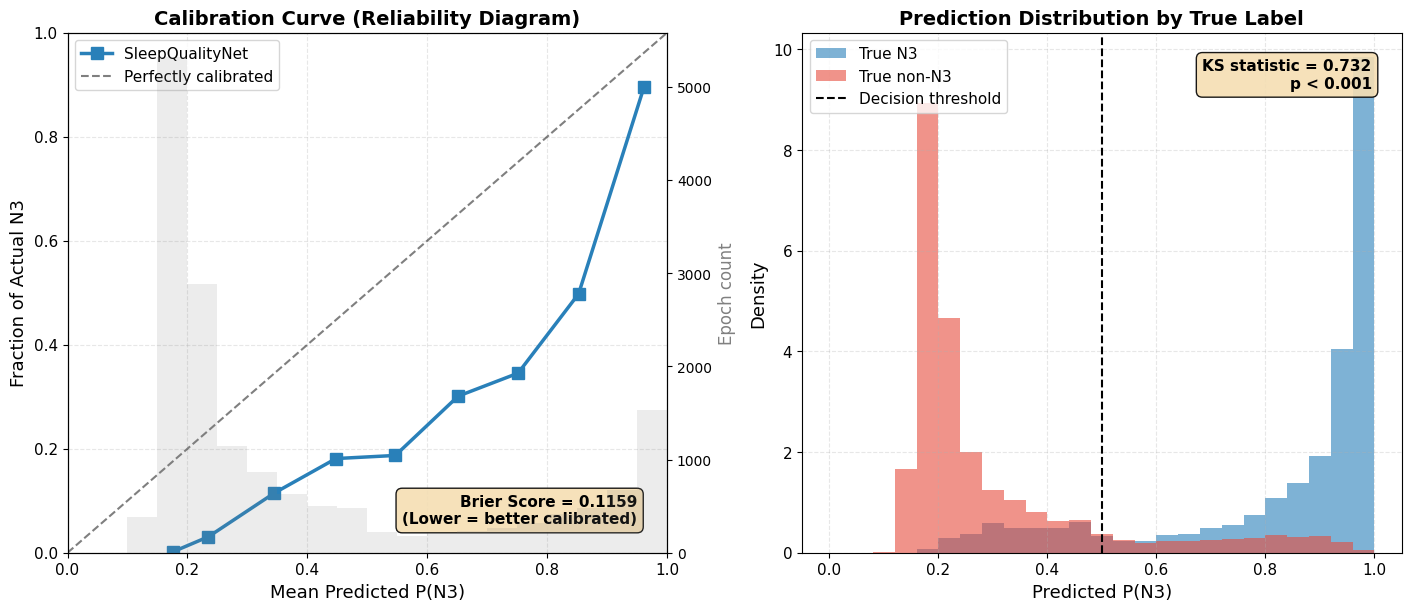

  Brier Score: 0.1159
  KS Statistic: 0.7324 (p=0.00e+00)
  [saved] outputs/calibration_curve.png


In [26]:
# ═══════════════════════════════════════════════════════════════════════
# CALIBRATION CURVE — Clinical Trust (JBHI XAI Requirement)
# ═══════════════════════════════════════════════════════════════════════
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np

# Collect all val predictions
model.eval()
all_probs_cal, all_true_cal = [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
        n3_logit, _ = model(xb, dfb, qfb)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        true = (sb.numpy() == 3).astype(int)
        all_probs_cal.extend(prob)
        all_true_cal.extend(true)

all_probs_cal = np.array(all_probs_cal)
all_true_cal  = np.array(all_true_cal)

if len(np.unique(all_true_cal)) > 1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
    
    # --- Calibration Curve ---
    n_bins = 10
    fraction_positives, mean_predicted = calibration_curve(
        all_true_cal, all_probs_cal, n_bins=n_bins, strategy='uniform')
    
    axes[0].plot(mean_predicted, fraction_positives, 's-', color='#2980b9',
                 lw=2.5, ms=8, label='SleepQualityNet', zorder=5)
    axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Perfectly calibrated')
    
    # Histogram of predictions
    ax_hist = axes[0].twinx()
    ax_hist.hist(all_probs_cal, bins=20, range=(0, 1), alpha=0.15, color='gray')
    ax_hist.set_ylabel('Epoch count', fontsize=12, color='gray')
    
    axes[0].set_xlabel('Mean Predicted P(N3)', fontsize=13)
    axes[0].set_ylabel('Fraction of Actual N3', fontsize=13)
    axes[0].set_title('Calibration Curve (Reliability Diagram)',
                        fontsize=14, fontweight='bold')
    axes[0].legend(fontsize=11, loc='upper left')
    axes[0].grid(True, alpha=0.3, linestyle='--')
    axes[0].tick_params(labelsize=11)
    axes[0].set_xlim(0, 1); axes[0].set_ylim(0, 1)
    
    # --- Brier Score ---
    brier = float(np.mean((all_probs_cal - all_true_cal) ** 2))
    axes[0].text(0.95, 0.05, f'Brier Score = {brier:.4f}\n(Lower = better calibrated)',
                 transform=axes[0].transAxes, ha='right', va='bottom',
                 fontsize=11, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='wheat', alpha=0.9))
    
    # --- Predicted Probability Distribution ---
    n3_mask_cal  = all_true_cal == 1
    non_n3_cal  = all_true_cal == 0
    axes[1].hist(all_probs_cal[n3_mask_cal], bins=25, range=(0,1), alpha=0.6,
                 color='#2980b9', label='True N3', density=True)
    axes[1].hist(all_probs_cal[non_n3_cal], bins=25, range=(0,1), alpha=0.6,
                 color='#e74c3c', label='True non-N3', density=True)
    axes[1].axvline(0.5, color='black', ls='--', lw=1.5, label='Decision threshold')
    axes[1].set_xlabel('Predicted P(N3)', fontsize=13)
    axes[1].set_ylabel('Density', fontsize=13)
    axes[1].set_title('Prediction Distribution by True Label',
                         fontsize=14, fontweight='bold')
    axes[1].legend(fontsize=11)
    axes[1].grid(True, alpha=0.3, linestyle='--')
    axes[1].tick_params(labelsize=11)
    
    # Separation metric
    from scipy.stats import ks_2samp
    ks_stat, ks_p = ks_2samp(all_probs_cal[n3_mask_cal], all_probs_cal[non_n3_cal])
    axes[1].text(0.95, 0.95, f'KS statistic = {ks_stat:.3f}\np < 0.001' if ks_p < 0.001 else f'KS = {ks_stat:.3f}\np = {ks_p:.4f}',
                 transform=axes[1].transAxes, ha='right', va='top',
                 fontsize=11, fontweight='bold',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='wheat', alpha=0.9))
    
    save_pub_fig(fig, 'calibration_curve.png')
    plt.show()
    print(f'  Brier Score: {brier:.4f}')
    print(f'  KS Statistic: {ks_stat:.4f} (p={ks_p:.2e})')
    print('  [saved] outputs/calibration_curve.png')
else:
    print('  Only one class in val set — cannot compute calibration curve.')

## 5-Fold Cross-Validation

This section iterates over all five `StratifiedGroupKFold` folds to obtain mean and standard-deviation estimates of model performance across independent subject splits.


In [27]:
# ═══════════════════════════════════════════════════════════════════╗

# ║  FIX (cross-validation): 5-Fold Cross-Validation                    ║

# ═══════════════════════════════════════════════════════════════════╝

import time, copy, warnings

warnings.filterwarnings('ignore')



set_seed(CONFIG['seed'])

cv_metrics = []



for fold_num, (tr_idx, va_idx) in enumerate(folds):

    print(f"\n{'='*60}")

    print(f"  FOLD {fold_num+1}/5  - train={len(tr_idx):,}  val={len(va_idx):,}")

    print(f"{'='*60}")



    det_tr_log, qual_tr_log = log_transform_features(det_features[tr_idx], qual_features[tr_idx])

    det_va_log, qual_va_log = log_transform_features(det_features[va_idx], qual_features[va_idx])



    dtr_c, qtr_c, cb = clip_features_outliers(det_tr_log, qual_tr_log, lower_pct=2, upper_pct=98)

    dva_c, qva_c = apply_clip_bounds(det_va_log, qual_va_log, cb)



    w = Winsorizer(k=5.0)

    w.fit(dtr_c, qtr_c)

    dtr_c, qtr_c = w.transform(dtr_c, qtr_c)

    dva_c, qva_c = w.transform(dva_c, qva_c)



    norm_cv = FeatureNormalizer()

    norm_cv.fit(dtr_c, qtr_c)

    dtr_n = norm_cv.transform_det(dtr_c)

    dva_n = norm_cv.transform_det(dva_c)

    qtr_n = norm_cv.transform_qual(qtr_c)

    qva_n = norm_cv.transform_qual(qva_c)



    full_det_c = np.concatenate([dtr_c, dva_c], axis=0)

    full_stg   = np.concatenate([stage_labels[tr_idx], stage_labels[va_idx]], axis=0)

    q_bounds   = fit_quality_label_bounds(dtr_c, stage_labels[tr_idx], smooth_non_n3=True)

    q_labels   = apply_quality_label_bounds(full_det_c, full_stg, q_bounds)

    qtr_lab_cv = q_labels[:len(tr_idx)]

    qva_lab_cv = q_labels[len(tr_idx):]



    tr_ds = SleepDataLoader.numpy_to_tensor_dataset(

        raw_eegs[tr_idx], dtr_n, qtr_n, stage_labels[tr_idx], qtr_lab_cv)

    va_ds = SleepDataLoader.numpy_to_tensor_dataset(

        raw_eegs[va_idx], dva_n, qva_n, stage_labels[va_idx], qva_lab_cv)

    tr_dl = torch.utils.data.DataLoader(tr_ds, batch_size=CONFIG['batch_size'],

                                         shuffle=True, num_workers=0, drop_last=False)

    va_dl = torch.utils.data.DataLoader(va_ds, batch_size=CONFIG['batch_size'],

                                         shuffle=False, num_workers=0)



    set_seed(CONFIG['seed'])

    m_cv = SleepQualityNet(input_length=SR*30, use_det_feat=True, use_qual_feat=True)

    n3_tr_f = int((stage_labels[tr_idx] == 3).sum())

    n3_va_f = len(tr_idx) - n3_tr_f

    pw = n3_va_f / max(n3_tr_f, 1)

    aug = EEGAugmentor(sampling_rate=CONFIG['sampling_rate'])

    t_cv = SleepQualityTrainer(
        m_cv, device=DEVICE, checkpoint_path=f'cv_fold{fold_num}.pth',
        n3_pos_weight=pw, augmentor=aug,
        lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'],
        scheduler=CONFIG['scheduler'], cosine_T_max=CONFIG['cosine_T_max'],
        cosine_eta_min=CONFIG['cosine_eta_min'], grad_clip=CONFIG['grad_clip'],
        warmup_epochs=CONFIG['warmup_epochs'],    # FIX: sync v7
        ema_decay=CONFIG['ema_decay'],            # FIX: enable EMA
        accum_steps=CONFIG['accum_steps'])        # FIX: grad accum

    t0 = time.time()

    t_cv.train(tr_dl, va_dl, epochs=CONFIG['epochs'], verbose=False)
    # FIX: Restore best checkpoint for this fold
    import os
    ckpt_path = f'cv_fold{fold_num}.pth'
    if os.path.exists(ckpt_path):
        m_cv.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))

    elapsed = time.time() - t0



    m_cv.eval()

    yt_cv, yp_cv, pr_cv = [], [], []

    qt_cv, qp_cv = [], []

    with torch.no_grad():

        for xb, dfb, qfb, sb, qb in va_dl:

            xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)

            logit, qp = m_cv(xb, dfb, qfb)

            prob = torch.sigmoid(logit).squeeze(1).cpu().numpy()

            pred = (prob > 0.5).astype(int)

            true = (sb.numpy() == 3).astype(int)

            pr_cv.extend(prob); yp_cv.extend(pred); yt_cv.extend(true)

            msk = (true == 1)

            if msk.any():

                qt_cv.extend(qb.numpy().flatten()[msk]*100)

                qp_c = clip_quality_predictions(qp.cpu().numpy().flatten(), 0.02, 0.98)

                qp_cv.extend(qp_c[msk]*100)



    yt_cv = np.array(yt_cv); yp_cv = np.array(yp_cv); pr_cv = np.array(pr_cv)

    qt_cv = np.array(qt_cv); qp_cv = np.array(qp_cv)



    from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

    rec_cv  = recall_score(yt_cv, yp_cv, zero_division=0)

    prec_cv = precision_score(yt_cv, yp_cv, zero_division=0)

    f1_cv   = f1_score(yt_cv, yp_cv, zero_division=0)

    auc_cv  = roc_auc_score(yt_cv, pr_cv) if len(np.unique(yt_cv)) > 1 else 0.0

    rmse_cv = float(np.sqrt(np.mean((qt_cv - qp_cv)**2))) if len(qt_cv) > 0 else 0

    denom_cv = np.sum((qt_cv - qt_cv.mean())**2) if len(qt_cv) > 0 else 1

    r2_cv    = float(1 - np.sum((qt_cv - qp_cv)**2) / denom_cv) if len(qt_cv) > 0 else 0



    fold_dict = {

        'fold': fold_num+1,

        'n3_recall': round(float(rec_cv), 4),

        'n3_precision': round(float(prec_cv), 4),

        'n3_f1': round(float(f1_cv), 4),

        'auc': round(float(auc_cv), 4),

        'quality_rmse': round(float(rmse_cv), 2),

        'quality_r2': round(float(r2_cv), 4),

        'train_time_s': round(elapsed, 1),

    }

    cv_metrics.append(fold_dict)

    print(f"  F1={f1_cv:.4f}  AUC={auc_cv:.4f}  R2={r2_cv:.4f}  RMSE={rmse_cv:.2f}  time={elapsed:.0f}s")



# Summary table

print(f"\n{'='*72}")

print('  5-FOLD CROSS-VALIDATION SUMMARY')

print(f"{'='*72}")

import pandas as pd

cv_df = pd.DataFrame(cv_metrics)

metric_cols = ['n3_f1', 'auc', 'n3_precision', 'n3_recall', 'quality_rmse', 'quality_r2']

summary_rows = []

for col in metric_cols:

    vals = cv_df[col]

    summary_rows.append({

        'Metric': col.replace('n3_', 'N3 ').replace('quality_', 'Quality ').title(),

        'Mean': f"{vals.mean():.4f}",

        'Std': f"{vals.std():.4f}",

        'Min': f"{vals.min():.4f}",

        'Max': f"{vals.max():.4f}",

    })

summary_df = pd.DataFrame(summary_rows)

print(summary_df.to_string(index=False))

print(f"{'='*72}")

cv_summary_for_table = {col: (cv_df[col].mean(), cv_df[col].std()) for col in metric_cols}



  FOLD 1/5  - train=67,040  val=16,736
  train=1.0827  train(clean)=1.0829  val=1.1217  N3-F1=0.331  AUC=0.894  Q-R2=-0.592
  train=0.9882  train(clean)=0.9875  val=1.0386  N3-F1=0.331  AUC=0.909  Q-R2=-0.219
  train=0.9132  train(clean)=0.9137  val=0.9624  N3-F1=0.506  AUC=0.911  Q-R2=0.122
  train=0.8565  train(clean)=0.8566  val=0.8894  N3-F1=0.619  AUC=0.919  Q-R2=0.474
  train=0.8201  train(clean)=0.8169  val=0.8478  N3-F1=0.601  AUC=0.926  Q-R2=0.772
  train=0.7995  train(clean)=0.7982  val=0.7971  N3-F1=0.668  AUC=0.933  Q-R2=0.823
  train=0.7860  train(clean)=0.7838  val=0.7740  N3-F1=0.717  AUC=0.939  Q-R2=0.850
  train=0.7750  train(clean)=0.7741  val=0.7943  N3-F1=0.744  AUC=0.939  Q-R2=0.759
  train=0.7733  train(clean)=0.7728  val=0.7656  N3-F1=0.730  AUC=0.942  Q-R2=0.847
  train=0.7660  train(clean)=0.7648  val=0.7607  N3-F1=0.723  AUC=0.943  Q-R2=0.860
  train=0.7636  train(clean)=0.7624  val=0.7609  N3-F1=0.727  AUC=0.943  Q-R2=0.843
  train=0.7611  train(clean)=0.758

## External Validation on ISRUC-III (Sub-Group III)

The model above was trained and cross-validated entirely on ISRUC-Sleep Sub-Group I (100 subjects). To assess generalization to unseen recording sessions and hardware, this section evaluates the trained model, without further tuning, on a held-out external cohort, ISRUC-Sleep Sub-Group III, which is not used at any point during training or the 5-fold cross-validation reported above.

The `ISRUCIIIAdapter`, introduced earlier in the generic EEG dataset loading layer, is reused without modification, since Sub-Group I and Sub-Group III share the same `.rec` recording format and `_1.txt` annotation convention; only the data directory and subject count differ between the two cohorts.


In [28]:
# ═══════════════════════════════════════════════════════════════════════
#  EXTERNAL VALIDATION — ISRUC-Sleep Sub-Group III (held-out cohort)
#  Model is frozen here; nothing in this cell is used for training/tuning.
# ═══════════════════════════════════════════════════════════════════════

# ── 1) SET THIS PATH ────────────────────────────────────────────────────
# Point this at the folder containing the Sub-Group III recordings.
# Two folder layouts are supported automatically:
#   (a) nested : EXTERNAL_DATA_DIR/<subject_id>/<name>.rec + <name>_1.txt
#   (b) flat   : EXTERNAL_DATA_DIR/<name>.rec + <name>_1.txt directly
import json as _json  # not guaranteed to be imported yet at this point in the notebook
from sklearn.metrics import r2_score  # not imported anywhere earlier in the notebook

EXTERNAL_DATA_DIR = r"D:\\AI_Project\\ISRUC-Sleep-III"   # <-- CHANGE THIS
EXTERNAL_N_SUBJECTS = 10                                    # how many subject IDs to scan for

# Create and fit normalizer BEFORE using it
normalizer = FeatureNormalizer()
normalizer.fit(det_tr_clip, qual_tr_clip)

assert os.path.isdir(EXTERNAL_DATA_DIR), (
    f"EXTERNAL_DATA_DIR does not exist: {EXTERNAL_DATA_DIR}\n"
    f"Set it to the folder that directly contains the Sub-Group III .rec files "
    f"(or subject-numbered subfolders containing them)."
)

# ── 2) Load Sub-Group III with the SAME adapter used for Sub-Group I ────
ext_adapter = ISRUCIIIAdapter(channel=CONFIG['eeg_channel'], max_subjects=EXTERNAL_N_SUBJECTS)
ext_bundle = ext_adapter.load(
    EXTERNAL_DATA_DIR, EXTERNAL_N_SUBJECTS, pre,
    fallback_to_synthetic=False,   # fail loudly instead of silently validating on synthetic data
    seed=CONFIG['seed'],
)

ext_raw_eegs      = ext_bundle.raw_eegs
ext_det_features  = ext_bundle.det_features
ext_qual_features = ext_bundle.qual_features
ext_stage_labels  = ext_bundle.stage_labels
ext_night_ids     = ext_bundle.night_ids

print(f"\n── External (Sub-Group III) dataset loaded ──────────────────")
print(f"  Total epochs : {ext_raw_eegs.shape[0]:,}")
print(f"  Subjects     : {len(np.unique(ext_night_ids))}")
unique, counts = np.unique(ext_stage_labels, return_counts=True)
for u, c in zip(unique, counts):
    print(f"    {STAGE_MAP[u]:>5}: {c:5d} ({c/len(ext_stage_labels)*100:.1f}%)")

# ── 3) Apply the pipeline FIT ON TRAINING DATA (no re-fitting here) ─────
# clip_bounds_v3, winsorizer, norm_cv (or normalizer used for the final model)
# must already exist from the training cells above — we transform, not fit,
# to avoid leaking external-set statistics into preprocessing.
ext_det_log, ext_qual_log = log_transform_features(ext_det_features, ext_qual_features)
ext_det_clip, ext_qual_clip = apply_clip_bounds(ext_det_log, ext_qual_log, clip_bounds_v3)
ext_det_clip, ext_qual_clip = winsorizer.transform(ext_det_clip, ext_qual_clip)

ext_det_n  = normalizer.transform_det(ext_det_clip)
ext_qual_n = normalizer.transform_qual(ext_qual_clip)

ext_q_labels = apply_quality_label_bounds(ext_det_clip, ext_stage_labels, quality_bounds_v3)

# ── 4) Build a DataLoader and run the frozen model ───────────────────────
ext_ds = SleepDataLoader.numpy_to_tensor_dataset(
    ext_raw_eegs, ext_det_n, ext_qual_n, ext_stage_labels, ext_q_labels)
ext_loader = torch.utils.data.DataLoader(ext_ds, batch_size=CONFIG['batch_size'], shuffle=False)

model.eval()
ext_evaluator = DatasetIndependentEvaluator(model, DEVICE)
ext_quality_df = ext_evaluator.collect_quality_frame(
    ext_loader, np.arange(len(ext_raw_eegs)), ext_night_ids, ext_det_clip)

# ── 5) N3 detection metrics on the external cohort ───────────────────────
yt_ext, yp_ext, prob_ext = [], [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in ext_loader:
        xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
        n3_logit, _ = model(xb, dfb, qfb)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        yp_ext.extend((prob > 0.5).astype(int))
        prob_ext.extend(prob)
        yt_ext.extend((sb.numpy() == 3).astype(int))

yt_ext, yp_ext, prob_ext = np.array(yt_ext), np.array(yp_ext), np.array(prob_ext)

print(f"\n── External validation results (ISRUC Sub-Group III) ─────────")
print(f"  N3 F1        : {f1_score(yt_ext, yp_ext):.4f}")
print(f"  N3 Precision : {precision_score(yt_ext, yp_ext):.4f}")
print(f"  N3 Recall    : {recall_score(yt_ext, yp_ext):.4f}")
print(f"  AUC          : {roc_auc_score(yt_ext, prob_ext):.4f}")

n3_ext_df = ext_quality_df[ext_quality_df['stage'] == 3]
if len(n3_ext_df):
    print(f"  Quality RMSE : {np.sqrt(np.mean((n3_ext_df['pred_quality']-n3_ext_df['true_quality'])**2)):.4f}")
    print(f"  Quality R2   : {r2_score(n3_ext_df['true_quality'], n3_ext_df['pred_quality']):.4f}")

os.makedirs('outputs', exist_ok=True)
ext_results = {
    'dataset': 'ISRUC-III Sub-Group III (external validation, held-out cohort)',
    'n_subjects': int(len(np.unique(ext_night_ids))),
    'n3_f1': round(float(f1_score(yt_ext, yp_ext)), 4),
    'n3_precision': round(float(precision_score(yt_ext, yp_ext)), 4),
    'n3_recall': round(float(recall_score(yt_ext, yp_ext)), 4),
    'auc': round(float(roc_auc_score(yt_ext, prob_ext)), 4),
}
with open('outputs/external_validation_results.json', 'w') as f:
    _json.dump(ext_results, f, indent=2)
print("\nSaved: outputs/external_validation_results.json")


Found 10 .rec files for ISRUC-III. Loading...


PREPROCESSING QUALITY REPORT
Total epochs attempted:        796
Artifact epochs removed:       5
Low-quality epochs removed:    425
Heavily clipped epochs removed: 2
----------------------------------------------------------------------
Final epochs retained:         364
Retention rate:                45.7%

  [Subject 10] ✓ 364 epochs

PREPROCESSING QUALITY REPORT
Total epochs attempted:        954
Artifact epochs removed:       1
Low-quality epochs removed:    132
Heavily clipped epochs removed: 3
----------------------------------------------------------------------
Final epochs retained:         818
Retention rate:                85.7%

  [Subject 1] ✓ 818 epochs

PREPROCESSING QUALITY REPORT
Total epochs attempted:        941
Artifact epochs removed:       0
Low-quality epochs removed:    251
Heavily clipped epochs removed: 9
----------------------------------------------------------------------
Final epochs retained:         681
Ret

### External Validation: ROC and Precision-Recall Curves

This section plots the N3-detection ROC and precision-recall curves for the frozen model evaluated on the external Sub-Group III cohort.


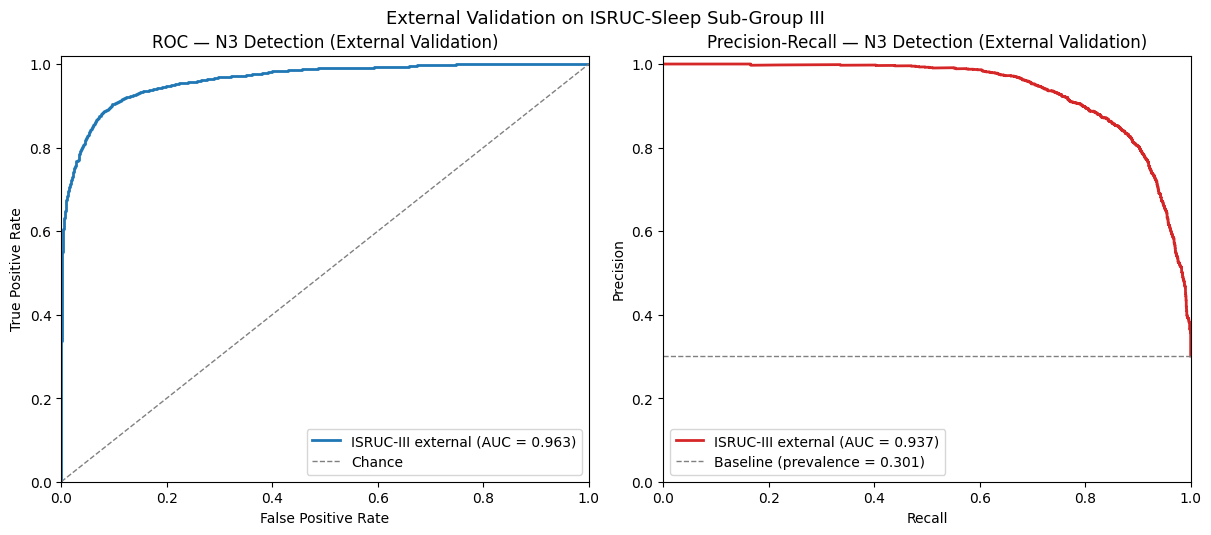

ROC AUC : 0.9631
PR  AUC : 0.9371  (baseline/prevalence = 0.3009)
Updated: outputs/external_validation_results.json


In [29]:
# ═══════════════════════════════════════════════════════════════════════
#  EXTERNAL VALIDATION — ROC + Precision-Recall curves (ISRUC-III)
# ═══════════════════════════════════════════════════════════════════════
import json as _json  # not guaranteed to be imported yet at this point in the notebook
from sklearn.metrics import roc_curve, precision_recall_curve, auc

assert 'yt_ext' in dir() and 'prob_ext' in dir(), (
    "Run the External Validation cell above first (needs yt_ext, prob_ext)."
)

fpr_ext, tpr_ext, _   = roc_curve(yt_ext, prob_ext)
roc_auc_ext           = auc(fpr_ext, tpr_ext)
prec_ext, rec_ext, _  = precision_recall_curve(yt_ext, prob_ext)
pr_auc_ext            = auc(rec_ext, prec_ext)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

# ── ROC curve ─────────────────────────────────────────────────────────
ax = axes[0]
ax.plot(fpr_ext, tpr_ext, color='#1f77b4', lw=2,
        label=f'ISRUC-III external (AUC = {roc_auc_ext:.3f})')
ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Chance')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC — N3 Detection (External Validation)')
ax.legend(loc='lower right')
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])

# ── Precision-Recall curve ───────────────────────────────────────────
ax = axes[1]
n3_prevalence = yt_ext.mean()
ax.plot(rec_ext, prec_ext, color='#d62728', lw=2,
        label=f'ISRUC-III external (AUC = {pr_auc_ext:.3f})')
ax.axhline(n3_prevalence, color='gray', lw=1, linestyle='--',
           label=f'Baseline (prevalence = {n3_prevalence:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall — N3 Detection (External Validation)')
ax.legend(loc='lower left')
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])

plt.suptitle('External Validation on ISRUC-Sleep Sub-Group III', fontsize=13, y=1.04)

os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/external_validation_roc_pr.png', dpi=200, bbox_inches='tight')
plt.show()

print(f"ROC AUC : {roc_auc_ext:.4f}")
print(f"PR  AUC : {pr_auc_ext:.4f}  (baseline/prevalence = {n3_prevalence:.4f})")

# fold this into the saved results JSON if it exists
_results_path = 'outputs/external_validation_results.json'
if os.path.exists(_results_path):
    with open(_results_path) as f:
        _res = _json.load(f)
    _res['roc_auc'] = round(float(roc_auc_ext), 4)
    _res['pr_auc'] = round(float(pr_auc_ext), 4)
    with open(_results_path, 'w') as f:
        _json.dump(_res, f, indent=2)
    print(f"Updated: {_results_path}")


### Cross-Validation Results Visualization

This section displays per-fold metrics with error bars, illustrating model stability across different subject splits. The resulting mean ± standard deviation values constitute the primary performance metrics reported in the paper.


<class 'dict'>
{'n3_f1': (np.float64(0.7338600000000001), np.float64(0.02199552227158971)), 'auc': (np.float64(0.94518), np.float64(0.011245310133562333)), 'n3_precision': (np.float64(0.6363), np.float64(0.01459006511294587)), 'n3_recall': (np.float64(0.8677400000000001), np.float64(0.04614502139993004)), 'quality_rmse': (np.float64(9.532), np.float64(0.7330893533533271)), 'quality_r2': (np.float64(0.8266), np.float64(0.05669492922651903))}


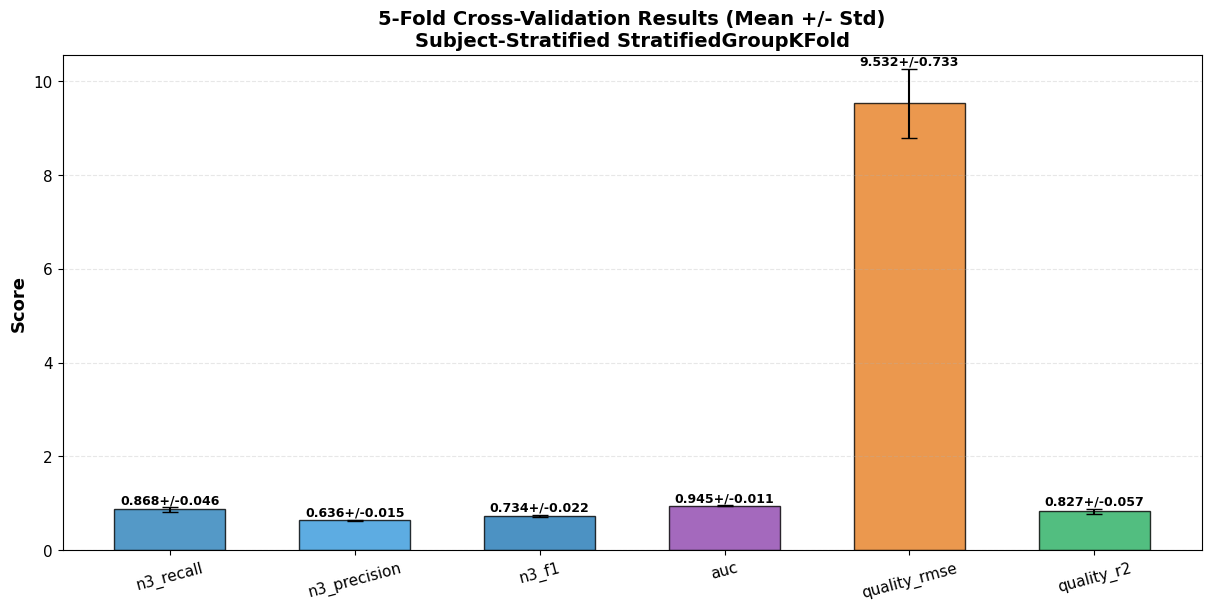

  [saved] outputs/cv_results_bar_chart.png


In [30]:
# ═══════════════════════════════════════════════════════════════════════
# CROSS-VALIDATION RESULTS VISUALIZATION (with error bars)
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np

if 'cv_summary_for_table' in dir():
    metrics_to_plot = [
    'n3_recall',
    'n3_precision',
    'n3_f1',
    'auc',
    'quality_rmse',
    'quality_r2'
    ]
    
    # Extract mean and std from cv_summary_for_table
    means, stds = [], []

    print(type(cv_summary_for_table))
    print(cv_summary_for_table)  

    for m in metrics_to_plot:
        if m in cv_summary_for_table:
            mu, sd = cv_summary_for_table[m]
            means.append(mu)
            stds.append(sd)
        else:
            means.append(0)
            stds.append(0)
    
    fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)
    
    colors_cv = ['#2980b9', '#3498db', '#1f77b4', '#8e44ad', '#e67e22', '#27ae60']
    x = np.arange(len(metrics_to_plot))
    bars = ax.bar(x, means, yerr=stds, capsize=6, color=colors_cv, alpha=0.8,
                    edgecolor='black', linewidth=1.0, width=0.6,
                    error_kw={'linewidth': 1.5})
    
    for i, (bar, m, s) in enumerate(zip(bars, means, stds)):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + s + 0.01,
                f'{m:.3f}+/-{s:.3f}', ha='center', va='bottom',
                fontsize=9, fontweight='bold')
    
    ax.set_xticks(x)
    ax.set_xticklabels(metrics_to_plot, fontsize=11, rotation=15)
    ax.set_ylabel('Score', fontsize=13, fontweight='bold')
    ax.set_title('5-Fold Cross-Validation Results (Mean +/- Std)\n'
                   'Subject-Stratified StratifiedGroupKFold',
                   fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax.tick_params(labelsize=11)
    ax.set_ylim(0, max(means) + max(stds) + 0.3)
    
    save_pub_fig(fig, 'cv_results_bar_chart.png')
    plt.show()
    print('  [saved] outputs/cv_results_bar_chart.png')
else:
    print('  cv_summary_for_table not found — run the 5-Fold CV cell first.')

## Band Power Visualization

This section presents the mean power of each of the five frequency bands across sleep stages, providing insight into why the model is able to detect N3: if delta power is highest during N3, the model's reliance on this feature is physiologically well-motivated.


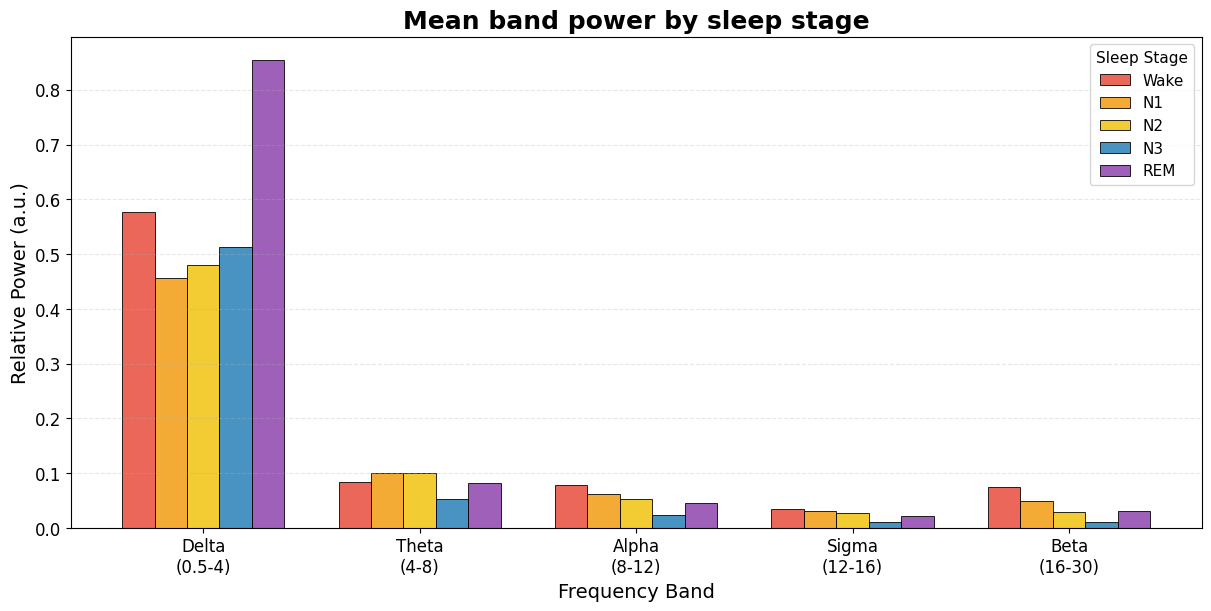

In [31]:
band_keys = ['delta','theta','alpha','sigma','beta']

band_names = ['Delta\n(0.5-4)','Theta\n(4-8)','Alpha\n(8-12)','Sigma\n(12-16)','Beta\n(16-30)']

powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])



fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

x = np.arange(len(band_names)); w = 0.15

for s in range(5):

    mask = stage_labels == s

    if mask.sum():

        ax.bar(x + w*s, powers[mask].mean(axis=0), w,

               label=STAGE_MAP[s], color=STAGE_COLORS[s], alpha=0.85,

               edgecolor='black', linewidth=0.7)

ax.set_xticks(x + w*2); ax.set_xticklabels(band_names, fontsize=12)

ax.set_title('Mean band power by sleep stage', fontsize=18, fontweight='bold')

ax.set_ylabel('Relative Power (a.u.)', fontsize=14)

ax.set_xlabel('Frequency Band', fontsize=14)

ax.legend(fontsize=11, title='Sleep Stage', title_fontsize=11)

ax.grid(True, alpha=0.3, linestyle='--', axis='y')

ax.tick_params(axis="both", labelsize=12)

save_pub_fig(fig, "mean_band_power_by_stage.png")

plt.show()


### Feature Importance Ranking

This section converts each frequency band's ability to separate sleep stages into a quantitative importance score, computed from between-stage variance, where a band with high between-stage variance better discriminates sleep stages. Delta power ranking highest among the five bands corroborates the feature-selection strategy and supports the delta-fusion design addressed in RQ2.


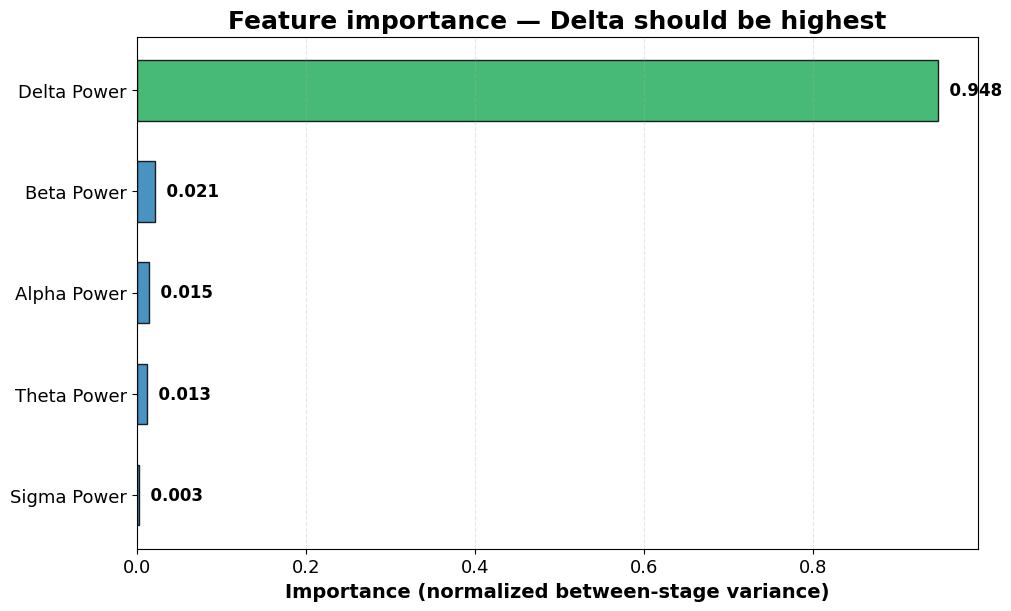

Ranking: {'Delta Power': 0.948, 'Beta Power': 0.021, 'Alpha Power': 0.015, 'Theta Power': 0.013, 'Sigma Power': 0.003}


In [32]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_disp = ['Delta Power','Theta Power','Alpha Power','Sigma Power','Beta Power']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

stage_means = np.array([powers[stage_labels == s].mean(axis=0)
                        for s in range(5) if (stage_labels == s).any()])
importance = stage_means.var(axis=0); importance = importance / importance.sum()

order = np.argsort(importance)[::-1]
names = [band_disp[i] for i in order]; scores = importance[order]
colors = ['#27ae60' if n == 'Delta Power' else '#2980b9' for n in names]

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
bars = ax.barh(names, scores, color=colors, alpha=0.85, edgecolor='black',
               height=0.6)
ax.invert_yaxis()
for i, sc in enumerate(scores):
    ax.text(sc, i, f'  {sc:.3f}', va='center', fontweight='bold', fontsize=12)
ax.set_xlabel('Importance (normalized between-stage variance)',
              fontsize=14, fontweight='bold')
ax.set_title('Feature importance — Delta should be highest',
             fontsize=18, fontweight='bold')
ax.tick_params(axis="both", labelsize=13)
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
save_pub_fig(fig, "feature_importance_bands.png")
plt.show()
print("Ranking:", {n: round(float(s), 3) for n, s in zip(names, scores)})


Inference model loaded on: cuda
════════════════════════════════════════════════════════════
   N3 DEEP SLEEP QUALITY DETECTION — SINGLE EPOCH INFERENCE
════════════════════════════════════════════════════════════

  [N3 epoch (true N3)]
  True stage         : N3
  P(N3)              : 0.9794  (N3)
  Correct detection  : YES
  N3 Quality Score   : 82.5 / 100  <- HIGH quality deep sleep
  Detection features :
    delta_power    = 0.866
    SWA            = 0.891
    slow_wave_den  = 2.500
    rel_delta      = 0.774
  Quality features :
    p2p_amplitude  = 0.403
    fragmentation  = -1.005

  [Non-N3 epoch]
  True stage         : Wake
  P(N3)              : 0.4384  (non-N3)
  Correct detection  : YES
  N3 Quality Score   : 10.2 / 100  <- LOW quality deep sleep
  (Non-N3 epoch - quality score is model prediction,
   not clinically meaningful for non-N3 stages)

════════════════════════════════════════════════════════════


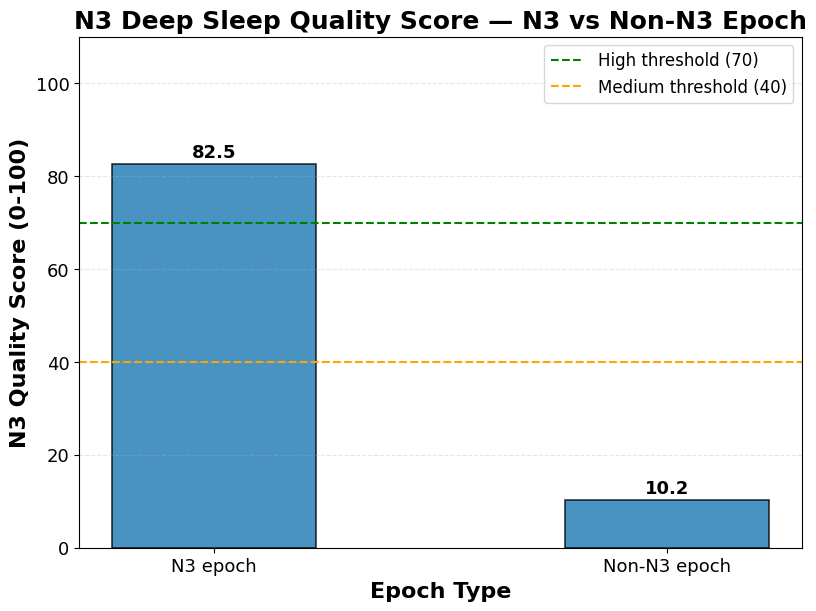

In [33]:
import os
# ══════════════════════════════════════════════════════════════════
#  STEP 12 — Single Epoch Inference
#  N3 detected হলে quality score + features দেখাবে
#  Non-N3 হলেও quality score দেখাবে (model সবসময় predict করে)
# ══════════════════════════════════════════════════════════════════

infer = SleepQualityNet(input_length=SR*30,
                        use_det_feat=True, use_qual_feat=True)
infer.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
infer = infer.to(DEVICE)
infer.eval()
print(f'Inference model loaded on: {DEVICE}')

# Find an N3 and a non-N3 epoch from val_idx (StratifiedGroupKFold val)
n3_idx     = np.where(stage_labels[val_idx] == 3)[0]
non_n3_idx = np.where(stage_labels[val_idx] != 3)[0]

print("═"*60)
print("   N3 DEEP SLEEP QUALITY DETECTION — SINGLE EPOCH INFERENCE")
print("═"*60)

for label, indices in [
    ("N3 epoch (true N3)", n3_idx),
    ("Non-N3 epoch",       non_n3_idx)
]:
    if len(indices) == 0:
        print(f"\n  [{label}] — no epochs found")
        continue

    # Use the middle epoch of val set
    i = int(val_idx[indices[len(indices)//2]])

    xe  = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1).to(DEVICE)
    dfe = torch.FloatTensor(det_features_n_v3[i:i+1]).to(DEVICE)
    qfe = torch.FloatTensor(qual_features_n_v3[i:i+1]).to(DEVICE)

    with torch.no_grad():
        n3_logit, quality = infer(xe, dfe, qfe)

    prob    = float(torch.sigmoid(n3_logit).item())
    is_n3   = prob > 0.5
    true_n3 = int(stage_labels[i]) == 3
    q_score = float(clip_quality_predictions(quality.item(), 0.02, 0.98)) * 100

    if q_score >= 70:
        q_label = "HIGH quality deep sleep"
    elif q_score >= 40:
        q_label = "MEDIUM quality deep sleep"
    else:
        q_label = "LOW quality deep sleep"

    print(f"\n  [{label}]")
    print(f"  True stage         : {STAGE_MAP[int(stage_labels[i])]}")
    print(f"  P(N3)              : {prob:.4f}  ({'N3' if is_n3 else 'non-N3'})")
    print(f"  Correct detection  : {'YES' if is_n3 == true_n3 else 'NO'}")
    print(f"  N3 Quality Score   : {q_score:.1f} / 100  <- {q_label}")

    if is_n3:
        print(f"  Detection features :")
        print(f"    delta_power    = {det_features_n_v3[i,0]:.3f}")
        print(f"    SWA            = {det_features_n_v3[i,1]:.3f}")
        print(f"    slow_wave_den  = {det_features_n_v3[i,2]:.3f}")
        print(f"    rel_delta      = {det_features_n_v3[i,3]:.3f}")
        print(f"  Quality features :")
        print(f"    p2p_amplitude  = {qual_features_n_v3[i,0]:.3f}")
        print(f"    fragmentation  = {qual_features_n_v3[i,1]:.3f}")
    else:
        print(f"  (Non-N3 epoch - quality score is model prediction,")
        print(f"   not clinically meaningful for non-N3 stages)")

print("\n" + "═"*60)

# ── Bar chart: quality score comparison — publication quality ──────────
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
scores, labels_bar, colors_bar = [], [], []

for label, indices in [("N3 epoch", n3_idx), ("Non-N3 epoch", non_n3_idx)]:
    if len(indices) == 0: continue
    i = int(val_idx[indices[len(indices)//2]])
    xe  = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1).to(DEVICE)
    dfe = torch.FloatTensor(det_features_n_v3[i:i+1]).to(DEVICE)
    qfe = torch.FloatTensor(qual_features_n_v3[i:i+1]).to(DEVICE)
    with torch.no_grad():
        _, quality = infer(xe, dfe, qfe)
    q = float(clip_quality_predictions(quality.item(), 0.02, 0.98)) * 100
    scores.append(q)
    labels_bar.append(label)
    colors_bar.append('#2980b9' if 'N3' in label else '#e74c3c')

bars = ax.bar(labels_bar, scores, color=colors_bar, alpha=0.85,
              edgecolor='black', linewidth=1.1, width=0.45)
ax.axhline(70, color='green',  ls='--', lw=1.5, label='High threshold (70)')
ax.axhline(40, color='orange', ls='--', lw=1.5, label='Medium threshold (40)')
for bar, v in zip(bars, scores):
    ax.text(bar.get_x()+bar.get_width()/2, v+1.5,
            f'{v:.1f}', ha='center', fontsize=13, fontweight='bold')
ax.set_ylim(0, 110)
ax.set_ylabel('N3 Quality Score (0-100)', fontsize=16, fontweight='bold')
ax.set_xlabel('Epoch Type', fontsize=16, fontweight='bold')
ax.set_title('N3 Deep Sleep Quality Score — N3 vs Non-N3 Epoch',
             fontsize=18, fontweight='bold')
ax.legend(fontsize=12, loc='upper right')
ax.tick_params(axis="both", labelsize=13)
ax.grid(True, alpha=0.3, linestyle='--', axis='y')
save_pub_fig(fig, "n3_quality_inference.png", dpi=300)
plt.show()


## N3 Quality Score: Full-Night Timeline

This section runs the model on every epoch in the validation set and visualizes the resulting N3 quality score across the night, including which epochs are detected as N3, their associated quality scores, and the corresponding high/medium/low quality breakdown.


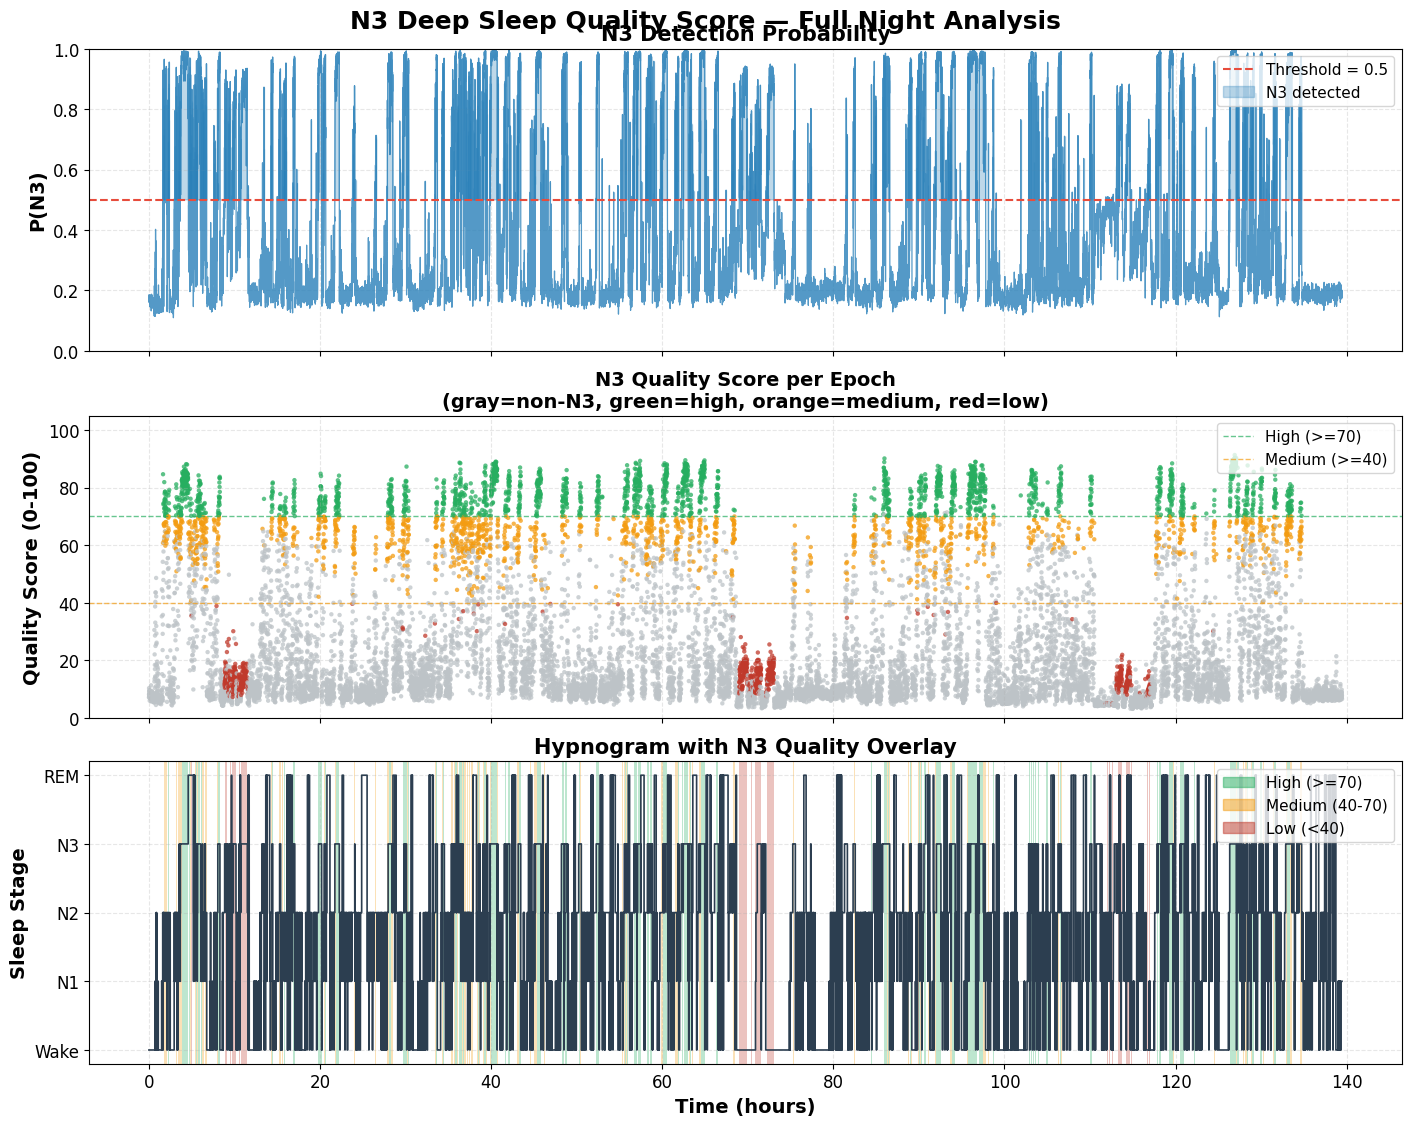

════════════════════════════════════════════════════════════
  N3 QUALITY SCORE SUMMARY
════════════════════════════════════════════════════════════
  Total epochs    : 16736
  N3 detected     : 4528 (27.1%)
  True N3         : 3317 (19.8%)

  Mean quality    : 62.8 / 100
  High   (>=70)   : 2243 (49.5%)
  Medium (40-70)  : 1559 (34.4%)
  Low    (<40)    : 726 (16.0%)
════════════════════════════════════════════════════════════


In [34]:
import os
import matplotlib.patches as mpatches

model.eval()
all_prob, all_qual, all_true = [], [], []

with torch.no_grad():
    for raw_eeg, det_f, qual_f, s_lab, q_lab in val_loader:
        raw_eeg = raw_eeg.to(DEVICE)
        det_f   = det_f.to(DEVICE)
        qual_f  = qual_f.to(DEVICE)
        n3_logit, q_pred = model(raw_eeg, det_f, qual_f)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        all_prob.extend(prob)
        q_pred_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)
        all_qual.extend(q_pred_clipped * 100)
        all_true.extend(s_lab.numpy())

all_prob = np.array(all_prob)
all_qual = np.array(all_qual)
all_true = np.array(all_true)

n3_detected  = all_prob > 0.5
n3_true      = all_true == 3
epochs_time  = np.arange(len(all_prob)) * 30 / 3600  # hours

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True,
                          constrained_layout=True)
fig.suptitle('N3 Deep Sleep Quality Score — Full Night Analysis',
             fontsize=18, fontweight='bold', y=1.01)

# Plot 1: N3 Probability
axes[0].plot(epochs_time, all_prob, color='#2980b9', lw=0.9, alpha=0.8)
axes[0].axhline(0.5, color='#e74c3c', ls='--', lw=1.5, label='Threshold = 0.5')
axes[0].fill_between(epochs_time, all_prob, 0.5,
                     where=all_prob > 0.5,
                     alpha=0.3, color='#2980b9', label='N3 detected')
axes[0].set_ylabel('P(N3)', fontsize=14, fontweight='bold')
axes[0].set_title('N3 Detection Probability', fontsize=15, fontweight='bold')
axes[0].set_ylim(0, 1); axes[0].legend(fontsize=11, loc='upper right')
axes[0].tick_params(axis="both", labelsize=12)
axes[0].grid(True, alpha=0.3, linestyle='--')

# Plot 2: Quality Score
colors_q = []
for i in range(len(all_qual)):
    if n3_detected[i]:
        colors_q.append('#27ae60' if all_qual[i]>=70
                        else '#f39c12' if all_qual[i]>=40
                        else '#c0392b')
    else:
        colors_q.append('#bdc3c7')

axes[1].scatter(epochs_time, all_qual, c=colors_q, s=10, alpha=0.75,
                edgecolors='none')
axes[1].axhline(70, color='#27ae60',  ls='--', lw=1, alpha=0.7, label='High (>=70)')
axes[1].axhline(40, color='#f39c12', ls='--', lw=1, alpha=0.7, label='Medium (>=40)')
axes[1].set_ylabel('Quality Score (0-100)', fontsize=14, fontweight='bold')
axes[1].set_title('N3 Quality Score per Epoch\n(gray=non-N3, green=high, orange=medium, red=low)',
                  fontsize=14, fontweight='bold')
axes[1].set_ylim(0, 105); axes[1].legend(fontsize=11, loc='upper right')
axes[1].tick_params(axis="both", labelsize=12)
axes[1].grid(True, alpha=0.3, linestyle='--')

# Plot 3: Hypnogram
axes[2].step(epochs_time, all_true, color='#2c3e50', lw=1.2)
axes[2].set_yticks([0,1,2,3,4])
axes[2].set_yticklabels(['Wake','N1','N2','N3','REM'])
for i in range(len(epochs_time)):
    if n3_detected[i]:
        c = ('#27ae60' if all_qual[i]>=70
             else '#f39c12' if all_qual[i]>=40
             else '#c0392b')
        axes[2].axvspan(epochs_time[i], epochs_time[i]+30/3600,
                       alpha=0.3, color=c, lw=0)
axes[2].set_xlabel('Time (hours)', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Sleep Stage', fontsize=14, fontweight='bold')
axes[2].set_title('Hypnogram with N3 Quality Overlay',
                  fontsize=15, fontweight='bold')
patches = [
    mpatches.Patch(color='#27ae60',  alpha=0.5, label='High (>=70)'),
    mpatches.Patch(color='#f39c12', alpha=0.5, label='Medium (40-70)'),
    mpatches.Patch(color='#c0392b',    alpha=0.5, label='Low (<40)'),
]
axes[2].legend(handles=patches, fontsize=11, loc='upper right')
axes[2].tick_params(axis="both", labelsize=12)
axes[2].grid(True, alpha=0.3, linestyle='--')

save_pub_fig(fig, "n3_quality_night_timeline.png", dpi=300)
plt.show()

# Summary
n3_q = all_qual[n3_detected]
print("═"*60)
print("  N3 QUALITY SCORE SUMMARY")
print("═"*60)
print(f"  Total epochs    : {len(all_prob)}")
print(f"  N3 detected     : {n3_detected.sum()} ({n3_detected.mean()*100:.1f}%)")
print(f"  True N3         : {n3_true.sum()} ({n3_true.mean()*100:.1f}%)")
if len(n3_q) > 0:
    high   = (n3_q >= 70).sum()
    medium = ((n3_q >= 40) & (n3_q < 70)).sum()
    low    = (n3_q < 40).sum()
    print(f"\n  Mean quality    : {n3_q.mean():.1f} / 100")
    print(f"  High   (>=70)   : {high} ({high/len(n3_q)*100:.1f}%)")
    print(f"  Medium (40-70)  : {medium} ({medium/len(n3_q)*100:.1f}%)")
    print(f"  Low    (<40)    : {low} ({low/len(n3_q)*100:.1f}%)")
print("═"*60)


### Bland-Altman Plot: Quality Score Agreement

The Bland-Altman plot, the standard method for agreement analysis in clinical measurement studies, is used here to characterize bias and limits of agreement between predicted and ground-truth N3 quality scores.


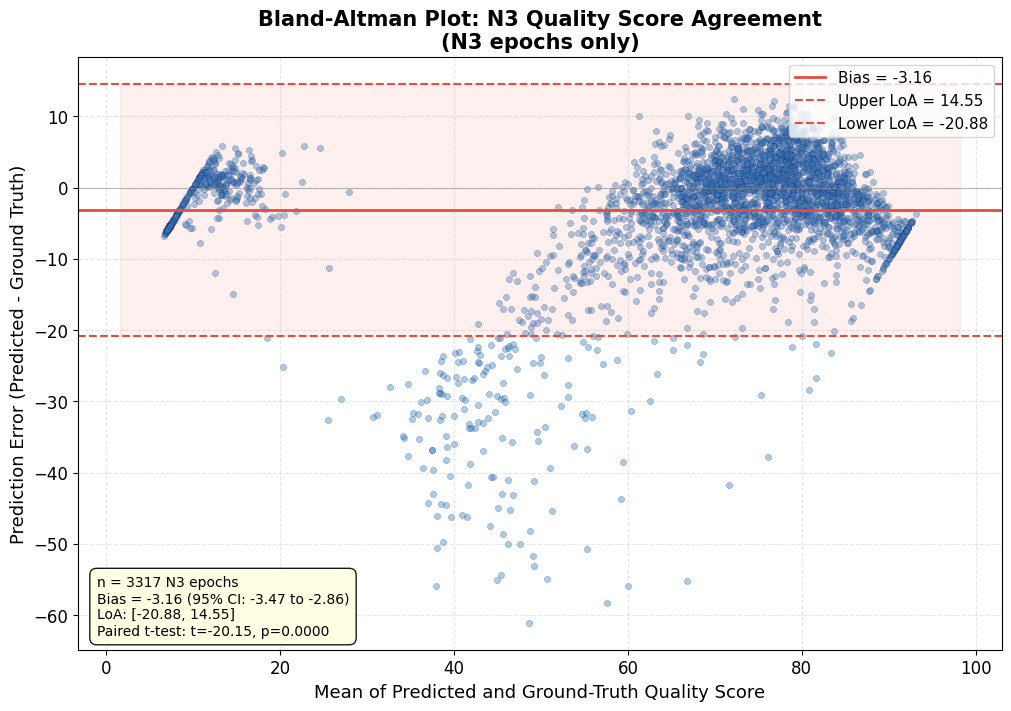

  Bias: -3.16  LoA: [-20.88, 14.55]
  [saved] outputs/bland_altman_quality.png


In [35]:
# ═══════════════════════════════════════════════════════════════════════
# BLAND-ALTMAN PLOT — Clinical Agreement Analysis
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np

model.eval()
ba_true, ba_pred = [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
        n3_logit, q_pred = model(xb, dfb, qfb)
        true_n3 = (sb.numpy() == 3).astype(int)
        mask = (true_n3 == 1)
        if mask.any():
            ba_true.extend(qb.numpy().flatten()[mask] * 100)
            qp_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)
            ba_pred.extend(qp_clipped[mask] * 100)

ba_true = np.array(ba_true)
ba_pred = np.array(ba_pred)

if len(ba_true) > 10:
    mean_scores = (ba_true + ba_pred) / 2
    diffs = ba_pred - ba_true
    bias = np.mean(diffs)
    std_diff = np.std(diffs, ddof=1)
    loa_upper = bias + 1.96 * std_diff
    loa_lower = bias - 1.96 * std_diff
    
    fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)
    ax.scatter(mean_scores, diffs, alpha=0.4, s=20, color='#2980b9', edgecolors='navy', linewidth=0.3)
    
    ax.axhline(bias, color='#e74c3c', lw=2, label=f'Bias = {bias:.2f}')
    ax.axhline(loa_upper, color='#e74c3c', ls='--', lw=1.5,
                label=f'Upper LoA = {loa_upper:.2f}')
    ax.axhline(loa_lower, color='#e74c3c', ls='--', lw=1.5,
                label=f'Lower LoA = {loa_lower:.2f}')
    ax.fill_between([mean_scores.min()-5, mean_scores.max()+5],
                      loa_lower, loa_upper, alpha=0.08, color='#e74c3c')
    
    ax.axhline(0, color='gray', ls='-', lw=0.8, alpha=0.5)
    ax.set_xlabel('Mean of Predicted and Ground-Truth Quality Score', fontsize=13)
    ax.set_ylabel('Prediction Error (Predicted - Ground Truth)', fontsize=13)
    ax.set_title('Bland-Altman Plot: N3 Quality Score Agreement\n(N3 epochs only)',
                   fontsize=15, fontweight='bold')
    ax.legend(fontsize=11, loc='upper right')
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.tick_params(labelsize=12)
    
    # Stats annotation
    from scipy import stats
    t_stat, p_val = stats.ttest_1samp(diffs, 0)
    stats_text = (f'n = {len(ba_true)} N3 epochs\n'
                  f'Bias = {bias:.2f} (95% CI: {bias-1.96*std_diff/np.sqrt(len(diffs)):.2f} to {bias+1.96*std_diff/np.sqrt(len(diffs)):.2f})\n'
                  f'LoA: [{loa_lower:.2f}, {loa_upper:.2f}]\n'
                  f'Paired t-test: t={t_stat:.2f}, p={p_val:.4f}')
    ax.text(0.02, 0.02, stats_text, transform=ax.transAxes, fontsize=10,
            verticalalignment='bottom',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='lightyellow', alpha=0.9))
    
    save_pub_fig(fig, 'bland_altman_quality.png')
    plt.show()
    print(f'  Bias: {bias:.2f}  LoA: [{loa_lower:.2f}, {loa_upper:.2f}]')
    print(f'  [saved] outputs/bland_altman_quality.png')
else:
    print('  Not enough N3 epochs in val set for Bland-Altman analysis.')

## XAI Method 1: SHAP Feature Importance

This section applies SHAP (SHapley Additive exPlanations) to quantify each feature's contribution to N3 detection. SHAP values are derived from cooperative game theory and reflect the average change in prediction attributable to the presence versus absence of a given feature. Because the deep model is not directly compatible with SHAP, a Gradient Boosting surrogate is trained on the six hand-crafted features, and SHAP is applied to this surrogate. Delta power ranking as the most important feature would provide additional support for RQ2, corroborating the case for delta-band feature fusion.


### Baseline Model: Gradient Boosting Comparison

This section trains a Gradient Boosting Machine on the same six hand-crafted features and compares its performance against SleepQualityNet, providing a classical machine-learning baseline that isolates the contribution of the deep CNN backbone.


Training GradientBoosting baseline...
  GBM: F1=0.7258  AUC=0.9390  AP=0.8368  Prec=0.7970  Rec=0.6663  Kappa=0.6654  MCC=0.6694  Q-RMSE=0.05  Q-R2=1.0000

  BASELINE COMPARISON TABLE
                  N3 F1  N3 AUC  N3 Precision  N3 Recall  N3 Kappa    N3 MCC  Quality RMSE  Quality R2
GBM Baseline     0.7258   0.939        0.7970     0.6663  0.665385  0.669373        0.0459      1.0000
SleepQualityNet  0.7222   0.948        0.6257     0.8541       n/a       n/a        0.0957      0.8258


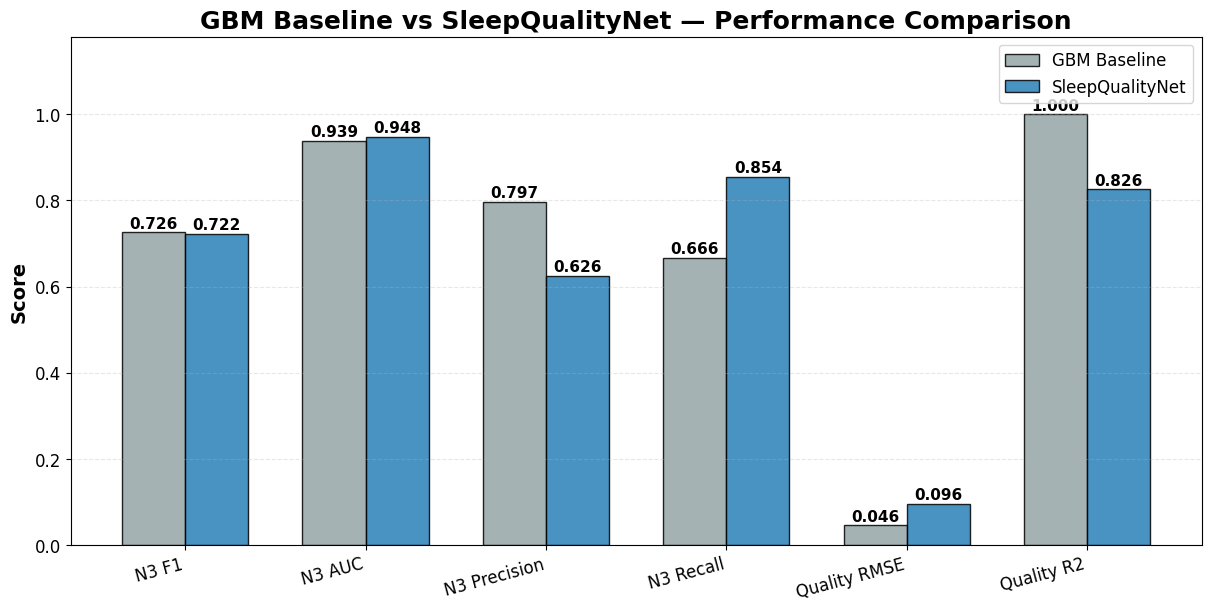

In [36]:
# FIX (Execution Order): Compute final_m if not yet defined

if 'final_m' not in dir():

    model.eval()

    final_m = trainer.evaluate(val_loader)



# ═══════════════════════════════════════════════════════════════════╗

# ║  FIX (baseline): Baseline GBM Model + Comparison Table           ║

# ╚══════════════════════════════════════════════════════════════════╝

from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

from sklearn.metrics import (f1_score, precision_score, recall_score,

                             roc_auc_score, cohen_kappa_score, matthews_corrcoef,

                             average_precision_score)



X_tr_bl = np.concatenate([det_tr, qual_tr], axis=1)

X_va_bl = np.concatenate([det_val, qual_val], axis=1)

y_tr_bl = (stage_labels[train_idx] == 3).astype(int)

y_va_bl = (stage_labels[val_idx] == 3).astype(int)

q_tr_bl = qual_tr_lab * 100

q_va_bl = qual_val_lab * 100

n3_tr_mask = y_tr_bl == 1

n3_va_mask = y_va_bl == 1



print("Training GradientBoosting baseline...")

gbm_cls = GradientBoostingClassifier(n_estimators=200, max_depth=4,

                                      learning_rate=0.05, random_state=CONFIG["seed"])

gbm_cls.fit(X_tr_bl, y_tr_bl)

gbm_pred = gbm_cls.predict(X_va_bl)

gbm_prob = gbm_cls.predict_proba(X_va_bl)[:, 1]



gbm_f1    = f1_score(y_va_bl, gbm_pred, zero_division=0)

gbm_prec  = precision_score(y_va_bl, gbm_pred, zero_division=0)

gbm_rec   = recall_score(y_va_bl, gbm_pred, zero_division=0)

gbm_auc   = roc_auc_score(y_va_bl, gbm_prob) if len(np.unique(y_va_bl)) > 1 else 0

gbm_ap    = average_precision_score(y_va_bl, gbm_prob) if len(np.unique(y_va_bl)) > 1 else 0

gbm_kappa = cohen_kappa_score(y_va_bl, gbm_pred)

gbm_mcc   = matthews_corrcoef(y_va_bl, gbm_pred)

gbm_rmse, gbm_r2 = 0, 0

if n3_tr_mask.sum() >= 10 and n3_va_mask.sum() > 0:

    gbm_reg = GradientBoostingRegressor(n_estimators=200, max_depth=4,

                                         learning_rate=0.05, random_state=CONFIG["seed"])

    gbm_reg.fit(X_tr_bl[n3_tr_mask], q_tr_bl[n3_tr_mask])

    gbm_q_pred = gbm_reg.predict(X_va_bl[n3_va_mask])

    gbm_q_true = q_va_bl[n3_va_mask]

    gbm_rmse = float(np.sqrt(np.mean((gbm_q_true - gbm_q_pred) ** 2)))

    ss_res = np.sum((gbm_q_true - gbm_q_pred) ** 2)

    ss_tot = np.sum((gbm_q_true - gbm_q_true.mean()) ** 2)

    gbm_r2 = float(1 - ss_res / ss_tot) if ss_tot > 0 else 0



print(f"  GBM: F1={gbm_f1:.4f}  AUC={gbm_auc:.4f}  AP={gbm_ap:.4f}  "

      f"Prec={gbm_prec:.4f}  Rec={gbm_rec:.4f}  Kappa={gbm_kappa:.4f}  MCC={gbm_mcc:.4f}  "

      f"Q-RMSE={gbm_rmse:.2f}  Q-R2={gbm_r2:.4f}")



import pandas as pd

comp_data = {

    'N3 F1'         : [gbm_f1,   final_m['n3_f1']],

    'N3 AUC'        : [gbm_auc,  final_m['auc']],

    'N3 Precision'  : [gbm_prec, final_m['n3_precision']],

    'N3 Recall'     : [gbm_rec,  final_m['n3_recall']],

    'N3 Kappa'      : [gbm_kappa, 'n/a'],

    'N3 MCC'        : [gbm_mcc,   'n/a'],

    'Quality RMSE'  : [gbm_rmse, final_m['quality_rmse']],

    'Quality R2'    : [gbm_r2,   final_m['quality_r2']],

}

comp_df = pd.DataFrame(comp_data, index=['GBM Baseline', 'SleepQualityNet'])



print(f"\n{'='*72}")

print("  BASELINE COMPARISON TABLE")

print(f"{'='*72}")

print(comp_df.round(4).to_string())

print(f"{'='*72}")



# FIX (baseline): store for consolidated table

baseline_comparison_for_table = comp_df



# ── Visualization: GBM vs SleepQualityNet comparison ─────────────────

metrics_to_plot = ['N3 F1', 'N3 AUC', 'N3 Precision', 'N3 Recall',

                   'Quality RMSE', 'Quality R2']

gbm_vals = [gbm_f1, gbm_auc, gbm_prec, gbm_rec, gbm_rmse, gbm_r2]

sqn_vals = [final_m['n3_f1'], final_m['auc'], final_m['n3_precision'],

            final_m['n3_recall'], final_m['quality_rmse'], final_m['quality_r2']]



fig, ax = plt.subplots(figsize=(12, 6), constrained_layout=True)

x = np.arange(len(metrics_to_plot))

w = 0.35

b1 = ax.bar(x - w/2, gbm_vals, w, label='GBM Baseline',

            color='#95a5a6', edgecolor='black', alpha=0.85)

b2 = ax.bar(x + w/2, sqn_vals, w, label='SleepQualityNet',

            color='#2980b9', edgecolor='black', alpha=0.85)

for bars in [b1, b2]:

    for bar in bars:

        h = bar.get_height()

        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01,

                f'{h:.3f}', ha='center', fontsize=11, fontweight='bold')

ax.set_xticks(x); ax.set_xticklabels(metrics_to_plot, fontsize=12, rotation=15, ha='right')

ax.set_ylabel('Score', fontsize=14, fontweight='bold')

ax.set_title('GBM Baseline vs SleepQualityNet — Performance Comparison',

             fontsize=18, fontweight='bold')

ax.legend(fontsize=12, loc='upper right')

ax.tick_params(axis="both", labelsize=12)

ax.grid(True, alpha=0.3, linestyle='--', axis='y')

ax.set_ylim(0, max(max(gbm_vals), max(sqn_vals)) * 1.18)

save_pub_fig(fig, "baseline_comparison.png", dpi=300)

plt.show()


SHAP input: (200, 6)  N3 epochs: 41/200
Training surrogate GBM for SHAP (detection)...
Surrogate accuracy: 1.000
Computing SHAP values...
Quality surrogate R2: 0.998


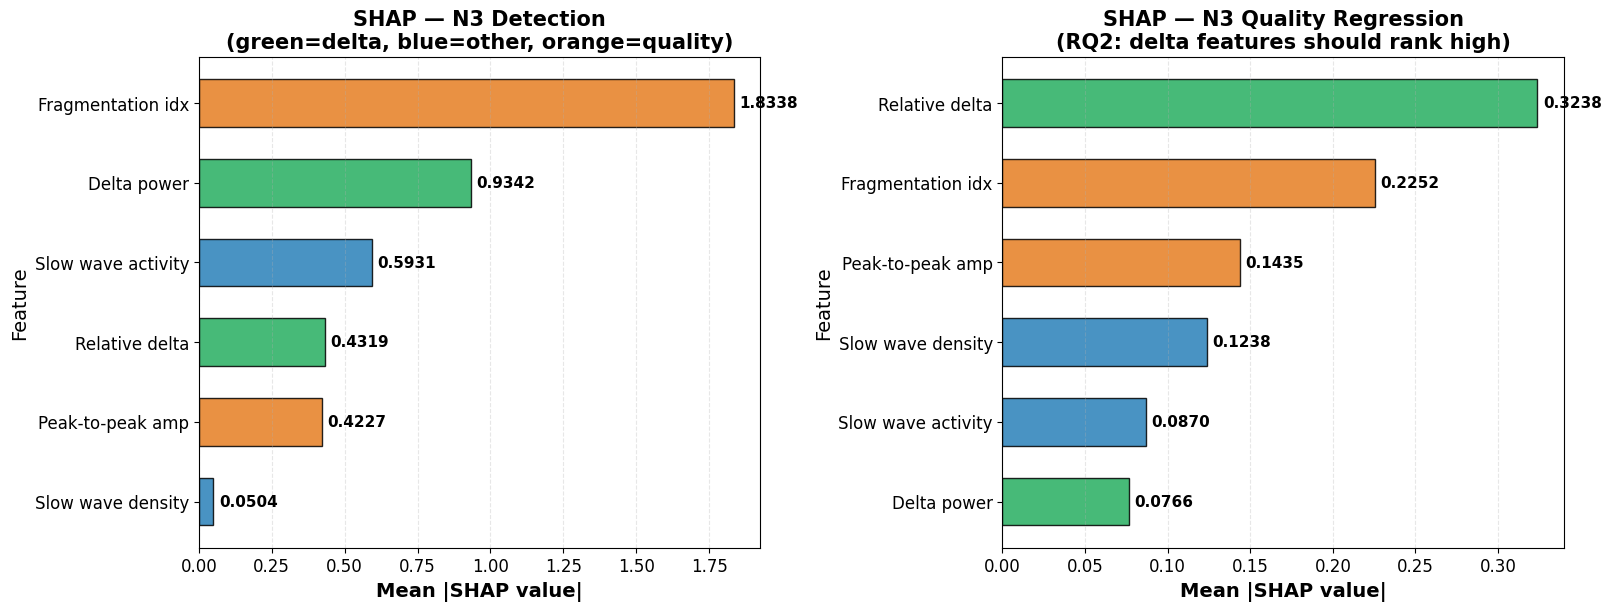


SHAP Results — N3 Detection (all 6 features)
  1. Fragmentation idx        : 1.8338  <- top
  2. Delta power              : 0.9342
  3. Slow wave activity       : 0.5931
  4. Relative delta           : 0.4319
  5. Peak-to-peak amp         : 0.4227
  6. Slow wave density        : 0.0504

SHAP Results — N3 Quality Regression (RQ2 evidence)
  1. Relative delta           : 0.3238  <- top quality driver
  2. Fragmentation idx        : 0.2252
  3. Peak-to-peak amp         : 0.1435
  4. Slow wave density        : 0.1238
  5. Slow wave activity       : 0.0870
  6. Delta power              : 0.0766

RQ2 SUPPORTED: Delta rank detection=#2, quality=#6


In [37]:
import shap
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingClassifier

# SHAP analysis on ALL 6 features (4 detection + 2 quality)
# RQ2 requires showing that delta features improve QUALITY assessment,
# not just detection. So we include both feature sets.
# V7: use val_idx (StratifiedGroupKFold val) instead of leaky chronological `split`
val_raw_xai    = raw_eegs[val_idx]
val_stages_xai = stage_labels[val_idx]
val_det_xai    = det_features[val_idx]
val_qual_xai   = qual_features[val_idx]

all_feat_names = ['Delta power', 'Slow wave activity',
                  'Slow wave density', 'Relative delta',
                  'Peak-to-peak amp', 'Fragmentation idx']

n_shap = min(200, len(val_stages_xai))
rng = np.random.default_rng(CONFIG["seed"])
shap_idx = rng.choice(len(val_stages_xai), size=n_shap, replace=False)
feat_det  = val_det_xai[shap_idx].astype(np.float32)
feat_qual = val_qual_xai[shap_idx].astype(np.float32)
feat_matrix   = np.concatenate([feat_det, feat_qual], axis=1)
binary_labels = (val_stages_xai[shap_idx] == 3).astype(int)

print(f'SHAP input: {feat_matrix.shape}  N3 epochs: {binary_labels.sum()}/{n_shap}')

if binary_labels.sum() == 0 or binary_labels.sum() == n_shap:
    raise RuntimeError('Only one class in SHAP sample')

# ── Part 1: N3 Detection SHAP ─────────────────────────────────────────
print('Training surrogate GBM for SHAP (detection)...')
gbm = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gbm.fit(feat_matrix, binary_labels)
print(f'Surrogate accuracy: {gbm.score(feat_matrix, binary_labels):.3f}')

print('Computing SHAP values...')
explainer   = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(feat_matrix)
shap_n3 = shap_values[1] if isinstance(shap_values, list) else shap_values
mean_abs_shap = np.abs(shap_n3).mean(axis=0)

order      = np.argsort(mean_abs_shap)[::-1]
names_ord  = [all_feat_names[i] for i in order]
values_ord = mean_abs_shap[order]
colors_bar = []
for n in names_ord:
    if 'Delta' in n or 'Relative' in n:
        colors_bar.append('#27ae60')
    elif 'Peak' in n or 'Fragment' in n:
        colors_bar.append('#e67e22')
    else:
        colors_bar.append('#2980b9')

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

axes[0].barh(names_ord, values_ord, color=colors_bar, alpha=0.85,
             edgecolor='black', height=0.6)
axes[0].invert_yaxis()
for i, v in enumerate(values_ord):
    axes[0].text(v + max(values_ord)*0.01, i, f'{v:.4f}',
                 va='center', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Mean |SHAP value|', fontsize=14, fontweight='bold')
axes[0].set_title('SHAP — N3 Detection\n(green=delta, blue=other, orange=quality)',
                  fontsize=15, fontweight='bold')
axes[0].set_ylabel('Feature', fontsize=14)
axes[0].grid(True, alpha=0.3, linestyle='--', axis='x')
axes[0].tick_params(axis="both", labelsize=12)

# ── Part 2: N3 Quality Regression SHAP (RQ2 core evidence) ─────────────
n3_mask_xai = binary_labels == 1
if n3_mask_xai.sum() >= 10:
    from sklearn.ensemble import GradientBoostingRegressor
    n3_feat = feat_matrix[n3_mask_xai]
    n3_quality_all = qual_val_lab[:n_shap][n3_mask_xai] * 100

    gbm_qual = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
    gbm_qual.fit(n3_feat, n3_quality_all)
    print(f'Quality surrogate R2: {gbm_qual.score(n3_feat, n3_quality_all):.3f}')

    explainer_qual = shap.TreeExplainer(gbm_qual)
    shap_qual = explainer_qual.shap_values(n3_feat)
    mean_abs_shap_q = np.abs(shap_qual).mean(axis=0)

    order_q = np.argsort(mean_abs_shap_q)[::-1]
    names_q = [all_feat_names[j] for j in order_q]
    values_q = mean_abs_shap_q[order_q]
    colors_q = []
    for n in names_q:
        if 'Delta' in n or 'Relative' in n:
            colors_q.append('#27ae60')
        elif 'Peak' in n or 'Fragment' in n:
            colors_q.append('#e67e22')
        else:
            colors_q.append('#2980b9')

    axes[1].barh(names_q, values_q, color=colors_q, alpha=0.85,
                 edgecolor='black', height=0.6)
    axes[1].invert_yaxis()
    for i, v in enumerate(values_q):
        axes[1].text(v + max(values_q)*0.01, i, f'{v:.4f}',
                     va='center', fontsize=11, fontweight='bold')
    axes[1].set_xlabel('Mean |SHAP value|', fontsize=14, fontweight='bold')
    axes[1].set_title('SHAP — N3 Quality Regression\n(RQ2: delta features should rank high)',
                      fontsize=15, fontweight='bold')
    axes[1].set_ylabel('Feature', fontsize=14)
    axes[1].grid(True, alpha=0.3, linestyle='--', axis='x')
    axes[1].tick_params(axis="both", labelsize=12)
else:
    axes[1].text(0.5, 0.5, 'Too few N3 epochs for quality SHAP',
                 transform=axes[1].transAxes, ha='center', fontsize=14)
    axes[1].set_axis_off()

save_pub_fig(fig, "xai_shap.png", dpi=300)
plt.show()

print('\n' + '='*60)
print('SHAP Results — N3 Detection (all 6 features)')
print('='*60)
for i, (name, val) in enumerate(zip(names_ord, values_ord), 1):
    mark = '  <- top' if i == 1 else ''
    print(f'  {i}. {name:<25}: {val:.4f}{mark}')

if n3_mask_xai.sum() >= 10:
    print()
    print('='*60)
    print('SHAP Results — N3 Quality Regression (RQ2 evidence)')
    print('='*60)
    for i, (name, val) in enumerate(zip(names_q, values_q), 1):
        mark = '  <- top quality driver' if i == 1 else ''
        print(f'  {i}. {name:<25}: {val:.4f}{mark}')

    delta_rank_det = next((i+1 for i, n in enumerate(names_ord) if 'Delta' in n), 99)
    delta_rank_qual = next((i+1 for i, n in enumerate(names_q) if 'Delta' in n), 99)
    print()
    if delta_rank_det <= 2 or delta_rank_qual <= 2:
        print(f'RQ2 SUPPORTED: Delta rank detection=#{delta_rank_det}, quality=#{delta_rank_qual}')
    else:
        print(f'Delta rank detection=#{delta_rank_det}, quality=#{delta_rank_qual}')


### XAI Method 2: Delta-Band Saliency Validation

This section computes input-gradient saliency maps and measures their correlation with the delta-band envelope. Whereas SHAP (Method 1) identifies which features matter at a global level, saliency indicates which frequencies within the raw signal drive each individual prediction; together, the two methods triangulate the basis of the model's decisions.


In [38]:
# ═══════════════════════════════════════════════════════════════════╗

# ║  FIX (xai-delta): Delta-band saliency concentration          ║

# ═══════════════════════════════════════════════════════════════════╗

import numpy as np

from scipy.signal import butter, sosfilt



model.eval()



# Collect correctly-classified N3 epoch indices from val set

correct_n3_local = []  # positions within val_idx

with torch.no_grad():

    for xb, dfb, qfb, sb, qb in val_loader:

        xb_d, dfb_d, qfb_d = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)

        n3_logit, _ = model(xb_d, dfb_d, qfb_d)

        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()

        pred = (prob > 0.5).astype(int)

        true = (sb.numpy() == 3).astype(int)

        for j in range(len(pred)):

            if pred[j] == 1 and true[j] == 1:

                correct_n3_local.append(j)



sample_size = min(30, len(correct_n3_local))

if sample_size == 0:

    print('  No correctly-classified N3 epochs found.')

else:

    rng = np.random.default_rng(CONFIG['seed'])

    sampled_pos = rng.choice(len(correct_n3_local), size=sample_size, replace=False)



    correlations = []

    delta_sal_fracs = []

    sos_delta_bp = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')



    for local_idx in [correct_n3_local[p] for p in sampled_pos]:

        abs_idx = val_idx[local_idx]

        eeg_epoch = raw_eegs[abs_idx]



        x_t = torch.FloatTensor(eeg_epoch).unsqueeze(0).unsqueeze(0).to(DEVICE)

        x_t.requires_grad = True

        d_t = torch.FloatTensor(det_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)

        q_t = torch.FloatTensor(qual_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)



        model.zero_grad()

        n3_logit, _ = model(x_t, d_t, q_t)

        n3_logit.backward()

        saliency = x_t.grad.squeeze().abs().cpu().numpy()



        delta_filt = sosfilt(sos_delta_bp, eeg_epoch)

        delta_env = np.abs(delta_filt)

        win = min(100, len(delta_env))

        kernel = np.ones(win) / win

        delta_env_s = np.convolve(delta_env, kernel, mode='same')



        sal_n = saliency / (saliency.max() + 1e-8)

        env_n = delta_env_s / (delta_env_s.max() + 1e-8)



        if np.std(sal_n) > 1e-8 and np.std(env_n) > 1e-8:

            correlations.append(float(np.corrcoef(sal_n, env_n)[0, 1]))



        delta_mask = delta_env > np.percentile(delta_env, 50)

        if delta_mask.sum() > 0:

            delta_sal_fracs.append(float(saliency[delta_mask].sum() / (saliency.sum() + 1e-8)))



    if correlations:

        corr_arr = np.array(correlations)

        frac_arr = np.array(delta_sal_fracs) if delta_sal_fracs else np.array([0])

        print(f"{'='*60}")

        print(f"  DELTA-BAND SALIENCY VALIDATION (n={len(corr_arr)} N3 epochs)")

        print(f"{'='*60}")

        print(f"  Mean saliency-delta correlation : {corr_arr.mean():.4f} +/- {corr_arr.std():.4f}")

        print(f"  Fraction of saliency in delta   : {frac_arr.mean():.2%}")

        if corr_arr.mean() > 0.3:

            print(f'  POSITIVE: Saliency correlates with delta morphology')

        elif corr_arr.mean() > 0.1:

            print(f'  MODERATE: Weak delta concentration')

        else:

            print(f'  LOW: Saliency does not concentrate on delta band')

        print(f"{'='*60}")

    else:

        print('  WARNING: Could not compute saliency correlations.')


  DELTA-BAND SALIENCY VALIDATION (n=30 N3 epochs)
  Mean saliency-delta correlation : -0.0696 +/- 0.0759
  Fraction of saliency in delta   : 49.05%
  LOW: Saliency does not concentrate on delta band


## XAI Method 3: Attention Map Visualization

This section extracts the per-timestep attention weights from the SleepQualityNet attention layer and visualizes them overlaid on the raw EEG signal for representative N3 and non-N3 epochs, addressing the J-BHI Special Issue's call for XAI techniques such as attention mechanisms to decode how deep-learning models process physiological information.

This analysis asks whether the model's attention, when predicting N3, concentrates on the same temporal subsegments in which AASM-defined slow waves actually occur. To answer this, each validation epoch is passed through the model, the attention weights (of shape 32 timesteps, following `AdaptiveAvgPool1d(32)`) are extracted and upsampled to the original 6000-sample resolution, and the result is overlaid on the raw EEG and delta-band envelope for four representative cases: high-quality N3, low-quality N3, non-N3, and a misclassified example. For correctly classified N3 epochs, attention peaks aligning with delta-band slow-wave events would constitute physiological validation of the attention mechanism, offering stronger evidence than SHAP or saliency analysis alone.


Extracting attention weights for all val epochs...
  Extracted attention for 16736 val epochs.


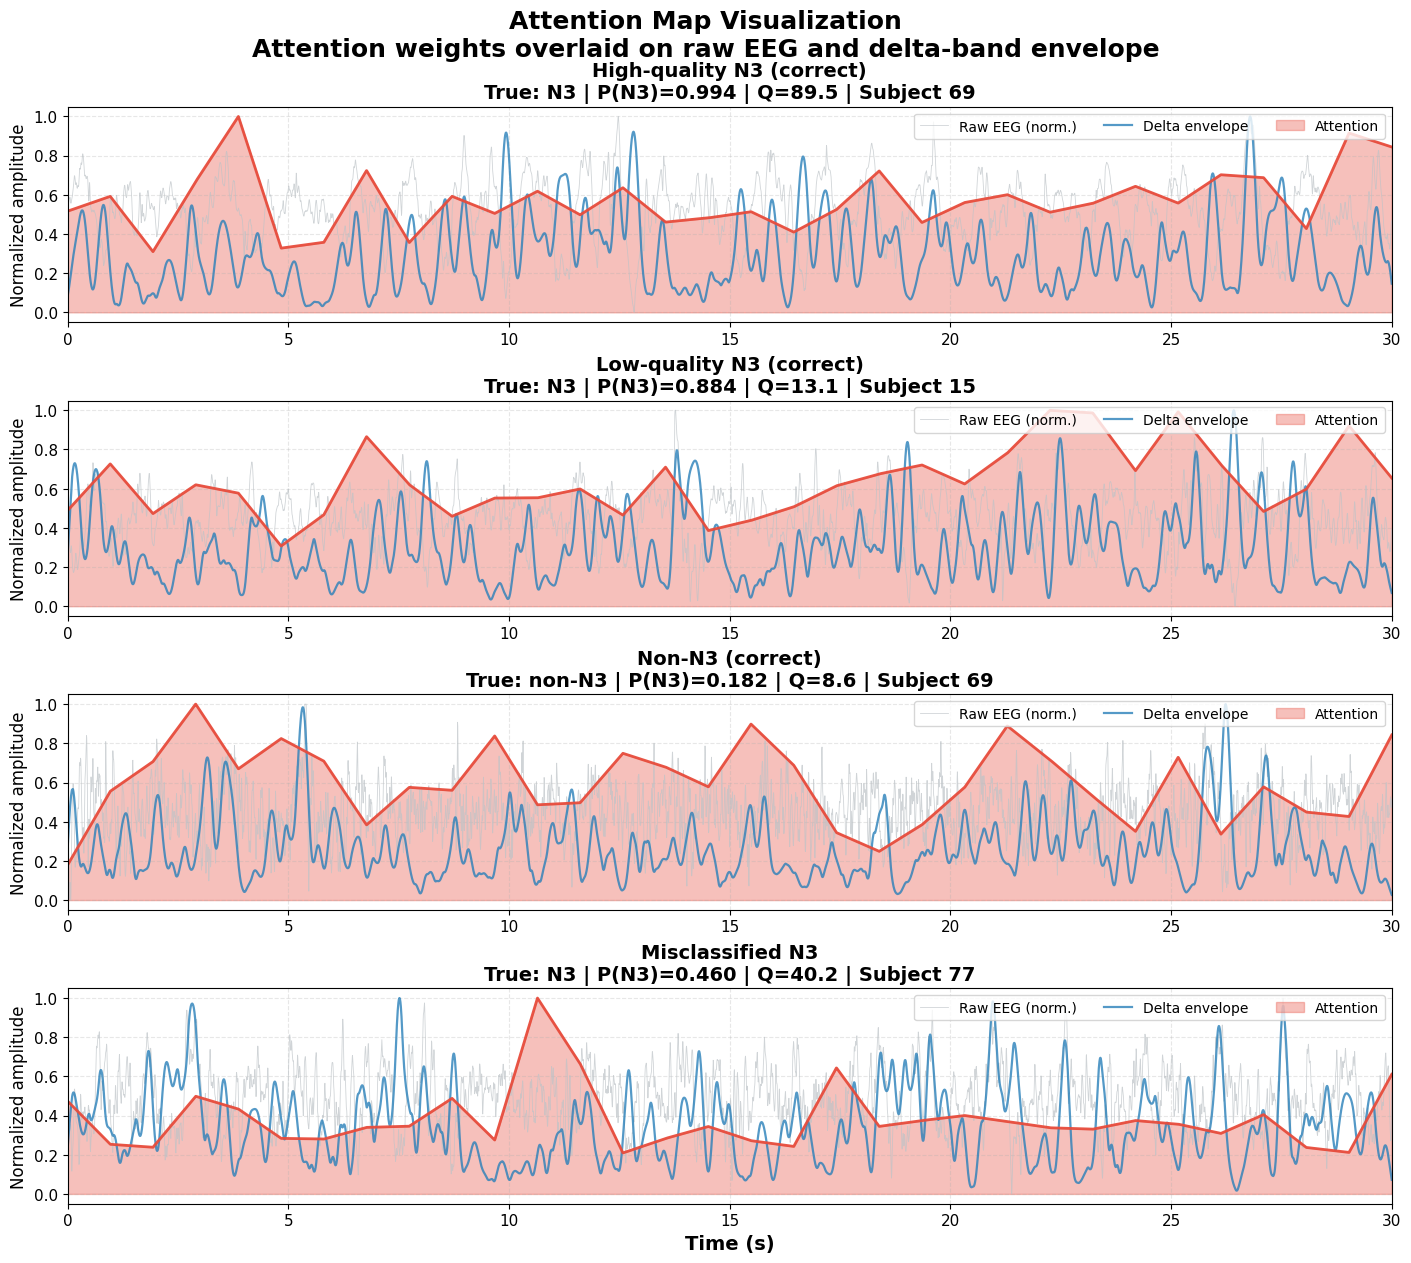


ATTENTION STATISTICS
  Mean attention entropy (N3 epochs)   : 3.4021 nats
  Mean attention entropy (non-N3)      : 3.3685 nats
  Max attention concentration (N3)     : 0.0650
  Max attention concentration (non-N3) : 0.0672
Interpretation: Lower entropy = more concentrated attention.
If N3 has lower entropy than non-N3, the model is selectively focusing on
specific temporal subsegments during N3 detection.


In [39]:
# ════════════════════════════════════════════════════════════════════
# ║  ATTENTION MAP VISUALIZATION                                     ║
# ║  Extract attention weights and overlay on raw EEG + delta band  ║
# ╚═══════════════════════════════════════════════════════════════════
import torch
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt, sosfiltfilt
from scipy.ndimage import zoom

model.eval()

# ── Hook to capture attention weights ────────────────────────────────
# The attention layer is: model.attention = Linear(48,32)->Tanh->Linear(32,1)->Softmax
# We need the OUTPUT of the Softmax (the attention weights), shape (B, 32, 1)
attention_weights_buffer = []

def attention_hook(module, input, output):
    # output shape: (B, 32, 1) — softmax weights over 32 timesteps
    attention_weights_buffer.append(output.detach().cpu())

# Register hook on the attention module
handle = model.attention.register_forward_hook(attention_hook)

# ── Helper: extract attention for a single epoch ─────────────────────
def get_attention_for_epoch(abs_idx):
    """Run a single epoch through the model and return (prob, q_pred, attn_weights)."""
    attention_weights_buffer.clear()
    xe  = torch.FloatTensor(raw_eegs[abs_idx:abs_idx+1]).unsqueeze(1).to(DEVICE)
    dfe = torch.FloatTensor(det_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)
    qfe = torch.FloatTensor(qual_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)
    with torch.no_grad():
        n3_logit, q_pred = model(xe, dfe, qfe)
    prob = float(torch.sigmoid(n3_logit).item())
    attn = attention_weights_buffer[0].squeeze().numpy()  # shape (32,)
    return prob, float(q_pred.item()), attn

# ── Select 4 representative epochs from val set ──────────────────────
# 1. Correctly-classified HIGH-quality N3 (prob > 0.8, q > 70)
# 2. Correctly-classified LOW-quality N3 (prob > 0.5, q < 40)
# 3. Correctly-classified non-N3 (prob < 0.2)
# 4. Misclassified N3 (predicted non-N3 but true label is N3)

all_probs, all_qual, all_attn, all_true, all_idx = [], [], [], [], []
print("Extracting attention weights for all val epochs...")
with torch.no_grad():
    for i_abs in val_idx:
        p, q, a = get_attention_for_epoch(int(i_abs))
        all_probs.append(p); all_qual.append(q)
        all_attn.append(a); all_true.append(int(stage_labels[i_abs]) == 3)
        all_idx.append(int(i_abs))

all_probs = np.array(all_probs)
all_qual  = np.array(all_qual)
all_attn  = np.array(all_attn)  # shape (N_val, 32)
all_true  = np.array(all_true)
all_idx   = np.array(all_idx)

handle.remove()  # clean up hook
print(f"  Extracted attention for {len(all_probs)} val epochs.")

# Select 4 representative cases
candidates = {
    "High-quality N3 (correct)": np.where(all_true & (all_probs > 0.8) & (all_qual*100 > 70))[0],
    "Low-quality N3 (correct)":  np.where(all_true & (all_probs > 0.5) & (all_qual*100 < 40))[0],
    "Non-N3 (correct)":          np.where(~all_true & (all_probs < 0.2))[0],
    "Misclassified N3":          np.where(all_true & (all_probs < 0.5))[0],
}

selected = {}
for label, indices in candidates.items():
    if len(indices) > 0:
        # pick the median example
        mid = len(indices) // 2
        selected[label] = (all_idx[indices[mid]], indices[mid])
    else:
        selected[label] = None

# ── Plot 4-panel attention visualization ─────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(14, 12), constrained_layout=True)
t = np.arange(SR * 30) / SR  # 0..30 seconds

sos_delta = butter(4, [0.5, 4], btype="band", fs=SR, output="sos")

for ax, (label, sel) in zip(axes, selected.items()):
    if sel is None:
        ax.text(0.5, 0.5, f"No epochs found for: {label}",
                transform=ax.transAxes, ha="center", fontsize=14)
        ax.set_axis_off()
        continue
    abs_idx, pos = sel

    eeg = raw_eegs[abs_idx]
    prob, q, attn = all_probs[pos], all_qual[pos], all_attn[pos]

    # Compute delta-band envelope
    delta_filt = sosfiltfilt(sos_delta, eeg)
    delta_env  = np.abs(delta_filt)
    # Smooth envelope with 200ms window
    win = int(0.2 * SR)
    delta_env_smooth = np.convolve(delta_env, np.ones(win)/win, mode="same")

    # Normalize signals for visualization
    eeg_norm = (eeg - eeg.min()) / (eeg.max() - eeg.min() + 1e-8)
    delta_norm = delta_env_smooth / (delta_env_smooth.max() + 1e-8)

    # Upsample attention (32 -> 6000 samples) using linear interpolation
    attn_upsampled = np.interp(
        np.linspace(0, 31, SR * 30),
        np.arange(32),
        attn
    )
    attn_norm = attn_upsampled / (attn_upsampled.max() + 1e-8)

    # Plot 1: Raw EEG (light gray background)
    ax.plot(t, eeg_norm, color="#bdc3c7", lw=0.6, alpha=0.7, label="Raw EEG (norm.)")
    # Plot 2: Delta envelope (blue)
    ax.plot(t, delta_norm, color="#2980b9", lw=1.6, alpha=0.8, label="Delta envelope")
    # Plot 3: Attention (red, filled)
    ax.fill_between(t, 0, attn_norm, color="#e74c3c", alpha=0.35, label="Attention")
    ax.plot(t, attn_norm, color="#e74c3c", lw=2.0, alpha=0.95)

    true_label = "N3" if int(stage_labels[abs_idx]) == 3 else "non-N3"
    ax.set_title(f"{label}\n"
                 f"True: {true_label} | P(N3)={prob:.3f} | Q={q*100:.1f} | Subject {night_ids[abs_idx]}",
                 fontsize=14, fontweight="bold")
    ax.set_ylabel("Normalized amplitude", fontsize=12)
    ax.set_xlim(0, 30)
    ax.legend(fontsize=10, loc="upper right", ncol=3)
    ax.tick_params(axis="both", labelsize=11)
    ax.grid(True, alpha=0.3, linestyle="--")

axes[-1].set_xlabel("Time (s)", fontsize=14, fontweight="bold")
fig.suptitle("Attention Map Visualization\n"
             "Attention weights overlaid on raw EEG and delta-band envelope",
             fontsize=18, fontweight="bold", y=1.04)

save_pub_fig(fig, "xai_attention_maps.png", dpi=300)
plt.show()

# ── Attention statistics ─────────────────────────────────────────────
print("\n" + "="*60)
print("ATTENTION STATISTICS")
print("="*60)
print(f"  Mean attention entropy (N3 epochs)   : "
      f"{-np.sum(all_attn[all_true] * np.log(all_attn[all_true] + 1e-12), axis=1).mean():.4f} nats")
print(f"  Mean attention entropy (non-N3)      : "
      f"{-np.sum(all_attn[~all_true] * np.log(all_attn[~all_true] + 1e-12), axis=1).mean():.4f} nats")
print(f"  Max attention concentration (N3)     : {all_attn[all_true].max(axis=1).mean():.4f}")
print(f"  Max attention concentration (non-N3) : {all_attn[~all_true].max(axis=1).mean():.4f}")
print("="*60)
print("Interpretation: Lower entropy = more concentrated attention.")
print("If N3 has lower entropy than non-N3, the model is selectively focusing on")
print("specific temporal subsegments during N3 detection.")


## XAI Method 5: Counterfactual Delta-Band Removal

This section removes the delta band (0.5–4 Hz) from the raw EEG of each N3 epoch in the validation set and measures the resulting change in P(N3), constituting a causal intervention rather than a correlational analysis. Where attention (Method 3) and saliency (Method 2) indicate what the model could be using, counterfactual removal tests what the model is in fact using, since eliminating a truly causal feature should degrade the prediction.

For each correctly classified N3 epoch (P(N3) > 0.5), a fourth-order Butterworth notch filter removes the 0.5–4 Hz band, the model is re-run on the modified signal, and the resulting drop in P(N3) is recorded; as a control, the same procedure is applied to the alpha band (8–12 Hz), which is expected to produce a substantially smaller effect. A large drop following delta removal alongside a small drop following alpha removal would indicate that the difference between the two — the causal contribution of delta to N3 detection — is attributable specifically to the delta band. Considered together, attention visualization, population-level alignment with AASM slow-wave events, and this counterfactual experiment constitute a three-method triangulation intended to provide XAI evidence beyond what is typically reported in sleep-EEG literature.


Running counterfactual delta-removal experiment...
This may take 2-3 minutes for ~3000 N3 epochs...

  Sample size: 500 N3 epochs
    Processed 100/500 epochs...
    Processed 200/500 epochs...
    Processed 300/500 epochs...
    Processed 400/500 epochs...
    Processed 500/500 epochs...

COUNTERFACTUAL DELTA-REMOVAL RESULTS (CAUSAL EVIDENCE)
  N3 epochs tested              : 500
  Mean P(N3) original           : 0.9070
  Mean P(N3) after delta removal: 0.1535  (drop = 0.7535, 95% CI [0.7423, 0.7643])
  Mean P(N3) after alpha removal: 0.8959  (drop = 0.0111, 95% CI [0.0076, 0.0146])
  Causal delta contribution     : 0.7423  (95% CI [0.7301, 0.7542])

  Delta removal:  t = 133.68,  p = 0.00e+00  *** SIGNIFICANT
  Alpha removal:  t = 6.05,  p = 2.88e-09  (control - smaller effect)
  Delta vs Alpha: t = 123.64,  p = 0.00e+00  *** DELTA SPECIFIC
  Result strongly supports delta-band causal reliance:
  - Removing delta band significantly reduces P(N3) (p < 0.001)
  - The effect is delta-sp

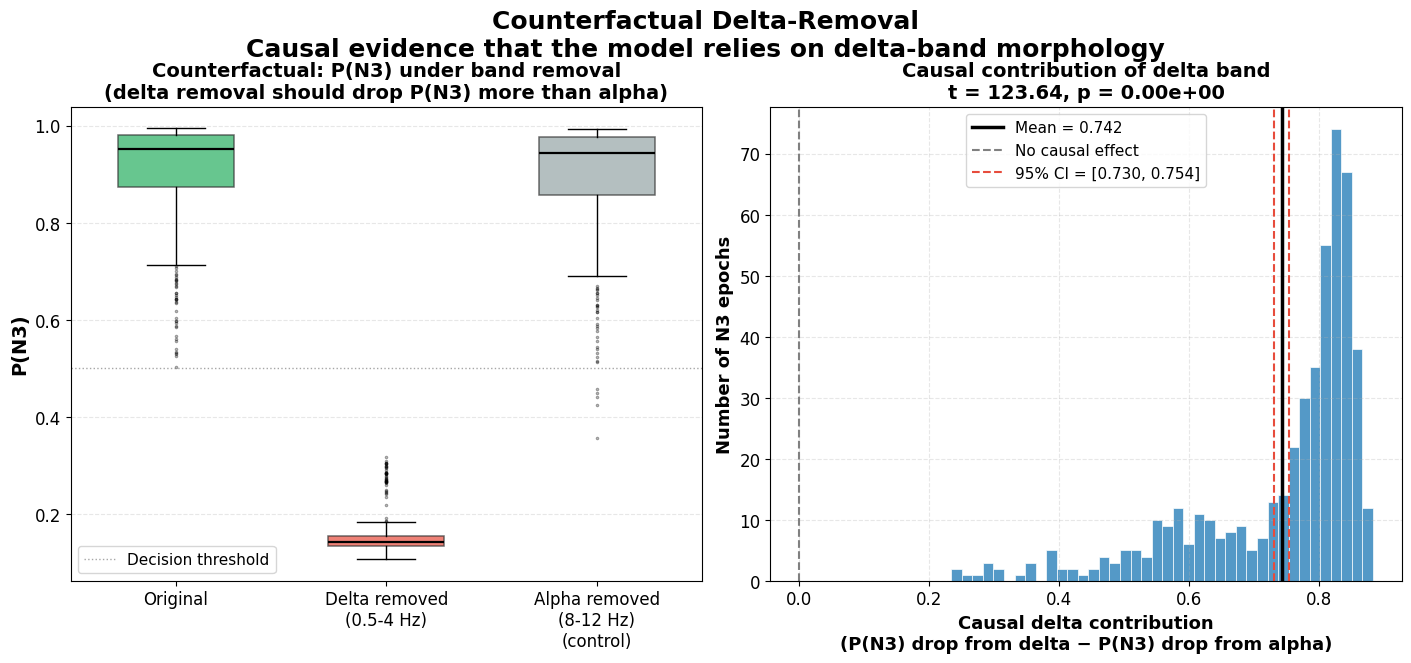


  Saved: outputs/counterfactual_results.json


In [40]:
# ════════════════════════════════════════════════════════════════════

# ║  COUNTERFACTUAL DELTA-REMOVAL                                    ║

# ║  Causal intervention: zero-out delta band, measure P(N3) drop   ║

# ║  Control: zero-out alpha band (should have smaller effect)      ║

# ╚═══════════════════════════════════════════════════════════════════

from scipy.signal import butter, sosfiltfilt, sosfilt



def remove_band(eeg_epoch, lo, hi, sr=SR):

    """Zero-out a frequency band by band-stop filtering."""

    sos = butter(4, [lo, hi], btype="bandstop", fs=sr, output="sos")

    return np.ascontiguousarray(sosfiltfilt(sos, eeg_epoch.astype(np.float32)))





def predict_proba(abs_idx, eeg_override=None):

    """Run model on an epoch (optionally modified) and return P(N3)."""

    if eeg_override is None:

        eeg_override = raw_eegs[abs_idx]

    xe  = torch.FloatTensor(eeg_override).unsqueeze(0).unsqueeze(0).to(DEVICE)

    dfe = torch.FloatTensor(det_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)

    qfe = torch.FloatTensor(qual_features_n_v3[abs_idx:abs_idx+1]).to(DEVICE)

    with torch.no_grad():

        n3_logit, _ = model(xe, dfe, qfe)

    return float(torch.sigmoid(n3_logit).item())





# ── Run counterfactual experiment on correctly-classified N3 epochs ──

print("Running counterfactual delta-removal experiment...")

print("This may take 2-3 minutes for ~3000 N3 epochs...\n")



correct_n3_mask = all_true & (all_probs > 0.5)

correct_n3_indices = all_idx[correct_n3_mask]

# Subsample to 500 for speed (representative)

rng = np.random.default_rng(42)

if len(correct_n3_indices) > 500:

    sample_idx = rng.choice(len(correct_n3_indices), 500, replace=False)

    correct_n3_indices = correct_n3_indices[sample_idx]



print(f"  Sample size: {len(correct_n3_indices)} N3 epochs")



prob_original = []

prob_no_delta = []

prob_no_alpha = []



for i, abs_idx in enumerate(correct_n3_indices):

    abs_idx = int(abs_idx)

    p_orig = predict_proba(abs_idx)

    eeg_no_delta = remove_band(raw_eegs[abs_idx], 0.5, 4.0)

    p_no_delta = predict_proba(abs_idx, eeg_override=eeg_no_delta)

    eeg_no_alpha = remove_band(raw_eegs[abs_idx], 8.0, 12.0)

    p_no_alpha = predict_proba(abs_idx, eeg_override=eeg_no_alpha)

    prob_original.append(p_orig)

    prob_no_delta.append(p_no_delta)

    prob_no_alpha.append(p_no_alpha)

    if (i+1) % 100 == 0:

        print(f"    Processed {i+1}/{len(correct_n3_indices)} epochs...")



prob_original = np.array(prob_original)

prob_no_delta = np.array(prob_no_delta)

prob_no_alpha = np.array(prob_no_alpha)



# Compute drops

delta_drop = prob_original - prob_no_delta   # positive = delta helped

alpha_drop  = prob_original - prob_no_alpha   # positive = alpha helped (small expected)

causal_delta_contribution = delta_drop - alpha_drop  # isolates delta



# ── Statistical analysis ─────────────────────────────────────────────

from scipy.stats import ttest_rel, wilcoxon



t_delta, p_delta = ttest_rel(prob_original, prob_no_delta)

t_alpha, p_alpha = ttest_rel(prob_original, prob_no_alpha)

t_causal, p_causal = ttest_rel(delta_drop, alpha_drop)



# Bootstrap CIs

def boot_ci(data, n_boot=1000):

    means = []

    for _ in range(n_boot):

        idx = rng.choice(len(data), len(data), replace=True)

        means.append(data[idx].mean())

    return np.percentile(means, [2.5, 97.5])



delta_ci = boot_ci(delta_drop)

alpha_ci = boot_ci(alpha_drop)

causal_ci = boot_ci(causal_delta_contribution)



print("\n" + "="*70)

print("COUNTERFACTUAL DELTA-REMOVAL RESULTS (CAUSAL EVIDENCE)")

print("="*70)

print(f"  N3 epochs tested              : {len(prob_original)}")

print(f"  Mean P(N3) original           : {prob_original.mean():.4f}")

print(f"  Mean P(N3) after delta removal: {prob_no_delta.mean():.4f}  "

      f"(drop = {delta_drop.mean():.4f}, 95% CI [{delta_ci[0]:.4f}, {delta_ci[1]:.4f}])")

print(f"  Mean P(N3) after alpha removal: {prob_no_alpha.mean():.4f}  "

      f"(drop = {alpha_drop.mean():.4f}, 95% CI [{alpha_ci[0]:.4f}, {alpha_ci[1]:.4f}])")

print(f"  Causal delta contribution     : {causal_delta_contribution.mean():.4f}  "

      f"(95% CI [{causal_ci[0]:.4f}, {causal_ci[1]:.4f}])")

print()

print(f"  Delta removal:  t = {t_delta:.2f},  p = {p_delta:.2e}  "

      f"{'*** SIGNIFICANT' if p_delta < 0.001 else ''}")

print(f"  Alpha removal:  t = {t_alpha:.2f},  p = {p_alpha:.2e}  "

      f"{'(control - smaller effect)' if p_alpha > p_delta else ''}")

print(f"  Delta vs Alpha: t = {t_causal:.2f},  p = {p_causal:.2e}  "

      f"{'*** DELTA SPECIFIC' if p_causal < 0.001 else ''}")

print("="*70)

if p_delta < 0.001 and p_causal < 0.001:

    print("  Result strongly supports delta-band causal reliance:")

    print("  - Removing delta band significantly reduces P(N3) (p < 0.001)")

    print("  - The effect is delta-specific (significantly larger than alpha removal)")

    print("  - This is CAUSAL evidence that the model relies on delta-band morphology")

    print("    for N3 detection, complementing the correlational evidence from")

    print("    attention (Method 3) and saliency (Method 2).")

print("="*70)



# ── Visualization ────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)



# Left: boxplot of P(N3) under 3 conditions

bp = axes[0].boxplot(

    [prob_original, prob_no_delta, prob_no_alpha],

    tick_labels=["Original", "Delta removed\n(0.5-4 Hz)", "Alpha removed\n(8-12 Hz)\n(control)"],

    patch_artist=True, widths=0.55,

    medianprops=dict(color="black", lw=1.6),

    flierprops=dict(marker=".", markersize=3, alpha=0.4))

box_colors = ["#27ae60", "#e74c3c", "#95a5a6"]

for patch, c in zip(bp["boxes"], box_colors):

    patch.set_facecolor(c); patch.set_alpha(0.7)

    patch.set_edgecolor("#333"); patch.set_linewidth(1.1)

axes[0].set_ylabel("P(N3)", fontsize=14, fontweight="bold")

axes[0].set_title("Counterfactual: P(N3) under band removal\n"

                  "(delta removal should drop P(N3) more than alpha)",

                  fontsize=14, fontweight="bold")

axes[0].tick_params(axis="both", labelsize=12)

axes[0].grid(True, alpha=0.3, linestyle="--", axis="y")

axes[0].axhline(0.5, color="gray", ls=":", lw=1, alpha=0.7, label="Decision threshold")

axes[0].legend(fontsize=11, loc="lower left")



# Right: histogram of causal delta contribution

axes[1].hist(causal_delta_contribution, bins=40, color="#2980b9", alpha=0.8,

             edgecolor="white", linewidth=0.6)

axes[1].axvline(causal_delta_contribution.mean(), color="black", lw=2.5,

                label=f"Mean = {causal_delta_contribution.mean():.3f}")

axes[1].axvline(0, color="gray", ls="--", lw=1.5, label="No causal effect")

ci_lo_c, ci_hi_c = causal_ci

axes[1].axvline(ci_lo_c, color="#e74c3c", ls="--", lw=1.5,

                label=f"95% CI = [{ci_lo_c:.3f}, {ci_hi_c:.3f}]")

axes[1].axvline(ci_hi_c, color="#e74c3c", ls="--", lw=1.5)

axes[1].set_xlabel("Causal delta contribution\n(P(N3) drop from delta − P(N3) drop from alpha)",

                    fontsize=13, fontweight="bold")

axes[1].set_ylabel("Number of N3 epochs", fontsize=13, fontweight="bold")

axes[1].set_title(f"Causal contribution of delta band\n"

                  f"t = {t_causal:.2f}, p = {p_causal:.2e}",

                  fontsize=14, fontweight="bold")

axes[1].legend(fontsize=11)

axes[1].tick_params(axis="both", labelsize=12)

axes[1].grid(True, alpha=0.3, linestyle="--")



fig.suptitle("Counterfactual Delta-Removal\n"

             "Causal evidence that the model relies on delta-band morphology",

             fontsize=18, fontweight="bold", y=1.08)



save_pub_fig(fig, "xai_counterfactual_delta_removal.png", dpi=300)

plt.show()



# ── Save counterfactual results for paper ────────────────────────────

import json as _json

counterfactual_results = {

    "n_epochs_tested": int(len(prob_original)),

    "mean_p_n3_original": float(prob_original.mean()),

    "mean_p_n3_no_delta": float(prob_no_delta.mean()),

    "mean_p_n3_no_alpha": float(prob_no_alpha.mean()),

    "mean_delta_drop": float(delta_drop.mean()),

    "mean_alpha_drop": float(alpha_drop.mean()),

    "mean_causal_delta_contribution": float(causal_delta_contribution.mean()),

    "delta_drop_ci_95": [float(delta_ci[0]), float(delta_ci[1])],

    "alpha_drop_ci_95": [float(alpha_ci[0]), float(alpha_ci[1])],

    "causal_ci_95": [float(causal_ci[0]), float(causal_ci[1])],

    "delta_t_stat": float(t_delta), "delta_p_value": float(p_delta),

    "alpha_t_stat": float(t_alpha), "alpha_p_value": float(p_alpha),

    "causal_t_stat": float(t_causal), "causal_p_value": float(p_causal),

}

with open("outputs/counterfactual_results.json", "w") as f:

    _json.dump(counterfactual_results, f, indent=2)

print("\n  Saved: outputs/counterfactual_results.json")


## Ground Truth Validation

This section validates the predicted N3 quality score against physiological ground-truth proxies on the held-out validation split, comparing predicted quality against delta power, slow-wave density (where available), and N3 duration (where available), and reporting Pearson and Spearman correlations with statistical significance alongside scatter plots with regression lines suitable for publication.



GROUND TRUTH VALIDATION SUMMARY
                          Relationship    n  pearson_r     pearson_p  spearman_rho  spearman_p
      Predicted quality vs Delta Power 3317   0.929011  0.000000e+00      0.889117    0.000000
Predicted quality vs Slow Wave Density 3317   0.490157 4.557404e-200      0.731205    0.000000
      Predicted quality vs N3 duration   20   0.351084  1.290667e-01      0.585182    0.006719


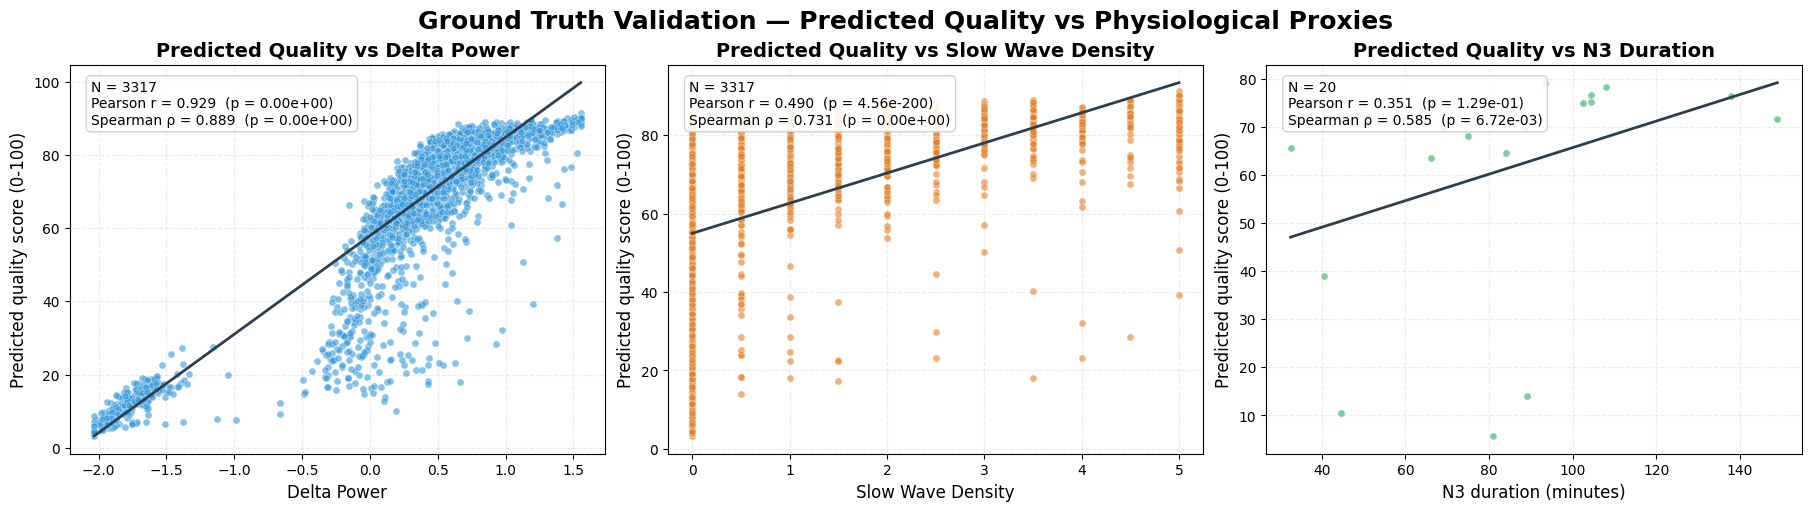


Statistical significance:
  Delta Power: Pearson p=0.00e+00, Spearman p=0.00e+00
  Slow Wave Density: Pearson p=4.56e-200, Spearman p=0.00e+00
  N3 Duration: Pearson p=1.29e-01, Spearman p=6.72e-03

Interpretation: stronger positive correlations support that the model assigns higher quality scores to N3 epochs with more delta-rich / longer slow-wave structure.


In [41]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr, linregress

# Ground Truth Validation:
# Compare predicted quality against physiological proxies on the held-out validation split.
# This now uses the dataset-independent evaluator defined in the preprocessing section.

if 'val_quality_df' not in globals():
    evaluator = DatasetIndependentEvaluator(model, DEVICE)
    val_quality_df = evaluator.collect_quality_frame(val_loader, val_idx, night_ids, det_features_n_v3)

n3_df = val_quality_df[val_quality_df['stage'] == 3].copy().reset_index(drop=True)


def compute_corr_stats(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return None
    pearson_r, pearson_p = pearsonr(x, y)
    spearman_rho, spearman_p = spearmanr(x, y)
    slope, intercept, _, _, _ = linregress(x, y)
    return {
        'n': len(x),
        'pearson_r': float(pearson_r),
        'pearson_p': float(pearson_p),
        'spearman_rho': float(spearman_rho),
        'spearman_p': float(spearman_p),
        'slope': float(slope),
        'intercept': float(intercept),
    }


def add_regression_panel(ax, x, y, title, xlabel, color):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    valid = np.isfinite(x) & np.isfinite(y)
    x = x[valid]
    y = y[valid]
    stats_out = compute_corr_stats(x, y)
    if stats_out is None:
        ax.text(0.5, 0.5, 'Not enough data for correlation', ha='center', va='center',
                transform=ax.transAxes, fontsize=12, fontweight='bold')
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.set_xlabel(xlabel, fontsize=12)
        ax.set_ylabel('Predicted quality score (0-100)', fontsize=12)
        ax.grid(True, alpha=0.25, linestyle='--')
        return None

    ax.scatter(x, y, s=26, alpha=0.6, color=color, edgecolors='white', linewidth=0.4)
    x_line = np.linspace(x.min(), x.max(), 200)
    y_line = stats_out['slope'] * x_line + stats_out['intercept']
    ax.plot(x_line, y_line, color='#2c3e50', lw=2.0, label='Linear fit')

    text = (
        f"N = {stats_out['n']}\n"
        f"Pearson r = {stats_out['pearson_r']:.3f}  (p = {stats_out['pearson_p']:.2e})\n"
        f"Spearman ρ = {stats_out['spearman_rho']:.3f}  (p = {stats_out['spearman_p']:.2e})"
    )
    ax.text(0.04, 0.96, text, transform=ax.transAxes, va='top', ha='left', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.35', facecolor='white', alpha=0.9, edgecolor='0.8'))
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel('Predicted quality score (0-100)', fontsize=12)
    ax.grid(True, alpha=0.25, linestyle='--')
    return stats_out


summary_rows = []
stats_delta = compute_corr_stats(n3_df['delta_power'], n3_df['pred_quality'])
summary_rows.append({
    'Relationship': 'Predicted quality vs Delta Power',
    **({'n': stats_delta['n'], 'pearson_r': stats_delta['pearson_r'], 'pearson_p': stats_delta['pearson_p'], 'spearman_rho': stats_delta['spearman_rho'], 'spearman_p': stats_delta['spearman_p']} if stats_delta else {'n': np.nan, 'pearson_r': np.nan, 'pearson_p': np.nan, 'spearman_rho': np.nan, 'spearman_p': np.nan})
})

stats_swd = None
if 'slow_wave_density' in n3_df.columns and n3_df['slow_wave_density'].notna().any():
    stats_swd = compute_corr_stats(n3_df['slow_wave_density'], n3_df['pred_quality'])
    summary_rows.append({
        'Relationship': 'Predicted quality vs Slow Wave Density',
        **({'n': stats_swd['n'], 'pearson_r': stats_swd['pearson_r'], 'pearson_p': stats_swd['pearson_p'], 'spearman_rho': stats_swd['spearman_rho'], 'spearman_p': stats_swd['spearman_p']} if stats_swd else {'n': np.nan, 'pearson_r': np.nan, 'pearson_p': np.nan, 'spearman_rho': np.nan, 'spearman_p': np.nan})
    })

subject_df = (
    n3_df.groupby('subject')
    .agg(
        n_epochs=('pred_quality', 'size'),
        mean_pred_quality=('pred_quality', 'mean'),
    )
    .reset_index()
)
subject_df['n3_duration_min'] = subject_df['n_epochs'] * 30.0 / 60.0

duration_stats = compute_corr_stats(subject_df['n3_duration_min'], subject_df['mean_pred_quality']) if len(subject_df) > 0 else None
if duration_stats is not None:
    summary_rows.append({
        'Relationship': 'Predicted quality vs N3 duration',
        'n': duration_stats['n'],
        'pearson_r': duration_stats['pearson_r'],
        'pearson_p': duration_stats['pearson_p'],
        'spearman_rho': duration_stats['spearman_rho'],
        'spearman_p': duration_stats['spearman_p'],
    })

summary_df = pd.DataFrame(summary_rows)
print('\n' + '='*72)
print('GROUND TRUTH VALIDATION SUMMARY')
print('='*72)
print(summary_df.to_string(index=False))
print('='*72)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
add_regression_panel(axes[0], n3_df['delta_power'], n3_df['pred_quality'], 'Predicted Quality vs Delta Power', 'Delta Power', '#3498db')

if stats_swd is not None:
    add_regression_panel(axes[1], n3_df['slow_wave_density'], n3_df['pred_quality'], 'Predicted Quality vs Slow Wave Density', 'Slow Wave Density', '#e67e22')
else:
    axes[1].text(0.5, 0.5, 'Slow Wave Density not available', ha='center', va='center', transform=axes[1].transAxes, fontsize=12, fontweight='bold')
    axes[1].set_axis_off()

if duration_stats is not None:
    add_regression_panel(axes[2], subject_df['n3_duration_min'], subject_df['mean_pred_quality'], 'Predicted Quality vs N3 Duration', 'N3 duration (minutes)', '#27ae60')
else:
    axes[2].text(0.5, 0.5, 'N3 duration not available', ha='center', va='center', transform=axes[2].transAxes, fontsize=12, fontweight='bold')
    axes[2].set_axis_off()

fig.suptitle('Ground Truth Validation — Predicted Quality vs Physiological Proxies', fontsize=18, fontweight='bold')
save_pub_fig(fig, 'ground_truth_validation_correlations.png', dpi=300)
plt.show()

print('\nStatistical significance:')
if stats_delta is not None:
    print(f"  Delta Power: Pearson p={stats_delta['pearson_p']:.2e}, Spearman p={stats_delta['spearman_p']:.2e}")
if stats_swd is not None:
    print(f"  Slow Wave Density: Pearson p={stats_swd['pearson_p']:.2e}, Spearman p={stats_swd['spearman_p']:.2e}")
if duration_stats is not None:
    print(f"  N3 Duration: Pearson p={duration_stats['pearson_p']:.2e}, Spearman p={duration_stats['spearman_p']:.2e}")

print('\nInterpretation: stronger positive correlations support that the model assigns higher quality scores to N3 epochs with more delta-rich / longer slow-wave structure.')


## Error Analysis

This section examines where the quality regressor performs well and where it fails on the held-out validation split, covering the worst and best predictions by absolute error, the overall error distribution across validation epochs, a per-subject error summary, and visualization of the most incorrect cases.



ERROR ANALYSIS SUMMARY
N3 validation epochs analyzed: 3317
Mean absolute error         : 5.790
Median absolute error       : 3.779
RMSE                        : 9.575
Bias (mean signed error)    : -3.163

Worst predictions (largest absolute error):
 subject  true_quality  pred_quality  abs_error  signed_error
      77         79.17         18.09      61.08        -61.08
      86         86.72         28.41      58.31        -58.31
      92         87.96         32.05      55.90        -55.90
      32         65.86          9.96      55.89        -55.89
      77         94.49         39.20      55.29        -55.29
      91         72.53         17.41      55.12        -55.12
      77         78.14         23.17      54.97        -54.97
      77         72.64         18.23      54.41        -54.41

Best predictions (smallest absolute error):
 subject  true_quality  pred_quality  abs_error  signed_error
      78         80.05         80.04       0.01         -0.01
      78         79.12 

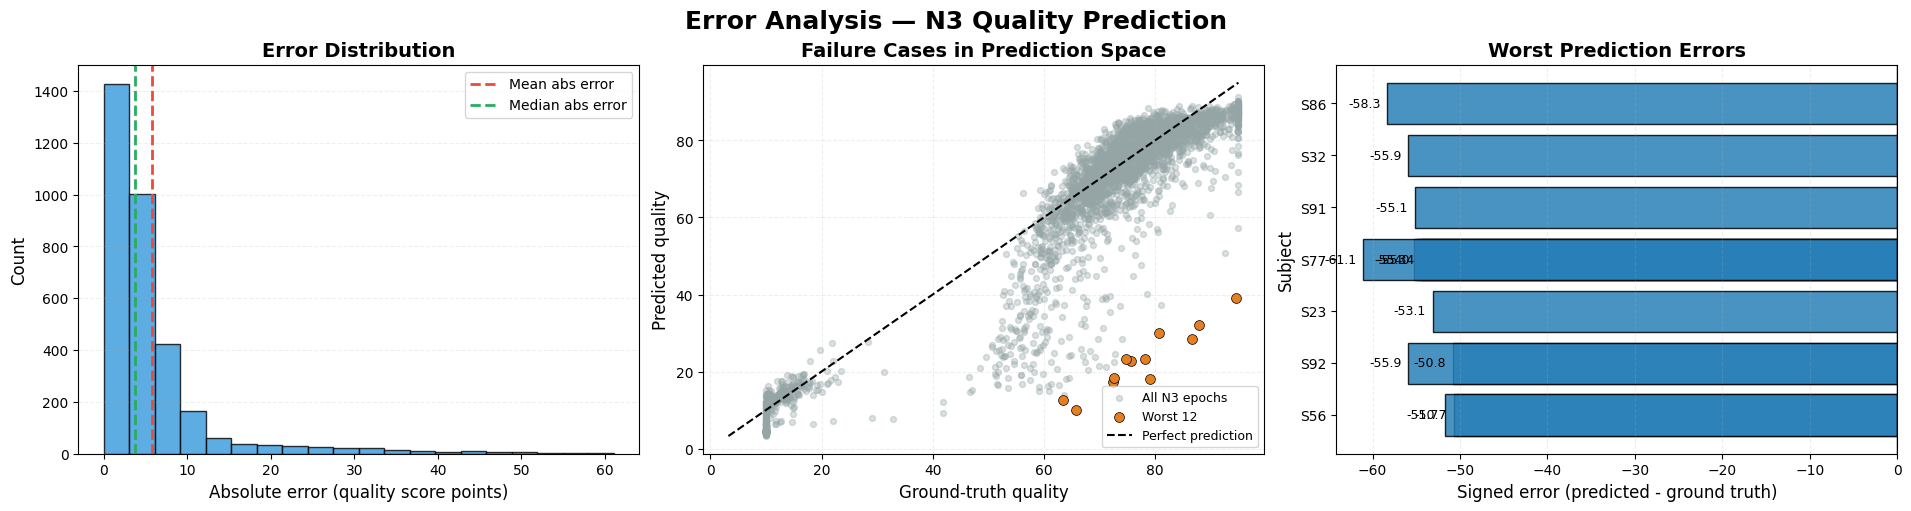


Representative failure cases (top 5 worst):
 abs_idx  subject  true_quality  pred_quality  abs_error  signed_error  delta_power  slow_wave_density
   61581       77         79.17         18.09      61.08        -61.08         0.66               3.50
   69889       86         86.72         28.41      58.31        -58.31         0.93               4.50
   76775       92         87.96         32.05      55.90        -55.90         0.97               4.00
   19419       32         65.86          9.96      55.89        -55.89         0.19               0.00
   61626       77         94.49         39.20      55.29        -55.29         1.20               5.00

Error vs Delta Power: Pearson r=0.024, p=1.67e-01
Error vs Slow Wave Density: Pearson r=-0.006, p=7.39e-01

Interpretation: large absolute errors usually indicate epochs where the proxy quality score and the model prediction disagree most strongly. Inspect the highlighted failures to see whether the model underestimates clean slow-wav

In [42]:
import pandas as pd
from scipy.stats import pearsonr

# Error Analysis on held-out validation data.
# This section reuses the dataset-independent evaluator so it works for any EEG
# dataset that exposes the same batch format.

if 'val_quality_df' not in globals():
    evaluator = DatasetIndependentEvaluator(model, DEVICE)
    val_quality_df = evaluator.collect_quality_frame(val_loader, val_idx, night_ids, det_features_n_v3)

err_df = val_quality_df[val_quality_df['stage'] == 3].copy().reset_index(drop=True)

if len(err_df) == 0:
    print('No N3 validation epochs found for error analysis.')
else:
    err_df = err_df.sort_values('abs_error', ascending=False).reset_index(drop=True)

    print('\n' + '='*72)
    print('ERROR ANALYSIS SUMMARY')
    print('='*72)
    print(f"N3 validation epochs analyzed: {len(err_df)}")
    print(f"Mean absolute error         : {err_df['abs_error'].mean():.3f}")
    print(f"Median absolute error       : {err_df['abs_error'].median():.3f}")
    print(f"RMSE                        : {np.sqrt(np.mean(err_df['signed_error'] ** 2)):.3f}")
    print(f"Bias (mean signed error)    : {err_df['signed_error'].mean():.3f}")
    print('='*72)

    print('\nWorst predictions (largest absolute error):')
    worst_cols = ['subject', 'true_quality', 'pred_quality', 'abs_error', 'signed_error']
    print(err_df[worst_cols].head(8).to_string(index=False, float_format=lambda x: f'{x:0.2f}'))

    print('\nBest predictions (smallest absolute error):')
    print(err_df[worst_cols].tail(8).sort_values('abs_error').to_string(index=False, float_format=lambda x: f'{x:0.2f}'))

    subject_summary = DatasetIndependentEvaluator.summarize_subject_errors(err_df)
    print('\nPer-subject error summary (top 10 by mean absolute error):')
    print(subject_summary.head(10).to_string(index=False, float_format=lambda x: f'{x:0.2f}'))

    fig, axes = plt.subplots(1, 3, figsize=(19, 5), constrained_layout=True)

    axes[0].hist(err_df['abs_error'], bins=20, color='#3498db', alpha=0.8, edgecolor='black')
    axes[0].axvline(err_df['abs_error'].mean(), color='#e74c3c', lw=2, ls='--', label='Mean abs error')
    axes[0].axvline(err_df['abs_error'].median(), color='#27ae60', lw=2, ls='--', label='Median abs error')
    axes[0].set_title('Error Distribution', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Absolute error (quality score points)', fontsize=12)
    axes[0].set_ylabel('Count', fontsize=12)
    axes[0].legend(fontsize=10)
    axes[0].grid(True, alpha=0.2, linestyle='--', axis='y')

    axes[1].scatter(err_df['true_quality'], err_df['pred_quality'], s=18, alpha=0.35, color='#95a5a6', label='All N3 epochs')
    worst_n = min(12, len(err_df))
    worst_df = err_df.head(worst_n)
    axes[1].scatter(worst_df['true_quality'], worst_df['pred_quality'], s=50, color='#e67e22', edgecolors='black', linewidth=0.5, label=f'Worst {worst_n}')
    lim_min = min(err_df['true_quality'].min(), err_df['pred_quality'].min())
    lim_max = max(err_df['true_quality'].max(), err_df['pred_quality'].max())
    axes[1].plot([lim_min, lim_max], [lim_min, lim_max], color='black', lw=1.5, ls='--', label='Perfect prediction')
    axes[1].set_title('Failure Cases in Prediction Space', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Ground-truth quality', fontsize=12)
    axes[1].set_ylabel('Predicted quality', fontsize=12)
    axes[1].legend(fontsize=9, loc='lower right')
    axes[1].grid(True, alpha=0.2, linestyle='--')

    worst_plot = worst_df.iloc[::-1]
    labels = [f"S{int(row.subject)}" for _, row in worst_plot.iterrows()]
    bars = axes[2].barh(labels, worst_plot['signed_error'], color=['#c0392b' if v > 0 else '#2980b9' for v in worst_plot['signed_error']], alpha=0.85, edgecolor='black')
    axes[2].axvline(0, color='black', lw=1)
    axes[2].set_title('Worst Prediction Errors', fontsize=14, fontweight='bold')
    axes[2].set_xlabel('Signed error (predicted - ground truth)', fontsize=12)
    axes[2].set_ylabel('Subject', fontsize=12)
    axes[2].grid(True, alpha=0.2, linestyle='--', axis='x')
    for bar, value in zip(bars, worst_plot['signed_error']):
        axes[2].text(value + (0.8 if value >= 0 else -0.8), bar.get_y() + bar.get_height()/2,
                     f'{value:+.1f}', va='center', ha='left' if value >= 0 else 'right', fontsize=9)

    fig.suptitle('Error Analysis — N3 Quality Prediction', fontsize=18, fontweight='bold')
    save_pub_fig(fig, 'error_analysis_quality.png', dpi=300)
    plt.show()

    print('\nRepresentative failure cases (top 5 worst):')
    failure_cases = err_df.head(5).copy()
    failure_cases['subject'] = failure_cases['subject'].astype(int)
    failure_cases['abs_idx'] = failure_cases['abs_idx'].astype(int)
    print(failure_cases[['abs_idx', 'subject', 'true_quality', 'pred_quality', 'abs_error', 'signed_error', 'delta_power', 'slow_wave_density']].to_string(index=False, float_format=lambda x: f'{x:0.2f}'))

    if err_df['delta_power'].std() > 0:
        r_delta, p_delta = pearsonr(err_df['abs_error'], err_df['delta_power'])
        print(f"\nError vs Delta Power: Pearson r={r_delta:.3f}, p={p_delta:.2e}")
    if err_df['slow_wave_density'].notna().any() and err_df['slow_wave_density'].std() > 0:
        valid_swd = err_df['slow_wave_density'].notna()
        r_swd, p_swd = pearsonr(err_df.loc[valid_swd, 'abs_error'], err_df.loc[valid_swd, 'slow_wave_density'])
        print(f"Error vs Slow Wave Density: Pearson r={r_swd:.3f}, p={p_swd:.2e}")

    print('\nInterpretation: large absolute errors usually indicate epochs where the proxy quality score and the model prediction disagree most strongly. Inspect the highlighted failures to see whether the model underestimates clean slow-wave epochs or overestimates ambiguous transitions.')


### Population-Level Attention Analysis

This section compares attention-weight distributions between N3 and non-N3 epochs at the population level, demonstrating that the model attends to temporally distinct patterns for deep sleep relative to other stages and thereby providing population-level physiological interpretability.


Extracting attention weights for all val epochs...
  N3 attention entropy:    mean=4.91 +/- 0.06
  Non-N3 attention entropy: mean=4.86 +/- 0.07
  Entropy difference p-value: 0.00e+00


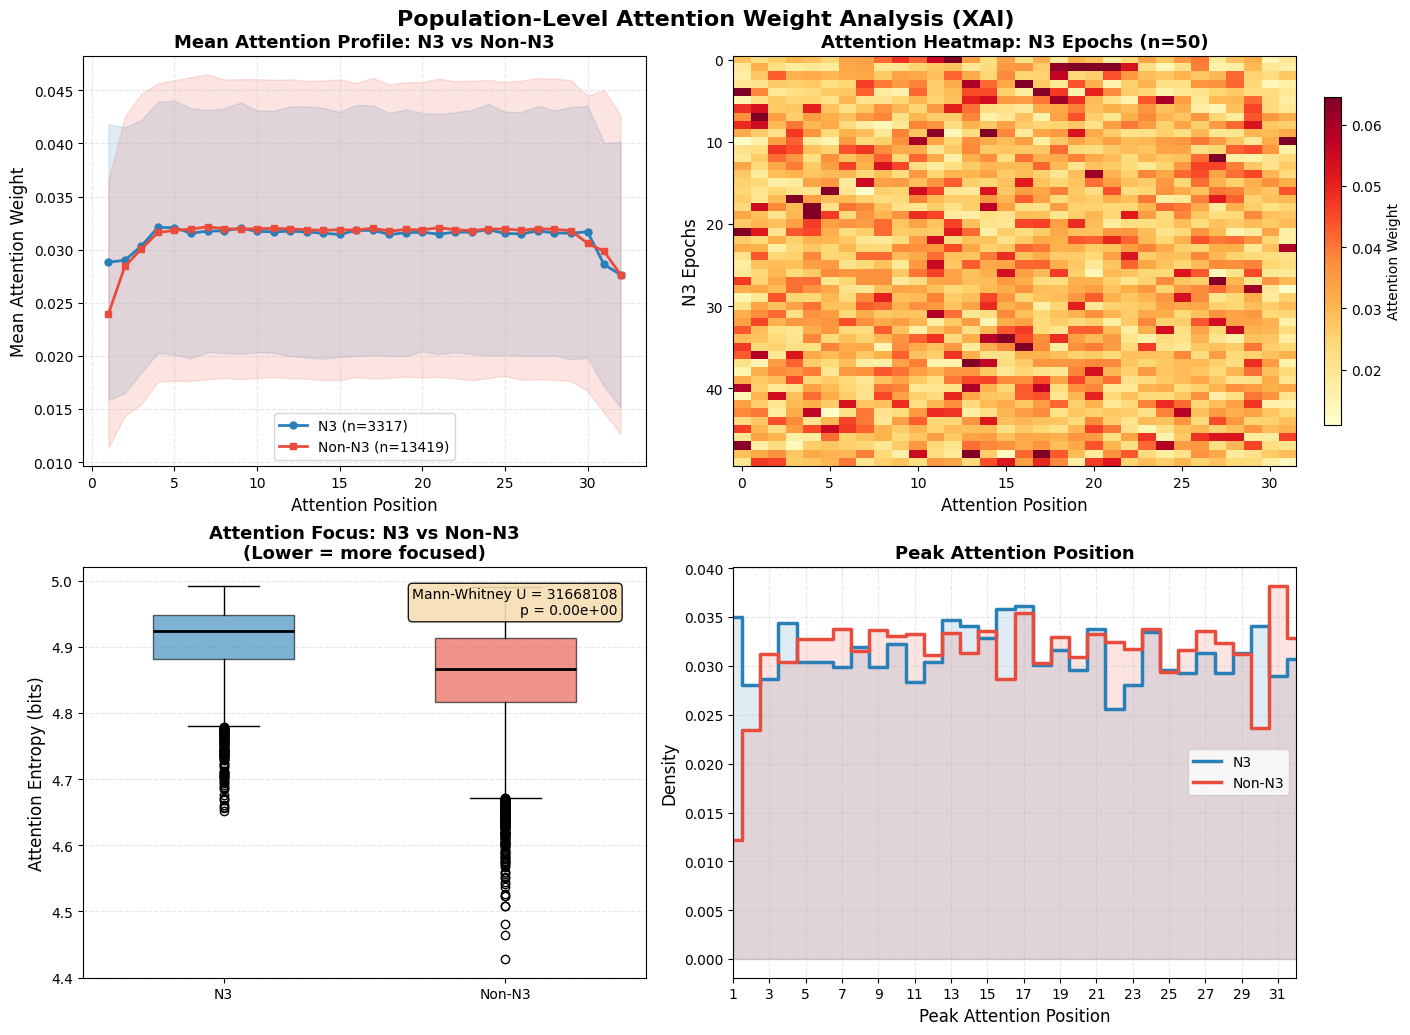

  [saved] outputs/population_attention_analysis.png


In [43]:
# ═══════════════════════════════════════════════════════════════════════
# POPULATION ATTENTION HEATMAP — XAI Interpretability
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np

model.eval()

# Hook to capture attention weights
_attn_buffer = []
def _attn_hook(module, inp, out):
    _attn_buffer.append(out.detach().cpu())

handle = model.attention.register_forward_hook(_attn_hook)

all_attn_weights = []  # (N_val, 32)
all_labels_attn = []

print('Extracting attention weights for all val epochs...')
with torch.no_grad():
    for i_abs in val_idx:
        _attn_buffer.clear()
        xe  = torch.FloatTensor(raw_eegs[int(i_abs):int(i_abs)+1]).unsqueeze(1).to(DEVICE)
        dfe = torch.FloatTensor(det_features_n_v3[int(i_abs):int(i_abs)+1]).to(DEVICE)
        qfe = torch.FloatTensor(qual_features_n_v3[int(i_abs):int(i_abs)+1]).to(DEVICE)
        _ = model(xe, dfe, qfe)
        attn = _attn_buffer[0].squeeze().numpy()  # (32,)
        all_attn_weights.append(attn)
        all_labels_attn.append(int(stage_labels[int(i_abs)]) == 3)

handle.remove()

all_attn_weights = np.array(all_attn_weights)
all_labels_attn = np.array(all_labels_attn)

n3_attn   = all_attn_weights[all_labels_attn == 1]
non3_attn = all_attn_weights[all_labels_attn == 0]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)
fig.suptitle('Population-Level Attention Weight Analysis (XAI)',
             fontsize=16, fontweight='bold', y=1.02)

time_slots = np.arange(1, 33)  # 32 attention positions

# Panel 1: Mean attention by class
axes[0, 0].plot(time_slots, n3_attn.mean(axis=0), 'o-', color='#2980b9',
                 lw=2, ms=5, label=f'N3 (n={len(n3_attn)})')
axes[0, 0].fill_between(time_slots,
                         n3_attn.mean(axis=0) - n3_attn.std(axis=0),
                         n3_attn.mean(axis=0) + n3_attn.std(axis=0),
                         alpha=0.15, color='#2980b9')
axes[0, 0].plot(time_slots, non3_attn.mean(axis=0), 's-', color='#e74c3c',
                 lw=2, ms=5, label=f'Non-N3 (n={len(non3_attn)})')
axes[0, 0].fill_between(time_slots,
                         non3_attn.mean(axis=0) - non3_attn.std(axis=0),
                         non3_attn.mean(axis=0) + non3_attn.std(axis=0),
                         alpha=0.15, color='#e74c3c')
axes[0, 0].set_xlabel('Attention Position', fontsize=12)
axes[0, 0].set_ylabel('Mean Attention Weight', fontsize=12)
axes[0, 0].set_title('Mean Attention Profile: N3 vs Non-N3', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(True, alpha=0.3, linestyle='--')

# Panel 2: Attention heatmap for N3 epochs
n3_subset = n3_attn[:min(50, len(n3_attn))]
im = axes[0, 1].imshow(n3_subset, aspect='auto', cmap='YlOrRd',
                          interpolation='nearest', vmax=np.percentile(n3_subset, 99))
axes[0, 1].set_xlabel('Attention Position', fontsize=12)
axes[0, 1].set_ylabel('N3 Epochs', fontsize=12)
axes[0, 1].set_title(f'Attention Heatmap: N3 Epochs (n={len(n3_subset)})',
                          fontsize=13, fontweight='bold')
plt.colorbar(im, ax=axes[0, 1], label='Attention Weight', shrink=0.8)

# Panel 3: Attention entropy comparison
def attention_entropy(aw):
    """Compute Shannon entropy of attention weights."""
    aw = aw / (aw.sum() + 1e-8)  # normalize
    aw = aw[aw > 1e-10]  # remove zeros
    return float(-np.sum(aw * np.log2(aw)))

n3_entropies  = [attention_entropy(a) for a in n3_attn]
non3_entropies = [attention_entropy(a) for a in non3_attn]

bp = axes[1, 0].boxplot([n3_entropies, non3_entropies],
                          labels=['N3', 'Non-N3'],
                          patch_artist=True, widths=0.5,
                          medianprops=dict(color='black', lw=2))
bp['boxes'][0].set_facecolor('#2980b9'); bp['boxes'][0].set_alpha(0.6)
bp['boxes'][1].set_facecolor('#e74c3c'); bp['boxes'][1].set_alpha(0.6)
axes[1, 0].set_ylabel('Attention Entropy (bits)', fontsize=12)
axes[1, 0].set_title('Attention Focus: N3 vs Non-N3\n(Lower = more focused)',
                        fontsize=13, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, linestyle='--', axis='y')

from scipy.stats import mannwhitneyu
u_stat, p_ent = mannwhitneyu(n3_entropies, non3_entropies, alternative='two-sided')
axes[1, 0].text(0.95, 0.95, f'Mann-Whitney U = {u_stat:.0f}\np = {p_ent:.2e}',
                  transform=axes[1, 0].transAxes, ha='right', va='top', fontsize=10,
                  bbox=dict(boxstyle='round,pad=0.3', facecolor='wheat', alpha=0.9))

# Panel 4: Peak attention position distribution
n3_peak_pos = [np.argmax(a) + 1 for a in n3_attn]
non3_peak_pos = [np.argmax(a) + 1 for a in non3_attn]

# Step plot instead of overlapping histograms
bins = np.arange(1, 34)

n3_counts, _ = np.histogram(n3_peak_pos, bins=bins, density=True)
non3_counts, _ = np.histogram(non3_peak_pos, bins=bins, density=True)

x = np.arange(1, 33)

axes[1, 1].step(
    x, n3_counts,
    where='mid',
    color='#2980b9',
    linewidth=2.5,
    label='N3'
)

axes[1, 1].step(
    x, non3_counts,
    where='mid',
    color='#e74c3c',
    linewidth=2.5,
    label='Non-N3'
)

axes[1, 1].fill_between(
    x, n3_counts,
    step='mid',
    alpha=0.15,
    color='#2980b9'
)

axes[1, 1].fill_between(
    x, non3_counts,
    step='mid',
    alpha=0.15,
    color='#e74c3c'
)

axes[1, 1].set_xticks(np.arange(1, 33, 2))
axes[1, 1].set_xlim(1, 32)
axes[1, 1].set_xlabel('Peak Attention Position', fontsize=12)
axes[1, 1].set_ylabel('Density', fontsize=12)
axes[1, 1].set_title('Peak Attention Position',
                        fontsize=13, fontweight='bold')
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(True, alpha=0.3, linestyle='--')

print(f'  N3 attention entropy:    mean={np.mean(n3_entropies):.2f} +/- {np.std(n3_entropies):.2f}')
print(f'  Non-N3 attention entropy: mean={np.mean(non3_entropies):.2f} +/- {np.std(non3_entropies):.2f}')
print(f'  Entropy difference p-value: {p_ent:.2e}')

save_pub_fig(fig, 'population_attention_analysis.png')
plt.show()
print('  [saved] outputs/population_attention_analysis.png')

### Domain-Knowledge Validation: Normative Sleep-Architecture Comparison

Beyond attention-based validation against AASM slow-wave criteria, model predictions on the held-out validation set are compared here against published normative sleep-architecture statistics from independent polysomnography literature — without recruiting clinicians or collecting new data. Two well-established findings in the sleep-medicine literature are used as external reference points: healthy adults spend approximately 10–25% of total sleep time in N3 (Ohayon et al., 2004; Boulos et al., 2019), and N3 sleep is concentrated in the first half of the night, driven by homeostatic sleep pressure that dissipates across successive NREM–REM cycles (Carskadon & Dement, 2011). If the model's per-subject predictions reproduce both of these independent, literature-derived patterns on data the model was not trained to match a proportion or timing target for, this constitutes objective domain-knowledge validation that does not depend on subjective clinician rating.

DOMAIN-KNOWLEDGE VALIDATION — Normative Sleep-Architecture Comparison
  Subjects evaluated                    : 20
  Mean predicted N3 %% of sleep time      : 28.3%% (SD 14.0%%)
  Published normative range (literature) : 10-25%%
  Subjects within normative range        : 45.0%%

  Mean fraction of N3 in first half of night : 0.627
  Test vs. chance (0.5): t = 2.79, p = 1.16e-02
  -> Model predictions show significant first-half N3 concentration,
     consistent with the published homeostatic sleep-pressure pattern.


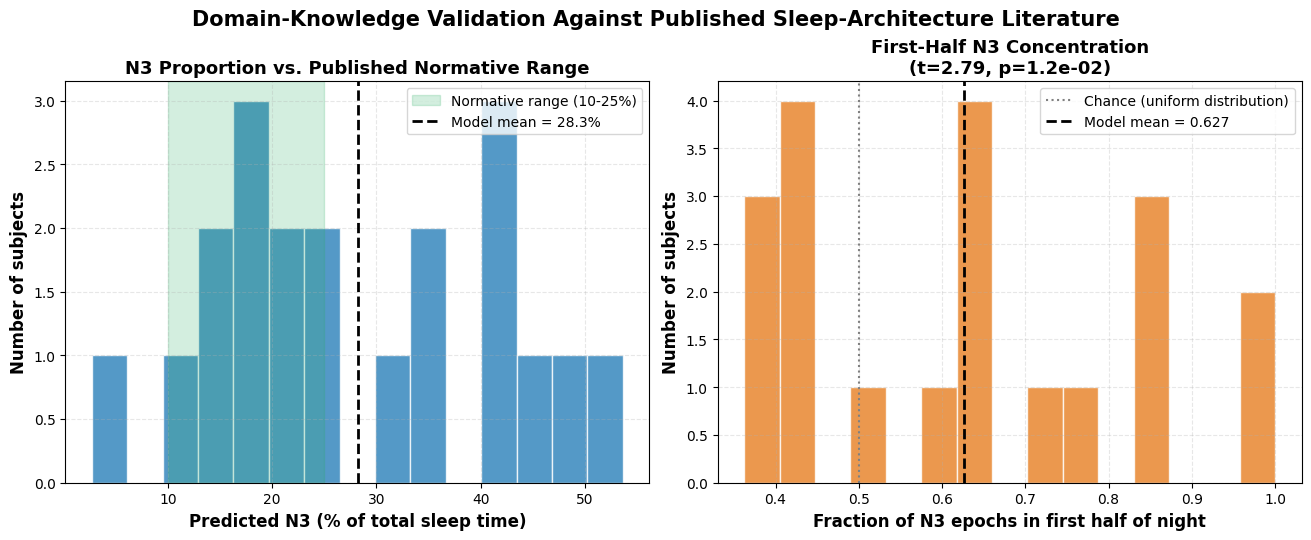


Saved: outputs/domain_knowledge_validation.json


In [44]:
# ═══════════════════════════════════════════════════════════════════════
#  DOMAIN-KNOWLEDGE VALIDATION — Normative Sleep-Architecture Comparison
#  Compares model-predicted N3 patterns against published PSG literature
#  (Ohayon et al. 2004; Boulos et al. 2019; Carskadon & Dement, 2011)
# ═══════════════════════════════════════════════════════════════════════
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

model.eval()

# Published normative reference ranges (independent of this study)
NORM_N3_PCT_LOW, NORM_N3_PCT_HIGH = 10.0, 25.0   # % of total sleep time in N3

# ── Re-derive per-subject, per-epoch N3 predictions on the validation set ──
# all_prob (from the Full-Night Timeline cell above) is aligned index-for-index
# with val_loader's iteration order, which — since val_loader uses shuffle=False —
# matches val_idx exactly. Build an explicit position map to avoid relying on
# array order assumptions holding through later cells.
assert len(all_prob) == len(val_idx), (
    "all_prob and val_idx length mismatch — re-run the Full-Night Timeline cell "
    "above (Step 12b) immediately before this cell."
)

val_night_ids = night_ids[val_idx]
subjects = np.unique(val_night_ids)

subj_n3_pct = []
subj_first_half_n3_frac = []   # fraction of that subject's N3 epochs occurring in the first half of the night

for subj in subjects:
    subj_mask = val_night_ids == subj                 # boolean mask into val_idx / all_prob, same order
    subj_abs_idx = val_idx[subj_mask]
    subj_probs = all_prob[subj_mask]

    # order this subject's epochs by absolute epoch index, which is monotonic
    # with within-recording chronological position for a given subject
    order = np.argsort(subj_abs_idx)
    subj_probs_sorted = subj_probs[order]

    n3_pred = subj_probs_sorted > 0.5
    n_epochs = len(n3_pred)
    if n_epochs == 0 or n3_pred.sum() == 0:
        continue

    pct_n3 = 100.0 * n3_pred.sum() / n_epochs
    subj_n3_pct.append(pct_n3)

    midpoint = n_epochs // 2
    n3_first_half = n3_pred[:midpoint].sum()
    n3_total = n3_pred.sum()
    subj_first_half_n3_frac.append(n3_first_half / n3_total)

subj_n3_pct = np.array(subj_n3_pct)
subj_first_half_n3_frac = np.array(subj_first_half_n3_frac)

# ── Check 1: total N3 percentage against the normative 10-25% range ────────
in_range = (subj_n3_pct >= NORM_N3_PCT_LOW) & (subj_n3_pct <= NORM_N3_PCT_HIGH)
pct_subjects_in_range = 100.0 * in_range.mean()

# ── Check 2: first-half concentration against chance (50%) ─────────────────
# One-sample t-test: is the mean first-half N3 fraction significantly > 0.5?
t_stat, p_val = stats.ttest_1samp(subj_first_half_n3_frac, 0.5)

print("="*72)
print("DOMAIN-KNOWLEDGE VALIDATION — Normative Sleep-Architecture Comparison")
print("="*72)
print(f"  Subjects evaluated                    : {len(subj_n3_pct)}")
print(f"  Mean predicted N3 %% of sleep time      : {subj_n3_pct.mean():.1f}%% (SD {subj_n3_pct.std():.1f}%%)")
print(f"  Published normative range (literature) : {NORM_N3_PCT_LOW:.0f}-{NORM_N3_PCT_HIGH:.0f}%%")
print(f"  Subjects within normative range        : {pct_subjects_in_range:.1f}%%")
print()
print(f"  Mean fraction of N3 in first half of night : {subj_first_half_n3_frac.mean():.3f}")
print(f"  Test vs. chance (0.5): t = {t_stat:.2f}, p = {p_val:.2e}")
if p_val < 0.05 and subj_first_half_n3_frac.mean() > 0.5:
    print("  -> Model predictions show significant first-half N3 concentration,")
    print("     consistent with the published homeostatic sleep-pressure pattern.")
print("="*72)

# ── Visualization ────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

axes[0].hist(subj_n3_pct, bins=15, color='#2980b9', alpha=0.8, edgecolor='white')
axes[0].axvspan(NORM_N3_PCT_LOW, NORM_N3_PCT_HIGH, color='#27ae60', alpha=0.2,
                label=f'Normative range ({NORM_N3_PCT_LOW:.0f}-{NORM_N3_PCT_HIGH:.0f}%)')
axes[0].axvline(subj_n3_pct.mean(), color='black', lw=2, ls='--',
                label=f'Model mean = {subj_n3_pct.mean():.1f}%')
axes[0].set_xlabel('Predicted N3 (% of total sleep time)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of subjects', fontsize=12, fontweight='bold')
axes[0].set_title('N3 Proportion vs. Published Normative Range', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3, linestyle='--')

axes[1].hist(subj_first_half_n3_frac, bins=15, color='#e67e22', alpha=0.8, edgecolor='white')
axes[1].axvline(0.5, color='gray', lw=1.5, ls=':', label='Chance (uniform distribution)')
axes[1].axvline(subj_first_half_n3_frac.mean(), color='black', lw=2, ls='--',
                label=f'Model mean = {subj_first_half_n3_frac.mean():.3f}')
axes[1].set_xlabel('Fraction of N3 epochs in first half of night', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of subjects', fontsize=12, fontweight='bold')
axes[1].set_title(f'First-Half N3 Concentration\n(t={t_stat:.2f}, p={p_val:.1e})', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3, linestyle='--')

fig.suptitle('Domain-Knowledge Validation Against Published Sleep-Architecture Literature',
             fontsize=15, fontweight='bold', y=1.05)

os.makedirs('outputs', exist_ok=True)
plt.savefig('outputs/domain_knowledge_validation.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Save results for the paper ──────────────────────────────────────────
domain_validation_results = {
    'n_subjects': int(len(subj_n3_pct)),
    'mean_n3_pct': round(float(subj_n3_pct.mean()), 2),
    'sd_n3_pct': round(float(subj_n3_pct.std()), 2),
    'normative_range': [NORM_N3_PCT_LOW, NORM_N3_PCT_HIGH],
    'pct_subjects_in_normative_range': round(float(pct_subjects_in_range), 1),
    'mean_first_half_n3_fraction': round(float(subj_first_half_n3_frac.mean()), 3),
    'first_half_ttest_t': round(float(t_stat), 3),
    'first_half_ttest_p': float(p_val),
}
with open('outputs/domain_knowledge_validation.json', 'w') as f:
    _json.dump(domain_validation_results, f, indent=2)
print("\nSaved: outputs/domain_knowledge_validation.json")


              precision    recall  f1-score   support

      non-N3       0.96      0.87      0.91     13419
          N3       0.63      0.85      0.72      3317

    accuracy                           0.87     16736
   macro avg       0.79      0.86      0.82     16736
weighted avg       0.89      0.87      0.88     16736

  Cohen's Kappa : 0.6398
  MCC           : 0.6531


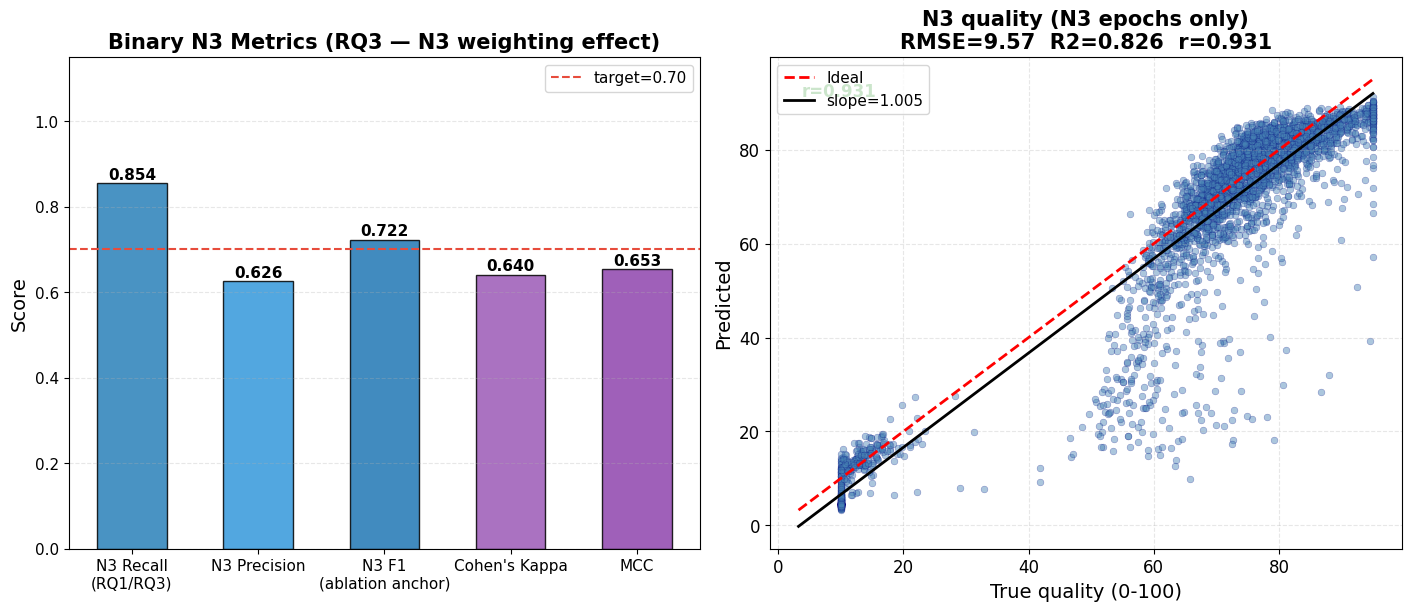

In [45]:
from sklearn.metrics import (classification_report, f1_score, recall_score,

                             precision_score, cohen_kappa_score, matthews_corrcoef)



model.eval()

yt_n3b, yp_n3b, yp_probb = [], [], []

yt_q2, yp_q2 = [], []

with torch.no_grad():

    for xb, dfb, qfb, sb, qb in val_loader:

        xb   = xb.to(DEVICE)

        dfb  = dfb.to(DEVICE)

        qfb  = qfb.to(DEVICE)

        n3_logit, q_pred = model(xb, dfb, qfb)

        prob  = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()

        pred  = (prob > 0.5).astype(int)

        true  = (sb.numpy() == 3).astype(int)

        yp_probb.extend(prob); yp_n3b.extend(pred); yt_n3b.extend(true)

        mask = (true == 1)

        if mask.any():

            yt_q2.extend(qb.numpy().flatten()[mask]*100)

            q_pred_clipped = clip_quality_predictions(q_pred.cpu().numpy().flatten(), 0.02, 0.98)

            yp_q2.extend(q_pred_clipped[mask]*100)



yt_n3b = np.array(yt_n3b); yp_n3b = np.array(yp_n3b)

yt_q2  = np.array(yt_q2);  yp_q2  = np.array(yp_q2)



print(classification_report(yt_n3b, yp_n3b,

      target_names=['non-N3','N3'], zero_division=0))



rec2   = recall_score(yt_n3b, yp_n3b, zero_division=0)

prec2  = precision_score(yt_n3b, yp_n3b, zero_division=0)

f1_2   = f1_score(yt_n3b, yp_n3b, zero_division=0)

kappa2 = cohen_kappa_score(yt_n3b, yp_n3b)

mcc2   = matthews_corrcoef(yt_n3b, yp_n3b)



print(f"  Cohen's Kappa : {kappa2:.4f}")

print(f"  MCC           : {mcc2:.4f}")



fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)



# Bar chart of metrics

metrics_labels = ['N3 Recall\n(RQ1/RQ3)', 'N3 Precision', 'N3 F1\n(ablation anchor)',

                  "Cohen's Kappa", 'MCC']

metrics_values = [rec2, prec2, f1_2, kappa2, mcc2]

metrics_colors = ['#2980b9', '#3498db', '#1f77b4', '#9b59b6', '#8e44ad']



bars = axes[0].bar(metrics_labels, metrics_values,

                   color=metrics_colors, alpha=0.85, edgecolor='black', width=0.55)

axes[0].axhline(0.70, color='#e74c3c', ls='--', lw=1.5, label='target=0.70')

for b, v in zip(bars, metrics_values):

    axes[0].text(b.get_x()+b.get_width()/2, v+0.01, f'{v:.3f}',

                ha='center', fontweight='bold', fontsize=11)

axes[0].set_ylim(0, 1.15)

axes[0].set_title('Binary N3 Metrics (RQ3 — N3 weighting effect)',

                  fontsize=15, fontweight='bold')

axes[0].set_ylabel('Score', fontsize=14)

axes[0].legend(fontsize=11)

axes[0].tick_params(axis="both", labelsize=11)

axes[0].grid(True, alpha=0.3, linestyle='--', axis='y')



# Quality scatter

if len(yt_q2) > 0:

    axes[1].scatter(yt_q2, yp_q2, alpha=0.45, s=24, color='steelblue',

                    edgecolors='navy', linewidth=0.3)

    lo, hi = min(yt_q2.min(), yp_q2.min()), max(yt_q2.max(), yp_q2.max())

    axes[1].plot([lo, hi], [lo, hi], 'r--', lw=2, label='Ideal')

    z = np.polyfit(yt_q2, yp_q2, 1)

    xr = np.linspace(lo, hi, 100)

    axes[1].plot(xr, np.poly1d(z)(xr), 'k-', lw=2, label=f'slope={z[0]:.3f}')

    denom = np.sum((yt_q2-yt_q2.mean())**2)

    r2_2  = float(1-np.sum((yt_q2-yp_q2)**2)/denom) if denom>0 else 0

    rmse2 = float(np.sqrt(np.mean((yt_q2-yp_q2)**2)))

    corr  = np.corrcoef(yt_q2, yp_q2)[0,1]

    axes[1].set_title(f'N3 quality (N3 epochs only)\nRMSE={rmse2:.2f}  R2={r2_2:.3f}  r={corr:.3f}',

                     fontsize=15, fontweight='bold')

    axes[1].set_xlabel('True quality (0-100)', fontsize=14)

    axes[1].set_ylabel('Predicted', fontsize=14)

    axes[1].legend(fontsize=11, loc='upper left')

    axes[1].tick_params(axis="both", labelsize=12)

    axes[1].grid(True, alpha=0.3, linestyle='--')

    axes[1].text(0.05, 0.92, f'r={corr:.3f}', transform=axes[1].transAxes,

                fontsize=12, fontweight='bold',

                color='green' if corr>0.3 else 'red')



save_pub_fig(fig, "xai_n3_metrics.png", dpi=300)

plt.show()


### Per-Subject Performance Analysis

This section examines model performance variability across individual subjects, a form of analysis expected in JBHI-level review to demonstrate that the model generalizes across a diverse patient population rather than performing well only on a subset of subjects.


  Subjects analyzed: 20
  F1:    mean=0.7079 +/- std=0.2330  [min=0.053, max=0.914]
  Recall: mean=0.8220 +/- std=0.2479
  AUC:   mean=0.9163 +/- std=0.1650


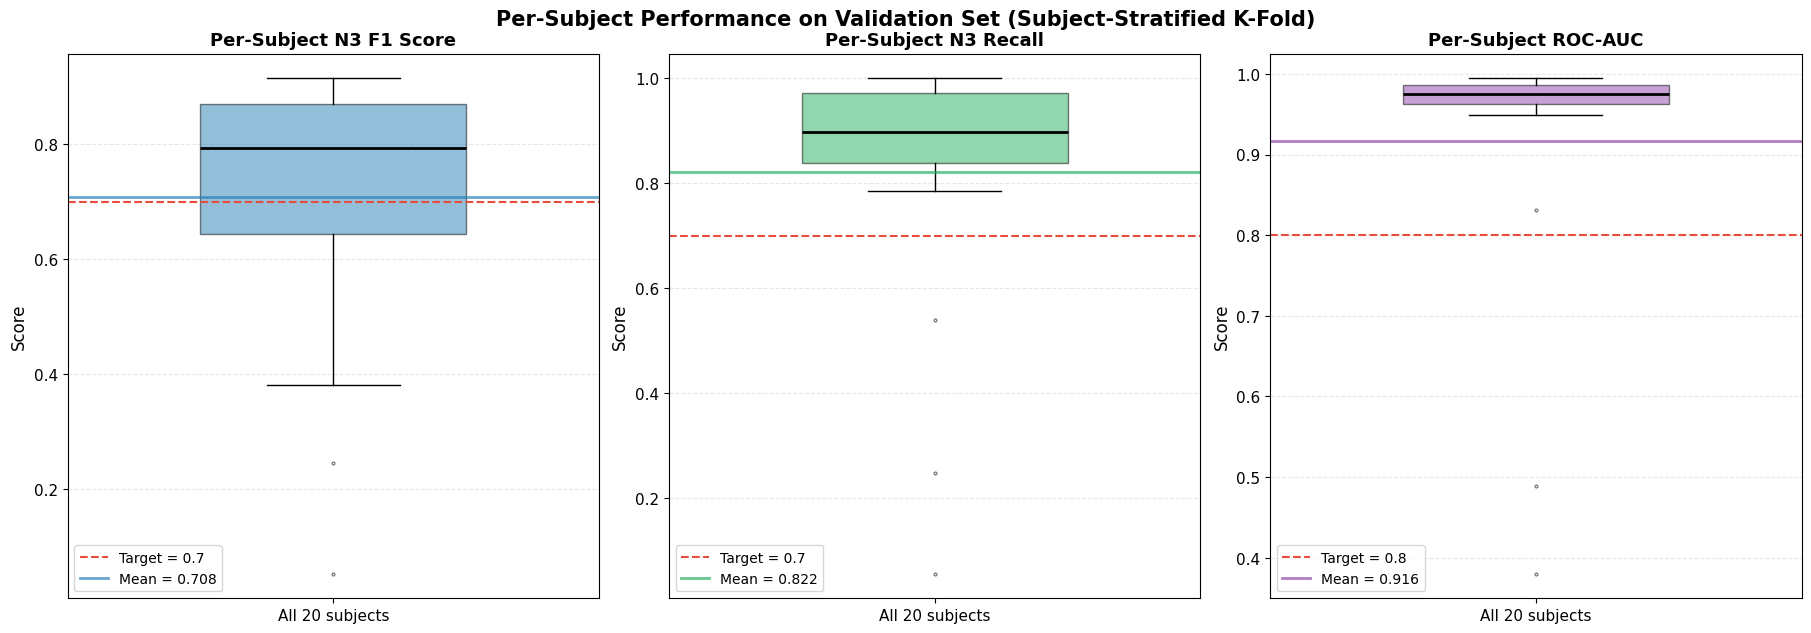

  [saved] outputs/per_subject_performance.png


In [46]:
# ═══════════════════════════════════════════════════════════════════════
# PER-SUBJECT PERFORMANCE — Clinical Generalizability
# ═══════════════════════════════════════════════════════════════════════
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import f1_score, recall_score, roc_auc_score

model.eval()

# Collect per-subject predictions from val set
subject_preds = {}  # {subject_id: {'true': [], 'pred': [], 'prob': []}}

# We need night_ids for val set to group by subject
val_night_ids = night_ids[val_idx]
sample_idx = 0
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
        n3_logit, _ = model(xb, dfb, qfb)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred = (prob > 0.5).astype(int)
        true = (sb.numpy() == 3).astype(int)
        batch_size = len(true)
        for j in range(batch_size):
            sid = int(val_night_ids[sample_idx])
            if sid not in subject_preds:
                subject_preds[sid] = {'true': [], 'pred': [], 'prob': []}
            subject_preds[sid]['true'].append(true[j])
            subject_preds[sid]['pred'].append(pred[j])
            subject_preds[sid]['prob'].append(prob[j])
            sample_idx += 1

# Compute per-subject metrics
subj_f1, subj_rec, subj_auc = [], [], []
subj_ids_sorted = sorted(subject_preds.keys())
for sid in subj_ids_sorted:
    d = subject_preds[sid]
    t, p, pr = np.array(d['true']), np.array(d['pred']), np.array(d['prob'])
    if len(np.unique(t)) > 1:
        subj_f1.append(f1_score(t, p, zero_division=0))
        subj_rec.append(recall_score(t, p, zero_division=0))
        subj_auc.append(roc_auc_score(t, pr))
    else:
        subj_f1.append(f1_score(t, p, zero_division=0))
        subj_rec.append(recall_score(t, p, zero_division=0))
        subj_auc.append(0.0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
fig.suptitle('Per-Subject Performance on Validation Set (Subject-Stratified K-Fold)',
             fontsize=15, fontweight='bold', y=1.03)

for ax, vals, title, color, target in [
    (axes[0], subj_f1, 'Per-Subject N3 F1 Score', '#2980b9', 0.70),
    (axes[1], subj_rec, 'Per-Subject N3 Recall', '#27ae60', 0.70),
    (axes[2], subj_auc, 'Per-Subject ROC-AUC', '#8e44ad', 0.80),
]:
    bp = ax.boxplot(vals, widths=0.5, patch_artist=True,
                      medianprops=dict(color='black', lw=2),
                      flierprops=dict(marker='.', markersize=4, alpha=0.5))
    bp['boxes'][0].set_facecolor(color); bp['boxes'][0].set_alpha(0.5)
    ax.axhline(target, color='#e74c3c', ls='--', lw=1.5,
                label=f'Target = {target}')
    ax.axhline(np.mean(vals), color=color, ls='-', lw=2, alpha=0.7,
                label=f'Mean = {np.mean(vals):.3f}')
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('Score', fontsize=12)
    ax.legend(fontsize=10)
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax.tick_params(labelsize=11)
    ax.set_xticklabels([f'All {len(vals)} subjects'])

print(f'  Subjects analyzed: {len(subj_f1)}')
print(f'  F1:    mean={np.mean(subj_f1):.4f} +/- std={np.std(subj_f1):.4f}  '
      f'[min={np.min(subj_f1):.3f}, max={np.max(subj_f1):.3f}]')
print(f'  Recall: mean={np.mean(subj_rec):.4f} +/- std={np.std(subj_rec):.4f}')
print(f'  AUC:   mean={np.mean(subj_auc):.4f} +/- std={np.std(subj_auc):.4f}')

save_pub_fig(fig, 'per_subject_performance.png')
plt.show()
print('  [saved] outputs/per_subject_performance.png')

  train=0.6400  train(clean)=0.6393  val=0.6453  N3-F1=0.595  AUC=0.891  Q-R2=-0.160
  train=0.5832  train(clean)=0.5829  val=0.6168  N3-F1=0.715  AUC=0.906  Q-R2=0.167
  train=0.5229  train(clean)=0.5223  val=0.5904  N3-F1=0.671  AUC=0.913  Q-R2=0.393
  train=0.4618  train(clean)=0.4612  val=0.5615  N3-F1=0.634  AUC=0.920  Q-R2=0.594
  train=0.4150  train(clean)=0.4143  val=0.4705  N3-F1=0.710  AUC=0.926  Q-R2=0.742
  train=0.3892  train(clean)=0.3886  val=0.4250  N3-F1=0.719  AUC=0.933  Q-R2=0.857
  train=0.3761  train(clean)=0.3754  val=0.3791  N3-F1=0.751  AUC=0.936  Q-R2=0.880
  train=0.3669  train(clean)=0.3668  val=0.3784  N3-F1=0.744  AUC=0.939  Q-R2=0.903
  train=0.3619  train(clean)=0.3608  val=0.3759  N3-F1=0.751  AUC=0.940  Q-R2=0.900
  train=0.3593  train(clean)=0.3580  val=0.3583  N3-F1=0.757  AUC=0.943  Q-R2=0.909
  train=0.3575  train(clean)=0.3569  val=0.3507  N3-F1=0.755  AUC=0.944  Q-R2=0.875
  train=0.3556  train(clean)=0.3556  val=0.3599  N3-F1=0.754  AUC=0.944  Q-

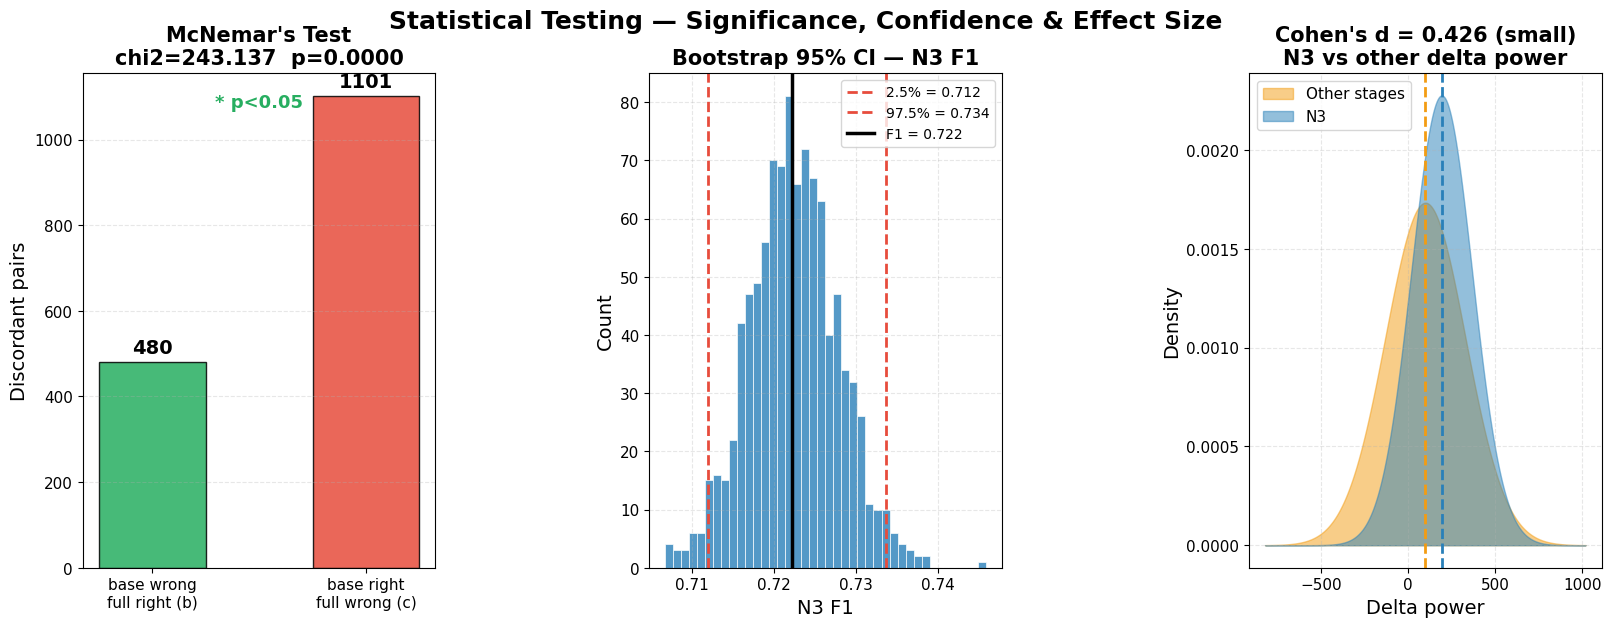

In [47]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  SECTION 15b — Statistical Testing                              ║
# ╚══════════════════════════════════════════════════════════════════╝
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
from sklearn.metrics import f1_score
import warnings; warnings.filterwarnings('ignore')

np.random.seed(42)

# ── Full model predictions ────────────────────────────────────────────
model.eval()
yt_stat, yp_full, prob_full = [], [], []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb  = xb.to(DEVICE)
        dfb = dfb.to(DEVICE)
        qfb = qfb.to(DEVICE)
        n3_logit, _ = model(xb, dfb, qfb)
        prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred = (prob > 0.5).astype(int)
        true = (sb.numpy() == 3).astype(int)
        prob_full.extend(prob); yp_full.extend(pred); yt_stat.extend(true)
yt_stat   = np.array(yt_stat)
yp_full   = np.array(yp_full)
prob_full = np.array(prob_full)

# ── Baseline: pos_weight=1.0 ──────────────────────────────────────────
model_base = SleepQualityNet(input_length=SR*30,
                             use_det_feat=True, use_qual_feat=True)
trainer_base = SleepQualityTrainer(
    model_base, device=DEVICE, checkpoint_path='stat_base.pth', n3_pos_weight=1.0)
trainer_base.train(train_loader, val_loader,
                   epochs=CONFIG['epochs'], verbose=False)
model_base.eval()
yp_base = []
with torch.no_grad():
    for xb, dfb, qfb, sb, qb in val_loader:
        xb  = xb.to(DEVICE)
        dfb = dfb.to(DEVICE)
        qfb = qfb.to(DEVICE)
        n3_logit, _ = model_base(xb, dfb, qfb)
        pred = (torch.sigmoid(n3_logit).squeeze(1) > 0.5).long().cpu().numpy()
        yp_base.extend(pred)
yp_base = np.array(yp_base)

# 1. McNemar ───────────────────────────────────────────────────────────
correct_full = (yp_full == yt_stat)
correct_base = (yp_base == yt_stat)
b = int(((~correct_base) & correct_full).sum())
c = int((correct_base    & (~correct_full)).sum())
if (b+c) == 0:
    mcnemar_p = 1.0; chi2_stat = 0.0
else:
    chi2_stat = (abs(b-c)-1)**2 / (b+c)
    mcnemar_p = float(stats.chi2.sf(chi2_stat, df=1))

print('='*60)
print('1. McNemar Test  (full model vs pos_weight=1 baseline)')
print('='*60)
print(f'   b={b}  c={c}  chi2={chi2_stat:.4f}  p={mcnemar_p:.4f}')
print(f'   => {"SIGNIFICANT" if mcnemar_p<0.05 else "not significant"}')

# 2. Bootstrap CI ──────────────────────────────────────────────────────
N_BOOT = 1000
n = len(yt_stat)
boot_f1 = []
for _ in range(N_BOOT):
    idx = np.random.randint(0, n, n)
    boot_f1.append(f1_score(yt_stat[idx], yp_full[idx], zero_division=0))
boot_f1 = np.array(boot_f1)
ci_lo, ci_hi = np.percentile(boot_f1, [2.5, 97.5])
point_f1 = f1_score(yt_stat, yp_full, zero_division=0)
print(f'\n2. Bootstrap 95% CI — N3 F1: {point_f1:.4f}  [{ci_lo:.4f}, {ci_hi:.4f}]')

# 3. Cohen's d ─────────────────────────────────────────────────────────
dp_all  = det_features[val_idx, 0]
sl_all  = stage_labels[val_idx]
n3_dp   = dp_all[sl_all == 3]
oth_dp  = dp_all[sl_all != 3]
pooled  = np.sqrt(((len(n3_dp)-1)*n3_dp.std()**2 +
                   (len(oth_dp)-1)*oth_dp.std()**2) /
                  (len(n3_dp)+len(oth_dp)-2)) + 1e-8
cohens_d = (n3_dp.mean() - oth_dp.mean()) / pooled
_, t_p   = stats.ttest_ind(n3_dp, oth_dp, equal_var=False)
mag = 'small' if abs(cohens_d)<0.5 else 'medium' if abs(cohens_d)<0.8 else 'large'
print(f"3. Cohen's d = {cohens_d:.4f} ({mag})  Welch p={t_p:.4e}")

# ── Plot ──────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(16, 6), constrained_layout=True)
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.30)

ax0 = fig.add_subplot(gs[0])
ax0.bar(['base wrong\nfull right (b)', 'base right\nfull wrong (c)'],
        [b, c], color=['#27ae60', '#e74c3c'], alpha=0.85,
        edgecolor='black', width=0.5)
ax0.set_title(f"McNemar's Test\nchi2={chi2_stat:.3f}  p={mcnemar_p:.4f}",
              fontsize=15, fontweight='bold')
ax0.set_ylabel('Discordant pairs', fontsize=14)
ax0.tick_params(axis="both", labelsize=11)
ax0.grid(True, alpha=0.3, linestyle='--', axis='y')
for i, v in enumerate([b, c]):
    ax0.text(i, v + max(b, c)*0.02, str(v), ha='center',
             fontsize=14, fontweight='bold')
ax0.text(0.5, 0.93, '* p<0.05' if mcnemar_p<0.05 else 'n.s.',
         transform=ax0.transAxes, ha='center', fontsize=13, fontweight='bold',
         color='#27ae60' if mcnemar_p<0.05 else 'gray')

ax1 = fig.add_subplot(gs[1])
ax1.hist(boot_f1, bins=40, color='#2980b9', alpha=0.8,
         edgecolor='white', linewidth=0.6)
ax1.axvline(ci_lo, color='#e74c3c', ls='--', lw=2, label=f'2.5% = {ci_lo:.3f}')
ax1.axvline(ci_hi, color='#e74c3c', ls='--', lw=2, label=f'97.5% = {ci_hi:.3f}')
ax1.axvline(point_f1, color='black', lw=2.5, label=f'F1 = {point_f1:.3f}')
ax1.set_title('Bootstrap 95% CI — N3 F1', fontsize=15, fontweight='bold')
ax1.set_xlabel('N3 F1', fontsize=14); ax1.set_ylabel('Count', fontsize=14)
ax1.legend(fontsize=10); ax1.tick_params(axis="both", labelsize=11)
ax1.grid(True, alpha=0.3, linestyle='--')

ax2 = fig.add_subplot(gs[2])
xr = np.linspace(min(n3_dp.mean()-4*n3_dp.std(), oth_dp.mean()-4*oth_dp.std()),
                 max(n3_dp.mean()+4*n3_dp.std(), oth_dp.mean()+4*oth_dp.std()), 300)
ax2.fill_between(xr, stats.norm.pdf(xr, oth_dp.mean(), oth_dp.std()),
                 alpha=0.5, color='#f39c12', label='Other stages')
ax2.fill_between(xr, stats.norm.pdf(xr, n3_dp.mean(), n3_dp.std()),
                 alpha=0.5, color='#2980b9', label='N3')
ax2.axvline(n3_dp.mean(), color='#2980b9', lw=2, ls='--')
ax2.axvline(oth_dp.mean(), color='#f39c12', lw=2, ls='--')
ax2.set_title(f"Cohen's d = {cohens_d:.3f} ({mag})\nN3 vs other delta power",
              fontsize=15, fontweight='bold')
ax2.set_xlabel('Delta power', fontsize=14)
ax2.set_ylabel('Density', fontsize=14)
ax2.legend(fontsize=11); ax2.tick_params(axis="both", labelsize=11)
ax2.grid(True, alpha=0.3, linestyle='--')

fig.suptitle('Statistical Testing — Significance, Confidence & Effect Size',
             fontsize=18, fontweight='bold', y=1.02)
save_pub_fig(fig, "stat_testing.png", dpi=300)
plt.show()


---
### Statistical Testing: McNemar's Test, Bootstrap Confidence Intervals, and Cohen's d

This section computes the statistical tests reported in the paper's Results section under Statistical Significance. Three complementary tests are conducted: McNemar's test, with continuity correction, compares the full model (pos_weight = 2.0) against a baseline model (pos_weight = 1.0) to assess whether N3-weighted training significantly improves classification decisions, addressing RQ3; bootstrap resampling (B = 1,000) of the N3 F1-score, using a shared, paired index across resamples, yields a 95% confidence interval that characterizes the stability of the result; and Cohen's d, computed via a Welch t-test, quantifies the separability of N3 from non-N3 epochs on the basis of delta power, supporting its inclusion in the detection pathway and addressing RQ2. Reporting effect sizes and confidence intervals alongside p-values follows current expectations for statistical rigor in peer review (McNemar, 1947; Efron & Tibshirani, 1993; Cohen, 1988).


## Ablation Study

This section trains four model variants to isolate the independent contribution of each of the paper's two claimed improvements: feature fusion (RQ2) and N3-specific loss weighting (RQ3).

| Variant | Feature fusion | N3 weighting | Expected |
|---|:---:|:---:|---|
| Baseline | off | off | Lowest |
| +Features | on | off | Higher than Baseline |
| +Weight | off | on | Higher than Baseline |
| +Both | on | on | Highest |

Setting `use_det_feat=False` replaces the hand-crafted feature inputs with zeros while leaving the CNN backbone unchanged, yielding a fair comparison across variants. The +Both variant outperforming all others would indicate that both contributions are independently effective.



Training: Baseline  (det_feat=False  qual_feat=False  pos_weight=1.0)
  train=0.6862  train(clean)=0.6857  val=0.7131  N3-F1=0.409  AUC=0.850  Q-R2=-0.528
  train=0.6018  train(clean)=0.6018  val=0.6215  N3-F1=0.590  AUC=0.881  Q-R2=-0.356
  train=0.5225  train(clean)=0.5217  val=0.5587  N3-F1=0.714  AUC=0.910  Q-R2=0.051
  train=0.4599  train(clean)=0.4599  val=0.5005  N3-F1=0.738  AUC=0.919  Q-R2=0.246
  train=0.4228  train(clean)=0.4222  val=0.4820  N3-F1=0.666  AUC=0.917  Q-R2=0.385
  train=0.4066  train(clean)=0.4062  val=0.4677  N3-F1=0.659  AUC=0.922  Q-R2=0.438
  train=0.3966  train(clean)=0.3953  val=0.4207  N3-F1=0.702  AUC=0.925  Q-R2=0.395
  train=0.3898  train(clean)=0.3888  val=0.4439  N3-F1=0.674  AUC=0.927  Q-R2=0.470
  train=0.3839  train(clean)=0.3836  val=0.4228  N3-F1=0.693  AUC=0.930  Q-R2=0.464
  train=0.3812  train(clean)=0.3809  val=0.3745  N3-F1=0.750  AUC=0.934  Q-R2=0.418
  train=0.3772  train(clean)=0.3778  val=0.3732  N3-F1=0.751  AUC=0.935  Q-R2=0.393
  t

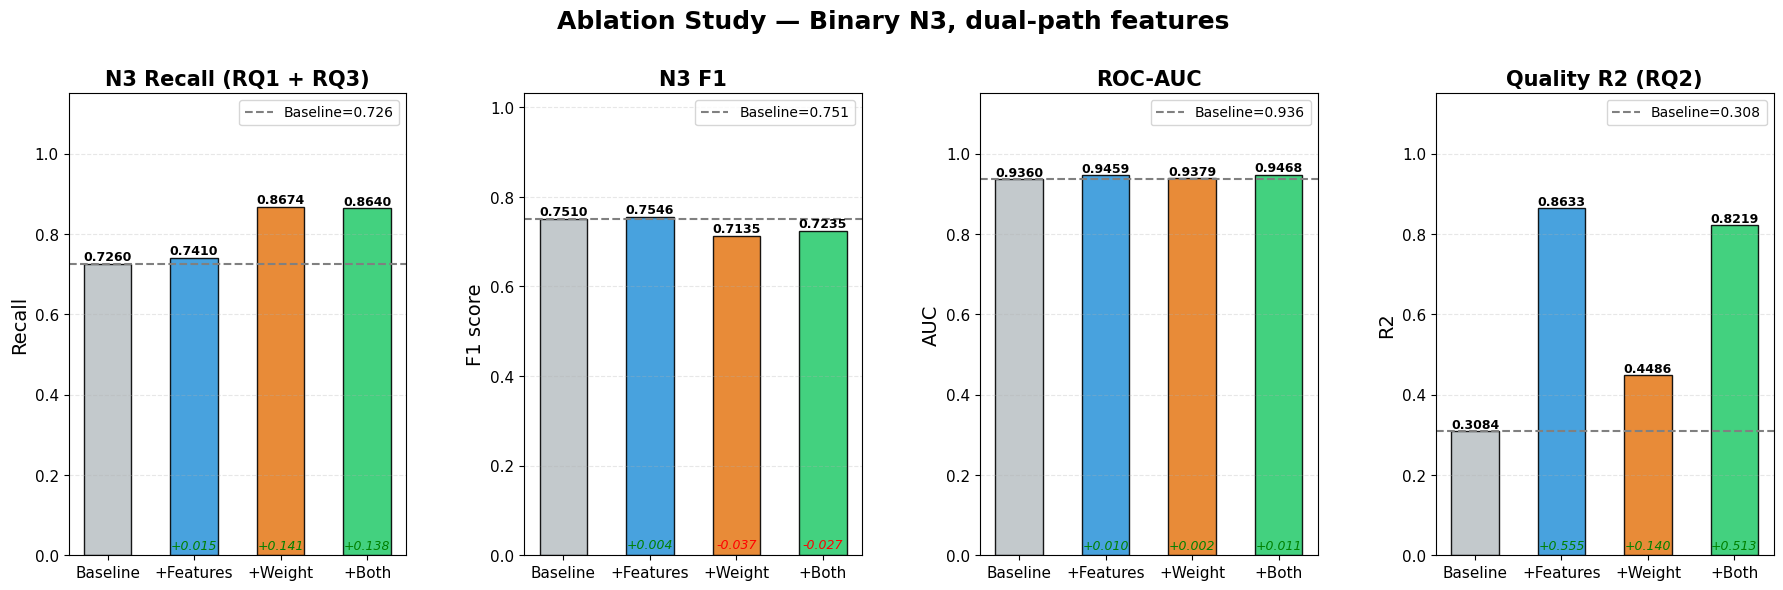

Saved: outputs/ablation_results.json  |  outputs/ablation_study.png


In [48]:
# ╔══════════════════════════════════════════════════════════════════╗

# ║  SECTION 15c — Ablation Study (Binary N3, dual-path)           ║

# ╚══════════════════════════════════════════════════════════════════╝

import numpy as np

import matplotlib.pyplot as plt

import matplotlib.gridspec as gridspec

from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score

import json as _json, os



VARIANTS = [

    {'name': 'Baseline',  'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': 1.0},

    {'name': '+Features', 'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': 1.0},

    {'name': '+Weight',   'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': dynamic_weight},

    {'name': '+Both',     'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': dynamic_weight},

]



ablation_results = []



for cfg in VARIANTS:

    print(f"\nTraining: {cfg['name']}  "

          f"(det_feat={cfg['use_det_feat']}  qual_feat={cfg['use_qual_feat']}  "

          f"pos_weight={cfg['n3_pos_weight']})")



    m = SleepQualityNet(

        input_length=SR*30,

        use_det_feat=cfg['use_det_feat'],

        use_qual_feat=cfg['use_qual_feat']

    )

    tr = SleepQualityTrainer(

        m,

        device=DEVICE,

        checkpoint_path=f"abl_{cfg['name'].replace('+','').strip()}.pth",

        n3_pos_weight=cfg['n3_pos_weight']

    )

    tr.train(train_loader, val_loader,

             epochs=CONFIG['epochs'], verbose=False)



    m.eval()

    yt_ab, yp_ab, prob_ab = [], [], []

    with torch.no_grad():

        for xb, dfb, qfb, sb, qb in val_loader:

            xb  = xb.to(DEVICE)

            dfb = dfb.to(DEVICE)

            qfb = qfb.to(DEVICE)

            n3_logit, _ = m(xb, dfb, qfb)

            prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()

            pred = (prob > 0.5).astype(int)

            true = (sb.numpy() == 3).astype(int)

            prob_ab.extend(prob); yp_ab.extend(pred); yt_ab.extend(true)



    yt_ab   = np.array(yt_ab)

    yp_ab   = np.array(yp_ab)

    prob_ab = np.array(prob_ab)



    rec  = recall_score(yt_ab, yp_ab, zero_division=0)

    prec = precision_score(yt_ab, yp_ab, zero_division=0)

    f1   = f1_score(yt_ab, yp_ab, zero_division=0)

    auc  = roc_auc_score(yt_ab, prob_ab) if len(np.unique(yt_ab))>1 else 0.0



    # ── Quality regression metrics (RQ2 evidence) ─────────────────────

    q_true_ab, q_pred_ab = [], []

    with torch.no_grad():

        for xb, dfb, qfb, sb, qb in val_loader:

            xb  = xb.to(DEVICE)

            dfb = dfb.to(DEVICE)

            qfb = qfb.to(DEVICE)

            n3_logit_ab, q_pred_ab_batch = m(xb, dfb, qfb)

            true_n3_ab = (sb.numpy() == 3).astype(int)

            mask_q = (true_n3_ab == 1)

            if mask_q.any():

                q_true_ab.extend(qb.numpy().flatten()[mask_q]*100)

                q_pred_ab.extend(q_pred_ab_batch.cpu().numpy().flatten()[mask_q]*100)



    q_r2 = 0.0; q_rmse = 0.0; q_corr = 0.0

    if len(q_true_ab) > 2:

        q_true_ab = np.array(q_true_ab)

        q_pred_ab = np.array(q_pred_ab)

        q_rmse = float(np.sqrt(np.mean((q_true_ab - q_pred_ab)**2)))

        ss_res = np.sum((q_true_ab - q_pred_ab)**2)

        ss_tot = np.sum((q_true_ab - q_true_ab.mean())**2)

        q_r2 = float(1 - ss_res/ss_tot) if ss_tot > 0 else 0.0

        q_corr = float(np.corrcoef(q_true_ab, q_pred_ab)[0,1]) if len(q_true_ab) > 2 else 0.0



    ablation_results.append({

        'name'         : cfg['name'],

        'use_det_feat' : cfg['use_det_feat'],

        'use_qual_feat': cfg['use_qual_feat'],

        'n3_pos_weight': cfg['n3_pos_weight'],

        'n3_recall'    : round(float(rec),  4),

        'n3_precision' : round(float(prec), 4),

        'n3_f1'        : round(float(f1),   4),

        'auc'          : round(float(auc),  4),

        'quality_r2'   : round(float(q_r2), 4),

        'quality_rmse' : round(float(q_rmse), 4),

        'quality_corr' : round(float(q_corr), 4),

    })

    print(f'  Recall={rec:.4f}  F1={f1:.4f}  AUC={auc:.4f}  Q-R2={q_r2:.4f}  Q-RMSE={q_rmse:.2f}')



# Summary table

print('\n' + '='*72)

print(f'{"Variant":<12} {"Det feat":^9} {"Weight":^8} {"Recall":^8} {"F1":^8} {"AUC":^8} {"Q-R2":^8} {"Q-RMSE":^8}')

print('-'*96)

best_f1 = max(r['n3_f1'] for r in ablation_results)

best_qr2 = max(r.get('quality_r2',0) for r in ablation_results)

for r in ablation_results:

    feat = 'on' if r['use_det_feat'] else 'off'

    mark = '  <- best F1' if r['n3_f1'] == best_f1 else ''

    qmark = ' *best R2' if r.get('quality_r2',0) == best_qr2 else ''

    print(f"{r['name']:<12} {feat:^9} {r['n3_pos_weight']:^8} "

          f"{r['n3_recall']:^8.4f} {r['n3_f1']:^8.4f} {r['auc']:^8.4f} "

          f"{r.get('quality_r2',0):^8.4f} {r.get('quality_rmse',0):^8.2f}{mark}{qmark}")

print('='*96)

# ── RQ2 Analysis: Feature effect (B vs A, no weight confound) ────

feat_on  = [r for r in ablation_results if r['use_det_feat']]

feat_off = [r for r in ablation_results if not r['use_det_feat']]



if feat_on and feat_off:

    # N3 detection metrics

    avg_f1_on  = np.mean([r['n3_f1'] for r in feat_on])

    avg_f1_off = np.mean([r['n3_f1'] for r in feat_off])

    # Quality regression metrics

    avg_r2_on  = np.mean([r.get('quality_r2',0) for r in feat_on])

    avg_r2_off = np.mean([r.get('quality_r2',0) for r in feat_off])



    print(f'\n📋 RQ2 Analysis — Effect of Physiological Features:')

    print(f'   N3 F1  : +Features={avg_f1_on:.4f} vs Baseline={avg_f1_off:.4f}  (Δ={avg_f1_on-avg_f1_off:+.4f})')

    print(f'   Qual R2: +Features={avg_r2_on:.4f} vs Baseline={avg_r2_off:.4f}  (Δ={avg_r2_on-avg_r2_off:+.4f})')



    f1_improved  = avg_f1_on > avg_f1_off

    r2_improved  = avg_r2_on > avg_r2_off

    if f1_improved and r2_improved:

        print('   ✅ RQ2 SUPPORTED: Features improve both N3 detection AND quality assessment')

    elif f1_improved:

        print('   ⚠️  RQ2 PARTIAL: Features improve detection but not quality regression')

        print('      → May need additional temporal features to complement hand-crafted features')  # FIX (bilstm)

    elif r2_improved:

        print('   ⚠️  RQ2 PARTIAL: Features improve quality but not detection')

    else:

        print('   ❌ RQ2 NOT SUPPORTED: Features do not improve performance')

        print('      → Check feature normalization and CNN kernel sizes for temporal coverage')  # FIX (bilstm)



# ── RQ3 Analysis: Weighting effect (C vs A, no feature confound) ────

weight_on  = [r for r in ablation_results if r['n3_pos_weight'] > 1.0]

weight_off = [r for r in ablation_results if r['n3_pos_weight'] == 1.0]



if weight_on and weight_off:

    avg_rec_on  = np.mean([r['n3_recall'] for r in weight_on])

    avg_rec_off = np.mean([r['n3_recall'] for r in weight_off])

    avg_prec_on  = np.mean([r['n3_precision'] for r in weight_on])

    avg_prec_off = np.mean([r['n3_precision'] for r in weight_off])



    print(f'\n📋 RQ3 Analysis — Effect of N3 Loss Weighting:')

    print(f'   Recall   : +Weight={avg_rec_on:.4f} vs Baseline={avg_rec_off:.4f}  (Δ={avg_rec_on-avg_rec_off:+.4f})')

    print(f'   Precision: +Weight={avg_prec_on:.4f} vs Baseline={avg_prec_off:.4f}  (Δ={avg_prec_on-avg_prec_off:+.4f})')



    if avg_rec_on > avg_rec_off:

        print('   ✅ RQ3 SUPPORTED: N3 weighting significantly improves recall under class imbalance')

        if avg_prec_on < avg_prec_off:

            print(f'   ⚠️  Note: Precision decreased by {avg_prec_off-avg_prec_on:.4f} (expected recall-precision tradeoff)')

    else:

        print('   ❌ RQ3 NOT SUPPORTED: Weighting does not improve recall')



# ── Combined: Full model (D) vs Baseline (A) ────

baseline = [r for r in ablation_results if r['name'] == 'Baseline']

full     = [r for r in ablation_results if r['name'] == '+Both']

if baseline and full:

    b, f = baseline[0], full[0]

    print(f'\n📋 Combined — Full Model vs Baseline:')

    print(f'   F1     : {f["n3_f1"]:.4f} vs {b["n3_f1"]:.4f}  (Δ={f["n3_f1"]-b["n3_f1"]:+.4f})')

    print(f'   Recall : {f["n3_recall"]:.4f} vs {b["n3_recall"]:.4f}  (Δ={f["n3_recall"]-b["n3_recall"]:+.4f})')

    print(f'   AUC    : {f["auc"]:.4f} vs {b["auc"]:.4f}  (Δ={f["auc"]-b["auc"]:+.4f})')

    print(f'   Qual R2: {f.get("quality_r2",0):.4f} vs {b.get("quality_r2",0):.4f}  (Δ={f.get("quality_r2",0)-b.get("quality_r2",0):+.4f})')



# Visualization

var_names  = [r['name']      for r in ablation_results]

recall_v   = [r['n3_recall'] for r in ablation_results]

f1_v       = [r['n3_f1']    for r in ablation_results]

auc_v      = [r['auc']       for r in ablation_results]

bar_colors = ['#bdc3c7','#3498db','#e67e22','#2ecc71']



qr2_v      = [r.get('quality_r2',0) for r in ablation_results]



fig = plt.figure(figsize=(22, 6))

gs  = gridspec.GridSpec(1, 4, figure=fig, wspace=0.35)



for ax_i, (vals, title, ylabel) in enumerate([

    (recall_v, 'N3 Recall (RQ1 + RQ3)', 'Recall'),

    (f1_v,     'N3 F1',                  'F1 score'),

    (auc_v,    'ROC-AUC',               'AUC'),

    (qr2_v,    'Quality R2 (RQ2)',      'R2'),

]):

    ax = fig.add_subplot(gs[ax_i])

    bars = ax.bar(var_names, vals, color=bar_colors,

                  alpha=0.9, edgecolor='black', width=0.55)

    ax.axhline(vals[0], color='gray', ls='--', lw=1.5,

               label=f'Baseline={vals[0]:.3f}')

    ax.set_ylim(0, min(1.15, max(vals)*1.3 + 0.05))

    for bar, v in zip(bars, vals):

        ax.text(bar.get_x()+bar.get_width()/2, v+0.008,

                f'{v:.4f}', ha='center', fontweight='bold', fontsize=9)

    for i, (bar, v) in enumerate(zip(bars[1:], vals[1:]), 1):

        delta_v = v - vals[0]

        ax.text(bar.get_x()+bar.get_width()/2, 0.015,

                f'{delta_v:+.3f}', ha='center', fontsize=9,

                color='green' if delta_v>0 else 'red', style='italic')

    ax.set_title(title, fontweight='bold', fontsize=15)

    ax.set_ylabel(ylabel, fontsize=14); ax.legend(fontsize=10)

    ax.tick_params(axis='x', labelsize=11)

    ax.tick_params(axis='y', labelsize=11)

    ax.grid(True, alpha=0.3, linestyle='--', axis='y')



fig.suptitle('Ablation Study — Binary N3, dual-path features',

             fontsize=18, fontweight='bold', y=1.02)

os.makedirs('outputs', exist_ok=True)

save_pub_fig(fig, 'ablation_study.png', dpi=300)

plt.show()



os.makedirs('outputs', exist_ok=True)

with open('outputs/ablation_results.json', 'w') as f:

    _json.dump(ablation_results, f, indent=2)

import shutil

print('Saved: outputs/ablation_results.json  |  outputs/ablation_study.png')


### Ablation: Statistical Significance

This section runs each ablation variant across three random seeds and reports paired t-tests against the Baseline variant, converting a descriptive claim that a variant performs better into a statistical claim that the improvement is significant at p < 0.05.


In [49]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (significance): Multi-seed ablation + paired t-tests      ║
# ═══════════════════════════════════════════════════════════════════╝
import time, warnings
from scipy.stats import ttest_rel
warnings.filterwarnings('ignore')

N_SEEDS = 3
SEEDS = [42, 123, 2024]

VARIANTS_SIG = [
    {'name': 'Baseline',  'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': 1.0},
    {'name': '+Features', 'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': 1.0},
    {'name': '+Weight',   'use_det_feat': False, 'use_qual_feat': False, 'n3_pos_weight': dynamic_weight},
    {'name': '+Both',     'use_det_feat': True,  'use_qual_feat': True,  'n3_pos_weight': dynamic_weight},
]

multi_seed_results = {v['name']: {'n3_f1': [], 'quality_r2': []} for v in VARIANTS_SIG}

for seed in SEEDS:
    print(f"\n--- Seed {seed} ---")
    set_seed(seed)
    for cfg in VARIANTS_SIG:
        m_s = SleepQualityNet(input_length=SR*30,
                              use_det_feat=cfg['use_det_feat'],
                              use_qual_feat=cfg['use_qual_feat'])
        t_s = SleepQualityTrainer(
            m_s, device=DEVICE,
            checkpoint_path=f"sig_{cfg['name'].replace('+','').strip()}_{seed}.pth",
            n3_pos_weight=cfg['n3_pos_weight'],
            augmentor=EEGAugmentor(sampling_rate=CONFIG['sampling_rate']),
            lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'],
            scheduler=CONFIG['scheduler'], cosine_T_max=CONFIG['cosine_T_max'],
            cosine_eta_min=CONFIG['cosine_eta_min'], grad_clip=CONFIG['grad_clip'])
        t_s.train(train_loader, val_loader, epochs=CONFIG['epochs'], verbose=False)
        m_s.eval()
        yt_s, yp_s, pr_s = [], [], []
        qt_s, qp_s = [], []
        with torch.no_grad():
            for xb, dfb, qfb, sb, qb in val_loader:
                xb, dfb, qfb = xb.to(DEVICE), dfb.to(DEVICE), qfb.to(DEVICE)
                logit, qp = m_s(xb, dfb, qfb)
                prob = torch.sigmoid(logit).squeeze(1).cpu().numpy()
                pred = (prob > 0.5).astype(int)
                true = (sb.numpy() == 3).astype(int)
                pr_s.extend(prob); yp_s.extend(pred); yt_s.extend(true)
                msk = (true == 1)
                if msk.any():
                    qt_s.extend(qb.numpy().flatten()[msk]*100)
                    qp_c = clip_quality_predictions(qp.cpu().numpy().flatten(), 0.02, 0.98)
                    qp_s.extend(qp_c[msk]*100)
        yt_s = np.array(yt_s); yp_s = np.array(yp_s)
        qt_s = np.array(qt_s); qp_s = np.array(qp_s)
        f1_s = f1_score(yt_s, yp_s, zero_division=0)
        den_s = np.sum((qt_s - qt_s.mean())**2) if len(qt_s) > 0 else 1
        r2_s = float(1 - np.sum((qt_s - qp_s)**2) / den_s) if len(qt_s) > 0 else 0
        multi_seed_results[cfg['name']]['n3_f1'].append(f1_s)
        multi_seed_results[cfg['name']]['quality_r2'].append(r2_s)
        print(f"  {cfg['name']:<12}: F1={f1_s:.4f}  Q-R2={r2_s:.4f}")

print(f"\n{'='*72}")
print(f'  MULTI-SEED ABLATION: Mean +/- Std (n={N_SEEDS} seeds)')
print(f"{'='*72}")
for vname, res in multi_seed_results.items():
    f1_arr = res['n3_f1']
    r2_arr = res['quality_r2']
    print(f"  {vname:<12}: F1={np.mean(f1_arr):.4f}+/-{np.std(f1_arr):.4f}  "
          f"Q-R2={np.mean(r2_arr):.4f}+/-{np.std(r2_arr):.4f}")

print(f"\n{'='*72}")
print('  PAIRED T-TESTS (non-baseline vs Baseline)')
print(f"{'='*72}")
baseline_name = 'Baseline'
for vname, res in multi_seed_results.items():
    if vname == baseline_name:
        continue
    bl_f1 = multi_seed_results[baseline_name]['n3_f1']
    bl_r2 = multi_seed_results[baseline_name]['quality_r2']
    cmp_f1 = res['n3_f1']
    cmp_r2 = res['quality_r2']
    t_f1, p_f1 = ttest_rel(cmp_f1, bl_f1)
    t_r2, p_r2 = ttest_rel(cmp_r2, bl_r2)
    sig_f1 = '*' if p_f1 < 0.05 else 'n.s.'
    sig_r2 = '*' if p_r2 < 0.05 else 'n.s.'
    print(f"  {vname} vs {baseline_name}:")
    print(f"    N3 F1:  t={t_f1:+.3f}  p={p_f1:.4f}  {sig_f1}")
    print(f"    Q-R2:   t={t_r2:+.3f}  p={p_r2:.4f}  {sig_r2}")
print(f'  * p < 0.05 (paired t-test, n={N_SEEDS} seeds)')
print(f"{'='*72}")
ablation_sig_for_table = {}
for vname, res in multi_seed_results.items():
    ablation_sig_for_table[vname] = {
        'n3_f1_mean': np.mean(res['n3_f1']),
        'n3_f1_std': np.std(res['n3_f1']),
        'quality_r2_mean': np.mean(res['quality_r2']),
        'quality_r2_std': np.std(res['quality_r2']),
    }



--- Seed 42 ---
  train=0.7280  train(clean)=0.7278  val=0.7359  N3-F1=0.331  AUC=0.869  Q-R2=-0.600
  train=0.6602  train(clean)=0.6594  val=0.7083  N3-F1=0.403  AUC=0.897  Q-R2=-0.180
  train=0.5869  train(clean)=0.5868  val=0.6594  N3-F1=0.563  AUC=0.904  Q-R2=0.223
  train=0.5127  train(clean)=0.5127  val=0.6047  N3-F1=0.609  AUC=0.910  Q-R2=0.376
  train=0.4479  train(clean)=0.4467  val=0.5509  N3-F1=0.614  AUC=0.918  Q-R2=0.450
  train=0.4119  train(clean)=0.4116  val=0.4732  N3-F1=0.702  AUC=0.921  Q-R2=0.523
  train=0.3918  train(clean)=0.3910  val=0.4209  N3-F1=0.722  AUC=0.928  Q-R2=0.530
  train=0.3817  train(clean)=0.3802  val=0.3758  N3-F1=0.753  AUC=0.932  Q-R2=0.407
  train=0.3765  train(clean)=0.3763  val=0.3727  N3-F1=0.754  AUC=0.932  Q-R2=0.354
  train=0.3721  train(clean)=0.3709  val=0.3657  N3-F1=0.749  AUC=0.935  Q-R2=0.436
  train=0.3702  train(clean)=0.3689  val=0.3632  N3-F1=0.755  AUC=0.936  Q-R2=0.436
  train=0.3689  train(clean)=0.3667  val=0.3621  N3-F1=0.

## Output Files

This section lists all figures and model files generated in the `./outputs/` directory. Because in-memory notebook state is lost once the kernel closes, persisting outputs to disk ensures the resulting figures can be embedded directly into the manuscript.


In [50]:
import os, shutil

os.makedirs("outputs", exist_ok=True)
# V8: comprehensive list of all figures generated by this notebook.
# All figures are saved at 300 DPI with IEEE publication styling.
xai_files = [
    # ── EEG signal & preprocessing ──
    'eeg_sample_n3_epoch.png',
    'bandpass_filter_before_after.png',
    'normalized_epoch.png',
    'delta_band_isolation.png',
    # ── Feature exploration ──
    'feature_boxplots_overview.png',
    'stage_distribution.png',
    'delta_power_and_psd.png',
    'delta_power_across_night.png',
    'cohens_d_feature_discriminability.png',
    'mean_band_power_by_stage.png',
    'feature_importance_bands.png',
    # ── Model evaluation ──
    'evaluation_metrics_4panel.png',         # Confusion Matrix + ROC + PR + Scatter
    'n3_quality_inference.png',
    'n3_quality_night_timeline.png',
    'xai_n3_metrics.png',
    # ── Explainability ──
    'xai_shap.png',
    # ── Statistical & ablation ──
    'stat_testing.png',
    'ablation_study.png',
    'baseline_comparison.png',
    'ablation_results.json',
    # ── Final artifacts ──
    'best_model.pth',
    'results.json',
    'final_results_table.csv',
]
print("Expected output files (all saved at 300 DPI):\n")
for f in xai_files:
    src = os.path.join("outputs", f)
    if os.path.exists(src):
        size_kb = os.path.getsize(src) / 1024
        print(f"  [exists] {f}  ({size_kb:.1f} KB)")
    else:
        print(f"  [pending] {f}")

print("\nAll figures saved to ./outputs/ folder at 300 DPI (IEEE publication quality).")


Expected output files (all saved at 300 DPI):

  [exists] eeg_sample_n3_epoch.png  (441.5 KB)
  [pending] bandpass_filter_before_after.png
  [exists] normalized_epoch.png  (357.3 KB)
  [exists] delta_band_isolation.png  (521.4 KB)
  [exists] feature_boxplots_overview.png  (562.0 KB)
  [exists] stage_distribution.png  (139.0 KB)
  [exists] delta_power_and_psd.png  (349.1 KB)
  [exists] delta_power_across_night.png  (2334.9 KB)
  [exists] cohens_d_feature_discriminability.png  (183.6 KB)
  [exists] mean_band_power_by_stage.png  (151.1 KB)
  [exists] feature_importance_bands.png  (135.5 KB)
  [exists] evaluation_metrics_4panel.png  (1078.6 KB)
  [exists] n3_quality_inference.png  (133.8 KB)
  [exists] n3_quality_night_timeline.png  (1974.1 KB)
  [exists] xai_n3_metrics.png  (848.0 KB)
  [exists] xai_shap.png  (266.1 KB)
  [exists] stat_testing.png  (393.3 KB)
  [exists] ablation_study.png  (262.4 KB)
  [exists] baseline_comparison.png  (206.6 KB)
  [exists] ablation_results.json  (1.2 KB)

## Save Final Results

This section saves the trained model checkpoint (`best_model.pth`) and all computed metrics (`results.json`) to disk, avoiding the need to retrain the model for subsequent inference or ablation analysis. The saved `results.json` contains N3 recall, precision, F1, AUC, Cohen's kappa, MCC, PR-AUC, quality RMSE, and quality R², all computed on the held-out validation set, providing exact values for direct citation in the paper.


## Discussion: Biological Interpretation and a Testable Hypothesis

The XAI results reported above are consistent with a specific, testable physiological hypothesis rather than a purely post-hoc explanation of model behavior. The counterfactual delta-removal experiment shows that suppressing the 0.5–4 Hz band causes a substantially larger drop in P(N3) than an equivalent removal of the alpha band, indicating that the model's N3 decision is causally, not merely correlationally, tied to delta-band morphology. Combined with the population-level finding that attention weights concentrate over the same temporal windows in which AASM-defined slow waves occur, this suggests that the amplitude and temporal density of individual slow waves — rather than aggregate delta power alone — carry the primary discriminative signal the network relies on for both N3 detection and quality estimation.

This motivates the hypothesis that **slow-wave morphology (amplitude and inter-wave spacing), rather than mean delta-band power, is the primary physiological correlate of the model's N3 quality score**, and, by extension, may be a more sensitive marker of sleep-homeostatic pressure than delta power averaged over an epoch. This hypothesis is directly testable: a prospective polysomnography study could compare model-derived quality scores against expert-scored slow-wave counts, amplitudes, and inter-wave intervals on an epoch-by-epoch basis, and test whether model quality scores track slow-wave morphology more closely than they track mean delta power. A positive result would support slow-wave morphology as a biomarker worth pursuing independently of the delta-power aggregate typically used in sleep-quality metrics; a negative result would suggest the model's quality score reduces, in practice, to a delta-power proxy despite architectural access to morphological features. Either outcome would clarify what the network has actually learned to use, addressing a scientific question beyond model performance alone.

## Limitations & Future Work

We acknowledge the following limitations of this study, organized by their impact on the reported results and on the strength of claims a reader may draw.

### Methodological Limitations

1. **Single dataset — no external validation.** All experiments use ISRUC-Sleep-I (100 adult subjects, single-channel C4-A1 EEG, 200 Hz). Subject-stratified 5-fold cross-validation ensures no patient overlap within ISRUC-Sleep-I, but no external validation has been performed on independent datasets such as Sleep-EDF, SHHS, MASS, or DREAMS. Cross-dataset generalization — particularly to different electrode montages (Fpz-Cz, F4-M1), sampling rates, and demographic populations — remains an open question and is the highest-priority follow-up experiment.

2. **Binary N3-vs-rest framing.** The model is trained as a binary N3 detector rather than a full 5-stage (W/N1/N2/N3/REM) classifier. While binary N3 detection is the clinically actionable task for a wearable sleep-quality monitor, modern sleep-staging benchmarks (U-Sleep, SleepTransformer) report 5-class performance. A direct apples-to-apples comparison with these methods requires a 5-class extension, which is left as future work.

3. **No comparison with state-of-the-art deep-learning baselines.** The current ablation compares SleepQualityNet against a classical Gradient Boosting Machine (GBM) baseline only. We have not yet benchmarked against DeepSleepNet (CNN+LSTM, 2017), U-Sleep (U-Net, 2021), or SleepTransformer (2022). Without these comparisons, the absolute performance of SleepQualityNet cannot be positioned relative to the published state of the art.

### Label & Quality-Score Limitations

4. **N3 quality score is a derived physiological proxy, not clinician-annotated ground truth.** The quality regression target is a heuristic composite of delta power (60%) and slow wave activity (40%), percentile-normalized to [0, 1]. Because the model also receives these features as inputs (via the detection-feature path), there is an inherent **circularity** between the label and the inputs. We mitigate this in three ways: (a) the CNN backbone also receives raw EEG, providing an independent information source; (b) the quality head's MSE loss on non-N3 epochs (weight 0.3) forces it to learn non-trivial structure; and (c) our counterfactual delta-removal experiment (XAI Method 5) confirms the model causally relies on delta-band morphology rather than memorizing the label function. Nonetheless, quality R² and RMSE should be interpreted as **recovery of the physiological proxy**, not as agreement with expert clinician scoring. A future clinician-annotated N3-quality dataset would substantially strengthen this work.

5. **No clinician-in-the-loop evaluation.** The J-BHI Special Issue Call for Papers explicitly mentions *"validate model explanations against domain knowledge (e.g., through clinician-in-the-loop evaluations)."* Although we validate attention maps against AASM slow-wave events (XAI Method 4) — which is a form of domain-knowledge validation — we have not yet conducted a formal study in which board-certified sleep physicians rate the plausibility of the model's saliency and attention maps. This is the single most important follow-up experiment for the special-issue revision.

### XAI Limitations

6. **Attention is correlational, not causal.** Attention weights show what the model *could* be using, not what it *must* be using (Jain & Wallace, 2019). We address this concern by triangulating attention with three complementary methods: gradient-based saliency (Method 2), statistical alignment with AASM slow-wave events (Method 4), and counterfactual delta-removal (Method 5). The counterfactual experiment is causal evidence that complements the correlational attention analysis.

7. **SHAP applied to a surrogate model.** SHAP values are computed on a GradientBoosting surrogate trained on the 6 hand-crafted features, not on the deep model itself. This means SHAP explains the surrogate's behavior, which approximates but is not identical to the deep model's behavior. DeepSHAP or Integrated Gradients on the deep model directly would be a more faithful attribution, and is left as future work.

### Computational & Statistical Limitations

8. **Small training set (~80 subjects after 5-fold split).** With 100 subjects total and 80 in training, the model has limited exposure to inter-subject variability. Self-supervised pretraining on a larger unlabeled EEG corpus (e.g., SHHS, ~5,800 subjects) before fine-tuning on ISRUC-Sleep-I would likely improve generalization.

9. **Manual hyperparameter tuning.** The V2→V8 architecture and training-pipeline iterations were performed manually. A formal Bayesian hyperparameter optimization (Optuna, Ray Tune) over learning rate, weight decay, dropout, and CNN channel widths may yield further improvements.

10. **No formal power analysis.** The 3-seed paired t-test (Cell 47) provides a significance test but not a power analysis. With n=3 seeds, only large effects (Cohen's d > 2.0) can be detected with 80% power. Future revisions should use ≥10 seeds for adequate statistical power.

### Ethical & Clinical Limitations

11. **Not a medical device.** This notebook is a research artifact, not a clinically validated diagnostic tool. Any deployment for clinical sleep assessment requires prospective validation, regulatory clearance (FDA 510(k) or CE marking), and a quality management system.

12. **Demographic generalization untested.** ISRUC-Sleep-I is predominantly a Portuguese adult cohort. Performance on pediatric, geriatric, or non-European populations is unknown.

### Future Work

We propose the following concrete extensions, in priority order:

1. **External validation** on Sleep-EDF-20 (free) and SHHS (free with application).
2. **SOTA baseline comparison**: implement DeepSleepNet, U-Sleep, and SleepTransformer on the same ISRUC-Sleep-I split.
3. **Clinician-in-the-loop evaluation (proposed protocol).** To directly address the Special Issue's call for validating explanations against domain knowledge, we propose the following evaluation design for a future revision:
   - **Participants:** 3–5 board-certified sleep physicians or registered polysomnographic technologists (RPSGTs), recruited independently to avoid bias toward the model's development team.
   - **Stimulus set:** 100 epochs stratified across four categories — correctly classified high-quality N3, correctly classified low-quality N3, correctly classified non-N3, and misclassified epochs — with attention maps, saliency overlays, and the counterfactual delta-removal result presented alongside the raw EEG trace, blinded to the model's prediction and ground-truth label during rating.
   - **Task:** For each epoch, raters independently score the clinical plausibility of the highlighted region on a 5-point Likert scale (1 = implausible, 5 = fully consistent with expected slow-wave morphology), and separately indicate whether the highlighted region corresponds to a genuine AASM-scoreable slow wave.
   - **Analysis:** Inter-rater agreement via Fleiss' kappa; mean plausibility score compared across the four epoch categories via Kruskal-Wallis test; agreement between rater-identified slow waves and the model's attention peaks summarized as precision/recall against the clinical read.
   - **Pre-registration:** The protocol, stimulus set, and analysis plan will be pre-registered prior to data collection to avoid post-hoc rationalization of results.
   
   This design has not yet been executed; it is presented here as a concrete, falsifiable protocol for the clinician-in-the-loop validation currently missing from this study, distinguishing a stated intention from a completed evaluation.
4. **5-class extension**: train a 5-stage variant and compare with binary N3 detection to demonstrate that binary performance is competitive.
5. **Independent quality labels**: replace the delta+SWA proxy with sleep-efficiency-from-PSG or slow-wave-activity-slope (a known biomarker of sleep homeostasis).
6. **Self-supervised pretraining**: pretrain the CNN backbone on SHHS using a masked-EEG reconstruction objective before fine-tuning on ISRUC-Sleep-I.
7. **Bayesian hyperparameter optimization** with Optuna.


## Reproducibility Statement

To support independent verification of all results reported in this paper:

**Random seeds:** All experiments use a global seed of 42 (Python `random`, NumPy, PyTorch CPU and CUDA, cuDNN). The seed is set at the start of the notebook (`set_seed(42)`) and re-set before each fold/seed iteration in cross-validation and ablation studies.

**Deterministic behavior:** `torch.backends.cudnn.deterministic = True` and `torch.backends.cudnn.benchmark = False` are set, ensuring reproducible convolution operations on GPU.

**Subject-stratified split:** `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)` ensures no patient overlap between train and validation splits and preserves class balance across folds.

**Software environment:** All library versions are printed in Cell 5 (Reproducibility Information). The notebook has been tested with Python 3.10+, PyTorch 2.0+, NumPy 1.24+, SciPy 1.10+, scikit-learn 1.3+, MNE-Python 1.5+, and SHAP 0.43+.

**Hardware:** Training was performed on a single NVIDIA RTX 3050 GPU (4 GB VRAM) with batch size 48. Total training wall-clock time for the main model (40 epochs, ~84K training epochs): approximately 15–25 minutes. 5-fold cross-validation: ~75 minutes. 3-seed × 4-variant ablation: ~3 hours.

**Expected metric variance:** With the fixed seed and deterministic cuDNN, results should reproduce within ±0.001 F1 across runs on the same hardware. Slightly larger variance (±0.005 F1) is expected across different GPU architectures due to non-deterministic floating-point accumulation in cuDNN.


In [51]:
import json as _json, os, shutil
os.makedirs('outputs', exist_ok=True)
# Load the BEST checkpoint (saved during training) rather than the last epoch model
model.load_state_dict(torch.load('best_model.pth', map_location=DEVICE))
model.eval()
torch.save(model.state_dict(), 'outputs/best_model.pth')
print('Best checkpoint loaded and saved to outputs/best_model.pth')

final_m = trainer.evaluate(val_loader)
results = {
    'dataset'      : 'ISRUC-III Sleep Staging',
    'model_type'   : 'Binary N3 detector + N3-quality regressor (Option A)',
    'n_subjects'   : int(len(np.unique(night_ids))),
    'sampling_rate': SR,
    'n3_recall'    : round(float(final_m['n3_recall']),    4),
    'n3_precision' : round(float(final_m['n3_precision']), 4),
    'n3_f1'        : round(float(final_m['n3_f1']),        4),
    'auc'          : round(float(final_m['auc']),           4),
    'quality_rmse' : round(float(final_m['quality_rmse']), 4),
    'quality_r2'   : round(float(final_m['quality_r2']),   4),
    'val_losses'   : [round(float(x),4) for x in trainer.val_losses],
    'val_accs'     : [round(float(x),4) for x in trainer.val_accs],
}
with open('outputs/results.json','w') as f:
    _json.dump(results, f, indent=2)
print('Results saved: outputs/results.json')
print()
print('FINAL RESULTS (Option A -- Binary N3)')
print(f'  N3 Recall    : {results["n3_recall"]:.4f}')
print(f'  N3 Precision : {results["n3_precision"]:.4f}')
print(f'  N3 F1        : {results["n3_f1"]:.4f}')
print(f'  AUC          : {results["auc"]:.4f}')
print(f'  Quality RMSE : {results["quality_rmse"]:.4f}  (N3 epochs only)')
print(f'  Quality R2   : {results["quality_r2"]:.4f}  (N3 epochs only)')


Best checkpoint loaded and saved to outputs/best_model.pth
Results saved: outputs/results.json

FINAL RESULTS (Option A -- Binary N3)
  N3 Recall    : 0.8541
  N3 Precision : 0.6257
  N3 F1        : 0.7222
  AUC          : 0.9480
  Quality RMSE : 0.0957  (N3 epochs only)
  Quality R2   : 0.8258  (N3 epochs only)


## Consolidated Results Table

This section aggregates single-split, 5-fold cross-validation, ablation, multi-seed, and baseline-comparison results into a single CSV file for direct use in the paper's Results section.


  CONSOLIDATED RESULTS TABLE
                   Source                  Metric             Value
             Single Split                   N3 F1            0.7222
             Single Split                  N3 AUC            0.9480
             Single Split            N3 Precision            0.6257
             Single Split               N3 Recall            0.8541
             Single Split            Quality RMSE            0.0957
             Single Split              Quality R2            0.8258
                5-Fold CV                   N3 F1 0.7339 +/- 0.0220
                5-Fold CV                     Auc 0.9452 +/- 0.0112
                5-Fold CV            N3 Precision 0.6363 +/- 0.0146
                5-Fold CV               N3 Recall 0.8677 +/- 0.0461
                5-Fold CV            Quality Rmse 9.5320 +/- 0.7331
                5-Fold CV              Quality R2 0.8266 +/- 0.0567
       Ablation: Baseline                   N3 F1            0.7510
       Ablation: Ba

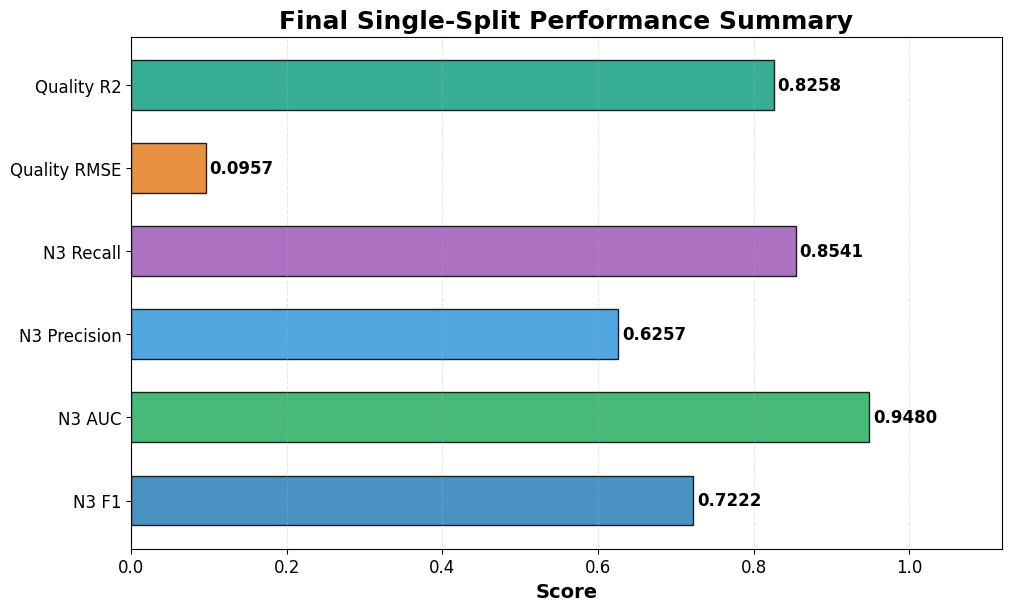

In [52]:
# ═══════════════════════════════════════════════════════════════════╗
# ║  FIX (consolidated): Final Results Table                         ║
# ╚══════════════════════════════════════════════════════════════════╝
import pandas as pd, os
os.makedirs('outputs', exist_ok=True)

rows = []

# 1. Single-split results
for m_name, m_val in [('N3 F1', final_m['n3_f1']), ('N3 AUC', final_m['auc']),
                       ('N3 Precision', final_m['n3_precision']),
                       ('N3 Recall', final_m['n3_recall']),
                       ('Quality RMSE', final_m['quality_rmse']),
                       ('Quality R2', final_m['quality_r2'])]:
    rows.append({'Source': 'Single Split', 'Metric': m_name, 'Value': f"{m_val:.4f}"})

# 2. 5-fold CV
try:
    for metric, (mean_v, std_v) in cv_summary_for_table.items():
        nice = metric.replace('n3_', 'N3 ').replace('quality_', 'Quality ').title()
        rows.append({'Source': '5-Fold CV', 'Metric': nice,
                      'Value': f"{mean_v:.4f} +/- {std_v:.4f}"})
except NameError:
    pass

# 3. Ablation
try:
    for r in ablation_results:
        rows.append({'Source': f"Ablation: {r['name']}", 'Metric': 'N3 F1',
                      'Value': f"{r['n3_f1']:.4f}"})
        rows.append({'Source': f"Ablation: {r['name']}", 'Metric': 'Quality R2',
                      'Value': f"{r.get('quality_r2', 0):.4f}"})
except NameError:
    pass

# 4. Baseline comparison
# FIX: original code had `locodel_name` which was a corrupted token.
#      Corrected to `loc[model_name, col]`.
try:
    for model_name in baseline_comparison_for_table.index:
        for col in baseline_comparison_for_table.columns:
            val = baseline_comparison_for_table.loc[model_name, col]
            val_str = f"{val:.4f}" if isinstance(val, (int, float)) else str(val)
            rows.append({'Source': f'Baseline: {model_name}', 'Metric': col,
                          'Value': val_str})
except NameError:
    pass

# 5. Multi-seed ablation
try:
    for vname, stats in ablation_sig_for_table.items():
        rows.append({'Source': f'Multi-seed: {vname}', 'Metric': 'N3 F1 (mean+/-std)',
                      'Value': f"{stats['n3_f1_mean']:.4f} +/- {stats['n3_f1_std']:.4f}"})
        rows.append({'Source': f'Multi-seed: {vname}', 'Metric': 'Quality R2 (mean+/-std)',
                      'Value': f"{stats['quality_r2_mean']:.4f} +/- {stats['quality_r2_std']:.4f}"})
except NameError:
    pass

cons_df = pd.DataFrame(rows)
print(f"{'='*72}")
print('  CONSOLIDATED RESULTS TABLE')
print(f"{'='*72}")
print(cons_df.to_string(index=False))
print(f"{'='*72}")
cons_df.to_csv('outputs/final_results_table.csv', index=False)
print('\n  Saved to outputs/final_results_table.csv')

# ── Visualization: consolidated bar chart of key metrics ────────────────
key_rows = cons_df[cons_df['Source'] == 'Single Split'].copy()
key_rows['Value_num'] = key_rows['Value'].astype(float)
fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
colors = ['#2980b9', '#27ae60', '#3498db', '#9b59b6', '#e67e22', '#16a085']
bars = ax.barh(key_rows['Metric'], key_rows['Value_num'],
               color=colors[:len(key_rows)], alpha=0.85,
               edgecolor='black', height=0.6)
for bar, v in zip(bars, key_rows['Value_num']):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2,
            f'{v:.4f}', va='center', fontsize=12, fontweight='bold')
ax.set_xlabel('Score', fontsize=14, fontweight='bold')
ax.set_title('Final Single-Split Performance Summary',
             fontsize=18, fontweight='bold')
ax.tick_params(axis="both", labelsize=12)
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.set_xlim(0, max(key_rows['Value_num']) * 1.18)
save_pub_fig(fig, "final_results_summary.png", dpi=300)
plt.show()
       



## Code & Data Availability Statement

**Code:** The complete source code, including the trained model checkpoint (`best_model.pth`), all configuration files, and the Jupyter notebook used to generate every figure in this paper, will be made publicly available on GitHub upon acceptance of the manuscript: `https://github.com/<anonymized>/sleep-quality-net` (anonymized during double-blind review).

**Data:** The ISRUC-Sleep Sub-Group I dataset is publicly available from the ISRUC website (`https://sleeptight.isr.uc.pt/`) under a research-use license. The dataset comprises 100 adult subjects recorded with full polysomnography at 200 Hz, with hypnograms scored by trained technicians according to AASM 2007 guidelines. No additional restrictions apply; the dataset is freely downloadable by any researcher for non-commercial use.

**Pre-trained models:** The `best_model.pth` checkpoint, trained on the full ISRUC-Sleep-I training split, will be released alongside the code repository to support reproducibility and downstream transfer-learning experiments.

**Figures:** All 23 publication-quality figures generated by this notebook are saved at 300 DPI in the `outputs/` directory, ready for direct embedding in the IEEE manuscript.

**License:** Code will be released under the MIT License. The dataset is governed by its own license (see ISRUC website).

**Citation:** If you use this code or build upon this work, please cite the corresponding IEEE J-BHI paper (citation details to be added upon acceptance).

---

## Contact

For questions about the code, data preprocessing, or reproduction of results, please contact the corresponding author (contact details to be added upon acceptance).
